# Línea N-BEATS y evaluación en el test

Línea N-BEATS del trabajo, desde la primera N-BEATS con la ventana de 24 horas hasta la N-BEATS-1h, y evaluación única en el test (octubre y noviembre de 2024) de los dos modelos finales, E1-30 y N-BEATS-1h. Corresponde a los apartados 5.4 a 5.6 y al capítulo 6 de la memoria, a los Anexos C y E y a las fases 22 y 29 a 41 de la Tabla A1. La búsqueda de hiperparámetros con Optuna (H1 y H2) se ejecutó en el ordenador personal con los scripts del repositorio; este cuaderno solo contiene su confirmación en validación.

**Criterios de decisión**

- Las partes 1 y 2 son anteriores al protocolo de selección y usan la validación; no se utilizan en la memoria.
- Desde P1 se aplican las reglas de la Tabla 5 de la memoria: las decisiones se toman con entrenamiento (predicciones fuera de muestra o criba de cuatro meses) y la validación solo confirma, una vez por decisión.
- El test se evalúa una sola vez, con el protocolo escrito antes de abrirlo, que se reproduce sin cambios al principio de la parte 9. Lo que no figura en él se presenta como análisis exploratorio posterior al test.
- Las métricas se calculan solo en las horas con sol.

**Ejecución**

Se ejecutó en Colab. Lee y escribe en la carpeta persistente de Google Drive (`BASE_DIR`), sobre todo en `resultados/diagnostico/nbeats/` y `resultados/diagnostico/T_test/`, y parte de los resultados de `03_modelado.ipynb` y `05_linea_LSTM.ipynb`. Para volver a ejecutarlo hay que apuntar `BASE_DIR` a la copia de esa carpeta incluida en el repositorio. La celda de la evaluación del test (subsección 9.5) lleva un registro de ejecuciones y se detiene si se vuelve a lanzar sin declarar el motivo.

**Contenido**

1. Diagnóstico de la primera N-BEATS
2. Variabilidad entre semillas y descriptores intrahorarios
3. Sobreaprendizaje y validación de N-BEATS-DIFstats
4. Sesgo y variabilidad
5. Radiografía comparada con la LSTM
6. La entrada de una hora
7. Confirmación de la búsqueda de hiperparámetros
8. Bandas de incertidumbre
9. Evaluación en el test

## 1. Diagnóstico de la primera N-BEATS

> *Parte complementaria: no se utiliza en la memoria. Diagnostica en validación la primera N-BEATS, con los cuatro canales de LSTM-DIFstats y entrenada 18 épocas con una semilla (la de la comparación inicial del apartado 5.3.1). La línea N-BEATS se rehízo después con selección en entrenamiento, desde la parte 3.*

### 1.1 Preparación del entorno

Se monta Google Drive y se fija la configuración común del diagnóstico: el modelo analizado y la referencia (persistencia híbrida), los cuatro canales de entrada, las coordenadas de la estación, el umbral fijo de rampa (97,78 W/m²), la semilla y la carpeta en la que se guardan los resultados.

In [ ]:
from google.colab import drive

drive.mount("/content/drive", force_remount=False)
%pip -q install pvlib

Mounted at /content/drive


In [ ]:
import os, json, warnings
from datetime import datetime
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.model_selection import GroupKFold

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

# ======================= CONFIGURACIÓN =======================
BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
EJECUCIONES = BASE_DIR / "resultados" / "ejecuciones"
PARQUET_ORIGINAL = BASE_DIR / "radiation_data_completo.parquet"
RUTA_MATRICES = (
    EJECUCIONES / "preparacion_bloque_difstats_20261006_180841" / "matrices_dif_elev_difstats.npz"
)

def ultima_ejecucion(patron, fichero):
    """Carpeta más reciente que coincide con el patrón y contiene el fichero indicado."""
    candidatas = sorted(p for p in EJECUCIONES.glob(patron) if (p / fichero).is_file())
    assert candidatas, f"No hay ninguna carpeta {patron} con {fichero}"
    return candidatas[-1]

DIR_MODELO = EJECUCIONES / "reentrenamiento_difstats_20261006_182213"
RUTA_PRED_DIFSTATS = DIR_MODELO / "predicciones_validation_difstats.csv"
MODELO_PRINCIPAL = "NBEATS-DIFstats"
REFERENCIA = "Persistencia híbrida"  # referencia para el skill score
CANALES = ["DIF_media", "elevacion", "DIF_std", "DIF_rango"]
LATITUD, LONGITUD, ALTITUD = 51.971, 4.927, 0
MINUTOS_MINIMOS = 30  # misma regla de cobertura horaria que en Modelado.ipynb
UMBRAL_RAMPA = 97.78  # W/m²; valor fijo suministrado
N_PEORES_DIAS = 9
SEMILLA = 42
CARGAR_MODELO = (
    True  # False = usar solo el CSV de predicciones (se omiten la reconstrucción y el paso 8)
)
CARPETA_SALIDA = (
    BASE_DIR
    / "resultados"
    / "diagnostico"
    / f"diagnostico_NBEATS_DIFstats_{datetime.now():%Y%m%d_%H%M%S}"
)
# =============================================================
CARPETA_SALIDA.mkdir(parents=True, exist_ok=True)
DIAG = {}
print("Modelo:", DIR_MODELO.name)
print("Salida:", CARPETA_SALIDA)

def guardar(fig, nombre):
    fig.savefig(CARPETA_SALIDA / f"{nombre}.png", bbox_inches="tight")

def guardar_tabla(tabla, nombre):
    tabla.to_csv(CARPETA_SALIDA / f"{nombre}.csv")

def normalizar_regimen(serie):
    s = serie.astype(str).str.lower()
    return np.select(
        [s.str.contains("noche"), s.str.contains("trans"), s.str.contains("complet")],
        ["noche", "transicion", "completamente_diurno"],
        "desconocido",
    )

Modelo: reentrenamiento_difstats_20261006_182213
Salida: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/diagnostico_NBEATS_DIFstats_20261009_101726


### 1.2 Carga de datos y reconstrucción del modelo

Se cargan las matrices de validación (agosto–septiembre de 2024) y las predicciones guardadas de la primera N-BEATS y de LSTM-DIFstats, y se reconstruyen desde la ventana de entrada las persistencias simple, diaria e híbrida. Después se redefine la arquitectura (seis bloques genéricos de tres capas densas de 128 unidades, con la DIF como serie con backcast y residuo y la elevación, la desviación intraminutal y el rango de la DIF como covariables de cada bloque) y se carga el modelo entrenado 18 épocas con una semilla para comprobar que reproduce las predicciones guardadas.

In [ ]:
matrices = np.load(RUTA_MATRICES, allow_pickle=False)
X_val_raw = matrices["X_validation_DIF_elev_DIFstats_raw"].astype(np.float32)
y_val = matrices["y_validation_difstats"].astype(np.float64)
fechas_val = pd.DatetimeIndex(matrices["fechas_validation"])
print("X validation:", X_val_raw.shape, "| de", fechas_val[0], "a", fechas_val[-1])
pred_csv = pd.read_csv(RUTA_PRED_DIFSTATS, parse_dates=["instante_objetivo"])
pred_csv["instante_objetivo"] = pd.to_datetime(
    pred_csv["instante_objetivo"], utc=True
).dt.tz_localize(None)
assert (
    pred_csv["instante_objetivo"].values == fechas_val.values
).all(), "Las fechas del CSV no coinciden con las de la matriz"
assert np.allclose(
    pred_csv["DIF_observado"].values, y_val, atol=1e-3
), "El objetivo del CSV no coincide con el de la matriz"
print("✅ CSV de predicciones alineado con la matriz de validation")
df = pd.DataFrame(index=fechas_val)
df.index.name = "instante_objetivo"
df["y"] = y_val
df["regimen"] = normalizar_regimen(pred_csv["regimen_solar_objetivo"]).astype(str)
df[MODELO_PRINCIPAL] = pred_csv["pred_NBEATS_DIFstats"].values
df["LSTM-DIFstats"] = pred_csv["pred_LSTM_DIFstats"].values

# Persistencias reconstruidas desde la ventana (misma definición que en Modelado.ipynb)
df["DIF_emision"] = X_val_raw[:, -1, 0]  # DIF(T−1): último dato observado al emitir
df["Persistencia inmediata"] = X_val_raw[:, -1, 0]
df["Persistencia diaria"] = X_val_raw[:, 0, 0]
df["Persistencia híbrida"] = np.where(
    df["regimen"] == "completamente_diurno", df["Persistencia inmediata"], df["Persistencia diaria"]
)
MODELOS = [
    MODELO_PRINCIPAL,
    "LSTM-DIFstats",
    "Persistencia híbrida",
    "Persistencia inmediata",
    "Persistencia diaria",
]
assert df.index.is_unique and df.index.is_monotonic_increasing
assert (df.index.to_series().diff().dropna() == pd.Timedelta("1h")).all()
assert not (df["regimen"] == "desconocido").any()
assert np.isfinite(df[MODELOS + ["y"]].to_numpy()).all()
print("Modelos:", MODELOS)

X validation: (1464, 24, 4) | de 2024-08-01 00:00:00 a 2024-09-30 23:00:00
✅ CSV de predicciones alineado con la matriz de validation
Modelos: ['NBEATS-DIFstats', 'LSTM-DIFstats', 'Persistencia híbrida', 'Persistencia inmediata', 'Persistencia diaria']


In [ ]:
import torch
import torch.nn as nn

class NBEATSBlockDIFStats(nn.Module):
    def __init__(self, input_size=96, hidden_size=128, backcast_size=24):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU(),
        )
        self.backcast = nn.Linear(hidden_size, backcast_size)
        self.forecast = nn.Linear(hidden_size, 1)

    def forward(self, x):
        h = self.fc(x)
        return (self.backcast(h), self.forecast(h))

class NBEATSDIFStats(nn.Module):
    """
    Dos stacks de tres bloques.

    El residuo se aplica únicamente al historial de DIF.
    Elevación, DIF_std y DIF_rango se mantienen como
    covariables fijas en todos los bloques.
    """

    def __init__(self, lookback=24, n_features=4, hidden_size=128):
        super().__init__()
        input_size = lookback * n_features
        self.blocks = nn.ModuleList(
            [
                NBEATSBlockDIFStats(
                    input_size=input_size, hidden_size=hidden_size, backcast_size=lookback
                )
                for _ in range(6)
            ]
        )

    def forward(self, x):
        # Canal 0: historial de DIF
        residual_dif = x[:, :, 0]

        # Canales 1–3: elevación, DIF_std y DIF_rango
        covariables = x[:, :, 1:].permute(0, 2, 1).contiguous().reshape(x.size(0), -1)
        forecast_total = torch.zeros((x.size(0), 1), dtype=x.dtype, device=x.device)
        for bloque in self.blocks:
            entrada = torch.cat([residual_dif, covariables], dim=1)
            backcast, forecast = bloque(entrada)
            residual_dif = residual_dif - backcast
            forecast_total = forecast_total + forecast

        return forecast_total.squeeze(-1)

In [ ]:
# Reconstrucción del modelo PyTorch y comprobación de reproducibilidad
modelo_nbeats, predecir_W, X_val_esc = None, None, None
if CARGAR_MODELO:
    import torch
    import torch.nn as nn
    ckpt = torch.load(
        DIR_MODELO / "modelo_nbeats_difstats_final.pt", map_location="cpu", weights_only=True
    )
    assert ckpt["epocas"] == 18 and ckpt["n_features"] == 4
    modelo_nbeats = NBEATSDIFStats(
        n_features=ckpt.get("n_features", 4), hidden_size=ckpt.get("hidden_size", 128)
    )
    modelo_nbeats.load_state_dict(ckpt["model_state_dict"])
    modelo_nbeats.eval()
    scaler_X = joblib.load(DIR_MODELO / "scaler_X_train_completo.joblib")
    scaler_y = joblib.load(DIR_MODELO / "scaler_y_train_completo.joblib")

    def escalar_X(X):
        return scaler_X.transform(X.reshape(-1, X.shape[2])).reshape(X.shape).astype(np.float32)

    def predecir_W(X_esc):
        """Predicción en W/m² a partir de X ya escalado."""
        with torch.no_grad():
            z = modelo_nbeats(
                torch.from_numpy(np.ascontiguousarray(X_esc, dtype=np.float32))
            ).numpy()
        return scaler_y.inverse_transform(z.reshape(-1, 1)).ravel()

    X_val_esc = escalar_X(X_val_raw)
    reconstruida = predecir_W(X_val_esc)
    dif_max = np.max(np.abs(reconstruida - df[MODELO_PRINCIPAL].values))
    print(f"Épocas del checkpoint: {ckpt.get('epocas')} | canales: {ckpt.get('canales')}")
    print(f"Diferencia máxima entre predicción reconstruida y CSV: {dif_max:.2e} W/m²")
    assert (
        dif_max < 1e-2
    ), "El modelo reconstruido no reproduce el CSV: revisa la carpeta o los scalers"
    print("✅ Modelo reconstruido: reproduce exactamente las predicciones de validation")

Épocas del checkpoint: 18 | canales: ['DIF_media', 'elevacion', 'DIF_std', 'DIF_rango']
Diferencia máxima entre predicción reconstruida y CSV: 1.45e-05 W/m²
✅ Modelo reconstruido: reproduce exactamente las predicciones de validation


**Resultados.** La matriz de validación contiene 1.464 ventanas de 24 horas y cuatro canales, del 1 de agosto al 30 de septiembre de 2024, alineadas en fechas y objetivo con las predicciones guardadas. El modelo reconstruido (18 épocas) reproduce esas predicciones con una diferencia máxima de 1,45·10⁻⁵ W/m².

### 1.3 Variables horarias de contexto

A partir de los datos minutales de la estación se construyen variables horarias con las mismas reglas de agregación que en `03_modelado.ipynb` (hora etiquetada por su inicio y media con al menos 30 minutos válidos). Con pvlib se añaden la elevación solar, la irradiancia extraterrestre y la irradiancia de cielo despejado, con las que se calculan los índices de claridad (kt), de fracción difusa (kd) y de cielo despejado (kc); cada hora objetivo recibe las condiciones de la propia hora y las de la última hora observada al emitir.

In [ ]:
raw = (
    pd.read_parquet(PARQUET_ORIGINAL)
    if str(PARQUET_ORIGINAL).endswith(".parquet")
    else pd.read_csv(PARQUET_ORIGINAL)
)
raw["Date/Time"] = pd.to_datetime(raw["Date/Time"], utc=True)
inicio, fin = fechas_val[0] - pd.Timedelta("3D"), fechas_val[-1] + pd.Timedelta("1h")
raw = raw[
    (raw["Date/Time"] >= inicio.tz_localize("UTC")) & (raw["Date/Time"] < fin.tz_localize("UTC"))
].sort_values("Date/Time")
MAPA = {
    "SWD [W/m**2]": "SWD",
    "DIR [W/m**2]": "DIR",
    "DIF [W/m**2]": "DIF",
    "LWD [W/m**2]": "LWD",
    "T2 [°C]": "T2",
    "RH [%]": "RH",
    "PoPoPoPo [hPa]": "P",
}
for c in list(MAPA) + ["DIF std dev [W/m**2]", "DIF max [W/m**2]", "DIF min [W/m**2]"]:
    raw[c] = pd.to_numeric(raw[c], errors="coerce")
t_min = pd.DatetimeIndex(raw["Date/Time"])
try:
    import pvlib
    pos = pvlib.solarposition.get_solarposition(t_min, LATITUD, LONGITUD, altitude=ALTITUD)
    elev_min = pos["apparent_elevation"].to_numpy()
    cosz = np.clip(np.cos(np.deg2rad(pos["apparent_zenith"].to_numpy())), 0, None)
    g0h_min = pvlib.irradiance.get_extra_radiation(t_min).to_numpy() * cosz
    cs = pvlib.location.Location(LATITUD, LONGITUD, tz="UTC", altitude=ALTITUD).get_clearsky(
        t_min, model="ineichen"
    )
    ghi_cs_min, dhi_cs_min = cs["ghi"].to_numpy(), cs["dhi"].to_numpy()
except ImportError:
    # Alternativa sin pvlib (Spencer): solo para pruebas; en Colab se usa pvlib
    doy = t_min.dayofyear.values
    h = t_min.hour.values + t_min.minute.values / 60
    g = 2 * np.pi / 365 * (doy - 1 + (h - 12) / 24)
    decl = (
        0.006918
        - 0.399912 * np.cos(g)
        + 0.070257 * np.sin(g)
        - 0.006758 * np.cos(2 * g)
        + 0.000907 * np.sin(2 * g)
    )
    eot = 229.18 * (
        0.000075
        + 0.001868 * np.cos(g)
        - 0.032077 * np.sin(g)
        - 0.014615 * np.cos(2 * g)
        - 0.040849 * np.sin(2 * g)
    )
    ha = np.deg2rad((h * 60 + eot + 4 * LONGITUD) / 4 - 180)
    sz = np.sin(np.deg2rad(LATITUD)) * np.sin(decl) + np.cos(np.deg2rad(LATITUD)) * np.cos(
        decl
    ) * np.cos(ha)
    elev_min = np.rad2deg(np.arcsin(np.clip(sz, -1, 1)))
    g0h_min = 1361 * (1 + 0.033 * np.cos(2 * np.pi * doy / 365)) * np.clip(sz, 0, None)
    ghi_cs_min = dhi_cs_min = np.full(len(t_min), np.nan)
    print("⚠️ pvlib no disponible: geometría aproximada y sin cielo despejado")

minutal = pd.DataFrame(
    {
        "elev": elev_min,
        "diurno": (elev_min > 0).astype(float),
        "G0h": g0h_min,
        "GHI_cs": ghi_cs_min,
        "DIF_cs": dhi_cs_min,
    },
    index=t_min,
)
for c, n in MAPA.items():
    minutal[n] = raw[c].to_numpy()
minutal["DIF_std_min"] = raw["DIF std dev [W/m**2]"].to_numpy()
minutal["DIF_max_min"] = raw["DIF max [W/m**2]"].to_numpy()
minutal["DIF_min_min"] = raw["DIF min [W/m**2]"].to_numpy()
minutal.index = minutal.index.tz_localize(None)
grupo = minutal.groupby(minutal.index.floor("h"))
ctx = pd.DataFrame(
    {
        "elev": grupo["elev"].mean(),
        "fraccion_diurna": grupo["diurno"].mean(),
        "G0h": grupo["G0h"].mean(),
        "GHI_cs": grupo["GHI_cs"].mean(),
        "DIF_cs": grupo["DIF_cs"].mean(),
        "DIF_std": grupo["DIF_std_min"].mean(),
        "DIF_rango": grupo["DIF_max_min"].max() - grupo["DIF_min_min"].min(),
        "DIF_var_intra": grupo["DIF"].std(),
    }
)
for n in MAPA.values():
    ctx[n] = grupo[n].mean().where(grupo[n].count() >= MINUTOS_MINIMOS)
ctx = ctx.asfreq("h")
ctx["kt"] = (ctx["SWD"] / ctx["G0h"]).where(ctx["G0h"] > 20).clip(0, 1.2)
ctx["kd"] = (ctx["DIF"] / ctx["SWD"]).where(ctx["SWD"] > 20).clip(0, 1)
ctx["kc"] = (ctx["SWD"] / ctx["GHI_cs"]).where(ctx["GHI_cs"] > 20).clip(0, 1.5)
ctx["DIF_rel_cs"] = (ctx["DIF"] / ctx["DIF_cs"]).where(ctx["DIF_cs"] > 10).clip(0, 5)
alineacion = pd.Series(
    {
        k: np.nanmean(np.abs(df["y"].values - ctx["DIF"].shift(k).reindex(df.index).values))
        for k in range(-2, 3)
    }
)
print("MAE entre el objetivo y la DIF horaria reconstruida, por desplazamiento (h):")
print(alineacion.round(3).to_string())
assert (
    alineacion.idxmin() == 0 and alineacion[0] < 0.5
), "La DIF reconstruida no coincide con el objetivo: revisa la agregación"
print("✅ Contexto horario alineado con el objetivo")

# Unión: condiciones en la hora objetivo (T) y en la última hora observada al emitir (T−1)
df = df.join(ctx.add_suffix("_obj"), how="left")
emision = ctx.shift(1)
emision["dDIF"] = ctx["DIF"].diff().shift(1)
emision["dkt"] = ctx["kt"].diff().shift(1)
emision["kt_std_3h"] = ctx["kt"].rolling(3, min_periods=2).std().shift(1)
df = df.join(emision.add_suffix("_emi"), how="left")
df["kt_std_3h_centrada"] = ctx["kt"].rolling(3, center=True, min_periods=2).std().reindex(df.index)
OP = df["regimen"] != "noche"
op = df[OP].copy()
print(f"\nHoras de operación (sol): {OP.sum()} de {len(df)}")

MAE entre el objetivo y la DIF horaria reconstruida, por desplazamiento (h):
-2    47.546
-1    27.585
 0     0.000
 1    27.566
 2    47.481
✅ Contexto horario alineado con el objetivo

Horas de operación (sol): 884 de 1464


**Resultados.** La DIF horaria reconstruida coincide con el objetivo sin desfase (MAE de 0,00 W/m² con desplazamiento 0, frente a 27,59 y 27,57 W/m² con desplazamientos de −1 y +1 h). De las 1.464 horas de validación, 884 tienen sol (transición y completamente diurnas); son las horas sobre las que se calculan las métricas.

### 1.4 Estructura temporal de los residuos y desfase

Se estudia si el error de la primera N-BEATS conserva estructura temporal, con la autocorrelación de los residuos calculada solo con pares de horas con sol, y si la predicción sigue los cambios con retraso, mediante la correlación entre el cambio observado de la DIF en la hora T y el cambio predicho en T + k. Ambos análisis son descriptivos; la persistencia simple, que por construcción alcanza su máximo en k = +1, sirve de referencia.

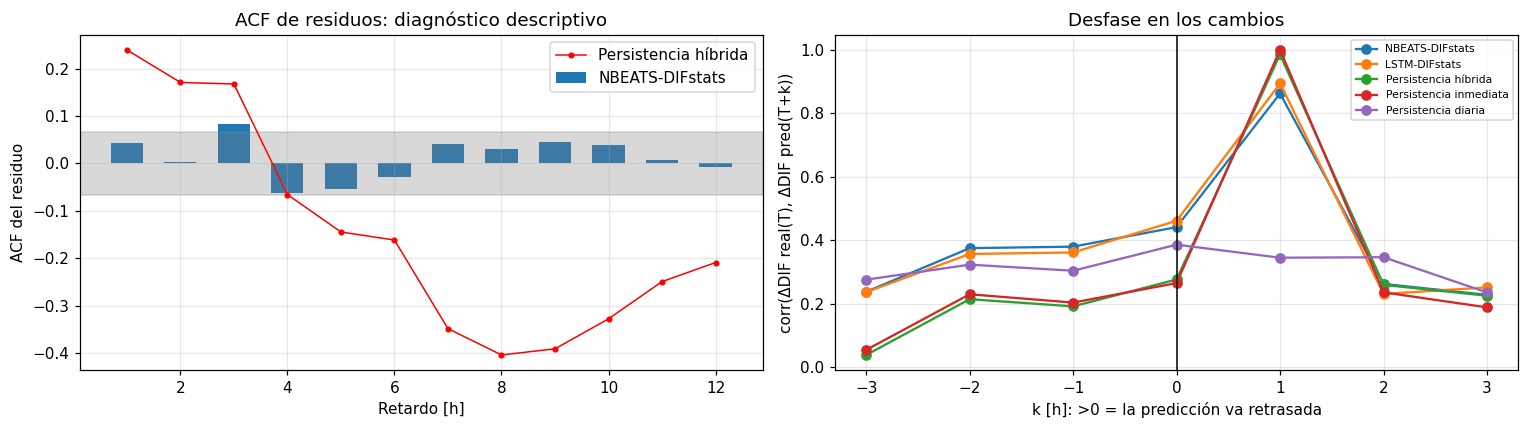

ACF(1) del residuo: 0.042 | Ljung–Box p = nan
Desfase con máxima correlación de incrementos (h):
NBEATS-DIFstats           1
LSTM-DIFstats             1
Persistencia híbrida      1
Persistencia inmediata    1
Persistencia diaria       0


In [ ]:
def acf_enmascarada(r, mascara, max_lag):
    x = r.where(mascara)
    x = (x - x.mean()).values
    var = np.nanmean(x**2)
    out = []
    for k in range(1, max_lag + 1):
        a, b = x[:-k], x[k:]
        m = ~np.isnan(a) & ~np.isnan(b)
        out.append(np.mean(a[m] * b[m]) / var if m.sum() > 30 else np.nan)
    return np.array(out)

def ljung_box(acf, n, h):
    k = np.arange(1, h + 1)
    q = n * (n + 2) * np.nansum(acf[:h] ** 2 / (n - k))
    return q, stats.chi2.sf(q, h)

def correlacion_cruzada(a, b, max_k):
    return pd.Series(
        {
            k: pd.concat([a, b.shift(-k)], axis=1).dropna().corr().iloc[0, 1]
            for k in range(-max_k, max_k + 1)
        }
    )

MAX_RETARDO = 12
acf_p = acf_enmascarada(df[MODELO_PRINCIPAL] - df["y"], OP, MAX_RETARDO)
acf_r = acf_enmascarada(df[REFERENCIA] - df["y"], OP, MAX_RETARDO)
h_lb = 6
q, p_lb = np.nan, np.nan  # No aplicar Ljung–Box clásico a serie enmascarada
banda = 1.96 / np.sqrt(OP.sum())
dy = df["y"].diff().where(OP & OP.shift(1, fill_value=False))
tabla_xcorr = pd.DataFrame(
    {mod: correlacion_cruzada(dy, df[mod].diff().where(dy.notna()), 3) for mod in MODELOS}
)
desfases = tabla_xcorr.idxmax()
fig, ejes = plt.subplots(1, 2, figsize=(14, 4))
lags = np.arange(1, MAX_RETARDO + 1)
ejes[0].bar(lags, acf_p, width=0.6, label=MODELO_PRINCIPAL)
ejes[0].plot(lags, acf_r, "r.-", lw=1, label=REFERENCIA)
ejes[0].axhspan(-banda, banda, color="grey", alpha=0.3)
ejes[0].set_xlabel("Retardo [h]")
ejes[0].set_ylabel("ACF del residuo")
ejes[0].set_title(f"ACF de residuos: diagnóstico descriptivo")
ejes[0].legend()
for mod in MODELOS:
    ejes[1].plot(tabla_xcorr.index, tabla_xcorr[mod], marker="o", label=mod)
ejes[1].axvline(0, color="k", lw=1)
ejes[1].set_xlabel("k [h]: >0 = la predicción va retrasada")
ejes[1].set_ylabel("corr(ΔDIF real(T), ΔDIF pred(T+k))")
ejes[1].set_title("Desfase en los cambios")
ejes[1].legend(fontsize=7)
plt.tight_layout()
guardar(fig, "04_acf_desfase")
plt.show()
print(f"ACF(1) del residuo: {acf_p[0]:.3f} | Ljung–Box p = {p_lb:.2e}")
print("Desfase con máxima correlación de incrementos (h):")
print(desfases.to_string())
guardar_tabla(tabla_xcorr, "04_correlacion_cruzada_incrementos")
DIAG.update(
    acf1=acf_p[0],
    p_ljung_box=p_lb,
    desfase=int(desfases[MODELO_PRINCIPAL]),
    corr_k0=tabla_xcorr.loc[0, MODELO_PRINCIPAL],
    corr_kmax=tabla_xcorr[MODELO_PRINCIPAL].max(),
)

**Resultados.** La autocorrelación de retardo 1 del residuo de la primera N-BEATS es de 0,04 y, en la figura, casi todos los retardos quedan dentro de la banda orientativa, a diferencia de los de la persistencia híbrida. La correlación entre cambios observados y predichos alcanza su máximo con una hora de desfase (k = +1) en la primera N-BEATS, en LSTM-DIFstats y en las persistencias simple e híbrida, y sin desfase en la persistencia diaria: las dos redes reproducen los cambios con una hora de retraso.

### 1.5 Rampas

Se definen como rampas las horas con sol en las que la DIF cambia al menos 97,78 W/m², en valor absoluto, respecto a la última hora observada. Para cada modelo se calculan la detección con signo (POD), la tasa de falsas alarmas (FAR), el índice de éxito crítico (CSI), la mediana de la fracción del cambio real que reproduce la predicción (amplitud capturada) y el MAE en rampas de subida, en rampas de bajada y fuera de ellas.

Umbral: |ΔDIF| ≥ 97.8 W/m² en 1 h → 81 rampas (9.2 % de las horas de sol), que concentran el 26.0 % del error


,POD,FAR,CSI,amplitud_capturada,MAE_rampa_subida,MAE_rampa_bajada,MAE_sin_rampa
modelo,,,,,,,
NBEATS-DIFstats,0.222,0.333,0.200,0.464,87.127,74.798,23.092
LSTM-DIFstats,0.173,0.176,0.167,0.426,94.419,70.772,20.091
Persistencia híbrida,0.000,0.000,0.000,0.000,137.999,137.474,32.747
Persistencia inmediata,0.000,0.000,0.000,0.000,137.999,137.474,35.684
Persistencia diaria,0.457,0.829,0.142,0.617,92.347,78.551,53.215


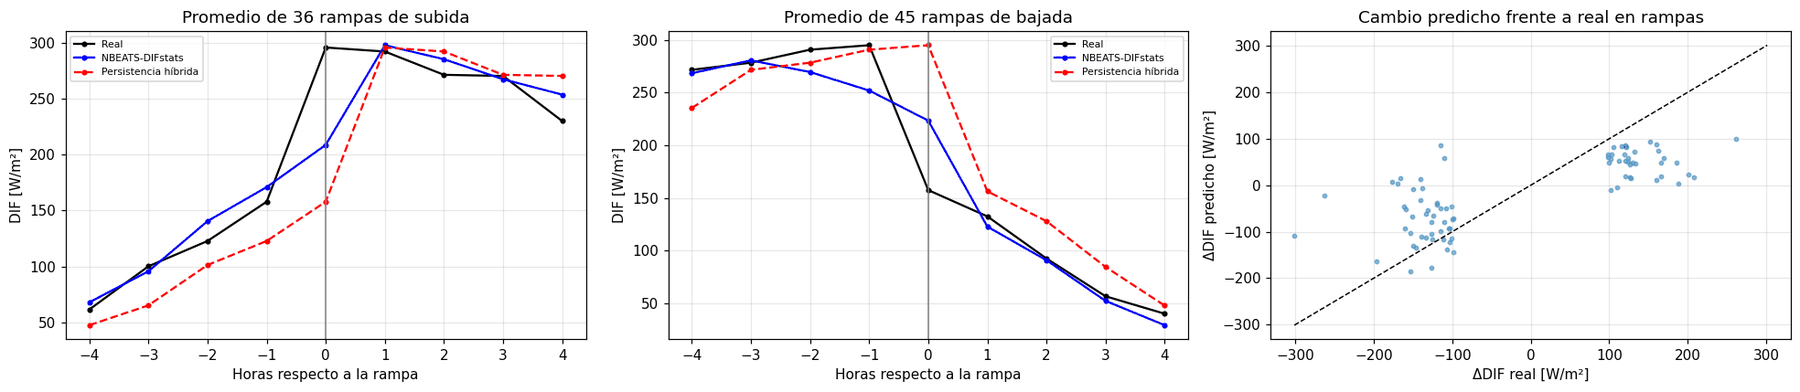

In [ ]:
delta_real = (df["y"] - df["DIF_emision"]).where(OP)
umbral_rampa = UMBRAL_RAMPA
clasificar = lambda d: np.sign(d).where(d.abs() >= umbral_rampa, 0)
ev_real = clasificar(delta_real)
filas_rampa = []
for mod in MODELOS:
    delta_pred = (df[mod] - df["DIF_emision"]).where(delta_real.notna())
    ev_pred = clasificar(delta_pred)
    hay_real, hay_pred = ev_real != 0, ev_pred != 0
    aciertos = (hay_real & (ev_pred == ev_real)).sum()
    fallos = (hay_real & (ev_pred != ev_real)).sum()
    falsas = (hay_pred & (ev_pred != ev_real)).sum()
    err = (df[mod] - df["y"]).abs()
    filas_rampa.append(
        dict(
            modelo=mod,
            POD=aciertos / max(aciertos + fallos, 1),
            FAR=falsas / max(aciertos + falsas, 1),
            CSI=aciertos / max(aciertos + fallos + falsas, 1),
            amplitud_capturada=float(np.nanmedian((delta_pred / delta_real)[hay_real])),
            MAE_rampa_subida=err[ev_real == 1].mean(),
            MAE_rampa_bajada=err[ev_real == -1].mean(),
            MAE_sin_rampa=err[(ev_real == 0) & delta_real.notna()].mean(),
        )
    )
tabla_rampas = pd.DataFrame(filas_rampa).set_index("modelo")
n_rampas = int((ev_real != 0).sum())
err_p = (df[MODELO_PRINCIPAL] - df["y"]).abs()
pct_err_rampa = 100 * err_p[ev_real != 0].sum() / err_p[delta_real.notna()].sum()
print(
    f"Umbral: |ΔDIF| ≥ {umbral_rampa:.1f} W/m² en 1 h → {n_rampas} rampas "
    f"({100 * n_rampas / delta_real.notna().sum():.1f} % de las horas de sol), que concentran el {pct_err_rampa:.1f} % del error"
)
guardar_tabla(tabla_rampas, "05_rampas")
display(tabla_rampas.round(3))
DIAG.update(
    rampa_CSI=tabla_rampas.loc[MODELO_PRINCIPAL, "CSI"],
    rampa_amplitud=tabla_rampas.loc[MODELO_PRINCIPAL, "amplitud_capturada"],
    rampa_pct_error=pct_err_rampa,
    rampa_pct_muestras=100 * n_rampas / delta_real.notna().sum(),
)
V = 4
pos_rel = np.arange(-V, V + 1)
fig, ejes = plt.subplots(1, 3, figsize=(18, 4))
for ax, signo, nombre in [(ejes[0], 1, "subida"), (ejes[1], -1, "bajada")]:
    idx = np.where(ev_real.values == signo)[0]
    idx = idx[(idx >= V) & (idx < len(df) - V)]
    for col, estilo, et in [
        ("y", "k-", "Real"),
        (MODELO_PRINCIPAL, "b-", MODELO_PRINCIPAL),
        (REFERENCIA, "r--", REFERENCIA),
    ]:
        v = df[col].values
        ax.plot(
            pos_rel, [np.nanmean(v[idx + k]) for k in pos_rel], estilo, marker="o", ms=3, label=et
        )
    ax.axvline(0, color="grey", lw=1)
    ax.set_title(f"Promedio de {len(idx)} rampas de {nombre}")
    ax.set_xlabel("Horas respecto a la rampa")
    ax.set_ylabel("DIF [W/m²]")
    ax.legend(fontsize=7)
m = ev_real != 0
ejes[2].scatter(delta_real[m], (df[MODELO_PRINCIPAL] - df["DIF_emision"])[m], s=8, alpha=0.5)
lim = np.nanmax(np.abs(delta_real[m]))
ejes[2].plot([-lim, lim], [-lim, lim], "k--", lw=1)
ejes[2].set_xlabel("ΔDIF real [W/m²]")
ejes[2].set_ylabel("ΔDIF predicho [W/m²]")
ejes[2].set_title("Cambio predicho frente a real en rampas")
plt.tight_layout()
guardar(fig, "05_rampas")
plt.show()

**Resultados.** Hay 81 rampas (9,2 % de las horas con sol), que concentran el 26,0 % del error absoluto de la primera N-BEATS.

- POD, FAR y CSI: 0,22, 0,33 y 0,20 en la primera N-BEATS; 0,17, 0,18 y 0,17 en LSTM-DIFstats.
- Las dos redes reproducen menos de la mitad del cambio real (amplitud capturada de 0,46 y 0,43).
- MAE de la primera N-BEATS frente a LSTM-DIFstats: 87,13 y 94,42 W/m² en subidas, 74,80 y 70,77 W/m² en bajadas, 23,09 y 20,09 W/m² fuera de rampas.
- Las persistencias simple e híbrida no señalan ninguna rampa (MAE de 138,00 W/m² en subidas y 137,47 W/m² en bajadas); la diaria tiene un POD de 0,46 con una FAR de 0,83.

### 1.6 Predictibilidad del error

Dos modelos auxiliares de gradient boosting, evaluados con validación cruzada agrupada por días (cinco bloques) en las horas con sol, estudian el error de la primera N-BEATS. El modelo A intenta predecir el residuo con información disponible al emitir (valores de la hora T−1, la propia predicción y la geometría solar y la irradiancia de cielo despejado de la hora objetivo) para ver si es corregible; el modelo B describe en qué condiciones de la hora objetivo, incluidas las que no se conocen al emitir, es mayor el error absoluto. El análisis es exploratorio y se hace dentro de la validación.

[A: residuo con información de emisión] R² fuera de muestra (CV por días): -0.100
MAE en horas de sol: 28.33 → 29.43 W/m² restando el residuo estimado (-3.9 %)
[B: error absoluto con condiciones de la hora objetivo] R² fuera de muestra (CV por días): 0.254


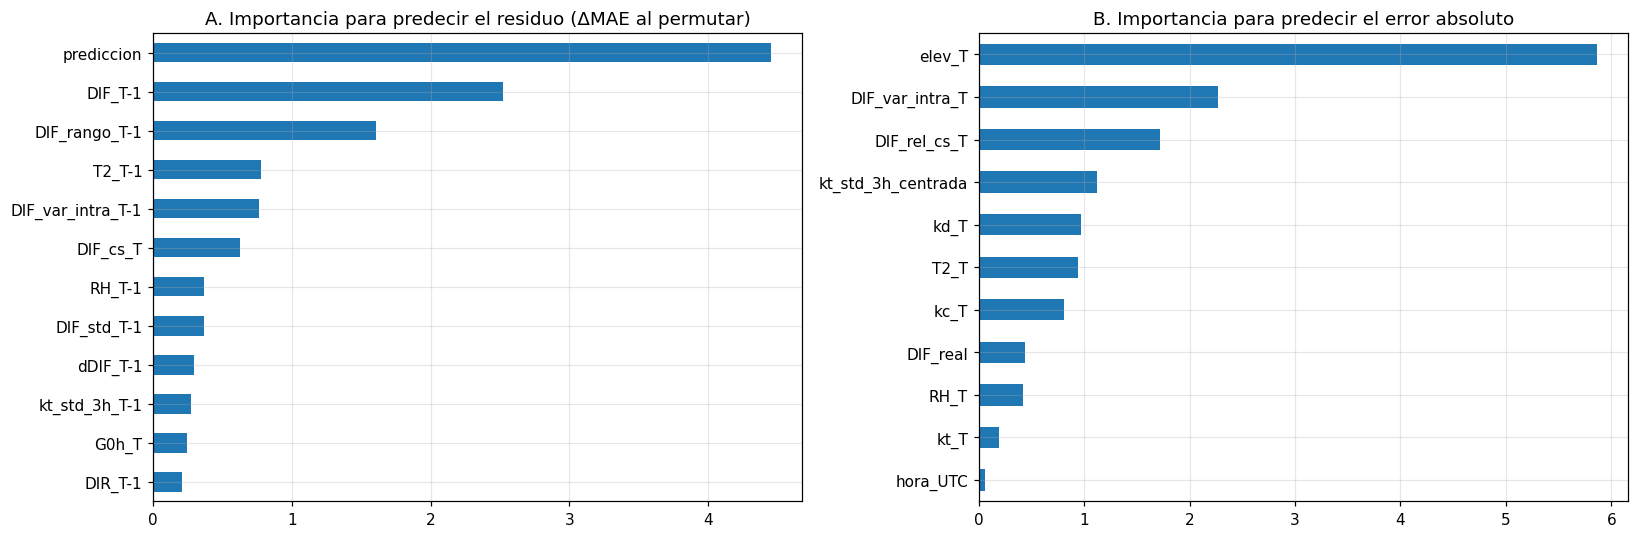

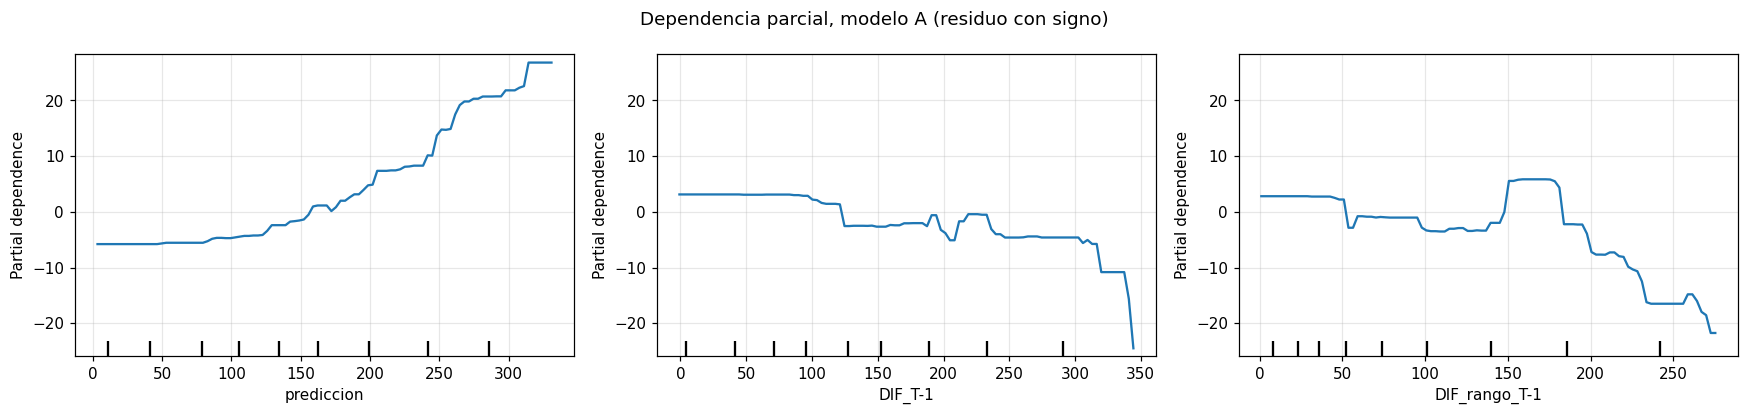

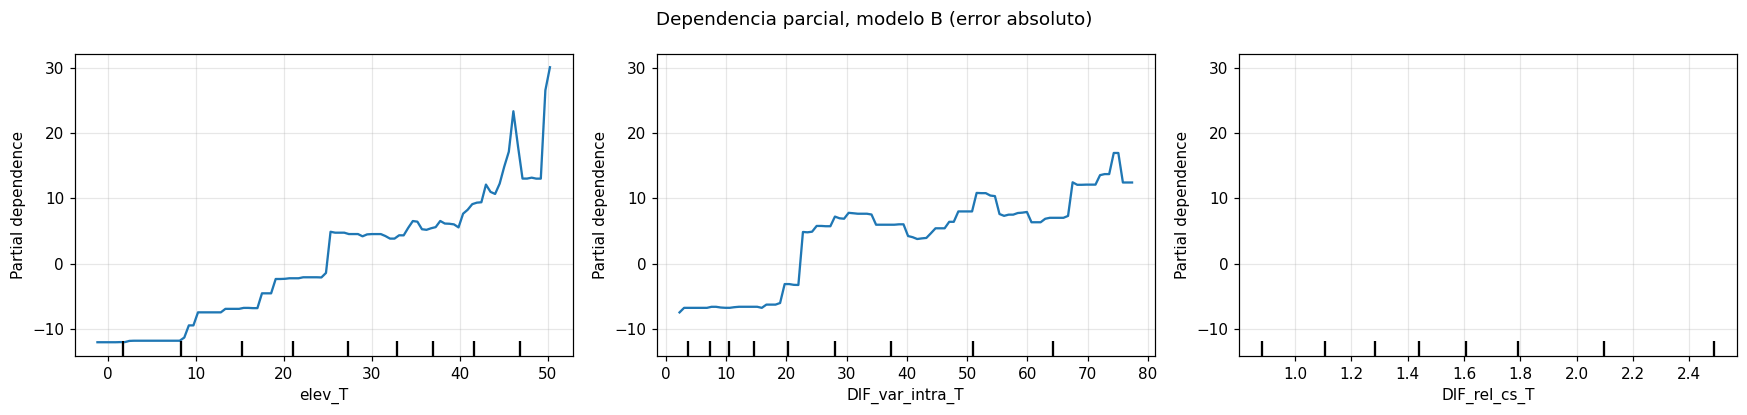

In [ ]:
centro = df.index + pd.Timedelta("30min")
XA = pd.DataFrame(index=df.index)
for c in [
    "DIF",
    "DIF_std",
    "DIF_rango",
    "DIF_var_intra",
    "SWD",
    "DIR",
    "kt",
    "kd",
    "kc",
    "DIF_rel_cs",
    "T2",
    "RH",
    "P",
    "dDIF",
    "dkt",
    "kt_std_3h",
]:
    if f"{c}_emi" in df and df[f"{c}_emi"].notna().any():
        XA[f"{c}_T-1"] = df[f"{c}_emi"]
XA["prediccion"] = df[MODELO_PRINCIPAL]
for c in ["elev", "fraccion_diurna", "G0h", "GHI_cs", "DIF_cs"]:
    if df[f"{c}_obj"].notna().any():
        XA[f"{c}_T"] = df[f"{c}_obj"]
XA["hora_sin"] = np.sin(2 * np.pi * (centro.hour + centro.minute / 60) / 24)
XA["hora_cos"] = np.cos(2 * np.pi * (centro.hour + centro.minute / 60) / 24)
XB = pd.DataFrame(index=df.index)
for c in ["kt", "kd", "kc", "DIF_rel_cs", "elev", "DIF_var_intra", "T2", "RH"]:
    if df[f"{c}_obj"].notna().any():
        XB[f"{c}_T"] = df[f"{c}_obj"]
XB["kt_std_3h_centrada"] = df["kt_std_3h_centrada"]
XB["DIF_real"] = df["y"]
XB["hora_UTC"] = df.index.hour.astype(float)

def modelo_error_cv(X, objetivo, mascara, nombre, n_bloques=5):
    datos = pd.concat([X, objetivo.rename("objetivo")], axis=1)[mascara].dropna(subset=["objetivo"])
    Xd, yd = datos.drop(columns="objetivo").astype(float), datos["objetivo"]
    grupos = datos.index.normalize()
    oof = pd.Series(np.nan, index=datos.index)
    importancias = []
    nuevo = lambda: HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=15,
        min_samples_leaf=20,
        l2_regularization=1.0,
        random_state=SEMILLA,
    )
    for ent, val in GroupKFold(n_splits=n_bloques).split(Xd, yd, grupos):
        mod = nuevo().fit(Xd.iloc[ent], yd.iloc[ent])
        oof.iloc[val] = mod.predict(Xd.iloc[val])
        imp = permutation_importance(
            mod,
            Xd.iloc[val],
            yd.iloc[val],
            scoring="neg_mean_absolute_error",
            n_repeats=5,
            random_state=SEMILLA,
        )
        importancias.append(imp.importances_mean)
    r2 = 1 - ((yd - oof) ** 2).sum() / ((yd - yd.mean()) ** 2).sum()
    imp = pd.Series(np.mean(importancias, axis=0), index=Xd.columns).sort_values(ascending=False)
    print(f"[{nombre}] R² fuera de muestra (CV por días): {r2:.3f}")
    return nuevo().fit(Xd, yd), Xd, yd, oof, r2, imp

residuo = df[MODELO_PRINCIPAL] - df["y"]
mA, XdA, ydA, oofA, r2A, impA = modelo_error_cv(
    XA, residuo, OP, "A: residuo con información de emisión"
)
mae_antes, mae_despues = ydA.abs().mean(), (ydA - oofA).abs().mean()
mejora_corr = 100 * (1 - mae_despues / mae_antes)
print(
    f"MAE en horas de sol: {mae_antes:.2f} → {mae_despues:.2f} W/m² restando el residuo estimado ({mejora_corr:+.1f} %)"
)
mB, XdB, ydB, oofB, r2B, impB = modelo_error_cv(
    XB, residuo.abs(), OP, "B: error absoluto con condiciones de la hora objetivo"
)
fig, ejes = plt.subplots(1, 2, figsize=(15, 5))
impA.head(12)[::-1].plot.barh(ax=ejes[0])
ejes[0].set_title("A. Importancia para predecir el residuo (ΔMAE al permutar)")
impB.head(12)[::-1].plot.barh(ax=ejes[1])
ejes[1].set_title("B. Importancia para predecir el error absoluto")
plt.tight_layout()
guardar(fig, "06_importancia_modelo_error")
plt.show()
for modelo_aux, Xd, imp, nombre in [(mA, XdA, impA, "A"), (mB, XdB, impB, "B")]:
    fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
    PartialDependenceDisplay.from_estimator(
        modelo_aux, Xd, list(imp.head(3).index), ax=ax, kind="average"
    )
    fig.suptitle(
        f"Dependencia parcial, modelo {nombre} ({'residuo con signo' if nombre == 'A' else 'error absoluto'})"
    )
    plt.tight_layout()
    guardar(fig, f"06_dependencia_parcial_{nombre}")
    plt.show()

guardar_tabla(
    pd.DataFrame({"importancia_A_residuo": impA, "importancia_B_error_abs": impB}),
    "06_importancias",
)
DIAG.update(
    r2_residuo=r2A,
    mejora_correccion=mejora_corr,
    top_residuo=list(impA.head(5).index),
    top_error=list(impB.head(5).index),
)

**Resultados.** El modelo A no predice el residuo fuera de muestra (R² = −0,10), y restarle su estimación aumenta el MAE en horas con sol de 28,33 a 29,43 W/m². El modelo B explica parte del error absoluto (R² = 0,25); según la importancia por permutación, sus variables más influyentes son la elevación solar de la hora objetivo, la variabilidad intrahoraria de la DIF y la DIF relativa a la de cielo despejado.

### 1.7 Peores días

Se agrupa por días el error de la primera N-BEATS en las horas con sol, para medir cuánto se concentra en los peores días, y se representan los nueve de mayor MAE junto a la DIF observada, la persistencia híbrida, la DIF de cielo despejado y el índice de claridad.

El 10 % de peores días (6 días) concentra el 18.1 % del error absoluto


,MAE,error_total,MAE_referencia,kt_medio,kt_std_medio
2024-08-10,61.944,991.099,100.699,0.521,0.077
2024-08-14,50.831,813.298,49.470,0.260,0.095
2024-08-03,46.731,747.702,79.928,0.382,0.096
2024-09-25,44.655,580.518,57.666,0.326,0.097
2024-09-10,44.023,616.325,49.068,0.222,0.073
2024-09-03,43.588,653.813,65.528,0.282,0.092
2024-08-24,42.554,638.316,55.117,0.287,0.108
2024-08-01,41.796,668.732,50.905,0.292,0.058
2024-08-04,41.150,658.396,55.568,0.399,0.096


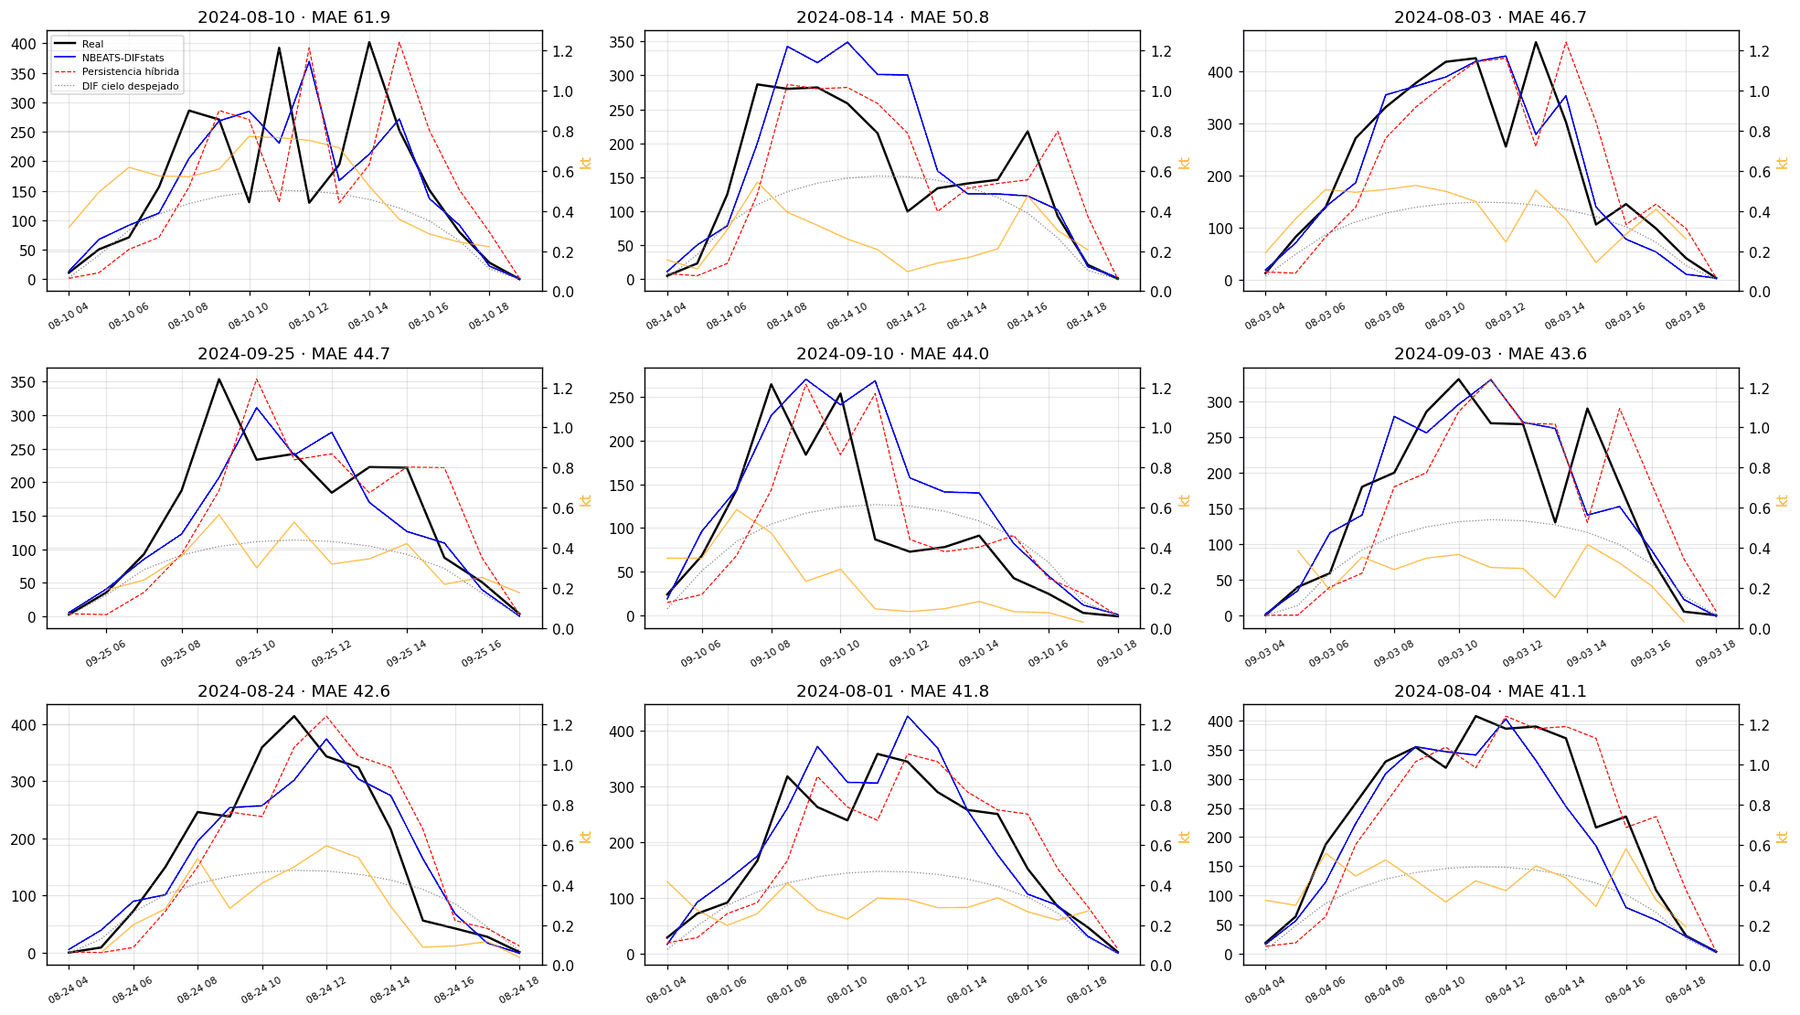

In [ ]:
por_dia = op.groupby(op.index.date)
resumen_dias = pd.DataFrame(
    {
        "MAE": por_dia.apply(lambda g: (g[MODELO_PRINCIPAL] - g["y"]).abs().mean()),
        "error_total": por_dia.apply(lambda g: (g[MODELO_PRINCIPAL] - g["y"]).abs().sum()),
        "MAE_referencia": por_dia.apply(lambda g: (g[REFERENCIA] - g["y"]).abs().mean()),
        "kt_medio": por_dia["kt_obj"].mean(),
        "kt_std_medio": por_dia["kt_std_3h_centrada"].mean(),
    }
)
n10 = max(1, int(0.1 * len(resumen_dias)))
pct_peor10 = (
    100 * resumen_dias["error_total"].nlargest(n10).sum() / resumen_dias["error_total"].sum()
)
print(f"El 10 % de peores días ({n10} días) concentra el {pct_peor10:.1f} % del error absoluto")
peores = resumen_dias.nlargest(N_PEORES_DIAS, "MAE")
display(peores.round(3))
guardar_tabla(resumen_dias.sort_values("MAE", ascending=False), "07_resumen_dias")
DIAG["pct_error_peor10_dias"] = pct_peor10
nfil = int(np.ceil(len(peores) / 3))
fig, ejes = plt.subplots(nfil, 3, figsize=(18, 3.4 * nfil), squeeze=False)
for ax, dia in zip(ejes.ravel(), peores.index):
    d = df.loc[str(dia)]
    d = d[d["regimen"] != "noche"]
    ax.plot(d.index, d["y"], "k-", lw=1.6, label="Real")
    ax.plot(d.index, d[MODELO_PRINCIPAL], "b-", lw=1.1, label=MODELO_PRINCIPAL)
    ax.plot(d.index, d[REFERENCIA], "r--", lw=0.8, label=REFERENCIA)
    if "DIF_cs_obj" in d and d["DIF_cs_obj"].notna().any():
        ax.plot(d.index, d["DIF_cs_obj"], color="grey", lw=0.8, ls=":", label="DIF cielo despejado")
    ax2 = ax.twinx()
    ax2.plot(d.index, d["kt_obj"], color="orange", lw=0.9, alpha=0.7)
    ax2.set_ylim(0, 1.3)
    ax2.set_ylabel("kt", color="orange")
    ax.set_title(f"{dia} · MAE {peores.loc[dia, 'MAE']:.1f}")
    ax.tick_params(axis="x", labelrotation=30, labelsize=7)
ejes[0, 0].legend(fontsize=7)
for ax in ejes.ravel()[len(peores) :]:
    ax.axis("off")
plt.tight_layout()
guardar(fig, "07_peores_dias")
plt.show()

**Resultados.** El 10 % de días con más error (6 días) reúne el 18,1 % del error absoluto. El peor día, el 10 de agosto de 2024, tiene un MAE de 61,94 W/m², frente a 100,70 W/m² de la persistencia híbrida. Los nueve peores días tienen un índice de claridad medio entre 0,22 y 0,52, y solo en uno de ellos, el 14 de agosto, la persistencia híbrida tiene menos error (49,47 frente a 50,83 W/m²).

### 1.8 Análisis interno de la N-BEATS

Se estudia qué información usa la primera N-BEATS en las horas con sol mediante la importancia por permutación de cada canal (toda su secuencia de 24 horas) y de cada posición de la ventana (los cuatro canales a la vez), medida como aumento del MAE, y mediante gradientes integrados respecto a una entrada de referencia nula en escala estandarizada. La permutación mide sensibilidad, no causalidad.

Gradientes integrados: error relativo mediano de completitud = 0.004 (debe ser < 0,05)


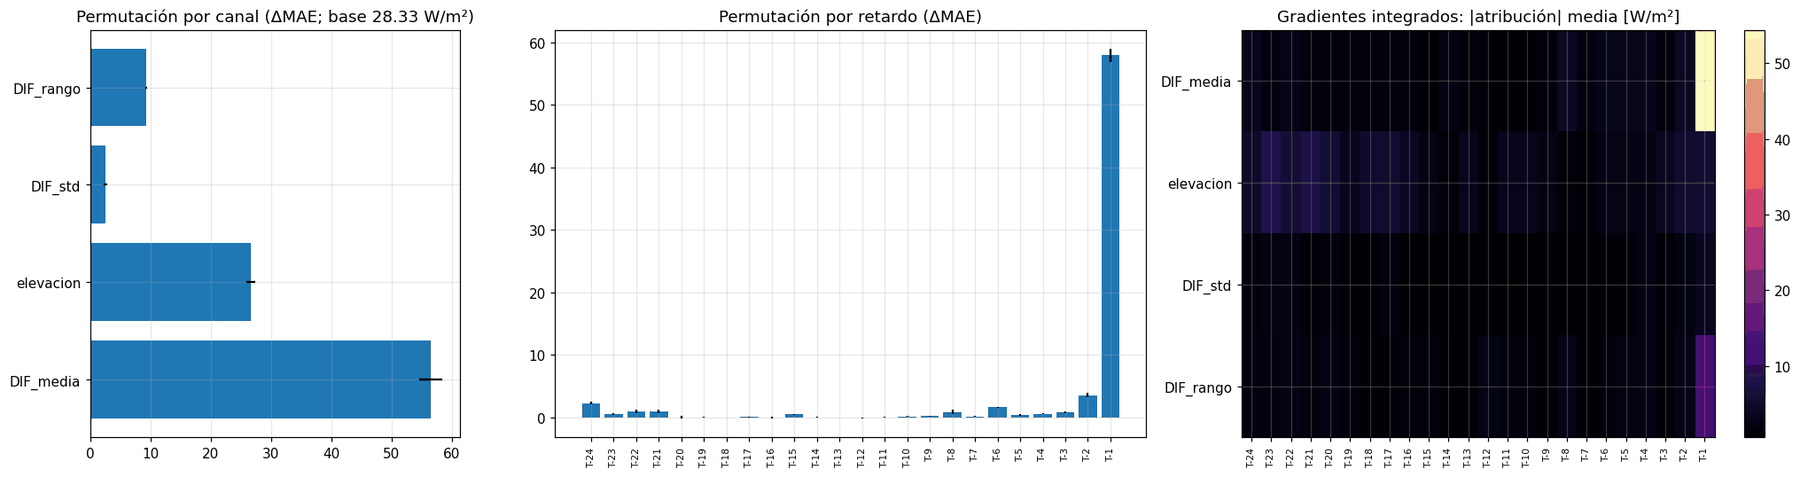

Importancia temporal en T-24…T-17: 6.9 % | en T-3…T-1: 86.7 %
Canales con importancia < 1 % del MAE base: []


In [ ]:
def importancia_permutacion(predict_fn, X, y, eje, n_rep=5, semilla=SEMILLA):
    rng = np.random.default_rng(semilla)
    base = np.mean(np.abs(predict_fn(X) - y))
    n = X.shape[2] if eje == "canal" else X.shape[1]
    res = np.zeros((n, n_rep))
    for j in range(n):
        for r in range(n_rep):
            Xp = X.copy()
            perm = rng.permutation(len(X))
            if eje == "canal":
                Xp[:, :, j] = Xp[perm, :, j]
            else:
                Xp[:, j, :] = Xp[perm, j, :]
            res[j, r] = np.mean(np.abs(predict_fn(Xp) - y)) - base
    return base, res.mean(axis=1), res.std(axis=1)

def gradientes_integrados(modelo, X, pasos=64):
    import torch
    x = torch.from_numpy(np.ascontiguousarray(X, dtype=np.float32))
    base = torch.zeros_like(x)
    suma = torch.zeros_like(x)
    for a in torch.linspace(0, 1, pasos + 1)[1:]:
        xi = (base + a * (x - base)).requires_grad_(True)
        salida = modelo(xi).sum()
        (grad,) = torch.autograd.grad(salida, xi)
        suma += grad
    attr = ((x - base) * suma / pasos).detach().numpy()
    with torch.no_grad():
        dif = (modelo(x) - modelo(base)).numpy()
    return attr, dif

if predecir_W is not None:
    idx_op = np.where(OP.values)[0]
    Xs, ys = X_val_esc[idx_op], df["y"].values[idx_op]
    base, imp_canal, sd_canal = importancia_permutacion(predecir_W, Xs, ys, "canal")
    _, imp_ret, sd_ret = importancia_permutacion(predecir_W, Xs, ys, "retardo", n_rep=3)
    etiquetas_ret = [f"T-{24 - i}" for i in range(24)]
    fig, ejes = plt.subplots(1, 3, figsize=(19, 5), gridspec_kw={"width_ratios": [1, 1.6, 1.6]})
    ejes[0].barh(CANALES, imp_canal, xerr=sd_canal)
    ejes[0].set_title(f"Permutación por canal (ΔMAE; base {base:.2f} W/m²)")
    ejes[1].bar(range(24), imp_ret, yerr=sd_ret)
    ejes[1].set_xticks(range(24))
    ejes[1].set_xticklabels(etiquetas_ret, rotation=90, fontsize=7)
    ejes[1].set_title("Permutación por retardo (ΔMAE)")
    if modelo_nbeats is not None:
        attr, dif = gradientes_integrados(modelo_nbeats, Xs)
        attr_W = attr * scaler_y.scale_[0]
        error_completitud = np.median(np.abs(attr.sum(axis=(1, 2)) - dif) / (np.abs(dif) + 1e-6))
        print(
            f"Gradientes integrados: error relativo mediano de completitud = {error_completitud:.3f} (debe ser < 0,05)"
        )
        mapa_ig = np.abs(attr_W).mean(axis=0)
        im = ejes[2].imshow(mapa_ig.T, aspect="auto", cmap="magma")
        ejes[2].set_yticks(range(len(CANALES)))
        ejes[2].set_yticklabels(CANALES)
        ejes[2].set_xticks(range(24))
        ejes[2].set_xticklabels(etiquetas_ret, rotation=90, fontsize=7)
        ejes[2].set_title("Gradientes integrados: |atribución| media [W/m²]")
        plt.colorbar(im, ax=ejes[2])
        guardar_tabla(
            pd.DataFrame(mapa_ig, index=etiquetas_ret, columns=CANALES), "08_gradientes_integrados"
        )
    plt.tight_layout()
    guardar(fig, "08_analisis_interno_nbeats")
    plt.show()
    guardar_tabla(
        pd.DataFrame({"importancia": imp_canal, "sd": sd_canal}, index=CANALES),
        "08_permutacion_canales",
    )
    guardar_tabla(
        pd.DataFrame({"importancia": imp_ret, "sd": sd_ret}, index=etiquetas_ret),
        "08_permutacion_retardos",
    )
    positiva = np.clip(imp_ret, 0, None)
    DIAG["pct_importancia_T-24_a_T-17"] = 100 * positiva[:8].sum() / max(positiva.sum(), 1e-9)
    DIAG["pct_importancia_T-3_a_T-1"] = 100 * positiva[-3:].sum() / max(positiva.sum(), 1e-9)
    DIAG["canales_sin_uso"] = [c for c, v in zip(CANALES, imp_canal) if v < 0.01 * base]
    print(
        f"Importancia temporal en T-24…T-17: {DIAG['pct_importancia_T-24_a_T-17']:.1f} % | en T-3…T-1: {DIAG['pct_importancia_T-3_a_T-1']:.1f} %"
    )
    print(f"Canales con importancia < 1 % del MAE base: {DIAG['canales_sin_uso']}")
else:
    print("Paso 8 omitido (CARGAR_MODELO = False).")

**Resultados.** Los gradientes integrados cumplen la propiedad de completitud (error relativo mediano por debajo del límite de 0,05). El 86,7 % de la importancia por retardo se concentra en las tres últimas horas de la ventana (T−3 a T−1), con T−1 muy por encima del resto, y el 6,9 % en las ocho primeras (T−24 a T−17). Ningún canal queda por debajo del 1 % del MAE base (28,33 W/m²); la DIF media es el canal más importante, seguida de la elevación.

### 1.9 Contrastes frente a las referencias

Se compara la primera N-BEATS con LSTM-DIFstats y con las tres persistencias sobre las mismas 884 horas con sol, con un bootstrap pareado por días que da el IC95 de la diferencia de MAE (un valor positivo indica más error de la primera N-BEATS) y con la prueba de Diebold–Mariano como contraste auxiliar. Con una sola semilla por modelo, la variabilidad del entrenamiento no se separa de la diferencia entre modelos.

In [ ]:
def diebold_mariano(e1, e2, h=1):
    d = (np.abs(e1) - np.abs(e2)).dropna().values
    n = len(d)
    if n < 30:
        return np.nan, np.nan
    dc = d - d.mean()
    L = max(h - 1, int(np.floor(4 * (n / 100) ** (2 / 9))))
    var = np.sum(dc**2) / n + sum(
        2 * (1 - k / (L + 1)) * np.sum(dc[k:] * dc[:-k]) / n for k in range(1, L + 1)
    )
    if var <= 0:
        return np.nan, np.nan
    est = d.mean() / np.sqrt(var / n) * np.sqrt((n + 1 - 2 * h + h * (h - 1) / n) / n)
    return est, 2 * stats.t.sf(abs(est), n - 1)

def bootstrap_dias(e1, e2, n_boot=4000, semilla=SEMILLA):
    rng = np.random.default_rng(semilla)
    d = pd.DataFrame({"a": e1.abs(), "b": e2.abs()}).dropna()
    if len(d) < 30:
        return np.array([np.nan, np.nan])
    g = d.groupby(d.index.date).agg(["sum", "count"])
    sa, sb, cnt = g[("a", "sum")].values, g[("b", "sum")].values, g[("a", "count")].values
    difs = [
        (sa[i].sum() - sb[i].sum()) / cnt[i].sum()
        for i in (rng.integers(0, len(cnt), len(cnt)) for _ in range(n_boot))
    ]
    return np.percentile(difs, [2.5, 97.5])

e_principal = (df[MODELO_PRINCIPAL] - df["y"]).where(OP)
filas_dm = []
for mod in MODELOS:
    if mod == MODELO_PRINCIPAL:
        continue
    e_otro = (df[mod] - df["y"]).where(OP)
    comunes = int((e_principal.notna() & e_otro.notna()).sum())
    if comunes < 30:
        print(
            f"⚠️ {mod}: solo {comunes} horas de sol con predicción de ambos modelos; se omite. "
            f"Predicciones no nulas de {mod} en todo validation: {int(df[mod].notna().sum())} de {len(df)}"
        )
        continue
    # Ambos modelos se comparan exactamente sobre las mismas horas
    m = e_principal.notna() & e_otro.notna()
    dm, p = diebold_mariano(e_principal.where(m), e_otro.where(m))
    lo, hi = bootstrap_dias(e_principal.where(m), e_otro.where(m))
    filas_dm.append(
        dict(
            comparacion=f"{MODELO_PRINCIPAL} vs {mod}",
            n_horas=comunes,
            dif_MAE=e_principal[m].abs().mean() - e_otro[m].abs().mean(),
            IC95_inf=lo,
            IC95_sup=hi,
            DM=dm,
            p_valor=p,
            conclusion=(
                ("mejor" if dm < 0 else "peor") if p < 0.05 else "sin diferencia significativa"
            ),
        )
    )
tabla_dm = pd.DataFrame(filas_dm).set_index("comparacion")
guardar_tabla(tabla_dm, "09_diebold_mariano")
display(tabla_dm.round(4))
DIAG["dm"] = tabla_dm
SEMILLAS = (
    {}
)  # p. ej. {"LSTM-DIFstats": ["LSTM-DIFstats_s1", "LSTM-DIFstats_s2", "LSTM-DIFstats_s3"]}
for mod, cols in SEMILLAS.items():
    maes = [(df[c] - df["y"]).abs()[OP].mean() for c in cols if c in df]
    if len(maes) > 1:
        print(
            f"{mod}: MAE operación = {np.mean(maes):.3f} ± {np.std(maes, ddof=1):.3f} W/m² ({len(maes)} semillas)"
        )

,n_horas,dif_MAE,IC95_inf,IC95_sup,DM,p_valor,conclusion
comparacion,,,,,,,
NBEATS-DIFstats vs LSTM-DIFstats,884,2.6342,1.7202,3.5674,5.2513,0.0,peor
NBEATS-DIFstats vs Persistencia híbrida,884,-14.0321,-16.5228,-11.5550,-11.0411,0.0,mejor
NBEATS-DIFstats vs Persistencia inmediata,884,-16.7001,-19.1427,-14.2121,-12.3016,0.0,mejor
NBEATS-DIFstats vs Persistencia diaria,884,-27.7659,-34.2326,-21.9088,-8.9587,0.0,mejor


**Resultados.** La primera N-BEATS tiene 2,63 W/m² más de MAE que LSTM-DIFstats (IC95 [+1,72; +3,57]). Frente a las persistencias, las diferencias son de −14,03 W/m² con la híbrida (IC95 [−16,52; −11,56]), −16,70 W/m² con la simple ([−19,14; −14,21]) y −27,77 W/m² con la diaria ([−34,23; −21,91]). La prueba de Diebold–Mariano es significativa en las cuatro comparaciones.

## 2. Variabilidad entre semillas y descriptores intrahorarios

> *Parte complementaria: no se utiliza en la memoria. Las variantes se evalúan en validación con 18 épocas; N-BEATS-E1 se vuelve a evaluar solo con entrenamiento en la parte 3.*

### 2.1 Variabilidad entre semillas

Se entrena la primera N-BEATS desde cero con tres semillas (42, 123 y 2024), con la misma arquitectura, el mismo escalado y la misma receta de entrenamiento durante 18 épocas, para medir la variabilidad debida al entrenamiento y evaluar el ensemble de las tres en validación. Las métricas se desglosan en horas con sol, por régimen y por banda de elevación (hombros ≤ 20°, intermedia 20–40° y central > 40°); la dispersión entre tres semillas es descriptiva.

In [ ]:
import json, time, random
from datetime import datetime
from pathlib import Path
import numpy as np, pandas as pd, pvlib
import torch, torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler
from scipy import stats

DIR_F0 = CARPETA_SALIDA / "fase0_semillas"
DIR_F0.mkdir(parents=True, exist_ok=True)
SEMILLAS_F0 = [42, 123, 2024]
EPOCAS, BATCH, LR, WD = 18, 128, 1e-3, 1e-5  # protocolo de Modelado.ipynb (celda 473)
LATITUD, LONGITUD = 51.971, 4.927
BANDAS = {"hombros (≤20°)": (-90, 20), "intermedia (20–40°)": (20, 40), "central (>40°)": (40, 90)}

# ---------------- Datos ----------------
mat = np.load(RUTA_MATRICES)
X_tr = mat["X_train_DIF_elev_DIFstats_raw"].astype(np.float32)
y_tr = mat["y_train_difstats"].astype(np.float32).reshape(-1)
X_va = mat["X_validation_DIF_elev_DIFstats_raw"].astype(np.float32)
y_va = mat["y_validation_difstats"].astype(np.float64)
fechas = pd.DatetimeIndex(mat["fechas_validation"])

def normalizar_regimen(s):
    s = s.astype(str).str.lower()
    return np.select(
        [s.str.contains("noche"), s.str.contains("trans"), s.str.contains("complet")],
        ["noche", "transicion", "completamente_diurno"],
        "desconocido",
    )

DIR_ORIGINAL = DIR_MODELO
pred_csv = pd.read_csv(RUTA_PRED_DIFSTATS)
assert np.array_equal(
    pd.to_datetime(pred_csv["instante_objetivo"], utc=True).dt.tz_localize(None).values,
    fechas.values,
)
assert np.allclose(pred_csv["DIF_observado"], y_va, atol=1e-3)
df = pd.DataFrame(index=fechas)
df["y"] = y_va
df["regimen"] = normalizar_regimen(pred_csv["regimen_solar_objetivo"])
df["Original (CSV)"] = pred_csv["pred_NBEATS_DIFstats"].values
df["Persistencia híbrida"] = np.where(
    df["regimen"] == "completamente_diurno", X_va[:, -1, 0], X_va[:, 0, 0]
)

# Elevación media de cada hora objetivo (pvlib minutal, hora etiquetada por su inicio)
minutos = pd.date_range(fechas[0], fechas[-1] + pd.Timedelta("59min"), freq="1min", tz="UTC")
elev = pvlib.solarposition.get_solarposition(minutos, LATITUD, LONGITUD)["apparent_elevation"]
elev.index = elev.index.tz_localize(None)
df["elev"] = elev.groupby(elev.index.floor("h")).mean().reindex(df.index).values
df["banda"] = pd.cut(df["elev"], bins=[v[0] for v in BANDAS.values()] + [90], labels=list(BANDAS))
OP = df["regimen"] != "noche"
print(df["banda"][OP].value_counts().to_string())

# ---------------- Modelo y entrenamiento (idéntico al original) ----------------
sx = StandardScaler().fit(X_tr.reshape(-1, X_tr.shape[2]))
sy = StandardScaler().fit(y_tr.reshape(-1, 1))
esc = lambda X: sx.transform(X.reshape(-1, X.shape[2])).reshape(X.shape).astype(np.float32)
X_tr_e, X_va_e = esc(X_tr), esc(X_va)
y_tr_e = sy.transform(y_tr.reshape(-1, 1)).ravel().astype(np.float32)

def entrenar_semilla(semilla):
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    torch.use_deterministic_algorithms(True)
    modelo = NBEATSDIFStats()
    gen = torch.Generator()
    gen.manual_seed(semilla)
    loader = DataLoader(
        TensorDataset(torch.from_numpy(X_tr_e), torch.from_numpy(y_tr_e)),
        batch_size=BATCH,
        shuffle=True,
        generator=gen,
        num_workers=0,
    )
    opt = torch.optim.Adam(modelo.parameters(), lr=LR, weight_decay=WD)
    crit = nn.L1Loss()
    for ep in range(1, EPOCAS + 1):
        modelo.train()
        for xb, yb in loader:
            opt.zero_grad(set_to_none=True)
            loss = crit(modelo(xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), max_norm=1.0)
            opt.step()
        if ep % 35 == 0:
            print(f"   época {ep}/{EPOCAS}")
    modelo.eval()
    with torch.no_grad():
        z = modelo(torch.from_numpy(X_va_e)).numpy()
    return modelo, sy.inverse_transform(z.reshape(-1, 1)).ravel()

for s in SEMILLAS_F0:
    ruta_pred = DIR_F0 / f"pred_validation_s{s}.npy"
    if ruta_pred.is_file():
        print(f"Semilla {s}: ya entrenada, se carga de Drive")
    else:
        t0 = time.time()
        print(f"Semilla {s}: entrenando…")
        modelo_s, pred_s = entrenar_semilla(s)
        torch.save(
            {"model_state_dict": modelo_s.state_dict(), "semilla": s, "epocas": EPOCAS},
            DIR_F0 / f"modelo_nbeats_difstats_s{s}.pt",
        )
        np.save(ruta_pred, pred_s)
        print(f"   terminada en {time.time() - t0:.0f} s")
    df[f"Semilla {s}"] = np.load(ruta_pred)

dif42 = np.max(np.abs(df["Semilla 42"] - df["Original (CSV)"]))
print(
    f"\nReproducción con semilla 42: diferencia máxima {dif42:.2e} W/m² → "
    + (
        "✅ reproducido"
        if dif42 < 0.01
        else "⚠️ no idéntico (entorno distinto); cuenta como una semilla más"
    )
)
assert dif42 < 0.01, "Semilla 42 no reproduce el original: revisar antes de continuar"
df[f"Ensemble {len(SEMILLAS_F0)} semillas"] = df[[f"Semilla {s}" for s in SEMILLAS_F0]].mean(axis=1)


# ---------------- Métricas ----------------
def evaluar(nombre):
    e = df[nombre] - df["y"]
    fila = {
        "MAE_operacion": e[OP].abs().mean(),
        "MAE_diurno": e[df["regimen"] == "completamente_diurno"].abs().mean(),
        "MAE_transicion": e[df["regimen"] == "transicion"].abs().mean(),
    }
    for b in BANDAS:
        eb = e[OP & (df["banda"] == b)]
        fila[f"MAE {b}"] = eb.abs().mean()
        fila[f"sesgo {b}"] = eb.mean()
    return fila

modelos = (
    ["Original (CSV)"]
    + [f"Semilla {s}" for s in SEMILLAS_F0]
    + [f"Ensemble {len(SEMILLAS_F0)} semillas", "Persistencia híbrida"]
)
tabla_f0 = pd.DataFrame({m: evaluar(m) for m in modelos}).T
display(tabla_f0.round(3))
clave = ["MAE_operacion", "MAE_diurno", "MAE_transicion"] + [f"MAE {b}" for b in BANDAS]
sem = tabla_f0.loc[[f"Semilla {s}" for s in SEMILLAS_F0], clave]
variab = pd.DataFrame(
    {"media": sem.mean(), "desv_tipica": sem.std(ddof=1), "min": sem.min(), "max": sem.max()}
)
variab["dos_desv_descriptivas"] = 2 * variab["desv_tipica"]
print("\nVariabilidad entre semillas (resumen descriptivo, no contraste estadístico):")
display(variab.round(3))


# ---------------- ¿El ensemble mejora al modelo individual? ----------------
def diebold_mariano_f0_no_usado(e1, e2, h=1):
    d = (np.abs(e1) - np.abs(e2)).dropna().values
    n = len(d)
    dc = d - d.mean()
    L = max(h - 1, int(np.floor(4 * (n / 100) ** (2 / 9))))
    var = np.sum(dc**2) / n + sum(
        2 * (1 - k / (L + 1)) * np.sum(dc[k:] * dc[:-k]) / n for k in range(1, L + 1)
    )
    est = d.mean() / np.sqrt(var / n) * np.sqrt((n + 1 - 2 * h + h * (h - 1) / n) / n)
    return est, 2 * stats.t.sf(abs(est), n - 1)

def bootstrap_dias(e1, e2, n_boot=4000, semilla=42):
    rng = np.random.default_rng(semilla)
    d = pd.DataFrame({"a": e1.abs(), "b": e2.abs()}).dropna()
    g = d.groupby(d.index.date).agg(["sum", "count"])
    sa, sb, cnt = g[("a", "sum")].values, g[("b", "sum")].values, g[("a", "count")].values
    difs = [
        (sa[i].sum() - sb[i].sum()) / cnt[i].sum()
        for i in (rng.integers(0, len(cnt), len(cnt)) for _ in range(n_boot))
    ]
    return np.percentile(difs, [2.5, 97.5])

e_ind = (df["Original (CSV)"] - df["y"]).where(OP)
e_ens = (df[f"Ensemble {len(SEMILLAS_F0)} semillas"] - df["y"]).where(OP)
dm, p = diebold_mariano(e_ens, e_ind)
lo, hi = bootstrap_dias(e_ens, e_ind)
print(
    f"\nEnsemble vs original (operación): ΔMAE = {e_ens.abs().mean() - e_ind.abs().mean():+.3f} W/m², "
    f"IC95 [{lo:+.3f}; {hi:+.3f}], DM p = {p:.3g}"
)

# ---------------- Guardado ----------------
tabla_f0.to_csv(DIR_F0 / "metricas_semillas.csv")
variab.to_csv(DIR_F0 / "variabilidad_semillas.csv")
df.reset_index(names="instante_objetivo").to_csv(
    DIR_F0 / "predicciones_validation_semillas.csv", index=False
)
json.dump(
    {
        "modelo_original": DIR_ORIGINAL.name,
        "semillas": SEMILLAS_F0,
        "epocas": EPOCAS,
        "batch": BATCH,
        "lr": LR,
        "weight_decay": WD,
        "bandas": {k: list(v) for k, v in BANDAS.items()},
        "fecha": datetime.now().isoformat(timespec="seconds"),
    },
    open(DIR_F0 / "configuracion_fase0.json", "w", encoding="utf-8"),
    indent=2,
    ensure_ascii=False,
)
print("\nGuardado en:", DIR_F0)

banda
intermedia (20–40°)    340
hombros (≤20°)         339
central (>40°)         205
Semilla 42: entrenando…
   terminada en 22 s
Semilla 123: entrenando…
   terminada en 15 s
Semilla 2024: entrenando…
   terminada en 15 s

Reproducción con semilla 42: diferencia máxima 1.45e-05 W/m² → ✅ reproducido


,MAE_operacion,MAE_diurno,MAE_transicion,MAE hombros (≤20°),sesgo hombros (≤20°),MAE intermedia (20–40°),sesgo intermedia (20–40°),MAE central (>40°),sesgo central (>40°)
Original (CSV),28.332,32.047,4.449,12.038,0.343,33.189,3.054,47.221,6.493
Semilla 42,28.332,32.047,4.449,12.038,0.343,33.189,3.054,47.221,6.493
Semilla 123,28.817,32.658,4.124,11.102,-0.749,34.472,6.587,48.731,11.453
Semilla 2024,28.863,32.373,6.301,11.445,4.164,34.315,-7.216,48.624,-12.700
Ensemble 3 semillas,27.348,30.994,3.911,10.279,1.253,32.473,0.808,47.074,1.749
Persistencia híbrida,42.364,48.336,3.974,30.243,0.141,50.531,-3.571,48.864,-4.813



Variabilidad entre semillas (resumen descriptivo, no contraste estadístico):


,media,desv_tipica,min,max,dos_desv_descriptivas
MAE_operacion,28.671,0.294,28.332,28.863,0.588
MAE_diurno,32.359,0.305,32.047,32.658,0.611
MAE_transicion,4.958,1.174,4.124,6.301,2.348
MAE hombros (≤20°),11.528,0.474,11.102,12.038,0.948
MAE intermedia (20–40°),33.992,0.700,33.189,34.472,1.400
MAE central (>40°),48.192,0.842,47.221,48.731,1.685



Ensemble vs original (operación): ΔMAE = -0.984 W/m², IC95 [-1.652; -0.319], DM p = 0.00218

Guardado en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/diagnostico_NBEATS_DIFstats_20261008_212809/fase0_semillas


**Resultados.** La semilla 42 reproduce el modelo diagnosticado (diferencia máxima de 1,45·10⁻⁵ W/m²).

- MAE en horas con sol: 28,33, 28,82 y 28,86 W/m² con las semillas 42, 123 y 2024 (media 28,67 W/m²; desviación típica 0,29 W/m²).
- La desviación típica es mayor en la transición (1,17 W/m²) y en la banda central (0,84 W/m²), donde el sesgo cambia de signo según la semilla (+6,49, +11,45 y −12,70 W/m²).
- El ensemble obtiene 27,35 W/m², 0,98 W/m² menos que el modelo original (IC95 [−1,65; −0,32]), con un sesgo de +1,75 W/m² en la banda central; la persistencia híbrida obtiene 42,36 W/m².

### 2.2 Variables intrahorarias E1 y E2

A los cuatro canales base se añaden cinco descriptores de la dinámica dentro de cada hora, calculados con los datos minutales hasta T−1: en E1, la DIF media de los últimos 15 minutos, su pendiente en los últimos 30, su aceleración en la hora, la frecuencia de saltos minutales y el coeficiente de variación de la SWD; en E2, los tres primeros se calculan sobre el cociente entre la DIF y la DIF de cielo despejado. Cada variante se entrena con las mismas tres semillas y el mismo presupuesto fijo de 18 épocas, y su ensemble se compara por parejas con el de la base en horas con sol, rampas, horas completamente diurnas y transición; la última celda guarda los escaladores y la configuración.

In [ ]:
DIR_F1 = CARPETA_SALIDA / "fase1_intrahoraria"
DIR_F1.mkdir(parents=True, exist_ok=True)
PARQUET = BASE_DIR / "radiation_data_completo.parquet"
fechas_tr = pd.DatetimeIndex(mat["fechas_train"])

# ---------------- 1. Datos minutales (solo el periodo necesario) ----------------
minutal = pd.read_parquet(PARQUET, columns=["Date/Time", "DIF [W/m**2]", "SWD [W/m**2]"])
minutal["Date/Time"] = pd.to_datetime(minutal["Date/Time"], utc=True)
minutal = minutal.set_index("Date/Time").sort_index()
minutal = minutal[~minutal.index.duplicated()]
inicio = (fechas_tr.min() - pd.Timedelta("26h")).tz_localize("UTC")
fin = (fechas.max() + pd.Timedelta("1h")).tz_localize("UTC")
minutal = minutal[(minutal.index >= inicio) & (minutal.index < fin)]
minutal = minutal.rename(columns={"DIF [W/m**2]": "DIF", "SWD [W/m**2]": "SWD"})
for c in ["DIF", "SWD"]:
    minutal[c] = pd.to_numeric(minutal[c], errors="coerce")
cs = pvlib.location.Location(LATITUD, LONGITUD, tz="UTC").get_clearsky(
    minutal.index, model="ineichen"
)
minutal["DIF_cs"] = cs["dhi"].to_numpy()
minutal.index = minutal.index.tz_localize(None)
minutal["R"] = (minutal["DIF"] / minutal["DIF_cs"]).where(minutal["DIF_cs"] >= 10).clip(0, 3)
print(f"Minutos cargados: {len(minutal):,} | de {minutal.index.min()} a {minutal.index.max()}")


# ---------------- 2. Variables intrahorarias (hora etiquetada por su inicio) ----------------
def dinamica_ultimos_minutos(serie, prefijo, min_validos=20):
    t = (serie.index - serie.index.floor("h")).total_seconds().to_numpy() / 3600.0
    v = serie.to_numpy(dtype=float)
    filas = {}
    for hora, pos in serie.groupby(serie.index.floor("h")).indices.items():
        tt, yy = t[pos], v[pos]
        ok = np.isfinite(yy)
        u15, u30 = ok & (tt >= 0.75), ok & (tt >= 0.5)
        filas[hora] = {
            f"{prefijo}_ult15": yy[u15].mean() if u15.sum() >= 5 else np.nan,
            f"{prefijo}_pend30": (
                np.polyfit(tt[u30], yy[u30], 1)[0] if u30.sum() >= 10 else np.nan
            ),  # por hora
            f"{prefijo}_acel60": (
                2 * np.polyfit(tt[ok], yy[ok], 2)[0] if ok.sum() >= min_validos else np.nan
            ),  # por hora²
        }
    return pd.DataFrame.from_dict(filas, orient="index").sort_index().asfreq("h")

def variabilidad_minutal(m, umbral_salto=20.0):
    horas = m.index.floor("h")
    valido = (
        (m.index.to_series().diff() == pd.Timedelta("1min"))
        & (m.index.to_series().dt.floor("h") == m.index.to_series().shift().dt.floor("h"))
        & m["DIF"].notna()
        & m["DIF"].shift().notna()
    )
    salto = (m["DIF"].diff().abs() > umbral_salto).astype(float).where(valido)
    g = m["SWD"].groupby(horas)
    cv = (g.std() / g.mean()).where(g.mean() > 20, 0.0)
    return pd.DataFrame({"DIF_saltos": salto.groupby(horas).mean(), "SWD_cv": cv}).asfreq("h")

t0 = time.time()
intrahora = pd.concat(
    [
        dinamica_ultimos_minutos(minutal["DIF"], "DIF"),
        dinamica_ultimos_minutos(minutal["R"], "R"),
        variabilidad_minutal(minutal),
    ],
    axis=1,
)
print(f"Variables intrahorarias: {intrahora.shape} en {time.time() - t0:.0f} s")

def a_ventanas(tabla, fechas_obj, columnas, lookback=24):
    f = pd.DatetimeIndex(fechas_obj).to_numpy(dtype="datetime64[ns]")
    idx = f[:, None] - np.arange(lookback, 0, -1).astype("timedelta64[h]")[None, :]  # T-24 … T-1
    vals = tabla.reindex(pd.DatetimeIndex(idx.reshape(-1)))[columnas].to_numpy(dtype=np.float32)
    return vals.reshape(len(f), lookback, len(columnas))

CANALES = {
    "E1": ["DIF_ult15", "DIF_pend30", "DIF_acel60", "DIF_saltos", "SWD_cv"],
    "E2": ["R_ult15", "R_pend30", "R_acel60", "DIF_saltos", "SWD_cv"],
}

def construir(fechas_obj, X_base, canales):
    """Añade los canales nuevos. Huecos: DIF_ult15 ← media horaria de la ventana; resto ← 0 (sin dinámica / sin sol)."""
    Xn = a_ventanas(intrahora, fechas_obj, canales)
    n_nan = int(np.isnan(Xn).sum())
    for j, c in enumerate(canales):
        hueco = np.isnan(Xn[:, :, j])
        Xn[:, :, j][hueco] = X_base[:, :, 0][hueco] if c == "DIF_ult15" else 0.0
    return np.concatenate([X_base, Xn], axis=2).astype(np.float32), n_nan


# ---------------- 3. Entrenamiento (mismo protocolo que la fase 0) ----------------
def entrenar_generico(Xtr, ytr, Xva, semilla):
    sx_ = StandardScaler().fit(Xtr.reshape(-1, Xtr.shape[2]))
    sy_ = StandardScaler().fit(ytr.reshape(-1, 1))
    e = lambda X: sx_.transform(X.reshape(-1, X.shape[2])).reshape(X.shape).astype(np.float32)
    Xtr_e, Xva_e = e(Xtr), e(Xva)
    ytr_e = sy_.transform(ytr.reshape(-1, 1)).ravel().astype(np.float32)
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    torch.use_deterministic_algorithms(True)
    modelo = NBEATSDIFStats(n_features=Xtr.shape[2])
    gen = torch.Generator()
    gen.manual_seed(semilla)
    loader = DataLoader(
        TensorDataset(torch.from_numpy(Xtr_e), torch.from_numpy(ytr_e)),
        batch_size=BATCH,
        shuffle=True,
        generator=gen,
        num_workers=0,
    )
    opt = torch.optim.Adam(modelo.parameters(), lr=LR, weight_decay=WD)
    crit = nn.L1Loss()
    for ep in range(1, EPOCAS + 1):
        modelo.train()
        for xb, yb in loader:
            opt.zero_grad(set_to_none=True)
            loss = crit(modelo(xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), max_norm=1.0)
            opt.step()
    modelo.eval()
    with torch.no_grad():
        z = modelo(torch.from_numpy(Xva_e)).numpy()
    return modelo, sy_.inverse_transform(z.reshape(-1, 1)).ravel(), sx_, sy_

for exp, canales in CANALES.items():
    Xtr_x, nan_tr = construir(fechas_tr, X_tr, canales)
    Xva_x, nan_va = construir(fechas, X_va, canales)
    print(
        f"\n{exp}: X train {Xtr_x.shape}, X validation {Xva_x.shape} | huecos rellenados: train {nan_tr}, validation {nan_va}"
    )
    for s in SEMILLAS_F0:
        ruta = DIR_F1 / f"pred_validation_{exp}_s{s}.npy"
        if not ruta.is_file():
            t0 = time.time()
            modelo_x, pred_x, sx_x, sy_x = entrenar_generico(Xtr_x, y_tr, Xva_x, s)
            torch.save(
                {
                    "model_state_dict": modelo_x.state_dict(),
                    "canales": ["DIF_media", "elevacion", "DIF_std", "DIF_rango"] + canales,
                    "semilla": s,
                    "epocas": EPOCAS,
                },
                DIR_F1 / f"modelo_{exp}_s{s}.pt",
            )
            joblib.dump(sx_x, DIR_F1 / f"scaler_X_{exp}_s{s}.joblib")
            joblib.dump(sy_x, DIR_F1 / f"scaler_y_{exp}_s{s}.joblib")
            np.save(ruta, pred_x)
            print(f"   semilla {s}: entrenada en {time.time() - t0:.0f} s")
        else:
            print(f"   semilla {s}: ya entrenada, se carga de Drive")
        df[f"{exp} s{s}"] = np.load(ruta)
    df[f"{exp} ensemble"] = df[[f"{exp} s{s}" for s in SEMILLAS_F0]].mean(axis=1)

# ---------------- 4. Evaluación ----------------
BASE_ENS = f"Ensemble {len(SEMILLAS_F0)} semillas"
dy = df["y"].diff().where(OP & OP.shift(1, fill_value=False))
delta_real = (df["y"] - X_va[:, -1, 0]).where(OP)
rampas = delta_real.abs() >= UMBRAL_RAMPA

def diagnostico_rapido(nombre):
    p = df[nombre]
    dp = p.diff().where(dy.notna())
    corr = lambda a, b: pd.concat([a, b], axis=1).dropna().corr().iloc[0, 1]
    return {
        "corr_cambios_k0": corr(dy, dp),
        "corr_cambios_k1": corr(dy, dp.shift(-1)),
        "amplitud_rampas": float(np.nanmedian(((p - X_va[:, -1, 0]) / delta_real)[rampas])),
        "MAE_rampas": (p - df["y"]).abs()[rampas].mean(),
    }

filas = []
for exp, prefijo in [("Base", "Semilla "), ("E1", "E1 s"), ("E2", "E2 s")]:
    ens = BASE_ENS if exp == "Base" else f"{exp} ensemble"
    por_semilla = pd.DataFrame([evaluar(f"{prefijo}{s}") for s in SEMILLAS_F0])
    filas.append(
        {
            "experimento": exp,
            **evaluar(ens),
            **diagnostico_rapido(ens),
            "MAE_op_media_semillas": por_semilla["MAE_operacion"].mean(),
            "MAE_op_desv_semillas": por_semilla["MAE_operacion"].std(ddof=1),
        }
    )
tabla_f1 = pd.DataFrame(filas).set_index("experimento")
display(tabla_f1.round(3))

# Comparaciones pareadas: mismo predictor y mismas horas
filas_dec = []
for exp in CANALES:
    for ambito, mascara in {
        "operacion": OP,
        "rampas": rampas,
        "diurno": df["regimen"].eq("completamente_diurno"),
        "transicion": df["regimen"].eq("transicion"),
    }.items():
        diferencias = []
        for semilla in SEMILLAS_F0:
            ea = (df[f"{exp} s{semilla}"] - df["y"]).where(mascara)
            eb = (df[f"Semilla {semilla}"] - df["y"]).where(mascara)
            diferencias.append(ea.abs().mean() - eb.abs().mean())
        ea = (df[f"{exp} ensemble"] - df["y"]).where(mascara)
        eb = (df[BASE_ENS] - df["y"]).where(mascara)
        lo, hi = bootstrap_dias(ea, eb)
        filas_dec.append(
            dict(
                experimento=exp,
                ambito=ambito,
                n=int(mascara.sum()),
                delta_MAE_ensemble=ea.abs().mean() - eb.abs().mean(),
                IC95_inf=lo,
                IC95_sup=hi,
                delta_media_semillas=np.mean(diferencias),
                sd_delta_semillas=np.std(diferencias, ddof=1),
                semillas_que_mejoran=int((np.array(diferencias) < 0).sum()),
            )
        )
tabla_dec = pd.DataFrame(filas_dec)
display(tabla_dec.round(3))
tabla_f1.to_csv(DIR_F1 / "metricas_fase1.csv")
tabla_dec.to_csv(DIR_F1 / "comparaciones_pareadas.csv", index=False)
intrahora.to_csv(DIR_F1 / "variables_intrahorarias_horarias.csv")
df.reset_index(names="instante_objetivo").to_csv(
    DIR_F1 / "predicciones_validation_fase1.csv", index=False
)
print("Guardado en:", DIR_F1)

Minutos cargados: 399,000 | de 2023-12-28 22:00:00 a 2024-09-30 23:59:00
Variables intrahorarias: (6650, 8) en 2 s

E1: X train (5149, 24, 9), X validation (1464, 24, 9) | huecos rellenados: train 24, validation 0
   semilla 42: entrenada en 16 s
   semilla 123: entrenada en 16 s
   semilla 2024: entrenada en 17 s

E2: X train (5149, 24, 9), X validation (1464, 24, 9) | huecos rellenados: train 181899, validation 49567
   semilla 42: entrenada en 17 s
   semilla 123: entrenada en 17 s
   semilla 2024: entrenada en 17 s


,MAE_operacion,MAE_diurno,MAE_transicion,MAE hombros (≤20°),sesgo hombros (≤20°),MAE intermedia (20–40°),sesgo intermedia (20–40°),MAE central (>40°),sesgo central (>40°),corr_cambios_k0,corr_cambios_k1,amplitud_rampas,MAE_rampas,MAE_op_media_semillas,MAE_op_desv_semillas
experimento,,,,,,,,,,,,,,,
Base,27.348,30.994,3.911,10.279,1.253,32.473,0.808,47.074,1.749,0.430,0.882,0.453,84.335,28.671,0.294
E1,26.991,30.577,3.937,12.178,-2.716,33.042,-5.279,41.452,-9.072,0.582,0.686,0.545,68.454,28.127,0.307
E2,27.701,31.256,4.845,12.202,-2.064,33.755,-9.784,43.290,-5.293,0.531,0.729,0.457,75.105,29.326,0.325


,experimento,ambito,n,delta_MAE_ensemble,IC95_inf,IC95_sup,delta_media_semillas,sd_delta_semillas,semillas_que_mejoran
0,E1,operacion,884,-0.357,-1.935,1.137,-0.544,0.049,3
1,E1,rampas,81,-15.881,-24.427,-7.548,-15.726,2.698,3
2,E1,diurno,765,-0.417,-2.236,1.337,-0.605,0.223,3
3,E1,transicion,119,0.026,-0.593,0.645,-0.148,1.498,2
4,E2,operacion,884,0.353,-1.210,1.814,0.656,0.366,0
5,E2,rampas,81,-9.230,-18.452,-0.496,-9.009,4.002,3
6,E2,diurno,765,0.262,-1.535,1.957,0.716,0.499,0
7,E2,transicion,119,0.934,0.157,1.755,0.270,1.466,1


Guardado en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/diagnostico_NBEATS_DIFstats_20261008_212809/fase1_intrahoraria


In [ ]:
joblib.dump(sx, DIR_F0 / "scaler_X_train.joblib")
joblib.dump(sy, DIR_F0 / "scaler_y_train.joblib")
json.dump(
    {
        "modelo": "NBEATS_DIFstats",
        "epocas": EPOCAS,
        "semillas": SEMILLAS_F0,
        "umbral_rampa_W_m2": UMBRAL_RAMPA,
        "ambito_rampas": "operacion",
        "base": str(DIR_MODELO),
        "matrices": str(RUTA_MATRICES),
        "torch": torch.__version__,
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "fase1": CANALES,
    },
    open(CARPETA_SALIDA / "configuracion.json", "w"),
    indent=2,
)
print("Completado. Resultados:", CARPETA_SALIDA)

Completado. Resultados: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/diagnostico_NBEATS_DIFstats_20261008_212809


**Resultados.** Diferencias de MAE frente al ensemble de la base (IC95 por bootstrap de días):

- E1: −0,36 W/m² en horas con sol (IC95 [−1,94; +1,14]), con las tres semillas por debajo de la base, y −15,88 W/m² en rampas ([−24,43; −7,55]).
- E2: +0,35 W/m² en horas con sol ([−1,21; +1,81]), −9,23 W/m² en rampas ([−18,45; −0,50]) y +0,93 W/m² en la transición ([+0,16; +1,76]).
- Con E1, el MAE de la banda central baja de 47,07 a 41,45 W/m², con un sesgo de −9,07 W/m², y el de los hombros sube de 10,28 a 12,18 W/m².
- Con E1, la correlación entre cambios sube de 0,43 a 0,58 sin desfase y baja de 0,88 a 0,69 con una hora de desfase.

## 3. Sobreaprendizaje y validación de N-BEATS-DIFstats

> *Se utiliza en la memoria: apartado 5.4.1, Tabla 8 y Tabla C1 (P1 y P2), y fase 22 de la Tabla A1.*

### 3.1 Sobreaprendizaje y canales de entrada

Con la misma receta que la LSTM, se entrenan N-BEATS-DIFstats (los cuatro canales de la ventana de 24 horas) y N-BEATS-E1 (los nueve de E1-30) dejando fuera cada vez uno de los siete meses de entrenamiento (diciembre con enero), con una purga de 24 horas, las semillas 42, 123, 2024, 7 y 99 y hasta 60 épocas. La época de cada configuración se fija con la regla establecida antes: MAE fuera de muestra en horas con sol medido cada cinco épocas, media de las cinco semillas, media móvil centrada de tres puntos y mínimo. Con cada una en su mejor época, N-BEATS-E1 solo se adoptaría, según el criterio fijado antes, si no empeorara de forma significativa las horas con sol y mejorara la banda central con el IC95 entero por debajo de 0.

Mounted at /content/drive
Entradas N-BEATS-DIFstats (train): (5149, 24, 4)
Entradas N-BEATS-E1 (train): (5149, 24, 9)
7 pliegues: 2024-01, 2024-02, 2024-03, 2024-04, 2024-05, 2024-06, 2024-07 · 5 semillas → 35 entrenamientos
Parámetros entrenables: {'DIFstats': '291,990', 'E1': '384,150'}
[1/70] DIFstats · 2024-01 · semilla 42: 44 s (total 0.7 min)
[2/70] DIFstats · 2024-02 · semilla 42: 39 s (total 1.4 min)
[3/70] DIFstats · 2024-03 · semilla 42: 39 s (total 2.0 min)
[4/70] DIFstats · 2024-04 · semilla 42: 37 s (total 2.7 min)
[5/70] DIFstats · 2024-05 · semilla 42: 38 s (total 3.3 min)
[6/70] DIFstats · 2024-06 · semilla 42: 41 s (total 4.0 min)
[7/70] DIFstats · 2024-07 · semilla 42: 37 s (total 4.6 min)
[8/70] DIFstats · 2024-01 · semilla 123: 38 s (total 5.2 min)
[9/70] DIFstats · 2024-02 · semilla 123: 39 s (total 5.9 min)
[10/70] DIFstats · 2024-03 · semilla 123: 38 s (total 6.5 min)
[11/70] DIFstats · 2024-04 · semilla 123: 38 s (total 7.2 min)
[12/70] DIFstats · 2024-05 · semi

,horas con sol,DIFstats (ép. 15),DIFstats (ép. 60),E1 (ép. 5),E1 (ép. 60)
mes no visto,,,,,
2024-01,311,12.270000,12.610000,12.200000,12.040000
2024-02,315,18.100000,17.200001,18.430000,16.700001
2024-03,386,25.150000,26.650000,25.840000,26.170000
2024-04,444,32.119999,33.759998,33.759998,35.150002
2024-05,519,34.049999,36.709999,32.110001,33.759998
2024-06,525,35.000000,37.680000,34.630001,35.660000
2024-07,527,35.700001,36.820000,34.939999,36.000000



ROBUSTEZ · N-BEATS-E1 frente a N-BEATS-DIFstats (train fuera de muestra, 5 semillas, cada una en su mejor época)
Cambio negativo = E1 tiene menos error.


,horas,MAE DIFstats,MAE E1,cambio (E1 − DIFstats),cambio (%),IC95,semillas en que mejora E1
grupo,,,,,,,
operación,3027,29.190001,29.010000,-0.17,-0.60,"[-0.96, +0.56]",2/5
banda central,765,52.060001,50.360001,-1.70,-3.27,"[-3.86, +0.34]",4/5
banda intermedia,878,35.750000,35.470001,-0.29,-0.80,"[-1.90, +1.32]",3/5
hombros,1384,12.380000,13.120000,0.74,5.99,"[+0.20, +1.28]",0/5
amanecer,213,3.810000,5.620000,1.81,47.59,"[+1.32, +2.35]",0/5
transición,423,3.730000,4.990000,1.26,33.77,"[+0.93, +1.62]",0/5
"rampas (|ΔDIF| ≥ 97,78)",303,77.639999,73.970001,-3.67,-4.73,"[-7.10, -0.07]",5/5


1) operación sin empeorar: cumple · 2) banda central mejora (IC95 < 0): NO cumple
➜ VEREDICTO: se adopta N-BEATS-DIFstats (época 15) como N-BEATS candidata. E1 no cumple las dos condiciones fijadas.
Referencia orientativa: E1-30 (LSTM, 2 semillas) fuera de muestra = 26.50 W/m² · N-BEATS-DIFstats (5 semillas, época 15) = 29.19 W/m²


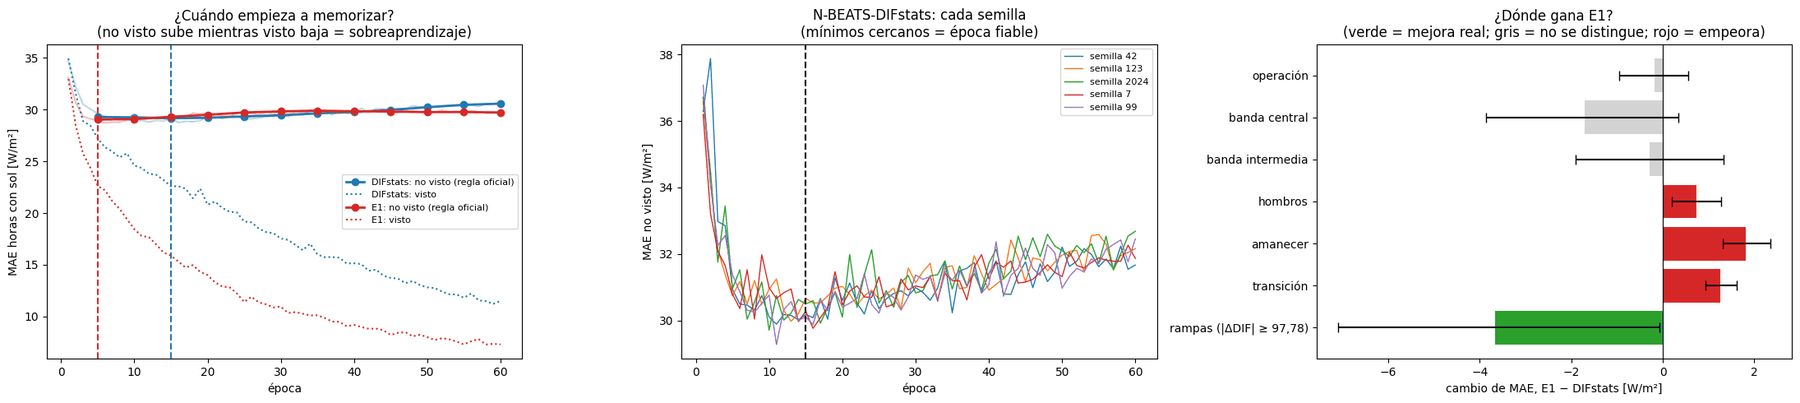


Resultados en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/nbeats/P1_sobreaprendizaje_y_robustez


In [ ]:
import os, time, random, json, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
try:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
except ImportError:
    pass

BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
DIAG = BASE_DIR / "resultados" / "diagnostico"
RUTA_NPZ = (
    BASE_DIR
    / "resultados"
    / "ejecuciones"
    / "preparacion_bloque_difstats_20261006_180841"
    / "matrices_dif_elev_difstats.npz"
)
RUTA_INTRA = (
    DIAG / "fase1_intrahoraria" / "variables_intrahorarias_horarias.csv"
)  # el mismo CSV que E1-30
RUTA_TABLA = DIAG / "faseB_radiografia_E1" / "tabla_horaria_E1.pkl"
RUTA_OOF_LSTM = DIAG / "depuracion_E1_30" / "P1_oof_E1_30.pkl"
SALIDA = DIAG / "nbeats" / "P1_sobreaprendizaje_y_robustez"
SALIDA.mkdir(parents=True, exist_ok=True)
SEMILLAS = [42, 123, 2024, 7, 99]
EPOCAS_MAX, CADA = 60, 5
BATCH, LR, WD = 128, 1e-3, 1e-5  # entrenamiento de la N-BEATS original (Modelado.ipynb, celda 473)
HIDDEN, N_BLOQUES = 128, 6
N_BOOT = 2000
UMBRAL_RAMPA = 97.78

# 1) Entradas: las 9 de E1-30, construidas exactamente igual que en la LSTM
mat = np.load(RUTA_NPZ)
X_tr = mat["X_train_DIF_elev_DIFstats_raw"].astype(np.float32)
y_tr = mat["y_train_difstats"].astype(np.float32).reshape(-1)
fechas = pd.DatetimeIndex(mat["fechas_train"])
intrahora = pd.read_csv(RUTA_INTRA, index_col=0, parse_dates=True).asfreq("h")

def a_ventanas(tabla, fechas_obj, columnas, lookback=24):
    f = pd.DatetimeIndex(fechas_obj).to_numpy(dtype="datetime64[ns]")
    idx = f[:, None] - np.arange(lookback, 0, -1).astype("timedelta64[h]")[None, :]
    vals = tabla.reindex(pd.DatetimeIndex(idx.reshape(-1)))[columnas].to_numpy(dtype=np.float32)
    return vals.reshape(len(f), lookback, len(columnas))

CANALES_E1 = ["DIF_ult15", "DIF_pend30", "DIF_acel60", "DIF_saltos", "SWD_cv"]

def construir(fechas_obj, X_base, canales):
    Xn = a_ventanas(intrahora, fechas_obj, canales)
    for j, c in enumerate(canales):
        hueco = np.isnan(Xn[:, :, j])
        Xn[:, :, j][hueco] = X_base[:, :, 0][hueco] if c == "DIF_ult15" else 0.0
    return np.concatenate([X_base, Xn], axis=2).astype(np.float32)

XS = {"DIFstats": X_tr, "E1": construir(fechas, X_tr, CANALES_E1)}
for c, Z in XS.items():
    print(f"Entradas N-BEATS-{c} (train): {Z.shape}")

T = pd.read_pickle(RUTA_TABLA)
TR = T[T["conjunto"] == "train"]
assert len(TR) == len(y_tr) and (TR.index == fechas).all(), "La tabla horaria no cuadra con el .npz"
SOL = (TR["regimen"] != "noche").to_numpy()
mes = fechas.to_period("M").astype(str).to_numpy()
mes = np.where(mes == "2023-12", "2024-01", mes)  # diciembre se une a enero, como en la LSTM
MESES = sorted(np.unique(mes))

def pliegue(m):
    fuera = mes == m
    fin = fechas[fuera].max()
    purga = (fechas > fin) & (fechas <= fin + pd.Timedelta("24h"))
    return ~fuera & ~purga, fuera

print(
    f"{len(MESES)} pliegues: {', '.join(MESES)} · {len(SEMILLAS)} semillas → {len(MESES) * len(SEMILLAS)} entrenamientos"
)

# 2) N-BEATS de Modelado.ipynb (6 bloques genéricos; residuo solo sobre la DIF; resto como covariables)
import torch, torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler

class NBEATSBlockDIFStats(nn.Module):
    def __init__(self, input_size=96, hidden_size=128, backcast_size=24):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU(),
        )
        self.backcast = nn.Linear(hidden_size, backcast_size)
        self.forecast = nn.Linear(hidden_size, 1)

    def forward(self, x):
        h = self.fc(x)
        return self.backcast(h), self.forecast(h)

class NBEATSDIFStats(nn.Module):
    def __init__(self, lookback=24, n_features=4, hidden_size=128, n_bloques=6):
        super().__init__()
        self.blocks = nn.ModuleList(
            [
                NBEATSBlockDIFStats(lookback * n_features, hidden_size, lookback)
                for _ in range(n_bloques)
            ]
        )

    def forward(self, x):
        residual_dif = x[:, :, 0]
        covariables = x[:, :, 1:].permute(0, 2, 1).contiguous().reshape(x.size(0), -1)
        forecast_total = torch.zeros((x.size(0), 1), dtype=x.dtype, device=x.device)
        for bloque in self.blocks:
            backcast, forecast = bloque(torch.cat([residual_dif, covariables], dim=1))
            residual_dif = residual_dif - backcast
            forecast_total = forecast_total + forecast
        return forecast_total.squeeze(-1)

n_param = {
    c: sum(
        p.numel()
        for p in NBEATSDIFStats(
            n_features=Z.shape[2], hidden_size=HIDDEN, n_bloques=N_BLOQUES
        ).parameters()
    )
    for c, Z in XS.items()
}
print("Parámetros entrenables:", {c: f"{v:,}" for c, v in n_param.items()})

def entrenar(X, entrena, fuera, semilla):
    """Devuelve (épocas × horas del mes no visto) y el MAE visto (horas con sol) en cada época."""
    sx = StandardScaler().fit(X[entrena].reshape(-1, X.shape[2]))
    sy = StandardScaler().fit(y_tr[entrena].reshape(-1, 1))
    e = lambda Z: torch.from_numpy(
        sx.transform(Z.reshape(-1, Z.shape[2])).reshape(Z.shape).astype(np.float32)
    )
    Xtr_t, Xho_t = e(X[entrena]), e(X[fuera])
    ytr_e = sy.transform(y_tr[entrena].reshape(-1, 1)).ravel().astype(np.float32)
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    torch.use_deterministic_algorithms(True)
    modelo = NBEATSDIFStats(n_features=X.shape[2], hidden_size=HIDDEN, n_bloques=N_BLOQUES)
    gen = torch.Generator()
    gen.manual_seed(semilla)
    loader = DataLoader(
        TensorDataset(Xtr_t, torch.from_numpy(ytr_e)),
        batch_size=BATCH,
        shuffle=True,
        generator=gen,
        num_workers=0,
    )
    opt = torch.optim.Adam(modelo.parameters(), lr=LR, weight_decay=WD)
    crit = nn.L1Loss()
    a_W = lambda z: sy.inverse_transform(z.reshape(-1, 1)).ravel()
    preds, visto = [], []
    for ep in range(1, EPOCAS_MAX + 1):
        modelo.train()
        for xb, yb in loader:
            opt.zero_grad(set_to_none=True)
            loss = crit(modelo(xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), max_norm=1.0)
            opt.step()
        modelo.eval()
        with torch.no_grad():
            preds.append(a_W(modelo(Xho_t).numpy()))
            visto.append(np.abs(a_W(modelo(Xtr_t).numpy()) - y_tr[entrena])[SOL[entrena]].mean())
    return np.array(preds, dtype=np.float32), np.array(visto, dtype=np.float32)


# 3) Entrenamientos (reanudables)
t_ini = time.time()
tareas = [(c, m, s) for c in XS for s in SEMILLAS for m in MESES]
for k, (c, m, s) in enumerate(tareas, 1):
    ruta = SALIDA / f"{c}_fold_{m}_s{s}.npz"
    if ruta.exists():
        print(f"[{k}/{len(tareas)}] {c} · {m} · semilla {s}: ya hecho")
        continue
    t0 = time.time()
    entrena, fuera = pliegue(m)
    p, v = entrenar(XS[c], entrena, fuera, s)
    np.savez_compressed(ruta, pred=p, visto=v)
    print(
        f"[{k}/{len(tareas)}] {c} · {m} · semilla {s}: {time.time()-t0:.0f} s (total {(time.time()-t_ini)/60:.1f} min)"
    )

# 4) Curvas y época de cada configuración (regla oficial = la de la LSTM)
EP = np.arange(1, EPOCAS_MAX + 1)
EP5 = np.arange(CADA, EPOCAS_MAX + 1, CADA)
R = {}
for c in XS:
    OOF = np.zeros((len(SEMILLAS), EPOCAS_MAX, len(y_tr)), dtype=np.float32)
    VISTO = np.zeros((len(SEMILLAS), len(MESES), EPOCAS_MAX))
    for i, s in enumerate(SEMILLAS):
        for j, m in enumerate(MESES):
            d = np.load(SALIDA / f"{c}_fold_{m}_s{s}.npz")
            OOF[i][:, mes == m] = d["pred"]
            VISTO[i, j] = d["visto"]
    ens = OOF.mean(axis=0)
    mae_ens = np.abs(ens[:, SOL] - y_tr[SOL]).mean(axis=1)
    mae_sem = np.abs(OOF[:, :, SOL] - y_tr[SOL]).mean(axis=2)
    suave5 = pd.Series(mae_ens[EP5 - 1], index=EP5).rolling(3, center=True, min_periods=1).mean()
    ep = int(suave5.idxmin())
    R[c] = dict(
        OOF=OOF,
        ens=ens,
        mae_ens=mae_ens,
        mae_sem=mae_sem,
        visto=VISTO.mean(axis=(0, 1)),
        suave5=suave5,
        ep=ep,
        ep_crudo=int(EP[np.argmin(mae_ens)]),
        ep_semilla={
            s: int(
                EP5[
                    np.argmin(
                        pd.Series(mae_sem[i, EP5 - 1])
                        .rolling(3, center=True, min_periods=1)
                        .mean()
                        .values
                    )
                ]
            )
            for i, s in enumerate(SEMILLAS)
        },
    )

print(
    "\n"
    + "=" * 100
    + "\nN-BEATS · SOBREAPRENDIZAJE (train, 7 meses no vistos, 5 semillas, horas con sol)\n"
    + "=" * 100
)
for c, r in R.items():
    print(
        f"{c:9s}: época elegida {r['ep']} → MAE {r['mae_ens'][r['ep']-1]:.2f} W/m² · mínimo época a época {r['ep_crudo']} · "
        f"época 18: {r['mae_ens'][17]:.2f} · época {EPOCAS_MAX}: {r['mae_ens'][-1]:.2f} · por semilla {r['ep_semilla']} · "
        f"hueco visto/no visto {r['mae_ens'][r['ep']-1] - r['visto'][r['ep']-1]:.2f}"
    )

filas = []
for m in MESES:
    msk = (mes == m) & SOL
    fila = {"mes no visto": m, "horas con sol": int(msk.sum())}
    for c, r in R.items():
        fila[f"{c} (ép. {r['ep']})"] = np.abs(r["ens"][r["ep"] - 1, msk] - y_tr[msk]).mean()
        fila[f"{c} (ép. {EPOCAS_MAX})"] = np.abs(r["ens"][-1, msk] - y_tr[msk]).mean()
    filas.append(fila)
M = pd.DataFrame(filas).set_index("mes no visto")
print(
    "\nMAE fuera de muestra por mes (ensemble de 5 semillas), en la época elegida y en la última:"
)
display(M.round(2))

# 5) Robustez: E1 frente a DIFstats, por parejas (cada una en su mejor época)
eD = np.abs(R["DIFstats"]["ens"][R["DIFstats"]["ep"] - 1] - y_tr)
eE = np.abs(R["E1"]["ens"][R["E1"]["ep"] - 1] - y_tr)
dif = eE - eD  # negativo = E1 mejor
hora = fechas.hour.to_numpy()
regimen = TR["regimen"].astype(str).to_numpy()
banda = TR["banda"].astype(str).to_numpy()
delta = y_tr - X_tr[:, -1, 0]
GRUPOS = {
    "operación": SOL,
    "banda central": SOL & pd.Series(banda).str.startswith("central").to_numpy(),
    "banda intermedia": SOL & pd.Series(banda).str.startswith("intermedia").to_numpy(),
    "hombros": SOL & pd.Series(banda).str.startswith("hombros").to_numpy(),
    "amanecer": (regimen == "transicion") & (hora < 12),
    "transición": regimen == "transicion",
    "rampas (|ΔDIF| ≥ 97,78)": SOL & (np.abs(delta) >= UMBRAL_RAMPA),
}
dias = fechas.normalize().to_numpy()

def ic(msk):
    u, inv = np.unique(dias[msk], return_inverse=True)
    g = [np.where(inv == i)[0] for i in range(len(u))]
    dd = dif[msk]
    rng = np.random.default_rng(0)
    medias = [
        dd[np.concatenate([g[i] for i in rng.integers(0, len(g), len(g))])].mean()
        for _ in range(N_BOOT)
    ]
    return dd.mean(), np.percentile(medias, 2.5), np.percentile(medias, 97.5)

filas = []
for nombre, msk in GRUPOS.items():
    c_, lo, hi = ic(msk)
    sem_mejor = sum(
        np.abs(R["E1"]["OOF"][i, R["E1"]["ep"] - 1][msk] - y_tr[msk]).mean()
        < np.abs(R["DIFstats"]["OOF"][i, R["DIFstats"]["ep"] - 1][msk] - y_tr[msk]).mean()
        for i in range(len(SEMILLAS))
    )
    filas.append(
        {
            "grupo": nombre,
            "horas": int(msk.sum()),
            "MAE DIFstats": eD[msk].mean(),
            "MAE E1": eE[msk].mean(),
            "cambio (E1 − DIFstats)": c_,
            "cambio (%)": 100 * c_ / eD[msk].mean(),
            "IC95": f"[{lo:+.2f}, {hi:+.2f}]",
            "semillas en que mejora E1": f"{sem_mejor}/{len(SEMILLAS)}",
            "_lo": lo,
            "_hi": hi,
        }
    )
C = pd.DataFrame(filas).set_index("grupo")
ok1 = not (C.loc["operación", "_lo"] > 0)
ok2 = C.loc["banda central", "_hi"] < 0
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)
print(
    "\n"
    + "=" * 100
    + "\nROBUSTEZ · N-BEATS-E1 frente a N-BEATS-DIFstats (train fuera de muestra, 5 semillas, cada una en su mejor época)\n"
    + "=" * 100
)
print("Cambio negativo = E1 tiene menos error.")
display(C.drop(columns=["_lo", "_hi"]).round(2))
print(
    f"1) operación sin empeorar: {'cumple' if ok1 else 'NO cumple'} · 2) banda central mejora (IC95 < 0): {'cumple' if ok2 else 'NO cumple'}"
)
ganador = "E1" if (ok1 and ok2) else "DIFstats"
ver = (
    f"VEREDICTO: se adopta N-BEATS-{ganador} (época {R[ganador]['ep']}) como N-BEATS candidata."
    + ("" if ganador == "E1" else " E1 no cumple las dos condiciones fijadas.")
)
print("➜ " + ver)
ref = ""
if RUTA_OOF_LSTM.exists():
    L = pd.read_pickle(RUTA_OOF_LSTM)
    assert (L.index == fechas).all()
    mae_l = np.abs(L["OOF30_media"].to_numpy()[SOL] - y_tr[SOL]).mean()
    ref = (
        f"Referencia orientativa: E1-30 (LSTM, 2 semillas) fuera de muestra = {mae_l:.2f} W/m² · "
        f"N-BEATS-{ganador} (5 semillas, época {R[ganador]['ep']}) = {R[ganador]['mae_ens'][R[ganador]['ep']-1]:.2f} W/m²"
    )
    print(ref)

# 6) Gráficas
colores = {"DIFstats": "tab:blue", "E1": "tab:red"}
fig, axs = plt.subplots(1, 3, figsize=(22, 5))
for c, r in R.items():
    axs[0].plot(EP, r["mae_ens"], color=colores[c], alpha=0.3)
    axs[0].plot(
        EP5,
        r["suave5"].values,
        "o-",
        color=colores[c],
        lw=2,
        label=f"{c}: no visto (regla oficial)",
    )
    axs[0].plot(EP, r["visto"], color=colores[c], ls=":", lw=1.5, label=f"{c}: visto")
    axs[0].axvline(r["ep"], color=colores[c], ls="--")
axs[0].set_xlabel("época")
axs[0].set_ylabel("MAE horas con sol [W/m²]")
axs[0].legend(fontsize=8)
axs[0].set_title(
    "¿Cuándo empieza a memorizar?\n(no visto sube mientras visto baja = sobreaprendizaje)"
)
for i, s in enumerate(SEMILLAS):
    axs[1].plot(EP, R[ganador]["mae_sem"][i], lw=1, label=f"semilla {s}")
axs[1].axvline(R[ganador]["ep"], color="k", ls="--")
axs[1].set_xlabel("época")
axs[1].set_ylabel("MAE no visto [W/m²]")
axs[1].legend(fontsize=8)
axs[1].set_title(f"N-BEATS-{ganador}: cada semilla\n(mínimos cercanos = época fiable)")
orden = list(GRUPOS)
axs[2].barh(
    range(len(orden)),
    C.loc[orden, "cambio (E1 − DIFstats)"],
    xerr=[
        C.loc[orden, "cambio (E1 − DIFstats)"] - C.loc[orden, "_lo"],
        C.loc[orden, "_hi"] - C.loc[orden, "cambio (E1 − DIFstats)"],
    ],
    color=[
        "tab:green" if h < 0 else ("tab:red" if l > 0 else "lightgray")
        for l, h in zip(C.loc[orden, "_lo"], C.loc[orden, "_hi"])
    ],
    capsize=4,
)
axs[2].axvline(0, color="k", lw=0.8)
axs[2].set_yticks(range(len(orden)))
axs[2].set_yticklabels(orden)
axs[2].invert_yaxis()
axs[2].set_xlabel("cambio de MAE, E1 − DIFstats [W/m²]")
axs[2].set_title("¿Dónde gana E1?\n(verde = mejora real; gris = no se distingue; rojo = empeora)")
plt.tight_layout()
plt.savefig(SALIDA / "P1_curvas_y_robustez.png", dpi=120)
plt.show()

# 7) Guardado (predicciones fuera de muestra = base del estudio de errores)
for c, r in R.items():
    pd.DataFrame(
        {
            "MAE_no_visto_ensemble": r["mae_ens"],
            "MAE_visto": r["visto"],
            **{f"MAE_no_visto_s{s}": r["mae_sem"][i] for i, s in enumerate(SEMILLAS)},
        },
        index=pd.Index(EP, name="época"),
    ).to_csv(SALIDA / f"curvas_{c}.csv")
    pd.DataFrame(
        {
            "real": y_tr,
            "mes_pliegue": mes,
            "OOF_media": r["ens"][r["ep"] - 1],
            **{f"OOF_s{s}": r["OOF"][i, r["ep"] - 1] for i, s in enumerate(SEMILLAS)},
        },
        index=fechas,
    ).to_pickle(SALIDA / f"oof_{c}_epoca_{r['ep']}.pkl")
    np.savez_compressed(
        SALIDA / f"oof_{c}_todas_epocas.npz",
        oof=r["OOF"],
        y=y_tr,
        fechas=fechas.to_numpy(dtype="datetime64[ns]"),
        mes=mes,
        sol=SOL,
        semillas=np.array(SEMILLAS),
    )
M.to_csv(SALIDA / "por_mes.csv")
C.drop(columns=["_lo", "_hi"]).to_csv(SALIDA / "robustez_E1_vs_DIFstats.csv")
texto = "\n".join(
    [
        f"N-BEATS · P1 sobreaprendizaje y robustez (7 meses fuera, purga 24 h, semillas {SEMILLAS}, hasta {EPOCAS_MAX} épocas)"
    ]
    + [
        f"{c}: época {r['ep']}, MAE fuera de muestra {r['mae_ens'][r['ep']-1]:.2f} W/m²"
        for c, r in R.items()
    ]
    + [
        f"E1 − DIFstats: operación {C.loc['operación','cambio (E1 − DIFstats)']:+.2f} {C.loc['operación','IC95']} · "
        f"central {C.loc['banda central','cambio (E1 − DIFstats)']:+.2f} {C.loc['banda central','IC95']} · "
        f"amanecer {C.loc['amanecer','cambio (%)']:+.1f} %",
        ver,
        ref,
    ]
)
(SALIDA / "INFORME_P1.txt").write_text(texto, encoding="utf-8")
json.dump(
    {
        "semillas": SEMILLAS,
        "epocas_max": EPOCAS_MAX,
        "cada": CADA,
        "lr": LR,
        "wd": WD,
        "batch": BATCH,
        "hidden": HIDDEN,
        "bloques": N_BLOQUES,
        "parametros": n_param,
        "epocas_elegidas": {c: r["ep"] for c, r in R.items()},
        "ganador": ganador,
    },
    open(SALIDA / "configuracion.json", "w"),
    indent=2,
    ensure_ascii=False,
)
print("\nResultados en:", SALIDA)

**Resultados.** N-BEATS-DIFstats elige la época 15, con un MAE fuera de muestra de 29,19 W/m² (30,68 W/m² en la época 60), frente a 26,50 W/m² de E1-30 en las mismas horas (con dos semillas, como referencia orientativa); N-BEATS-E1 elige la época 5 (29,01 W/m²) y no cumple el criterio, por lo que se mantiene N-BEATS-DIFstats. Diferencias de N-BEATS-E1 frente a N-BEATS-DIFstats:

- horas con sol: −0,17 W/m² (IC95 [−0,96; +0,56]), sin empeorar;
- banda central: −1,70 W/m² (IC95 [−3,86; +0,34]), sin la mejora exigida;
- amanecer y transición: un 47,6 % y un 33,8 % más de error.

### 3.2 Validación frente a E1-30

N-BEATS-DIFstats se entrena con todo el entrenamiento y las semillas 42, 123, 2024, 7 y 99, y su predicción en la época 15, fijada en P1, se compara por primera vez en validación (agosto–septiembre de 2024) con E1-30, que no se reentrena. La lectura se fijó antes: con la diferencia de MAE N-BEATS − E1-30 en horas con sol y su IC95 por bootstrap de días, un intervalo entero por encima de 0 indica menos error de E1-30; entero por debajo, de la N-BEATS, y si cruza el 0, no se distinguen. El Diebold–Mariano diario sirve de apoyo, y el desglose y la curva de validación hasta la época 60 solo se describen.

Entradas N-BEATS-DIFstats: train (5149, 24, 4) | validación (1464, 24, 4)
Semilla 42: 72 s (total 1.2 min)
Semilla 123: 45 s (total 2.0 min)
Semilla 2024: 46 s (total 2.7 min)
Semilla 7: 48 s (total 3.5 min)
Semilla 99: 45 s (total 4.3 min)

N-BEATS · P2 · VALIDACIÓN (ago–sep 2024, horas con sol, ensembles de 5 semillas)


,MAE [W/m²],RMSE [W/m²],sesgo [W/m²],ventaja sobre persistencia (%)
"LSTM E1-30 (9 canales, 30 épocas)",23.25,36.27,-2.40,48.36
"N-BEATS-DIFstats (4 canales, 15 épocas)",28.05,43.48,7.86,37.72
persistencia,45.03,59.90,-0.55,0.00


Diferencia N-BEATS − E1-30: +4.79 W/m² (+20.6 %), IC95 [+3.52, +6.05] · Diebold–Mariano diario +6.95, p = 0.0000  →  la LSTM E1-30 es mejor

Por semilla: la N-BEATS tiene menos error en 0 de 5


,E1-30,N-BEATS,N-BEATS − E1-30
s42,24.36,28.17,3.81
s123,24.28,30.40,6.12
s2024,24.58,31.71,7.13
s7,24.45,27.68,3.23
s99,23.54,29.76,6.22



Desglose (IC95 sin ajustar; informa, no decide):


,horas,MAE E1-30,MAE N-BEATS,N-BEATS − E1-30,IC95,lectura
grupo,,,,,,
amanecer,60,3.36,4.48,1.11,"[-0.04, +2.33]",igual
régimen: completamente_diurno,765,26.46,31.84,5.38,"[+3.90, +6.83]",LSTM mejor
régimen: transicion,119,2.67,3.67,1.00,"[+0.34, +1.69]",LSTM mejor
banda: central >40°,205,36.36,47.48,11.12,"[+6.79, +15.59]",LSTM mejor
banda: hombros ≤20°,339,9.82,10.71,0.89,"[-0.02, +1.77]",igual
banda: intermedia 20–40°,340,28.75,33.61,4.87,"[+2.52, +7.13]",LSTM mejor
cielo: despejado,185,14.47,25.72,11.25,"[+8.26, +14.67]",LSTM mejor
cielo: velado,89,20.12,22.32,2.21,"[-1.84, +6.38]",igual
cielo: nubosidad variable,438,32.20,33.76,1.56,"[-0.69, +3.56]",igual



Curva de la N-BEATS en validación (ensemble; informativa, la época ya estaba fijada):
   ep1: 31.93 · ep5: 27.85 · ep10: 26.67 · ep15: 28.05 · ep20: 28.02 · ep30: 28.33 · ep40: 28.65 · ep50: 28.86 · ep60: 29.55


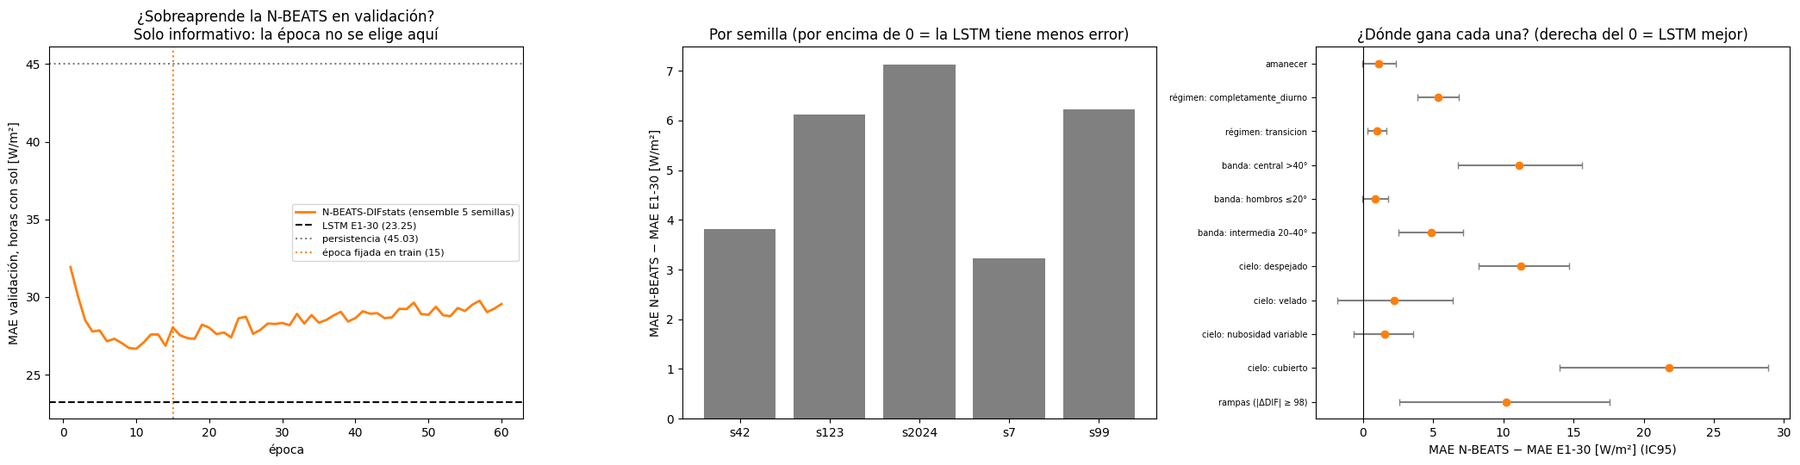


➜ N-BEATS-DIFstats (época 15) en validación: MAE 28.05 W/m² frente a 23.25 de la LSTM E1-30 (diferencia +4.79, IC95 [+3.52, +6.05], DM p = 0.0000) → la LSTM E1-30 es mejor.
Resultados en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/nbeats/P2_validacion


In [ ]:
import os, time, random, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings("ignore")
try:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
except ImportError:
    pass

BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
DIAG = BASE_DIR / "resultados" / "diagnostico"
RUTA_NPZ = (
    BASE_DIR
    / "resultados"
    / "ejecuciones"
    / "preparacion_bloque_difstats_20261006_180841"
    / "matrices_dif_elev_difstats.npz"
)
RUTA_TABLA = DIAG / "faseB_radiografia_E1" / "tabla_horaria_E1.pkl"
DIR_5C = DIAG / "faseC_regularizacion" / "C5c_confirmacion"
SALIDA = DIAG / "nbeats" / "P2_validacion"
SALIDA.mkdir(parents=True, exist_ok=True)
SEMILLAS = [42, 123, 2024, 7, 99]
EPOCA_NB, EPOCAS_MAX = 15, 60
BATCH, LR, WD = 128, 1e-3, 1e-5  # receta de P1 (N-BEATS original)
HIDDEN, N_BLOQUES = 128, 6
N_BOOT = 2000
UMBRAL_RAMPA = 97.78

# 1) Datos: las 4 entradas DIFstats (las mismas de P1)
mat = np.load(RUTA_NPZ)
X_tr = mat["X_train_DIF_elev_DIFstats_raw"].astype(np.float32)
y_tr = mat["y_train_difstats"].astype(np.float32).reshape(-1)
X_va = mat["X_validation_DIF_elev_DIFstats_raw"].astype(np.float32)
y_va = mat["y_validation_difstats"].astype(np.float64).reshape(-1)
fechas_va = pd.DatetimeIndex(mat["fechas_validation"])
print(f"Entradas N-BEATS-DIFstats: train {X_tr.shape} | validación {X_va.shape}")
T = pd.read_pickle(RUTA_TABLA).sort_index()
VA = T[T["conjunto"] == "validation"]
assert (
    len(VA) == len(y_va) and (VA.index == fechas_va).all()
), "La tabla horaria no cuadra con el .npz"

# 2) N-BEATS (idéntica a P1) y entrenamiento con todo train
import torch, torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler

class NBEATSBlockDIFStats(nn.Module):
    def __init__(self, input_size=96, hidden_size=128, backcast_size=24):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU(),
        )
        self.backcast = nn.Linear(hidden_size, backcast_size)
        self.forecast = nn.Linear(hidden_size, 1)

    def forward(self, x):
        h = self.fc(x)
        return self.backcast(h), self.forecast(h)

class NBEATSDIFStats(nn.Module):
    def __init__(self, lookback=24, n_features=4, hidden_size=128, n_bloques=6):
        super().__init__()
        self.blocks = nn.ModuleList(
            [
                NBEATSBlockDIFStats(lookback * n_features, hidden_size, lookback)
                for _ in range(n_bloques)
            ]
        )

    def forward(self, x):
        residual_dif = x[:, :, 0]
        covariables = x[:, :, 1:].permute(0, 2, 1).contiguous().reshape(x.size(0), -1)
        forecast_total = torch.zeros((x.size(0), 1), dtype=x.dtype, device=x.device)
        for bloque in self.blocks:
            backcast, forecast = bloque(torch.cat([residual_dif, covariables], dim=1))
            residual_dif = residual_dif - backcast
            forecast_total = forecast_total + forecast
        return forecast_total.squeeze(-1)

sx = StandardScaler().fit(X_tr.reshape(-1, X_tr.shape[2]))
sy = StandardScaler().fit(y_tr.reshape(-1, 1))
esc = lambda Z: torch.from_numpy(
    sx.transform(Z.reshape(-1, Z.shape[2])).reshape(Z.shape).astype(np.float32)
)
Xtr_t, Xva_t = esc(X_tr), esc(X_va)
ytr_e = sy.transform(y_tr.reshape(-1, 1)).ravel().astype(np.float32)

def entrenar(semilla):
    """Predicción de validación en cada época (filas = épocas 1…60); guarda el modelo de la época 15."""
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    torch.use_deterministic_algorithms(True)
    modelo = NBEATSDIFStats(n_features=X_tr.shape[2], hidden_size=HIDDEN, n_bloques=N_BLOQUES)
    gen = torch.Generator()
    gen.manual_seed(semilla)
    loader = DataLoader(
        TensorDataset(Xtr_t, torch.from_numpy(ytr_e)),
        batch_size=BATCH,
        shuffle=True,
        generator=gen,
        num_workers=0,
    )
    opt = torch.optim.Adam(modelo.parameters(), lr=LR, weight_decay=WD)
    crit = nn.L1Loss()
    preds = []
    for ep in range(1, EPOCAS_MAX + 1):
        modelo.train()
        for xb, yb in loader:
            opt.zero_grad(set_to_none=True)
            loss = crit(modelo(xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), max_norm=1.0)
            opt.step()
        modelo.eval()
        with torch.no_grad():
            preds.append(sy.inverse_transform(modelo(Xva_t).numpy().reshape(-1, 1)).ravel())
        if ep == EPOCA_NB:
            torch.save(
                {"model_state_dict": modelo.state_dict(), "n_features": X_tr.shape[2]},
                SALIDA / f"modelo_NBEATS_DIFstats_ep{EPOCA_NB}_s{semilla}.pt",
            )
    return np.array(preds, dtype=np.float32)

t_ini = time.time()
PN = {}
for s in SEMILLAS:
    ruta = SALIDA / f"pred_validation_NBEATS_s{s}.npz"
    if ruta.exists():
        PN[s] = np.load(ruta)["pred"]
        print(f"Semilla {s}: ya hecha, se carga de Drive")
        continue
    t0 = time.time()
    PN[s] = entrenar(s)
    np.savez_compressed(ruta, pred=PN[s])
    print(f"Semilla {s}: {time.time()-t0:.0f} s (total {(time.time()-t_ini)/60:.1f} min)")

# 3) Comparación en validación (horas con sol), ensembles de 5 semillas
sol = (VA["regimen"] != "noche").to_numpy()
inf = VA[sol].copy()
y = y_va[sol]
P_l = {s: np.load(DIR_5C / f"pred_validation_s{s}.npz")["ep30"] for s in SEMILLAS}
pred_l = np.mean([P_l[s] for s in SEMILLAS], axis=0)[sol]
pred_n = np.mean([PN[s][EPOCA_NB - 1] for s in SEMILLAS], axis=0)[sol]
eL, eN = np.abs(pred_l - y), np.abs(pred_n - y)
assert abs(eL.mean() - 23.25) < 0.05, f"No se reproduce el MAE de E1-30 ({eL.mean():.2f})"
pers = inf["persistencia"].to_numpy()
mae_pers = np.nanmean(np.abs(pers - y))
d = eN - eL  # positivo = la LSTM tiene menos error
dias = inf.index.normalize().to_numpy()
u, inv = np.unique(dias, return_inverse=True)
grupos_dia = [np.where(inv == i)[0] for i in range(len(u))]
rng = np.random.default_rng(0)
remuestras = [
    np.concatenate([grupos_dia[i] for i in rng.integers(0, len(grupos_dia), len(grupos_dia))])
    for _ in range(N_BOOT)
]

def ic(msk=None):
    x = d if msk is None else np.where(msk, d, np.nan)
    medias = [np.nanmean(x[r]) for r in remuestras]
    return np.nanmean(x), np.nanpercentile(medias, 2.5), np.nanpercentile(medias, 97.5)

def dm_diario(x):
    s_ = pd.Series(x, index=inf.index).groupby(dias).mean().to_numpy()
    Tn = len(s_)
    dc = s_ - s_.mean()
    L = int(np.floor(Tn ** (1 / 3)))
    var = dc @ dc / Tn + sum(
        2 * (1 - k / (L + 1)) * (dc[k:] @ dc[:-k]) / Tn for k in range(1, L + 1)
    )
    dm = s_.mean() / np.sqrt(var / Tn) * np.sqrt((Tn - 1) / Tn)
    return dm, 2 * stats.t.sf(abs(dm), df=Tn - 1)

c, lo, hi = ic()
dm, p_dm = dm_diario(d)
lectura = (
    "la LSTM E1-30 es mejor"
    if lo > 0
    else ("la N-BEATS es mejor" if hi < 0 else "no se distinguen")
)
rmse = lambda e: np.sqrt(np.mean(e**2))
R = pd.DataFrame(
    {
        "MAE [W/m²]": [eL.mean(), eN.mean(), mae_pers],
        "RMSE [W/m²]": [rmse(pred_l - y), rmse(pred_n - y), np.sqrt(np.nanmean((pers - y) ** 2))],
        "sesgo [W/m²]": [np.mean(pred_l - y), np.mean(pred_n - y), np.nanmean(pers - y)],
        "ventaja sobre persistencia (%)": [
            100 * (1 - eL.mean() / mae_pers),
            100 * (1 - eN.mean() / mae_pers),
            0.0,
        ],
    },
    index=[
        "LSTM E1-30 (9 canales, 30 épocas)",
        f"N-BEATS-DIFstats (4 canales, {EPOCA_NB} épocas)",
        "persistencia",
    ],
)
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)
print(
    "\n"
    + "=" * 110
    + f"\nN-BEATS · P2 · VALIDACIÓN (ago–sep 2024, horas con sol, ensembles de 5 semillas)\n"
    + "=" * 110
)
display(R.round(2))
print(
    f"Diferencia N-BEATS − E1-30: {c:+.2f} W/m² ({100 * c / eL.mean():+.1f} %), IC95 [{lo:+.2f}, {hi:+.2f}] · "
    f"Diebold–Mariano diario {dm:+.2f}, p = {p_dm:.4f}  →  {lectura}"
)
por_semilla = pd.DataFrame(
    {
        f"s{s}": [np.abs(P_l[s][sol] - y).mean(), np.abs(PN[s][EPOCA_NB - 1][sol] - y).mean()]
        for s in SEMILLAS
    },
    index=["E1-30", "N-BEATS"],
).T
por_semilla["N-BEATS − E1-30"] = por_semilla["N-BEATS"] - por_semilla["E1-30"]
print(
    f"\nPor semilla: la N-BEATS tiene menos error en {(por_semilla['N-BEATS − E1-30'] < 0).sum()} de {len(SEMILLAS)}"
)
display(por_semilla.round(2))

# Desglose (informativo)
inf["cielo"] = inf["cielo"].astype(str).replace({"nubes rotas": "nubosidad variable"})
hora = inf.index.hour.to_numpy()
regimen, banda = inf["regimen"].astype(str).to_numpy(), inf["banda"].astype(str)
delta = y - X_va[sol, -1, 0]
grupos = [("amanecer", (regimen == "transicion") & (hora < 12))]
grupos += [(f"régimen: {g}", regimen == g) for g in sorted(np.unique(regimen))]
grupos += [(f"banda: {g}", (banda == g).to_numpy()) for g in sorted(banda.unique())]
grupos += [
    (f"cielo: {g}", (inf["cielo"] == g).to_numpy())
    for g in ["despejado", "velado", "nubosidad variable", "cubierto"]
]
grupos += [(f"rampas (|ΔDIF| ≥ {UMBRAL_RAMPA:.0f})", np.abs(delta) >= UMBRAL_RAMPA)]
filas = []
for nombre, msk in grupos:
    if msk.sum() >= 30:
        cg, lg, hg = ic(msk)
        filas.append(
            {
                "grupo": nombre,
                "horas": int(msk.sum()),
                "MAE E1-30": eL[msk].mean(),
                "MAE N-BEATS": eN[msk].mean(),
                "N-BEATS − E1-30": cg,
                "IC95": f"[{lg:+.2f}, {hg:+.2f}]",
                "lectura": "LSTM mejor" if lg > 0 else ("N-BEATS mejor" if hg < 0 else "igual"),
            }
        )
G = pd.DataFrame(filas).set_index("grupo")
print("\nDesglose (IC95 sin ajustar; informa, no decide):")
display(G.round(2))
curva = pd.Series(
    [
        np.abs(np.mean([PN[s][k] for s in SEMILLAS], axis=0)[sol] - y).mean()
        for k in range(EPOCAS_MAX)
    ],
    index=np.arange(1, EPOCAS_MAX + 1),
)
print("\nCurva de la N-BEATS en validación (ensemble; informativa, la época ya estaba fijada):")
print("   " + " · ".join(f"ep{e}: {curva[e]:.2f}" for e in [1, 5, 10, 15, 20, 30, 40, 50, 60]))

# 4) Gráficas
fig, axs = plt.subplots(1, 3, figsize=(21, 5.5))
axs[0].plot(
    curva.index,
    curva.values,
    color="tab:orange",
    lw=2,
    label="N-BEATS-DIFstats (ensemble 5 semillas)",
)
axs[0].axhline(eL.mean(), color="black", ls="--", label=f"LSTM E1-30 ({eL.mean():.2f})")
axs[0].axhline(mae_pers, color="gray", ls=":", label=f"persistencia ({mae_pers:.2f})")
axs[0].axvline(EPOCA_NB, color="tab:orange", ls=":", label=f"época fijada en train ({EPOCA_NB})")
axs[0].set_xlabel("época")
axs[0].set_ylabel("MAE validación, horas con sol [W/m²]")
axs[0].legend(fontsize=8)
axs[0].set_title(
    "¿Sobreaprende la N-BEATS en validación?\nSolo informativo: la época no se elige aquí"
)
x = np.arange(len(SEMILLAS))
axs[1].bar(
    x,
    por_semilla["N-BEATS − E1-30"],
    color=["tab:orange" if v < 0 else "gray" for v in por_semilla["N-BEATS − E1-30"]],
)
axs[1].axhline(0, color="k", lw=0.8)
axs[1].set_xticks(x)
axs[1].set_xticklabels(por_semilla.index)
axs[1].set_ylabel("MAE N-BEATS − MAE E1-30 [W/m²]")
axs[1].set_title("Por semilla (por encima de 0 = la LSTM tiene menos error)")
lims = G["IC95"].str.strip("[]").str.split(",", expand=True).astype(float)
yy = np.arange(len(G))
axs[2].errorbar(
    G["N-BEATS − E1-30"],
    yy,
    xerr=[G["N-BEATS − E1-30"] - lims[0], lims[1] - G["N-BEATS − E1-30"]],
    fmt="o",
    color="tab:orange",
    ecolor="gray",
    capsize=3,
)
axs[2].axvline(0, color="k", lw=0.8)
axs[2].set_yticks(yy)
axs[2].set_yticklabels(G.index, fontsize=7)
axs[2].invert_yaxis()
axs[2].set_xlabel("MAE N-BEATS − MAE E1-30 [W/m²] (IC95)")
axs[2].set_title("¿Dónde gana cada una? (derecha del 0 = LSTM mejor)")
plt.tight_layout()
plt.savefig(SALIDA / "P2_validacion.png", dpi=120)
plt.show()

# 5) Guardado
ver = (
    f"N-BEATS-DIFstats (época {EPOCA_NB}) en validación: MAE {eN.mean():.2f} W/m² frente a {eL.mean():.2f} de la LSTM E1-30 "
    f"(diferencia {c:+.2f}, IC95 [{lo:+.2f}, {hi:+.2f}], DM p = {p_dm:.4f}) → {lectura}."
)
print("\n➜ " + ver)
R.to_csv(SALIDA / "P2_resumen.csv")
G.to_csv(SALIDA / "P2_desglose.csv")
por_semilla.to_csv(SALIDA / "P2_por_semilla.csv")
curva.rename("MAE_validacion_NBEATS").to_csv(SALIDA / "P2_curva_validacion.csv")
pd.DataFrame(
    {
        "real": y_va,
        "E1_30": np.mean([P_l[s] for s in SEMILLAS], axis=0),
        f"NBEATS_{EPOCA_NB}": np.mean([PN[s][EPOCA_NB - 1] for s in SEMILLAS], axis=0),
    },
    index=fechas_va,
).to_pickle(SALIDA / "P2_predicciones_validacion.pkl")
(SALIDA / "P2_veredicto.txt").write_text(ver + "\n", encoding="utf-8")
print("Resultados en:", SALIDA)

**Resultados.** N-BEATS-DIFstats obtiene un MAE de 28,05 W/m², 4,79 W/m² más que E1-30 (23,25 W/m²; IC95 [+3,52; +6,05]; Diebold–Mariano p < 0,0001), y la diferencia es positiva en las cinco semillas: E1-30 tiene menos error. El sesgo es de +7,86 W/m², frente a −2,40 W/m² de E1-30. En el desglose descriptivo, E1-30 tiene menos error en las horas completamente diurnas y de transición, en la banda central (+11,12 W/m²), con cielo despejado (+11,25 W/m²) y cubierto, y en las rampas; con nubosidad variable no se distinguen (+1,56 W/m², IC95 [−0,69; +3,56]).

## 4. Sesgo y variabilidad

> *Se utiliza en la memoria: apartado 5.4.2 y Tabla C1 (N0, N1, N2 y N2b), y fases 29 a 32 de la Tabla A1.*

### 4.1 Origen del sesgo positivo

Sin entrenar ningún modelo, se comprueba si el sesgo positivo de N-BEATS-DIFstats en validación ya existía en las predicciones fuera de muestra de entrenamiento (N-BEATS-DIFstats de P1 en la época 15, con cinco semillas, y E1-30 con dos, en los mismos siete meses) o solo aparece en agosto y septiembre. Se mide la diferencia de sesgos N-BEATS − LSTM en horas con sol, con IC95 por bootstrap de días, y se desglosa por mes, cielo, banda y nivel de la DIF en T−1. Según la regla fijada antes, se trata de un defecto del modelo si en entrenamiento la diferencia es ≥ +3 W/m² con el IC95 por encima de 0, y de un efecto del cambio de estación si no lo es en entrenamiento y sí en validación.

Comprobación de MAE (N-BEATS, LSTM): {'train (fuera de muestra)': (np.float64(29.19), np.float64(26.5)), 'validación': (np.float64(28.05), np.float64(23.25))} ← esperado train (29.19, 26.50) · validación (28.05, 23.25)

N0 · ¿EL SESGO POSITIVO DE LA N-BEATS YA ESTÁ EN TRAIN?
train (fuera de muestra)  : sesgo N-BEATS +3.43 · sesgo LSTM -2.57 · diferencia +6.00 W/m², IC95 [+4.46, +7.68]
validación                : sesgo N-BEATS +7.86 · sesgo LSTM -2.40 · diferencia +10.25 W/m², IC95 [+8.57, +11.92]
➜ DEFECTO DEL MODELO: la N-BEATS ya sobrestima en train frente a la LSTM (+6.00, IC95 [+4.46, +7.68]). N2 = corregir el modelo (normalización / forma de entrar la elevación).

train (fuera de muestra) · por mes:


,horas,DIF media,sesgo N-BEATS,sesgo LSTM,MAE N-BEATS,MAE LSTM,N − L (sesgo),N − L (MAE)
mes,,,,,,,,
2024-01,311,49.13,-1.53,3.47,12.27,11.63,-4.99,0.64
2024-02,315,79.02,-0.90,-0.82,18.10,16.59,-0.08,1.51
2024-03,386,120.62,-2.14,-1.37,25.15,23.30,-0.77,1.85
2024-04,444,156.81,6.46,-14.23,32.12,33.32,20.69,-1.20
2024-05,519,162.37,3.32,3.78,34.05,29.07,-0.46,4.98
2024-06,525,165.97,4.40,-4.39,35.00,30.38,8.80,4.62
2024-07,527,165.98,9.64,-2.64,35.70,31.41,12.28,4.30



train (fuera de muestra) · por cielo:


,horas,DIF media,sesgo N-BEATS,sesgo LSTM,MAE N-BEATS,MAE LSTM,N − L (sesgo),N − L (MAE)
cielo,,,,,,,,
despejado,381,125.95,9.97,4.31,25.35,17.46,5.66,7.89
velado,322,118.03,-3.02,-3.02,19.41,16.73,0.00,2.69
nubosidad variable,1450,200.03,-5.14,-11.63,37.62,37.81,6.49,-0.19
cubierto,451,81.28,32.44,18.39,36.16,26.73,14.05,9.43



train (fuera de muestra) · por banda:


,horas,DIF media,sesgo N-BEATS,sesgo LSTM,MAE N-BEATS,MAE LSTM,N − L (sesgo),N − L (MAE)
banda,,,,,,,,
central >40°,765,270.30,9.95,-4.95,52.06,47.57,14.90,4.49
hombros ≤20°,1384,45.34,-0.88,-0.39,12.38,10.43,-0.49,1.95
intermedia 20–40°,878,165.94,4.55,-3.92,35.75,33.48,8.47,2.27


... (6 outputs left out)


validación · por banda:


,horas,DIF media,sesgo N-BEATS,sesgo LSTM,MAE N-BEATS,MAE LSTM,N − L (sesgo),N − L (MAE)
banda,,,,,,,,
central >40°,205,250.79,14.06,-2.68,47.48,36.36,16.74,11.12
hombros ≤20°,339,44.87,1.68,-2.55,10.71,9.82,4.23,0.89
intermedia 20–40°,340,172.73,10.28,-2.07,33.61,28.75,12.36,4.87



validación · por nivel de DIF en T−1:


,horas,DIF media,sesgo N-BEATS,sesgo LSTM,MAE N-BEATS,MAE LSTM,N − L (sesgo),N − L (MAE)
nivel_T1,,,,,,,,
Q1 (más baja),142,27.21,1.79,-4.35,8.16,8.05,6.13,0.11
Q2,160,64.12,3.11,-2.35,14.57,12.29,5.45,2.28
Q3,191,119.96,2.58,-10.18,26.63,20.94,12.77,5.70
Q4,224,184.00,11.65,0.67,35.95,30.79,10.98,5.16
Q5 (más alta),167,282.01,18.52,4.01,48.88,39.24,14.51,9.65


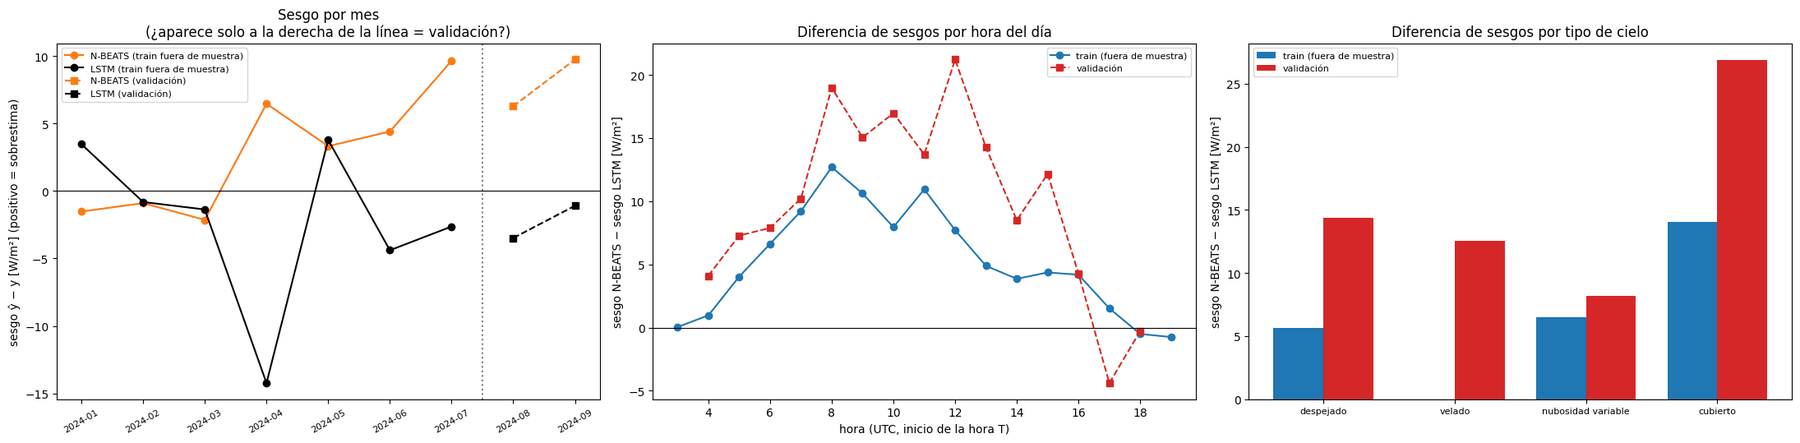

Resultados en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/nbeats/N0_sesgo


In [ ]:
import os
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

try:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
except ImportError:
    pass

BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
DIAG = BASE_DIR / "resultados" / "diagnostico"
RUTA_TABLA = DIAG / "faseB_radiografia_E1" / "tabla_horaria_E1.pkl"
RUTA_OOF_NB = DIAG / "nbeats" / "P1_sobreaprendizaje_y_robustez" / "oof_DIFstats_epoca_15.pkl"
RUTA_OOF_L = DIAG / "depuracion_E1_30" / "P1_oof_E1_30.pkl"
RUTA_VAL = DIAG / "nbeats" / "P2_validacion" / "P2_predicciones_validacion.pkl"
SALIDA = DIAG / "nbeats" / "N0_sesgo"
SALIDA.mkdir(parents=True, exist_ok=True)
N_BOOT = 2000
UMBRAL_SESGO = 3.0

# 1) Datos
T = pd.read_pickle(RUTA_TABLA).sort_index()
ONB, OL, PV = pd.read_pickle(RUTA_OOF_NB), pd.read_pickle(RUTA_OOF_L), pd.read_pickle(RUTA_VAL)
TR = T[T["conjunto"] == "train"].copy()
VA = T[T["conjunto"] == "validation"].copy()
assert (
    (ONB.index == TR.index).all() and (OL.index == TR.index).all() and (PV.index == VA.index).all()
), "Los índices no cuadran"
TR["N"], TR["L"] = ONB["OOF_media"].to_numpy(), OL["OOF30_media"].to_numpy()
VA["N"], VA["L"] = PV["NBEATS_15"].to_numpy(), PV["E1_30"].to_numpy()
TR["dif_T1"] = T["real"].reindex(TR.index - pd.Timedelta("1h")).to_numpy()
VA["dif_T1"] = T["real"].reindex(VA.index - pd.Timedelta("1h")).to_numpy()
D = {}
for nombre, X in [("train (fuera de muestra)", TR), ("validación", VA)]:
    X = X[X["regimen"] != "noche"].copy()
    X["cielo"] = X["cielo"].astype(str).replace({"nubes rotas": "nubosidad variable"})
    X["mes"] = X.index.to_period("M").astype(str).str.replace("2023-12", "2024-01")
    X["hora"] = X.index.hour
    D[nombre] = X
mae = {
    k: (np.abs(X["N"] - X["real"]).mean(), np.abs(X["L"] - X["real"]).mean()) for k, X in D.items()
}
print(
    "Comprobación de MAE (N-BEATS, LSTM):",
    {k: tuple(round(v, 2) for v in m) for k, m in mae.items()},
    "← esperado train (29.19, 26.50) · validación (28.05, 23.25)",
)
assert abs(mae["validación"][0] - 28.05) < 0.05 and abs(mae["validación"][1] - 23.25) < 0.05
assert abs(mae["train (fuera de muestra)"][0] - 29.19) < 0.05

# Nivel de DIF en T−1 (entrada, no resultado): quintiles fijados con train
cortes = np.nanpercentile(D["train (fuera de muestra)"]["dif_T1"], [20, 40, 60, 80])
etq = ["Q1 (más baja)", "Q2", "Q3", "Q4", "Q5 (más alta)"]
for X in D.values():
    X["nivel_T1"] = pd.Categorical(
        np.array(etq)[np.digitize(X["dif_T1"].fillna(-1), cortes)], categories=etq, ordered=True
    )


# 2) Herramientas
def boot(X, x, msk=None):
    dias = X.index.normalize()
    u = np.unique(dias)
    pos = {d: np.where(dias == d)[0] for d in u}
    rng = np.random.default_rng(0)
    v = np.where(msk, x, np.nan) if msk is not None else x
    medias = [
        np.nanmean(v[np.concatenate([pos[d] for d in rng.choice(u, len(u))])])
        for _ in range(N_BOOT)
    ]
    return np.nanmean(v), np.nanpercentile(medias, 2.5), np.nanpercentile(medias, 97.5)

def tabla(X, col, orden=None):
    filas = []
    grupos = orden if orden is not None else sorted(X[col].dropna().unique())
    for g in grupos:
        msk = (X[col] == g).to_numpy()
        if msk.sum() < 30:
            continue
        sub = X[msk]
        filas.append(
            {
                col: g,
                "horas": int(msk.sum()),
                "DIF media": sub["real"].mean(),
                "sesgo N-BEATS": (sub["N"] - sub["real"]).mean(),
                "sesgo LSTM": (sub["L"] - sub["real"]).mean(),
                "MAE N-BEATS": np.abs(sub["N"] - sub["real"]).mean(),
                "MAE LSTM": np.abs(sub["L"] - sub["real"]).mean(),
            }
        )
    R = pd.DataFrame(filas).set_index(col)
    R["N − L (sesgo)"] = R["sesgo N-BEATS"] - R["sesgo LSTM"]
    R["N − L (MAE)"] = R["MAE N-BEATS"] - R["MAE LSTM"]
    return R


# 3) Pregunta principal: diferencia de sesgos en train y en validación
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)
res = {}
print("\n" + "=" * 110 + "\nN0 · ¿EL SESGO POSITIVO DE LA N-BEATS YA ESTÁ EN TRAIN?\n" + "=" * 110)
for k, X in D.items():
    sN, sL = (X["N"] - X["real"]).mean(), (X["L"] - X["real"]).mean()
    c, lo, hi = boot(X, (X["N"] - X["L"]).to_numpy())
    res[k] = (c, lo, hi)
    print(
        f"{k:26s}: sesgo N-BEATS {sN:+.2f} · sesgo LSTM {sL:+.2f} · diferencia {c:+.2f} W/m², IC95 [{lo:+.2f}, {hi:+.2f}]"
    )
ct, lt, ht = res["train (fuera de muestra)"]
cv, lv, hv = res["validación"]
if ct >= UMBRAL_SESGO and lt > 0:
    ver = (
        f"DEFECTO DEL MODELO: la N-BEATS ya sobrestima en train frente a la LSTM ({ct:+.2f}, IC95 [{lt:+.2f}, {ht:+.2f}]). "
        f"N2 = corregir el modelo (normalización / forma de entrar la elevación)."
    )
elif cv >= UMBRAL_SESGO and lv > 0:
    ver = (
        f"CAMBIO DE ESTACIÓN: en train la diferencia de sesgos es pequeña ({ct:+.2f}, IC95 [{lt:+.2f}, {ht:+.2f}]), "
        f"pero en validación es {cv:+.2f} (IC95 [{lv:+.2f}, {hv:+.2f}]). La mayor parte del sesgo aparece al pasar a ago–sep: "
        f"la N-BEATS generaliza peor fuera de los meses de train; en train no hay un defecto grande que corregir."
    )
else:
    ver = f"SIN CONCLUSIÓN: train {ct:+.2f} [{lt:+.2f}, {ht:+.2f}] · validación {cv:+.2f} [{lv:+.2f}, {hv:+.2f}]."
print("➜ " + ver)

# 4) Desglose (informativo)
TAB = {}
for k, X in D.items():
    TAB[(k, "mes")] = tabla(X, "mes")
    TAB[(k, "cielo")] = tabla(X, "cielo", ["despejado", "velado", "nubosidad variable", "cubierto"])
    TAB[(k, "banda")] = tabla(X, "banda")
    TAB[(k, "nivel de DIF en T−1")] = tabla(X, "nivel_T1", etq)
    TAB[(k, "hora")] = tabla(X, "hora")
for (k, g), R in TAB.items():
    if g == "hora":
        continue
    print(f"\n{k} · por {g}:")
    display(R.round(2))

# 5) Gráficas
fig, axs = plt.subplots(1, 3, figsize=(22, 5.5))
Rm = TAB[("train (fuera de muestra)", "mes")]
x = np.arange(len(Rm))
axs[0].plot(
    x, Rm["sesgo N-BEATS"], "o-", color="tab:orange", label="N-BEATS (train fuera de muestra)"
)
axs[0].plot(x, Rm["sesgo LSTM"], "o-", color="black", label="LSTM (train fuera de muestra)")
Rv = TAB[("validación", "mes")]
xv = np.arange(len(Rm), len(Rm) + len(Rv))
axs[0].plot(xv, Rv["sesgo N-BEATS"], "s--", color="tab:orange", label="N-BEATS (validación)")
axs[0].plot(xv, Rv["sesgo LSTM"], "s--", color="black", label="LSTM (validación)")
axs[0].axhline(0, color="k", lw=0.8)
axs[0].axvline(len(Rm) - 0.5, color="gray", ls=":")
axs[0].set_xticks(list(x) + list(xv))
axs[0].set_xticklabels(list(Rm.index) + list(Rv.index), rotation=30, fontsize=8)
axs[0].set_ylabel("sesgo ŷ − y [W/m²] (positivo = sobrestima)")
axs[0].legend(fontsize=8)
axs[0].set_title("Sesgo por mes\n(¿aparece solo a la derecha de la línea = validación?)")
for j, (k, est) in enumerate([("train (fuera de muestra)", "o-"), ("validación", "s--")]):
    Rh = TAB[(k, "hora")]
    axs[1].plot(Rh.index, Rh["N − L (sesgo)"], est, color=["tab:blue", "tab:red"][j], label=k)
axs[1].axhline(0, color="k", lw=0.8)
axs[1].set_xlabel("hora (UTC, inicio de la hora T)")
axs[1].legend(fontsize=8)
axs[1].set_ylabel("sesgo N-BEATS − sesgo LSTM [W/m²]")
axs[1].set_title("Diferencia de sesgos por hora del día")
w = 0.38
for j, k in enumerate(["train (fuera de muestra)", "validación"]):
    Rc = TAB[(k, "cielo")]
    axs[2].bar(
        np.arange(len(Rc)) + (j - 0.5) * w,
        Rc["N − L (sesgo)"],
        w,
        color=["tab:blue", "tab:red"][j],
        label=k,
    )
axs[2].axhline(0, color="k", lw=0.8)
axs[2].set_xticks(range(len(Rc)))
axs[2].set_xticklabels(Rc.index, fontsize=8)
axs[2].set_ylabel("sesgo N-BEATS − sesgo LSTM [W/m²]")
axs[2].legend(fontsize=8)
axs[2].set_title("Diferencia de sesgos por tipo de cielo")
plt.tight_layout()
plt.savefig(SALIDA / "N0_sesgo.png", dpi=120)
plt.show()

# 6) Guardado
for (k, g), R in TAB.items():
    R.to_csv(SALIDA / f"N0_{'train' if k.startswith('train') else 'val'}_por_{g.split(' ')[0]}.csv")
(SALIDA / "N0_veredicto.txt").write_text(ver + "\n", encoding="utf-8")
print("Resultados en:", SALIDA)

**Resultados.** En entrenamiento fuera de muestra, el sesgo es de +3,43 W/m² en N-BEATS-DIFstats y de −2,57 W/m² en E1-30, una diferencia de +6,00 W/m² (IC95 [+4,46; +7,68]); en validación, la diferencia es de +10,25 W/m² (IC95 [+8,57; +11,92]). Según la regla, el sesgo es un defecto del modelo y no del periodo. En entrenamiento, el sesgo de la N-BEATS es negativo de enero a marzo y positivo de abril a julio (+9,64 W/m² en julio), y es mayor en la banda central (+9,95 W/m²), con cielo cubierto (+32,44 W/m²) y en el quintil más alto de la DIF en T−1 (+9,63 W/m²).

### 4.2 Escala de cielo despejado de la hora objetivo

Se añade a N-BEATS-DIFstats un quinto canal con la escala de cielo despejado de la hora objetivo, D*(T) (la GHI media de cielo despejado de esa hora, con un mínimo de 50 W/m²), el mismo que se probó en la LSTM, y se compara con N-BEATS-DIFstats en la criba de cuatro meses (enero con diciembre, marzo, mayo y julio, con purga de 24 horas), con las semillas 42 y 123, hasta 60 épocas y cada configuración en su mejor época. El criterio, fijado antes, exige una mejora en horas con sol ≥ 0,5 W/m² con el IC95 entero por debajo de 0 y que la banda central no empeore de forma significativa; como predicción comprobable, escrita también antes, el sesgo positivo debería bajar en la banda central y por la mañana (7–11 UTC).

Huecos en D_next: 0  ← esperado 0
BASE · N-BEATS-DIFstats (4 canales): (5149, 24, 4)
VX · + escala de cielo despejado D*(T) (5 canales): (5149, 24, 5)
[1/8] VX · 2024-01 · semilla 42: 44 s (total 0.7 min)
[2/8] VX · 2024-03 · semilla 42: 37 s (total 1.3 min)
[3/8] VX · 2024-05 · semilla 42: 39 s (total 2.0 min)
[4/8] VX · 2024-07 · semilla 42: 39 s (total 2.6 min)
[5/8] VX · 2024-01 · semilla 123: 36 s (total 3.2 min)
[6/8] VX · 2024-03 · semilla 123: 39 s (total 3.9 min)
[7/8] VX · 2024-05 · semilla 123: 38 s (total 4.5 min)
[8/8] VX · 2024-07 · semilla 123: 38 s (total 5.2 min)

N1 · ¿AYUDA LA ESCALA DE CIELO DESPEJADO A LA N-BEATS? (train, 4 meses no vistos, 2 semillas, horas con sol)
Cambio negativo = menos error que BASE. IC95 bootstrap por días.


,mejor época,MAE operación,veredicto,cambio operación,IC95 operación,cambio central,IC95 central,"1 mejora ≥0,5 e IC<0",2 central sin empeorar
configuración,,,,,,,,,
BASE · N-BEATS-DIFstats (4 canales),20,29.32,referencia,NaN,NaN,NaN,NaN,NaN,NaN
VX · + escala de cielo despejado D*(T) (5 canales),20,29.46,no pasa,0.14,"[-0.34, +0.63]",0.2,"[-1.08, +1.39]",False,True



Sesgo (ŷ − y; positivo = sobrestima). Predicción de N0: debería bajar en la banda central y por la mañana:


,horas,sesgo BASE,sesgo VX,cambio de sesgo,IC95,lectura
grupo,,,,,,
todas las horas con sol,1743,-0.74,-3.41,-2.67,"[-3.43, -1.95]",baja
banda central,426,-4.96,-4.25,0.71,"[-1.30, +2.52]",igual
mañana (7–11 UTC),622,6.11,1.33,-4.78,"[-6.10, -3.51]",baja



Desglose del MAE (IC95 sin ajustar; informa, no decide):


,horas,MAE BASE,MAE VX,cambio,IC95,lectura
grupo,,,,,,
amanecer,124,4.57,4.03,-0.54,"[-1.04, -0.07]",mejora
régimen: transición,247,3.83,3.62,-0.21,"[-0.53, +0.10]",igual
banda central,426,53.45,53.65,0.20,"[-1.08, +1.39]",igual
rampas (|ΔDIF| ≥ 98),172,76.19,78.40,2.21,"[+0.38, +3.93]",EMPEORA
mañana (7–11 UTC),622,35.23,34.88,-0.35,"[-1.21, +0.44]",igual
cielo: despejado,248,25.12,25.32,0.20,"[-1.03, +1.49]",igual
cielo: velado,200,20.55,20.99,0.43,"[-0.94, +1.83]",igual
cielo: nubosidad variable,803,39.62,40.11,0.48,"[-0.30, +1.21]",igual
cielo: cubierto,245,32.66,31.70,-0.97,"[-2.48, +0.48]",igual


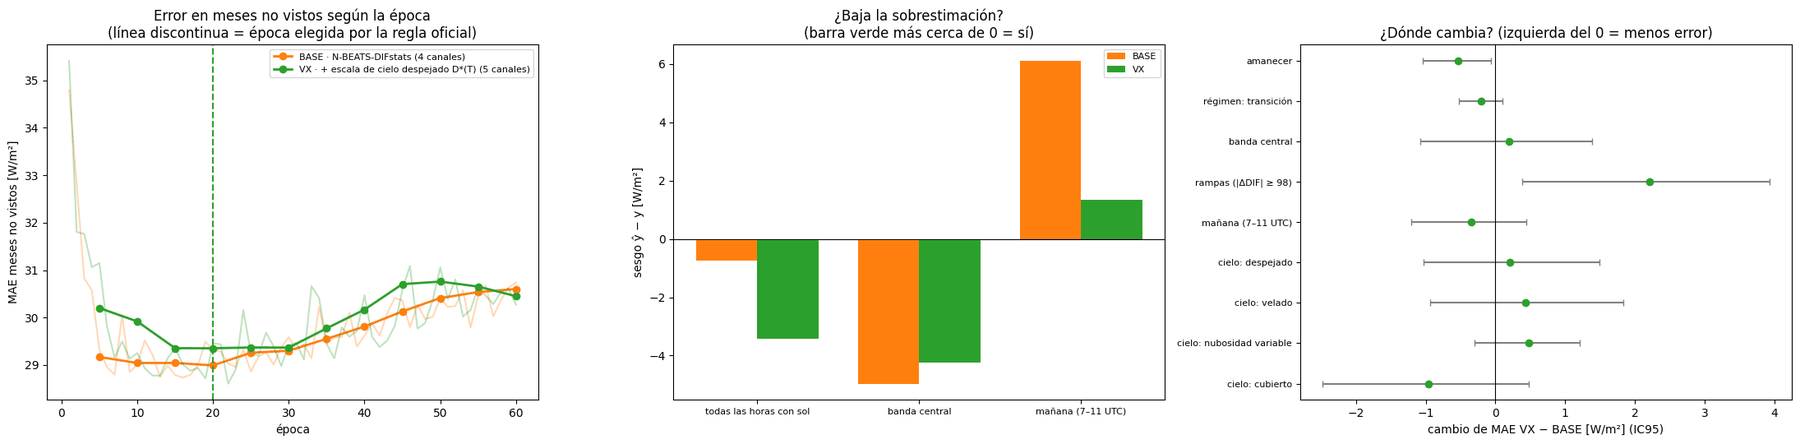


➜ NO PASA: VX cambia +0.14 W/m² (IC95 [-0.34, +0.63]); no mejora a la N-BEATS de forma fiable.
Resultados en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/nbeats/N1_escala_cielo_despejado


In [ ]:
import os, time, random, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
try:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
except ImportError:
    pass

BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
DIAG = BASE_DIR / "resultados" / "diagnostico"
RUTA_NPZ = (
    BASE_DIR
    / "resultados"
    / "ejecuciones"
    / "preparacion_bloque_difstats_20261006_180841"
    / "matrices_dif_elev_difstats.npz"
)
RUTA_TABLA = DIAG / "faseB_radiografia_E1" / "tabla_horaria_E1.pkl"
RUTA_ESC = DIAG / "faseC_normalizacion" / "C6_escala_y_variabilidad.csv"
DIR_P1 = DIAG / "nbeats" / "P1_sobreaprendizaje_y_robustez"
SALIDA = DIAG / "nbeats" / "N1_escala_cielo_despejado"
DIR_P = SALIDA / "predicciones"
DIR_P.mkdir(parents=True, exist_ok=True)
assert RUTA_ESC.exists(), "No encuentro la tabla de escala de C6 (C6_escala_y_variabilidad.csv)"
SEMILLAS = [42, 123]
MESES_CRIBA = ["2024-01", "2024-03", "2024-05", "2024-07"]
EPOCAS_MAX, CADA = 60, 5
BATCH, LR, WD = 128, 1e-3, 1e-5
HIDDEN, N_BLOQUES = 128, 6
EFECTO_MINIMO = 0.5
N_BOOT = 2000
UMBRAL_RAMPA = 97.78

# 1) Entradas
mat = np.load(RUTA_NPZ)
X_tr = mat["X_train_DIF_elev_DIFstats_raw"].astype(np.float32)
y_tr = mat["y_train_difstats"].astype(np.float32).reshape(-1)
fechas = pd.DatetimeIndex(mat["fechas_train"])
ESC = pd.read_csv(RUTA_ESC, index_col=0, parse_dates=True).asfreq("h")

def a_ventanas(tabla, fechas_obj, columnas, lookback=24):
    f = pd.DatetimeIndex(fechas_obj).to_numpy(dtype="datetime64[ns]")
    idx = f[:, None] - np.arange(lookback, 0, -1).astype("timedelta64[h]")[None, :]  # T−24 … T−1
    vals = tabla.reindex(pd.DatetimeIndex(idx.reshape(-1)))[columnas].to_numpy(
        dtype=np.float32, copy=True
    )
    return vals.reshape(len(f), lookback, len(columnas))

D_next = a_ventanas(ESC, fechas, ["D_next"])
print(f"Huecos en D_next: {int(np.isnan(D_next).sum())}  ← esperado 0")
assert not np.isnan(D_next).any()
D_T = ESC["D_star"].reindex(fechas).to_numpy(np.float32)
assert np.allclose(D_next[:, -1, 0], D_T), "En el último paso, D_next debería ser D*(T)"
XS = {"BASE": X_tr, "VX": np.concatenate([X_tr, D_next], axis=2).astype(np.float32)}
NOMBRE = {
    "BASE": "BASE · N-BEATS-DIFstats (4 canales)",
    "VX": "VX · + escala de cielo despejado D*(T) (5 canales)",
}
for c, Z in XS.items():
    print(f"{NOMBRE[c]}: {Z.shape}")

T = pd.read_pickle(RUTA_TABLA)
TR = T[T["conjunto"] == "train"]
assert len(TR) == len(y_tr) and (TR.index == fechas).all(), "La tabla horaria no cuadra con el .npz"
SOL = (TR["regimen"] != "noche").to_numpy()
mes = fechas.to_period("M").astype(str).to_numpy()
mes = np.where(mes == "2023-12", "2024-01", mes)

def pliegue(m):
    fuera = mes == m
    fin = fechas[fuera].max()
    purga = (fechas > fin) & (fechas <= fin + pd.Timedelta("24h"))
    return ~fuera & ~purga, fuera


# 2) N-BEATS (idéntica a P1)
import torch, torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler

class NBEATSBlockDIFStats(nn.Module):
    def __init__(self, input_size=96, hidden_size=128, backcast_size=24):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU(),
        )
        self.backcast = nn.Linear(hidden_size, backcast_size)
        self.forecast = nn.Linear(hidden_size, 1)

    def forward(self, x):
        h = self.fc(x)
        return self.backcast(h), self.forecast(h)

class NBEATSDIFStats(nn.Module):
    def __init__(self, lookback=24, n_features=4, hidden_size=128, n_bloques=6):
        super().__init__()
        self.blocks = nn.ModuleList(
            [
                NBEATSBlockDIFStats(lookback * n_features, hidden_size, lookback)
                for _ in range(n_bloques)
            ]
        )

    def forward(self, x):
        residual_dif = x[:, :, 0]
        covariables = x[:, :, 1:].permute(0, 2, 1).contiguous().reshape(x.size(0), -1)
        forecast_total = torch.zeros((x.size(0), 1), dtype=x.dtype, device=x.device)
        for bloque in self.blocks:
            backcast, forecast = bloque(torch.cat([residual_dif, covariables], dim=1))
            residual_dif = residual_dif - backcast
            forecast_total = forecast_total + forecast
        return forecast_total.squeeze(-1)

def entrenar(X, entrena, fuera, semilla):
    """Predicciones del mes no visto en cada época (filas = épocas 1…60)."""
    sx = StandardScaler().fit(X[entrena].reshape(-1, X.shape[2]))
    sy = StandardScaler().fit(y_tr[entrena].reshape(-1, 1))
    e = lambda Z: torch.from_numpy(
        sx.transform(Z.reshape(-1, Z.shape[2])).reshape(Z.shape).astype(np.float32)
    )
    Xtr_t, Xho_t = e(X[entrena]), e(X[fuera])
    ytr_e = sy.transform(y_tr[entrena].reshape(-1, 1)).ravel().astype(np.float32)
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    torch.use_deterministic_algorithms(True)
    modelo = NBEATSDIFStats(n_features=X.shape[2], hidden_size=HIDDEN, n_bloques=N_BLOQUES)
    gen = torch.Generator()
    gen.manual_seed(semilla)
    loader = DataLoader(
        TensorDataset(Xtr_t, torch.from_numpy(ytr_e)),
        batch_size=BATCH,
        shuffle=True,
        generator=gen,
        num_workers=0,
    )
    opt = torch.optim.Adam(modelo.parameters(), lr=LR, weight_decay=WD)
    crit = nn.L1Loss()
    preds = []
    for ep in range(1, EPOCAS_MAX + 1):
        modelo.train()
        for xb, yb in loader:
            opt.zero_grad(set_to_none=True)
            loss = crit(modelo(xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), max_norm=1.0)
            opt.step()
        modelo.eval()
        with torch.no_grad():
            preds.append(sy.inverse_transform(modelo(Xho_t).numpy().reshape(-1, 1)).ravel())
    return np.array(preds, dtype=np.float32)

def ruta_pred(c, m, s):
    if c == "BASE":
        return (
            DIR_P1 / f"DIFstats_fold_{m}_s{s}.npz"
        )  # pliegues de P1 (mismo modelo, mismas semillas)
    return DIR_P / f"{c}_fold_{m}_s{s}.npz"

for m in MESES_CRIBA:
    for s in SEMILLAS:
        assert ruta_pred("BASE", m, s).exists(), f"Falta el pliegue de P1 {m} s{s}"

t_ini = time.time()
tareas = [("VX", s, m) for s in SEMILLAS for m in MESES_CRIBA]
for k, (c, s, m) in enumerate(tareas, 1):
    ruta = ruta_pred(c, m, s)
    if ruta.exists():
        print(f"[{k}/{len(tareas)}] {c} · {m} · semilla {s}: ya hecho")
        continue
    t0 = time.time()
    entrena, fuera = pliegue(m)
    np.savez_compressed(ruta, pred=entrenar(XS[c], entrena, fuera, s))
    print(
        f"[{k}/{len(tareas)}] {c} · {m} · semilla {s}: {time.time()-t0:.0f} s (total {(time.time()-t_ini)/60:.1f} min)"
    )

# 3) Evaluación en los 4 meses no vistos (horas con sol)
EP5 = np.arange(CADA, EPOCAS_MAX + 1, CADA)
idx = np.where(np.isin(mes, MESES_CRIBA))[0]
sol = SOL[idx]
y = y_tr[idx]
inf = TR.iloc[idx].copy()
inf["cielo"] = inf["cielo"].astype(str).replace({"nubes rotas": "nubosidad variable"})
hora = inf.index.hour.to_numpy()
regimen = inf["regimen"].astype(str).to_numpy()
central = inf["banda"].astype(str).str.startswith("central").to_numpy()
manana = (hora >= 7) & (hora <= 11)
amanecer = (regimen == "transicion") & (hora < 12)
rampa = np.abs(y - X_tr[idx, -1, 0]) >= UMBRAL_RAMPA
res = {}
for c in XS:
    P = np.zeros((EPOCAS_MAX, len(idx)), dtype=np.float64)
    for s in SEMILLAS:
        for m in MESES_CRIBA:
            P[:, mes[idx] == m] += np.load(ruta_pred(c, m, s))["pred"][:EPOCAS_MAX] / len(SEMILLAS)
    mae_ep = np.abs(P[:, sol] - y[sol]).mean(axis=1)
    suave = pd.Series(mae_ep[EP5 - 1], index=EP5).rolling(3, center=True, min_periods=1).mean()
    ep = int(suave.idxmin())
    res[c] = dict(ep=ep, mae_ep=mae_ep, suave=suave, pred=P[ep - 1], err=np.abs(P[ep - 1] - y))

dias = inf.index.normalize().to_numpy()
u, inv = np.unique(dias, return_inverse=True)
grupos_dia = [np.where(inv == i)[0] for i in range(len(u))]
rng = np.random.default_rng(0)
remuestras = [
    np.concatenate([grupos_dia[i] for i in rng.integers(0, len(grupos_dia), len(grupos_dia))])
    for _ in range(N_BOOT)
]

def ic(x, msk):
    v = np.where(msk, x, np.nan)
    medias = [np.nanmean(v[r]) for r in remuestras]
    return np.nanmean(v), np.nanpercentile(medias, 2.5), np.nanpercentile(medias, 97.5)

e0, e1 = res["BASE"]["err"], res["VX"]["err"]
d = e1 - e0
c_, lo, hi = ic(d, sol)
cc, lc, hc = ic(d, sol & central)
ok1, ok2 = (hi < 0 and -c_ >= EFECTO_MINIMO), lc <= 0
R = pd.DataFrame(
    [
        {
            "configuración": NOMBRE["BASE"],
            "mejor época": res["BASE"]["ep"],
            "MAE operación": e0[sol].mean(),
            "veredicto": "referencia",
        },
        {
            "configuración": NOMBRE["VX"],
            "mejor época": res["VX"]["ep"],
            "MAE operación": e1[sol].mean(),
            "cambio operación": c_,
            "IC95 operación": f"[{lo:+.2f}, {hi:+.2f}]",
            "cambio central": cc,
            "IC95 central": f"[{lc:+.2f}, {hc:+.2f}]",
            "1 mejora ≥0,5 e IC<0": ok1,
            "2 central sin empeorar": ok2,
            "veredicto": "PASA A VALIDACIÓN" if (ok1 and ok2) else "no pasa",
        },
    ]
).set_index("configuración")
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)
print(
    "\n"
    + "=" * 110
    + "\nN1 · ¿AYUDA LA ESCALA DE CIELO DESPEJADO A LA N-BEATS? (train, 4 meses no vistos, 2 semillas, horas con sol)\n"
    + "=" * 110
)
print("Cambio negativo = menos error que BASE. IC95 bootstrap por días.")
display(R.round(2))

# Sesgo: ¿se cumple la predicción de N0?
filas = []
for nombre, msk in [
    ("todas las horas con sol", sol),
    ("banda central", sol & central),
    ("mañana (7–11 UTC)", sol & manana),
]:
    sb, sv = np.mean((res["BASE"]["pred"] - y)[msk]), np.mean((res["VX"]["pred"] - y)[msk])
    cs_, ls_, hs_ = ic(res["VX"]["pred"] - res["BASE"]["pred"], msk)
    filas.append(
        {
            "grupo": nombre,
            "horas": int(msk.sum()),
            "sesgo BASE": sb,
            "sesgo VX": sv,
            "cambio de sesgo": cs_,
            "IC95": f"[{ls_:+.2f}, {hs_:+.2f}]",
            "lectura": "baja" if hs_ < 0 else ("sube" if ls_ > 0 else "igual"),
        }
    )
S = pd.DataFrame(filas).set_index("grupo")
print(
    "\nSesgo (ŷ − y; positivo = sobrestima). Predicción de N0: debería bajar en la banda central y por la mañana:"
)
display(S.round(2))
desglose = []
grupos = [
    ("amanecer", amanecer),
    ("régimen: transición", regimen == "transicion"),
    ("banda central", central),
    (f"rampas (|ΔDIF| ≥ {UMBRAL_RAMPA:.0f})", rampa),
    ("mañana (7–11 UTC)", manana),
]
grupos += [
    ("cielo: " + g, (inf["cielo"] == g).to_numpy())
    for g in ["despejado", "velado", "nubosidad variable", "cubierto"]
]
for nombre, msk in grupos:
    if (sol & msk).sum() >= 30:
        cg, lg, hg = ic(d, sol & msk)
        desglose.append(
            {
                "grupo": nombre,
                "horas": int((sol & msk).sum()),
                "MAE BASE": e0[sol & msk].mean(),
                "MAE VX": e1[sol & msk].mean(),
                "cambio": cg,
                "IC95": f"[{lg:+.2f}, {hg:+.2f}]",
                "lectura": "mejora" if hg < 0 else ("EMPEORA" if lg > 0 else "igual"),
            }
        )
G = pd.DataFrame(desglose).set_index("grupo")
print("\nDesglose del MAE (IC95 sin ajustar; informa, no decide):")
display(G.round(2))

# 4) Gráficas
colores = {"BASE": "tab:orange", "VX": "tab:green"}
fig, axs = plt.subplots(1, 3, figsize=(22, 5.5))
for c in XS:
    axs[0].plot(np.arange(1, EPOCAS_MAX + 1), res[c]["mae_ep"], color=colores[c], alpha=0.3)
    axs[0].plot(EP5, res[c]["suave"].values, "o-", color=colores[c], lw=2, label=NOMBRE[c])
    axs[0].axvline(res[c]["ep"], color=colores[c], ls="--")
axs[0].set_xlabel("época")
axs[0].set_ylabel("MAE meses no vistos [W/m²]")
axs[0].legend(fontsize=8)
axs[0].set_title(
    "Error en meses no vistos según la época\n(línea discontinua = época elegida por la regla oficial)"
)
x = np.arange(len(S))
w = 0.38
axs[1].bar(x - w / 2, S["sesgo BASE"], w, color=colores["BASE"], label="BASE")
axs[1].bar(x + w / 2, S["sesgo VX"], w, color=colores["VX"], label="VX")
axs[1].axhline(0, color="k", lw=0.8)
axs[1].set_xticks(x)
axs[1].set_xticklabels(S.index, fontsize=8)
axs[1].set_ylabel("sesgo ŷ − y [W/m²]")
axs[1].legend(fontsize=8)
axs[1].set_title("¿Baja la sobrestimación?\n(barra verde más cerca de 0 = sí)")
lims = G["IC95"].str.strip("[]").str.split(",", expand=True).astype(float)
yy = np.arange(len(G))
axs[2].errorbar(
    G["cambio"],
    yy,
    xerr=[G["cambio"] - lims[0], lims[1] - G["cambio"]],
    fmt="o",
    color="tab:green",
    ecolor="gray",
    capsize=3,
)
axs[2].axvline(0, color="k", lw=0.8)
axs[2].set_yticks(yy)
axs[2].set_yticklabels(G.index, fontsize=8)
axs[2].invert_yaxis()
axs[2].set_xlabel("cambio de MAE VX − BASE [W/m²] (IC95)")
axs[2].set_title("¿Dónde cambia? (izquierda del 0 = menos error)")
plt.tight_layout()
plt.savefig(SALIDA / "N1_escala.png", dpi=120)
plt.show()

# 5) Veredicto y guardado
if ok1 and ok2:
    ver = (
        f"PASA A VALIDACIÓN: VX ({c_:+.2f} W/m², IC95 [{lo:+.2f}, {hi:+.2f}], mejor época {res['VX']['ep']}). "
        f"Siguiente: confirmación con 5 semillas en validación frente a la N-BEATS-DIFstats de P2."
    )
elif not ok2:
    ver = f"NO PASA: VX empeora la banda central de forma significativa ({cc:+.2f}, IC95 [{lc:+.2f}, {hc:+.2f}])."
elif hi < 0:
    ver = (
        f"NO PASA por tamaño: VX mejora {c_:+.2f} W/m² (IC95 [{lo:+.2f}, {hi:+.2f}]), significativo pero menor que "
        f"{EFECTO_MINIMO} W/m²."
    )
else:
    ver = f"NO PASA: VX cambia {c_:+.2f} W/m² (IC95 [{lo:+.2f}, {hi:+.2f}]); no mejora a la N-BEATS de forma fiable."
print("\n➜ " + ver)
R.to_csv(SALIDA / "N1_resumen.csv")
S.to_csv(SALIDA / "N1_sesgo.csv")
G.to_csv(SALIDA / "N1_desglose.csv")
pd.DataFrame(
    {c: res[c]["mae_ep"] for c in XS}, index=pd.Index(np.arange(1, EPOCAS_MAX + 1), name="época")
).to_csv(SALIDA / "N1_curvas.csv")
(SALIDA / "N1_veredicto.txt").write_text(ver + "\n", encoding="utf-8")
print("Resultados en:", SALIDA)

**Resultados.** Las dos configuraciones eligen la época 20. Con el nuevo canal, el MAE en horas con sol pasa de 29,32 a 29,46 W/m² (+0,14 W/m², IC95 [−0,34; +0,63]) y la banda central no cambia de forma distinguible (+0,20 W/m², IC95 [−1,08; +1,39]), así que no pasa. La predicción sobre el sesgo se cumple solo en parte: por la mañana baja 4,78 W/m² (IC95 [−6,10; −3,51]), pero en la banda central no cambia (+0,71 W/m², IC95 [−1,30; +2,52]). En el desglose descriptivo, el amanecer mejora 0,54 W/m² y las rampas empeoran 2,21 W/m².

### 4.3 Escala logarítmica y dropout

Se comparan con N-BEATS-DIFstats dos variantes: una con la DIF de entrada y el objetivo en escala logarítmica, log1p(máx(DIF, 0)), con la pérdida L1 en esa escala y la predicción devuelta a W/m², y otra con un dropout de 0,2 tras cada capa oculta de los bloques. Se usa la criba de cuatro meses, con las semillas 42 y 123, hasta 60 épocas y cada variante en su mejor época; al haber dos variantes, el criterio fijado antes exige una mejora en horas con sol ≥ 0,5 W/m² con el IC97,5 (Bonferroni) entero por debajo de 0 y que la banda central no empeore de forma significativa. Según las predicciones escritas antes, el dropout debería reducir la variabilidad entre semillas y entre épocas, y la escala logarítmica, mejorar el amanecer y los hombros y empeorar o dejar igual la banda central.

Horas de train con DIF < 0 (se llevan a 0 antes del log): 39.5 % (casi todas de noche)
[1/16] LOG · 2024-01 · semilla 42: 45 s (total 0.7 min)
[2/16] LOG · 2024-03 · semilla 42: 51 s (total 1.6 min)
[3/16] LOG · 2024-05 · semilla 42: 38 s (total 2.2 min)
[4/16] LOG · 2024-07 · semilla 42: 38 s (total 2.9 min)
[5/16] LOG · 2024-01 · semilla 123: 40 s (total 3.5 min)
[6/16] LOG · 2024-03 · semilla 123: 36 s (total 4.1 min)
[7/16] LOG · 2024-05 · semilla 123: 36 s (total 4.8 min)
[8/16] LOG · 2024-07 · semilla 123: 38 s (total 5.4 min)
[9/16] REG · 2024-01 · semilla 42: 48 s (total 6.2 min)
[10/16] REG · 2024-03 · semilla 42: 49 s (total 7.0 min)
[11/16] REG · 2024-05 · semilla 42: 49 s (total 7.8 min)
[12/16] REG · 2024-07 · semilla 42: 48 s (total 8.6 min)
[13/16] REG · 2024-01 · semilla 123: 49 s (total 9.5 min)
[14/16] REG · 2024-03 · semilla 123: 48 s (total 10.3 min)
[15/16] REG · 2024-05 · semilla 123: 50 s (total 11.1 min)
[16/16] REG · 2024-07 · semilla 123: 49 s (total 11.9 min)

,mejor época,MAE operación,sesgo,ganancia del ensemble,ruido entre épocas,veredicto,cambio operación,"IC97,5 operación",cambio central,"IC97,5 central","1 mejora ≥0,5 e IC<0",2 central sin empeorar
configuración,,,,,,,,,,,,
BASE · N-BEATS-DIFstats,20,29.32,-0.74,0.86,0.39,referencia,NaN,NaN,NaN,NaN,NaN,NaN
LOG · DIF y objetivo en log1p,35,30.19,-5.50,1.13,1.22,no pasa,0.87,"[-0.44, +2.19]",5.73,"[+1.24, +10.00]",False,False
REG · dropout 0.2,20,28.65,-3.44,0.46,0.46,no pasa,-0.67,"[-1.46, +0.10]",-1.22,"[-3.39, +0.65]",False,True



Desglose (IC95 sin ajustar; informa, no decide):

LOG · DIF y objetivo en log1p


,horas,MAE BASE,MAE variante,cambio,IC95,lectura
grupo,,,,,,
amanecer,124,4.57,2.98,-1.60,"[-2.33, -0.89]",mejora
hombros,841,12.89,11.84,-1.05,"[-1.69, -0.46]",mejora
banda central,426,53.45,59.17,5.73,"[+1.82, +9.46]",EMPEORA
régimen: transición,247,3.83,2.78,-1.05,"[-1.49, -0.64]",mejora
rampas (|ΔDIF| ≥ 98),172,76.19,81.87,5.67,"[+1.44, +9.38]",EMPEORA
cielo: despejado,248,25.12,25.68,0.56,"[-1.61, +2.59]",igual
cielo: velado,200,20.55,22.31,1.76,"[-1.15, +5.07]",igual
cielo: nubosidad variable,803,39.62,41.52,1.90,"[-0.33, +3.96]",igual
cielo: cubierto,245,32.66,31.69,-0.97,"[-3.34, +1.56]",igual



REG · dropout 0.2


,horas,MAE BASE,MAE variante,cambio,IC95,lectura
grupo,,,,,,
amanecer,124,4.57,3.33,-1.25,"[-1.86, -0.64]",mejora
hombros,841,12.89,12.78,-0.10,"[-0.81, +0.60]",igual
banda central,426,53.45,52.23,-1.22,"[-3.09, +0.47]",igual
régimen: transición,247,3.83,3.40,-0.43,"[-0.79, -0.08]",mejora
rampas (|ΔDIF| ≥ 98),172,76.19,81.21,5.01,"[+2.65, +7.46]",EMPEORA
cielo: despejado,248,25.12,23.24,-1.88,"[-3.34, -0.29]",mejora
cielo: velado,200,20.55,20.71,0.16,"[-2.10, +2.48]",igual
cielo: nubosidad variable,803,39.62,39.52,-0.10,"[-1.35, +1.14]",igual
cielo: cubierto,245,32.66,30.44,-2.22,"[-4.09, -0.26]",mejora


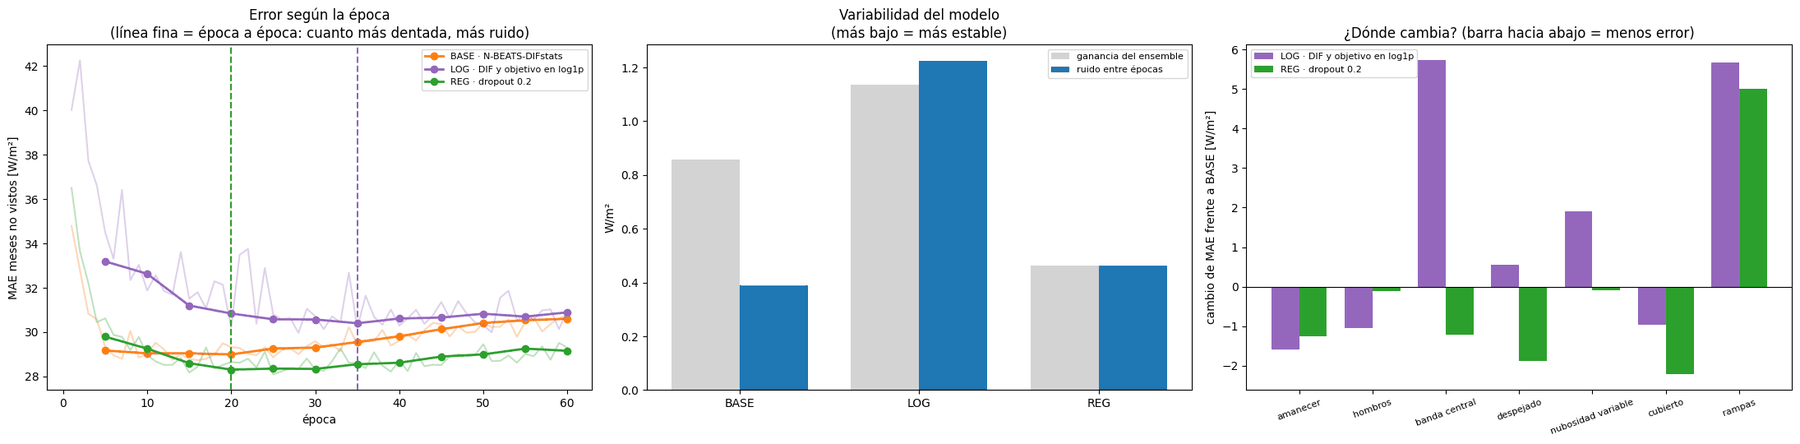


➜ NINGUNA PASA: ni la escala logarítmica ni el dropout mejoran a la N-BEATS lo suficiente. La N-BEATS-DIFstats de P1 (época 15) se mantiene.
Resultados en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/nbeats/N2_log_y_regularizacion


In [ ]:
import os, time, random, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
try:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
except ImportError:
    pass

BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
DIAG = BASE_DIR / "resultados" / "diagnostico"
RUTA_NPZ = (
    BASE_DIR
    / "resultados"
    / "ejecuciones"
    / "preparacion_bloque_difstats_20261006_180841"
    / "matrices_dif_elev_difstats.npz"
)
RUTA_TABLA = DIAG / "faseB_radiografia_E1" / "tabla_horaria_E1.pkl"
DIR_P1 = DIAG / "nbeats" / "P1_sobreaprendizaje_y_robustez"
SALIDA = DIAG / "nbeats" / "N2_log_y_regularizacion"
DIR_P = SALIDA / "predicciones"
DIR_P.mkdir(parents=True, exist_ok=True)
SEMILLAS = [42, 123]
MESES_CRIBA = ["2024-01", "2024-03", "2024-05", "2024-07"]
EPOCAS_MAX, CADA = 60, 5
BATCH, LR, WD = 128, 1e-3, 1e-5
HIDDEN, N_BLOQUES = 128, 6
DROPOUT = 0.2
EFECTO_MINIMO = 0.5
ALFA = 0.05 / 2  # Bonferroni: 2 variantes frente a BASE
N_BOOT = 2000
UMBRAL_RAMPA = 97.78
CONFIGS = {
    "BASE": dict(log=False, dropout=0.0, nombre="BASE · N-BEATS-DIFstats"),
    "LOG": dict(log=True, dropout=0.0, nombre="LOG · DIF y objetivo en log1p"),
    "REG": dict(log=False, dropout=DROPOUT, nombre=f"REG · dropout {DROPOUT}"),
}

# 1) Datos
mat = np.load(RUTA_NPZ)
X_tr = mat["X_train_DIF_elev_DIFstats_raw"].astype(np.float32)
y_tr = mat["y_train_difstats"].astype(np.float32).reshape(-1)
fechas = pd.DatetimeIndex(mat["fechas_train"])
T = pd.read_pickle(RUTA_TABLA)
TR = T[T["conjunto"] == "train"]
assert len(TR) == len(y_tr) and (TR.index == fechas).all(), "La tabla horaria no cuadra con el .npz"
SOL = (TR["regimen"] != "noche").to_numpy()
mes = fechas.to_period("M").astype(str).to_numpy()
mes = np.where(mes == "2023-12", "2024-01", mes)

def pliegue(m):
    fuera = mes == m
    fin = fechas[fuera].max()
    purga = (fechas > fin) & (fechas <= fin + pd.Timedelta("24h"))
    return ~fuera & ~purga, fuera

a_log = lambda v: np.log1p(np.maximum(v, 0.0)).astype(np.float32)
print(
    f"Horas de train con DIF < 0 (se llevan a 0 antes del log): {100 * (y_tr < 0).mean():.1f} % (casi todas de noche)"
)

# 2) N-BEATS (la de P1, con dropout opcional)
import torch, torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler

class NBEATSBlockDIFStats(nn.Module):
    def __init__(self, input_size=96, hidden_size=128, backcast_size=24, dropout=0.0):
        super().__init__()
        capas = []
        for i in range(3):
            capas += [nn.Linear(input_size if i == 0 else hidden_size, hidden_size), nn.ReLU()]
            if dropout > 0:
                capas.append(nn.Dropout(dropout))
        self.fc = nn.Sequential(*capas)
        self.backcast = nn.Linear(hidden_size, backcast_size)
        self.forecast = nn.Linear(hidden_size, 1)

    def forward(self, x):
        h = self.fc(x)
        return self.backcast(h), self.forecast(h)

class NBEATSDIFStats(nn.Module):
    def __init__(self, lookback=24, n_features=4, hidden_size=128, n_bloques=6, dropout=0.0):
        super().__init__()
        self.blocks = nn.ModuleList(
            [
                NBEATSBlockDIFStats(lookback * n_features, hidden_size, lookback, dropout)
                for _ in range(n_bloques)
            ]
        )

    def forward(self, x):
        residual_dif = x[:, :, 0]
        covariables = x[:, :, 1:].permute(0, 2, 1).contiguous().reshape(x.size(0), -1)
        forecast_total = torch.zeros((x.size(0), 1), dtype=x.dtype, device=x.device)
        for bloque in self.blocks:
            backcast, forecast = bloque(torch.cat([residual_dif, covariables], dim=1))
            residual_dif = residual_dif - backcast
            forecast_total = forecast_total + forecast
        return forecast_total.squeeze(-1)


# Comprobación: sin dropout, la arquitectura es idéntica a la de P1 (mismo número de parámetros y mismo orden de capas)
assert sum(
    p.numel() for p in NBEATSDIFStats(hidden_size=HIDDEN, n_bloques=N_BLOQUES).parameters()
) == sum(
    p.numel()
    for p in NBEATSDIFStats(hidden_size=HIDDEN, n_bloques=N_BLOQUES, dropout=DROPOUT).parameters()
)

def entrenar(cfg, entrena, fuera, semilla):
    """Predicciones (en W/m²) del mes no visto en cada época (filas = épocas 1…60)."""
    X = X_tr.copy()
    y = y_tr.copy()
    if cfg["log"]:
        X[:, :, 0] = a_log(X[:, :, 0])
        y = a_log(y)
    sx = StandardScaler().fit(X[entrena].reshape(-1, X.shape[2]))
    sy = StandardScaler().fit(y[entrena].reshape(-1, 1))
    e = lambda Z: torch.from_numpy(
        sx.transform(Z.reshape(-1, Z.shape[2])).reshape(Z.shape).astype(np.float32)
    )
    Xtr_t, Xho_t = e(X[entrena]), e(X[fuera])
    ytr_e = sy.transform(y[entrena].reshape(-1, 1)).ravel().astype(np.float32)
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    torch.use_deterministic_algorithms(True)
    modelo = NBEATSDIFStats(
        n_features=X.shape[2], hidden_size=HIDDEN, n_bloques=N_BLOQUES, dropout=cfg["dropout"]
    )
    gen = torch.Generator()
    gen.manual_seed(semilla)
    loader = DataLoader(
        TensorDataset(Xtr_t, torch.from_numpy(ytr_e)),
        batch_size=BATCH,
        shuffle=True,
        generator=gen,
        num_workers=0,
    )
    opt = torch.optim.Adam(modelo.parameters(), lr=LR, weight_decay=WD)
    crit = nn.L1Loss()
    preds = []
    for ep in range(1, EPOCAS_MAX + 1):
        modelo.train()
        for xb, yb in loader:
            opt.zero_grad(set_to_none=True)
            loss = crit(modelo(xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), max_norm=1.0)
            opt.step()
        modelo.eval()
        with torch.no_grad():
            p = sy.inverse_transform(modelo(Xho_t).numpy().reshape(-1, 1)).ravel()
        preds.append(np.expm1(p) if cfg["log"] else p)
    return np.array(preds, dtype=np.float32)

def ruta_pred(c, m, s):
    if c == "BASE":
        return DIR_P1 / f"DIFstats_fold_{m}_s{s}.npz"
    return DIR_P / f"{c}_fold_{m}_s{s}.npz"

for m in MESES_CRIBA:
    for s in SEMILLAS:
        assert ruta_pred("BASE", m, s).exists(), f"Falta el pliegue de P1 {m} s{s}"

t_ini = time.time()
tareas = [(c, s, m) for c in ["LOG", "REG"] for s in SEMILLAS for m in MESES_CRIBA]
for k, (c, s, m) in enumerate(tareas, 1):
    ruta = ruta_pred(c, m, s)
    if ruta.exists():
        print(f"[{k}/{len(tareas)}] {c} · {m} · semilla {s}: ya hecho")
        continue
    t0 = time.time()
    entrena, fuera = pliegue(m)
    np.savez_compressed(ruta, pred=entrenar(CONFIGS[c], entrena, fuera, s))
    print(
        f"[{k}/{len(tareas)}] {c} · {m} · semilla {s}: {time.time()-t0:.0f} s (total {(time.time()-t_ini)/60:.1f} min)"
    )

# 3) Evaluación en los 4 meses no vistos (horas con sol)
EP5 = np.arange(CADA, EPOCAS_MAX + 1, CADA)
idx = np.where(np.isin(mes, MESES_CRIBA))[0]
sol = SOL[idx]
y = y_tr[idx]
inf = TR.iloc[idx].copy()
inf["cielo"] = inf["cielo"].astype(str).replace({"nubes rotas": "nubosidad variable"})
hora = inf.index.hour.to_numpy()
regimen = inf["regimen"].astype(str).to_numpy()
banda = inf["banda"].astype(str)
central = banda.str.startswith("central").to_numpy()
hombros = banda.str.startswith("hombros").to_numpy()
amanecer = (regimen == "transicion") & (hora < 12)
rampa = np.abs(y - X_tr[idx, -1, 0]) >= UMBRAL_RAMPA
res = {}
for c in CONFIGS:
    PS = np.zeros((len(SEMILLAS), EPOCAS_MAX, len(idx)), dtype=np.float64)
    for i, s in enumerate(SEMILLAS):
        for m in MESES_CRIBA:
            PS[i][:, mes[idx] == m] = np.load(ruta_pred(c, m, s))["pred"][:EPOCAS_MAX]
    P = PS.mean(axis=0)
    mae_ep = np.abs(P[:, sol] - y[sol]).mean(axis=1)
    suave = pd.Series(mae_ep[EP5 - 1], index=EP5).rolling(3, center=True, min_periods=1).mean()
    ep = int(suave.idxmin())
    mae_sem = np.abs(PS[:, ep - 1][:, sol] - y[sol]).mean(axis=1)
    res[c] = dict(
        ep=ep,
        mae_ep=mae_ep,
        suave=suave,
        pred=P[ep - 1],
        err=np.abs(P[ep - 1] - y),
        ganancia_ens=mae_sem.mean() - mae_ep[ep - 1],
        ruido_ep=np.std(np.diff(mae_ep[9:])),
    )

dias = inf.index.normalize().to_numpy()
u, inv = np.unique(dias, return_inverse=True)
grupos_dia = [np.where(inv == i)[0] for i in range(len(u))]
rng = np.random.default_rng(0)
remuestras = [
    np.concatenate([grupos_dia[i] for i in rng.integers(0, len(grupos_dia), len(grupos_dia))])
    for _ in range(N_BOOT)
]

def ic(x, msk, alfa):
    v = np.where(msk, x, np.nan)
    medias = [np.nanmean(v[r]) for r in remuestras]
    return (
        np.nanmean(v),
        np.nanpercentile(medias, 100 * alfa / 2),
        np.nanpercentile(medias, 100 * (1 - alfa / 2)),
    )

e0 = res["BASE"]["err"]
filas, desglose = [], []
for c, cfg in CONFIGS.items():
    fila = {
        "configuración": cfg["nombre"],
        "mejor época": res[c]["ep"],
        "MAE operación": res[c]["err"][sol].mean(),
        "sesgo": np.mean((res[c]["pred"] - y)[sol]),
        "ganancia del ensemble": res[c]["ganancia_ens"],
        "ruido entre épocas": res[c]["ruido_ep"],
    }
    if c != "BASE":
        d = res[c]["err"] - e0
        c_, lo, hi = ic(d, sol, ALFA)
        cc, lc, hc = ic(d, sol & central, ALFA)
        ok1, ok2 = (hi < 0 and -c_ >= EFECTO_MINIMO), lc <= 0
        fila.update(
            {
                "cambio operación": c_,
                "IC97,5 operación": f"[{lo:+.2f}, {hi:+.2f}]",
                "cambio central": cc,
                "IC97,5 central": f"[{lc:+.2f}, {hc:+.2f}]",
                "1 mejora ≥0,5 e IC<0": ok1,
                "2 central sin empeorar": ok2,
                "veredicto": "PASA A VALIDACIÓN" if (ok1 and ok2) else "no pasa",
            }
        )
        grupos = [
            ("amanecer", amanecer),
            ("hombros", hombros),
            ("banda central", central),
            ("régimen: transición", regimen == "transicion"),
            (f"rampas (|ΔDIF| ≥ {UMBRAL_RAMPA:.0f})", rampa),
        ]
        grupos += [
            ("cielo: " + g, (inf["cielo"] == g).to_numpy())
            for g in ["despejado", "velado", "nubosidad variable", "cubierto"]
        ]
        for nombre, msk in grupos:
            if (sol & msk).sum() >= 30:
                cg, lg, hg = ic(d, sol & msk, 0.05)
                desglose.append(
                    {
                        "variante": c,
                        "grupo": nombre,
                        "horas": int((sol & msk).sum()),
                        "MAE BASE": e0[sol & msk].mean(),
                        "MAE variante": res[c]["err"][sol & msk].mean(),
                        "cambio": cg,
                        "IC95": f"[{lg:+.2f}, {hg:+.2f}]",
                        "lectura": "mejora" if hg < 0 else ("EMPEORA" if lg > 0 else "igual"),
                    }
                )
    else:
        fila["veredicto"] = "referencia"
    filas.append(fila)
R = pd.DataFrame(filas).set_index("configuración")
D = pd.DataFrame(desglose)
pd.set_option("display.width", 260)
pd.set_option("display.max_columns", 30)
print(
    "\n"
    + "=" * 110
    + "\nN2 · ESCALA LOGARÍTMICA Y REGULARIZACIÓN (train, 4 meses no vistos, 2 semillas, horas con sol)\n"
    + "=" * 110
)
print("Cambio negativo = menos error que BASE. IC al 97,5 % por Bonferroni (2 variantes).")
display(R.round(2))
print("\nDesglose (IC95 sin ajustar; informa, no decide):")
for c in ["LOG", "REG"]:
    print(f"\n{CONFIGS[c]['nombre']}")
    display(D[D["variante"] == c].drop(columns="variante").set_index("grupo").round(2))

# 4) Gráficas
colores = {"BASE": "tab:orange", "LOG": "tab:purple", "REG": "tab:green"}
fig, axs = plt.subplots(1, 3, figsize=(22, 5.5))
for c in CONFIGS:
    axs[0].plot(np.arange(1, EPOCAS_MAX + 1), res[c]["mae_ep"], color=colores[c], alpha=0.3)
    axs[0].plot(
        EP5, res[c]["suave"].values, "o-", color=colores[c], lw=2, label=CONFIGS[c]["nombre"]
    )
    axs[0].axvline(res[c]["ep"], color=colores[c], ls="--")
axs[0].set_xlabel("época")
axs[0].set_ylabel("MAE meses no vistos [W/m²]")
axs[0].legend(fontsize=8)
axs[0].set_title(
    "Error según la época\n(línea fina = época a época: cuanto más dentada, más ruido)"
)
x = np.arange(len(CONFIGS))
w = 0.38
axs[1].bar(
    x - w / 2,
    [res[c]["ganancia_ens"] for c in CONFIGS],
    w,
    color="lightgray",
    label="ganancia del ensemble",
)
axs[1].bar(
    x + w / 2,
    [res[c]["ruido_ep"] for c in CONFIGS],
    w,
    color="tab:blue",
    label="ruido entre épocas",
)
axs[1].set_xticks(x)
axs[1].set_xticklabels(list(CONFIGS))
axs[1].legend(fontsize=8)
axs[1].set_ylabel("W/m²")
axs[1].set_title("Variabilidad del modelo\n(más bajo = más estable)")
gs = [
    "amanecer",
    "hombros",
    "banda central",
    "cielo: despejado",
    "cielo: nubosidad variable",
    "cielo: cubierto",
    f"rampas (|ΔDIF| ≥ {UMBRAL_RAMPA:.0f})",
]
for j, c in enumerate(["LOG", "REG"]):
    sub = D[D["variante"] == c].set_index("grupo").reindex(gs)
    axs[2].bar(
        np.arange(len(gs)) + (j - 0.5) * w,
        sub["cambio"],
        w,
        color=colores[c],
        label=CONFIGS[c]["nombre"],
    )
axs[2].axhline(0, color="k", lw=0.8)
axs[2].set_xticks(range(len(gs)))
axs[2].set_xticklabels(
    [g.replace("cielo: ", "").replace(f" (|ΔDIF| ≥ {UMBRAL_RAMPA:.0f})", "") for g in gs],
    fontsize=8,
    rotation=20,
)
axs[2].set_ylabel("cambio de MAE frente a BASE [W/m²]")
axs[2].legend(fontsize=8)
axs[2].set_title("¿Dónde cambia? (barra hacia abajo = menos error)")
plt.tight_layout()
plt.savefig(SALIDA / "N2_log_y_regularizacion.png", dpi=120)
plt.show()

# 5) Veredicto y guardado
pasan = R[R["veredicto"] == "PASA A VALIDACIÓN"]
if len(pasan):
    g = pasan.sort_values("cambio operación").iloc[0]
    ver = (
        f"PASA A VALIDACIÓN: {g.name} ({g['cambio operación']:+.2f} W/m², IC97,5 {g['IC97,5 operación']}, "
        f"mejor época {int(g['mejor época'])}). Siguiente: confirmación con 5 semillas en validación."
    )
else:
    ver = (
        "NINGUNA PASA: ni la escala logarítmica ni el dropout mejoran a la N-BEATS lo suficiente. "
        "La N-BEATS-DIFstats de P1 (época 15) se mantiene."
    )
print("\n➜ " + ver)
R.to_csv(SALIDA / "N2_resumen.csv")
D.to_csv(SALIDA / "N2_desglose.csv", index=False)
pd.DataFrame(
    {c: res[c]["mae_ep"] for c in CONFIGS},
    index=pd.Index(np.arange(1, EPOCAS_MAX + 1), name="época"),
).to_csv(SALIDA / "N2_curvas.csv")
(SALIDA / "N2_veredicto.txt").write_text(ver + "\n", encoding="utf-8")
print("Resultados en:", SALIDA)

**Resultados.** Ninguna variante pasa, y N-BEATS-DIFstats (29,32 W/m² en la criba) se mantiene:

- Escala logarítmica: +0,87 W/m² (IC97,5 [−0,44; +2,19]) en horas con sol y +5,73 W/m² (IC97,5 [+1,24; +10,00]) en la banda central; mejora el amanecer y los hombros, y el ruido entre épocas pasa de 0,39 a 1,22.
- Dropout de 0,2: −0,67 W/m² (IC97,5 [−1,46; +0,10]), sin cambio distinguible en la banda central (−1,22 W/m², IC97,5 [−3,39; +0,65]); la ganancia del ensemble baja de 0,86 a 0,46, pero el ruido entre épocas pasa de 0,39 a 0,46.

### 4.4 Réplica del dropout en otros tres meses

Como el dropout de 0,2 quedó cerca del umbral, se repite la misma comparación con N-BEATS-DIFstats en febrero, abril y junio, tres meses de entrenamiento que no se habían usado para decidir nada, con las semillas 42 y 123 y la época fijada en la 20, la que eligieron las dos configuraciones en N2. Al ser una sola comparación preespecificada, el criterio fijado antes exige una mejora en horas con sol ≥ 0,5 W/m² con el IC95 entero por debajo de 0 y que la banda central no empeore de forma significativa.

Horas de train con DIF < 0 (se llevan a 0 antes del log): 39.5 % (casi todas de noche)
[1/6] REG · 2024-02 · semilla 42: 58 s (total 1.0 min)
[2/6] REG · 2024-04 · semilla 42: 48 s (total 1.8 min)
[3/6] REG · 2024-06 · semilla 42: 51 s (total 2.6 min)
[4/6] REG · 2024-02 · semilla 123: 48 s (total 3.4 min)
[5/6] REG · 2024-04 · semilla 123: 57 s (total 4.4 min)
[6/6] REG · 2024-06 · semilla 123: 49 s (total 5.2 min)

N2b · RÉPLICA DE REG (train, feb–abr–jun no vistos, 2 semillas, época 20 fijada, horas con sol)
Cambio negativo = menos error que BASE. IC95 bootstrap por días (una sola comparación).


,época (fijada),MAE operación,sesgo,ganancia del ensemble,ruido entre épocas,veredicto,cambio operación,IC95 operación,cambio central,IC95 central,"1 mejora ≥0,5 e IC<0",2 central sin empeorar
configuración,,,,,,,,,,,,
BASE · N-BEATS-DIFstats,20,30.68,-3.41,0.98,0.45,referencia,NaN,NaN,NaN,NaN,NaN,NaN
REG · dropout 0.2,20,30.09,-1.77,0.65,0.48,no pasa,-0.59,"[-1.41, +0.18]",-4.7,"[-7.21, -2.38]",False,True



Desglose (IC95 sin ajustar; informa, no decide):

REG · dropout 0.2


,horas,MAE BASE,MAE variante,cambio,IC95,lectura
grupo,,,,,,
amanecer,89,5.16,5.91,0.76,"[-0.02, +1.57]",igual
hombros,543,11.90,12.49,0.59,"[+0.00, +1.24]",EMPEORA
banda central,339,53.56,48.87,-4.70,"[-7.21, -2.38]",mejora
régimen: transición,176,4.41,4.63,0.21,"[-0.42, +0.81]",igual
rampas (|ΔDIF| ≥ 98),131,74.16,72.03,-2.12,"[-4.69, +0.32]",igual
cielo: despejado,133,24.82,26.29,1.47,"[-1.01, +4.16]",igual
cielo: velado,122,18.50,19.64,1.14,"[-0.44, +2.79]",igual
cielo: nubosidad variable,647,40.39,38.59,-1.80,"[-3.17, -0.40]",mejora
cielo: cubierto,206,33.62,33.79,0.17,"[-1.27, +1.75]",igual


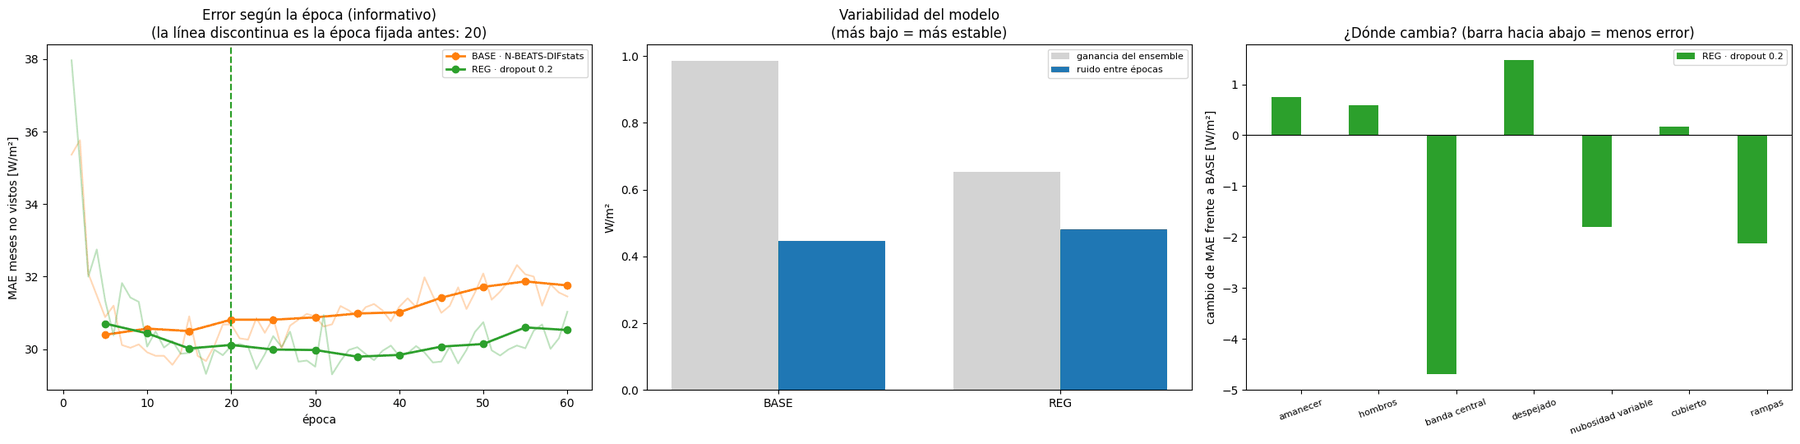


➜ NO REPLICA: en feb–abr–jun REG cambia -0.59 W/m² (IC95 [-1.41, +0.18]). REG queda cerrada; la N-BEATS final es la N-BEATS-DIFstats de P1 (época 15).
Resultados en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/nbeats/N2b_replica_REG


In [ ]:
import os, time, random, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
try:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
except ImportError:
    pass

BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
DIAG = BASE_DIR / "resultados" / "diagnostico"
RUTA_NPZ = (
    BASE_DIR
    / "resultados"
    / "ejecuciones"
    / "preparacion_bloque_difstats_20261006_180841"
    / "matrices_dif_elev_difstats.npz"
)
RUTA_TABLA = DIAG / "faseB_radiografia_E1" / "tabla_horaria_E1.pkl"
DIR_P1 = DIAG / "nbeats" / "P1_sobreaprendizaje_y_robustez"
SALIDA = DIAG / "nbeats" / "N2b_replica_REG"
DIR_P = SALIDA / "predicciones"
DIR_P.mkdir(parents=True, exist_ok=True)
SEMILLAS = [42, 123]
MESES_CRIBA = ["2024-02", "2024-04", "2024-06"]  # nunca usados para decidir
EPOCA_FIJA = 20  # fijada con N2 (BASE y REG eligieron la 20)
EPOCAS_MAX, CADA = 60, 5
BATCH, LR, WD = 128, 1e-3, 1e-5
HIDDEN, N_BLOQUES = 128, 6
DROPOUT = 0.2
EFECTO_MINIMO = 0.5
ALFA = 0.05  # una sola comparación preespecificada
N_BOOT = 2000
UMBRAL_RAMPA = 97.78
CONFIGS = {
    "BASE": dict(log=False, dropout=0.0, nombre="BASE · N-BEATS-DIFstats"),
    "REG": dict(log=False, dropout=DROPOUT, nombre=f"REG · dropout {DROPOUT}"),
}

# 1) Datos
mat = np.load(RUTA_NPZ)
X_tr = mat["X_train_DIF_elev_DIFstats_raw"].astype(np.float32)
y_tr = mat["y_train_difstats"].astype(np.float32).reshape(-1)
fechas = pd.DatetimeIndex(mat["fechas_train"])
T = pd.read_pickle(RUTA_TABLA)
TR = T[T["conjunto"] == "train"]
assert len(TR) == len(y_tr) and (TR.index == fechas).all(), "La tabla horaria no cuadra con el .npz"
SOL = (TR["regimen"] != "noche").to_numpy()
mes = fechas.to_period("M").astype(str).to_numpy()
mes = np.where(mes == "2023-12", "2024-01", mes)

def pliegue(m):
    fuera = mes == m
    fin = fechas[fuera].max()
    purga = (fechas > fin) & (fechas <= fin + pd.Timedelta("24h"))
    return ~fuera & ~purga, fuera

a_log = lambda v: np.log1p(np.maximum(v, 0.0)).astype(np.float32)
print(
    f"Horas de train con DIF < 0 (se llevan a 0 antes del log): {100 * (y_tr < 0).mean():.1f} % (casi todas de noche)"
)

# 2) N-BEATS (la de P1, con dropout opcional)
import torch, torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler

class NBEATSBlockDIFStats(nn.Module):
    def __init__(self, input_size=96, hidden_size=128, backcast_size=24, dropout=0.0):
        super().__init__()
        capas = []
        for i in range(3):
            capas += [nn.Linear(input_size if i == 0 else hidden_size, hidden_size), nn.ReLU()]
            if dropout > 0:
                capas.append(nn.Dropout(dropout))
        self.fc = nn.Sequential(*capas)
        self.backcast = nn.Linear(hidden_size, backcast_size)
        self.forecast = nn.Linear(hidden_size, 1)

    def forward(self, x):
        h = self.fc(x)
        return self.backcast(h), self.forecast(h)

class NBEATSDIFStats(nn.Module):
    def __init__(self, lookback=24, n_features=4, hidden_size=128, n_bloques=6, dropout=0.0):
        super().__init__()
        self.blocks = nn.ModuleList(
            [
                NBEATSBlockDIFStats(lookback * n_features, hidden_size, lookback, dropout)
                for _ in range(n_bloques)
            ]
        )

    def forward(self, x):
        residual_dif = x[:, :, 0]
        covariables = x[:, :, 1:].permute(0, 2, 1).contiguous().reshape(x.size(0), -1)
        forecast_total = torch.zeros((x.size(0), 1), dtype=x.dtype, device=x.device)
        for bloque in self.blocks:
            backcast, forecast = bloque(torch.cat([residual_dif, covariables], dim=1))
            residual_dif = residual_dif - backcast
            forecast_total = forecast_total + forecast
        return forecast_total.squeeze(-1)


# Comprobación: sin dropout, la arquitectura es idéntica a la de P1 (mismo número de parámetros y mismo orden de capas)
assert sum(
    p.numel() for p in NBEATSDIFStats(hidden_size=HIDDEN, n_bloques=N_BLOQUES).parameters()
) == sum(
    p.numel()
    for p in NBEATSDIFStats(hidden_size=HIDDEN, n_bloques=N_BLOQUES, dropout=DROPOUT).parameters()
)

def entrenar(cfg, entrena, fuera, semilla):
    """Predicciones (en W/m²) del mes no visto en cada época (filas = épocas 1…60)."""
    X = X_tr.copy()
    y = y_tr.copy()
    if cfg["log"]:
        X[:, :, 0] = a_log(X[:, :, 0])
        y = a_log(y)
    sx = StandardScaler().fit(X[entrena].reshape(-1, X.shape[2]))
    sy = StandardScaler().fit(y[entrena].reshape(-1, 1))
    e = lambda Z: torch.from_numpy(
        sx.transform(Z.reshape(-1, Z.shape[2])).reshape(Z.shape).astype(np.float32)
    )
    Xtr_t, Xho_t = e(X[entrena]), e(X[fuera])
    ytr_e = sy.transform(y[entrena].reshape(-1, 1)).ravel().astype(np.float32)
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    torch.use_deterministic_algorithms(True)
    modelo = NBEATSDIFStats(
        n_features=X.shape[2], hidden_size=HIDDEN, n_bloques=N_BLOQUES, dropout=cfg["dropout"]
    )
    gen = torch.Generator()
    gen.manual_seed(semilla)
    loader = DataLoader(
        TensorDataset(Xtr_t, torch.from_numpy(ytr_e)),
        batch_size=BATCH,
        shuffle=True,
        generator=gen,
        num_workers=0,
    )
    opt = torch.optim.Adam(modelo.parameters(), lr=LR, weight_decay=WD)
    crit = nn.L1Loss()
    preds = []
    for ep in range(1, EPOCAS_MAX + 1):
        modelo.train()
        for xb, yb in loader:
            opt.zero_grad(set_to_none=True)
            loss = crit(modelo(xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), max_norm=1.0)
            opt.step()
        modelo.eval()
        with torch.no_grad():
            p = sy.inverse_transform(modelo(Xho_t).numpy().reshape(-1, 1)).ravel()
        preds.append(np.expm1(p) if cfg["log"] else p)
    return np.array(preds, dtype=np.float32)

def ruta_pred(c, m, s):
    if c == "BASE":
        return DIR_P1 / f"DIFstats_fold_{m}_s{s}.npz"
    return DIR_P / f"{c}_fold_{m}_s{s}.npz"

for m in MESES_CRIBA:
    for s in SEMILLAS:
        assert ruta_pred("BASE", m, s).exists(), f"Falta el pliegue de P1 {m} s{s}"

t_ini = time.time()
tareas = [("REG", s, m) for s in SEMILLAS for m in MESES_CRIBA]
for k, (c, s, m) in enumerate(tareas, 1):
    ruta = ruta_pred(c, m, s)
    if ruta.exists():
        print(f"[{k}/{len(tareas)}] {c} · {m} · semilla {s}: ya hecho")
        continue
    t0 = time.time()
    entrena, fuera = pliegue(m)
    np.savez_compressed(ruta, pred=entrenar(CONFIGS[c], entrena, fuera, s))
    print(
        f"[{k}/{len(tareas)}] {c} · {m} · semilla {s}: {time.time()-t0:.0f} s (total {(time.time()-t_ini)/60:.1f} min)"
    )

# 3) Evaluación en los 4 meses no vistos (horas con sol)
EP5 = np.arange(CADA, EPOCAS_MAX + 1, CADA)
idx = np.where(np.isin(mes, MESES_CRIBA))[0]
sol = SOL[idx]
y = y_tr[idx]
inf = TR.iloc[idx].copy()
inf["cielo"] = inf["cielo"].astype(str).replace({"nubes rotas": "nubosidad variable"})
hora = inf.index.hour.to_numpy()
regimen = inf["regimen"].astype(str).to_numpy()
banda = inf["banda"].astype(str)
central = banda.str.startswith("central").to_numpy()
hombros = banda.str.startswith("hombros").to_numpy()
amanecer = (regimen == "transicion") & (hora < 12)
rampa = np.abs(y - X_tr[idx, -1, 0]) >= UMBRAL_RAMPA
res = {}
for c in CONFIGS:
    PS = np.zeros((len(SEMILLAS), EPOCAS_MAX, len(idx)), dtype=np.float64)
    for i, s in enumerate(SEMILLAS):
        for m in MESES_CRIBA:
            PS[i][:, mes[idx] == m] = np.load(ruta_pred(c, m, s))["pred"][:EPOCAS_MAX]
    P = PS.mean(axis=0)
    mae_ep = np.abs(P[:, sol] - y[sol]).mean(axis=1)
    suave = pd.Series(mae_ep[EP5 - 1], index=EP5).rolling(3, center=True, min_periods=1).mean()
    ep = EPOCA_FIJA  # réplica: época fijada antes, no se elige aquí
    mae_sem = np.abs(PS[:, ep - 1][:, sol] - y[sol]).mean(axis=1)
    res[c] = dict(
        ep=ep,
        mae_ep=mae_ep,
        suave=suave,
        pred=P[ep - 1],
        err=np.abs(P[ep - 1] - y),
        ganancia_ens=mae_sem.mean() - mae_ep[ep - 1],
        ruido_ep=np.std(np.diff(mae_ep[9:])),
    )

dias = inf.index.normalize().to_numpy()
u, inv = np.unique(dias, return_inverse=True)
grupos_dia = [np.where(inv == i)[0] for i in range(len(u))]
rng = np.random.default_rng(0)
remuestras = [
    np.concatenate([grupos_dia[i] for i in rng.integers(0, len(grupos_dia), len(grupos_dia))])
    for _ in range(N_BOOT)
]

def ic(x, msk, alfa):
    v = np.where(msk, x, np.nan)
    medias = [np.nanmean(v[r]) for r in remuestras]
    return (
        np.nanmean(v),
        np.nanpercentile(medias, 100 * alfa / 2),
        np.nanpercentile(medias, 100 * (1 - alfa / 2)),
    )

e0 = res["BASE"]["err"]
filas, desglose = [], []
for c, cfg in CONFIGS.items():
    fila = {
        "configuración": cfg["nombre"],
        "época (fijada)": res[c]["ep"],
        "MAE operación": res[c]["err"][sol].mean(),
        "sesgo": np.mean((res[c]["pred"] - y)[sol]),
        "ganancia del ensemble": res[c]["ganancia_ens"],
        "ruido entre épocas": res[c]["ruido_ep"],
    }
    if c != "BASE":
        d = res[c]["err"] - e0
        c_, lo, hi = ic(d, sol, ALFA)
        cc, lc, hc = ic(d, sol & central, ALFA)
        ok1, ok2 = (hi < 0 and -c_ >= EFECTO_MINIMO), lc <= 0
        fila.update(
            {
                "cambio operación": c_,
                "IC95 operación": f"[{lo:+.2f}, {hi:+.2f}]",
                "cambio central": cc,
                "IC95 central": f"[{lc:+.2f}, {hc:+.2f}]",
                "1 mejora ≥0,5 e IC<0": ok1,
                "2 central sin empeorar": ok2,
                "veredicto": "PASA A VALIDACIÓN" if (ok1 and ok2) else "no pasa",
            }
        )
        grupos = [
            ("amanecer", amanecer),
            ("hombros", hombros),
            ("banda central", central),
            ("régimen: transición", regimen == "transicion"),
            (f"rampas (|ΔDIF| ≥ {UMBRAL_RAMPA:.0f})", rampa),
        ]
        grupos += [
            ("cielo: " + g, (inf["cielo"] == g).to_numpy())
            for g in ["despejado", "velado", "nubosidad variable", "cubierto"]
        ]
        for nombre, msk in grupos:
            if (sol & msk).sum() >= 30:
                cg, lg, hg = ic(d, sol & msk, 0.05)
                desglose.append(
                    {
                        "variante": c,
                        "grupo": nombre,
                        "horas": int((sol & msk).sum()),
                        "MAE BASE": e0[sol & msk].mean(),
                        "MAE variante": res[c]["err"][sol & msk].mean(),
                        "cambio": cg,
                        "IC95": f"[{lg:+.2f}, {hg:+.2f}]",
                        "lectura": "mejora" if hg < 0 else ("EMPEORA" if lg > 0 else "igual"),
                    }
                )
    else:
        fila["veredicto"] = "referencia"
    filas.append(fila)
R = pd.DataFrame(filas).set_index("configuración")
D = pd.DataFrame(desglose)
pd.set_option("display.width", 260)
pd.set_option("display.max_columns", 30)
print(
    "\n"
    + "=" * 110
    + "\nN2b · RÉPLICA DE REG (train, feb–abr–jun no vistos, 2 semillas, época 20 fijada, horas con sol)\n"
    + "=" * 110
)
print("Cambio negativo = menos error que BASE. IC95 bootstrap por días (una sola comparación).")
display(R.round(2))
print("\nDesglose (IC95 sin ajustar; informa, no decide):")
for c in ["REG"]:
    print(f"\n{CONFIGS[c]['nombre']}")
    display(D[D["variante"] == c].drop(columns="variante").set_index("grupo").round(2))

# 4) Gráficas
colores = {"BASE": "tab:orange", "REG": "tab:green"}
fig, axs = plt.subplots(1, 3, figsize=(22, 5.5))
for c in CONFIGS:
    axs[0].plot(np.arange(1, EPOCAS_MAX + 1), res[c]["mae_ep"], color=colores[c], alpha=0.3)
    axs[0].plot(
        EP5, res[c]["suave"].values, "o-", color=colores[c], lw=2, label=CONFIGS[c]["nombre"]
    )
    axs[0].axvline(res[c]["ep"], color=colores[c], ls="--")
axs[0].set_xlabel("época")
axs[0].set_ylabel("MAE meses no vistos [W/m²]")
axs[0].legend(fontsize=8)
axs[0].set_title(
    "Error según la época (informativo)\n(la línea discontinua es la época fijada antes: 20)"
)
x = np.arange(len(CONFIGS))
w = 0.38
axs[1].bar(
    x - w / 2,
    [res[c]["ganancia_ens"] for c in CONFIGS],
    w,
    color="lightgray",
    label="ganancia del ensemble",
)
axs[1].bar(
    x + w / 2,
    [res[c]["ruido_ep"] for c in CONFIGS],
    w,
    color="tab:blue",
    label="ruido entre épocas",
)
axs[1].set_xticks(x)
axs[1].set_xticklabels(list(CONFIGS))
axs[1].legend(fontsize=8)
axs[1].set_ylabel("W/m²")
axs[1].set_title("Variabilidad del modelo\n(más bajo = más estable)")
gs = [
    "amanecer",
    "hombros",
    "banda central",
    "cielo: despejado",
    "cielo: nubosidad variable",
    "cielo: cubierto",
    f"rampas (|ΔDIF| ≥ {UMBRAL_RAMPA:.0f})",
]
for j, c in enumerate(["REG"]):
    sub = D[D["variante"] == c].set_index("grupo").reindex(gs)
    axs[2].bar(
        np.arange(len(gs)) + (j - 0.5) * w,
        sub["cambio"],
        w,
        color=colores[c],
        label=CONFIGS[c]["nombre"],
    )
axs[2].axhline(0, color="k", lw=0.8)
axs[2].set_xticks(range(len(gs)))
axs[2].set_xticklabels(
    [g.replace("cielo: ", "").replace(f" (|ΔDIF| ≥ {UMBRAL_RAMPA:.0f})", "") for g in gs],
    fontsize=8,
    rotation=20,
)
axs[2].set_ylabel("cambio de MAE frente a BASE [W/m²]")
axs[2].legend(fontsize=8)
axs[2].set_title("¿Dónde cambia? (barra hacia abajo = menos error)")
plt.tight_layout()
plt.savefig(SALIDA / "N2b_replica_REG.png", dpi=120)
plt.show()

# 5) Veredicto y guardado
g = R.loc[CONFIGS["REG"]["nombre"]]
if g["veredicto"] == "PASA A VALIDACIÓN":
    ver = (
        f"REPLICA: REG mejora {g['cambio operación']:+.2f} W/m² (IC95 {g['IC95 operación']}) en feb–abr–jun sin empeorar "
        f"la banda central. Siguiente: validación con 5 semillas, todo train, época fijada antes."
    )
else:
    ver = (
        f"NO REPLICA: en feb–abr–jun REG cambia {g['cambio operación']:+.2f} W/m² (IC95 {g['IC95 operación']}). "
        f"REG queda cerrada; la N-BEATS final es la N-BEATS-DIFstats de P1 (época 15)."
    )
print("\n➜ " + ver)
R.to_csv(SALIDA / "N2b_resumen.csv")
D.to_csv(SALIDA / "N2b_desglose.csv", index=False)
pd.DataFrame(
    {c: res[c]["mae_ep"] for c in CONFIGS},
    index=pd.Index(np.arange(1, EPOCAS_MAX + 1), name="época"),
).to_csv(SALIDA / "N2b_curvas.csv")
(SALIDA / "N2b_veredicto.txt").write_text(ver + "\n", encoding="utf-8")
print("Resultados en:", SALIDA)

**Resultados.** Con el dropout, el MAE en horas con sol pasa de 30,68 a 30,09 W/m²: −0,59 W/m² (IC95 [−1,41; +0,18]). Como el intervalo cruza el 0, la réplica no confirma la mejora y N-BEATS-DIFstats (época 15) sigue siendo la N-BEATS final. La banda central mejora 4,70 W/m² (IC95 [−7,21; −2,38]) y la ganancia del ensemble baja de 0,98 a 0,65. El desglose no coincide con el de N2: el amanecer no mejora (+0,76 W/m², IC95 [−0,02; +1,57]) y las rampas no empeoran (−2,12 W/m², IC95 [−4,69; +0,32]).

## 5. Radiografía comparada con la LSTM

> *Se utiliza en la memoria: apartado 5.4.3 y Tabla C1 (N3), y fase 33 de la Tabla A1.*

### 5.1 Radiografía del error frente a E1-30

Sin entrenar ninguna red, se repiten con N-BEATS-DIFstats (época 15) los análisis de error hechos con E1-30, con el mismo código y sobre las mismas horas con sol, fuera de muestra en entrenamiento (siete meses; cinco semillas en la N-BEATS y dos en la LSTM) y en validación (cinco semillas en ambas). Incluyen el perfil y el retraso del error, la coincidencia y los tipos de los fallos grandes (> 50 W/m²), el cielo previo, un corrector HGB con la última hora en bloques de 5 minutos y la réplica de la prueba del último minuto. Según las reglas fijadas antes, las dos redes fallan en lo mismo si en validación la correlación de Spearman entre sus errores absolutos es ≥ 0,6 y al menos 2/3 de los fallos grandes de la N-BEATS lo son también de la LSTM, y hay información desaprovechada si el corrector mejora en ≥ 0,5 W/m² a la simple corrección del sesgo, con IC95 < 0, fuera de muestra y en validación.

Mounted at /content/drive
MAE (N-BEATS, LSTM): {'train': (np.float64(29.19), np.float64(26.5)), 'validation': (np.float64(28.05), np.float64(23.25))} ← esperado train (29.19, 26.50) · validación (28.05, 23.25)

N3 · A · PERFIL DEL ERROR (horas con sol)
Persistencia inteligente del último minuto: train 30.81 · validación 27.58 W/m²


conjunto                         train (fuera de muestra)                  validación           
modelo                                   N-BEATS-DIFstats LSTM E1-30 N-BEATS-DIFstats LSTM E1-30
MAE                                                29.188     26.501           28.046     23.254
RMSE                                               43.989     41.559           43.482     36.275
sesgo                                               3.433     -2.565            7.860     -2.395
RMSE/MAE                                            1.507      1.568            1.550      1.560
nMAE %                                             21.278     19.319           19.779     16.399
R2                                                  0.857      0.873            0.832      0.883
S frente a PI último minuto %                       5.251     13.974           -1.686     15.689
% error en el peor 10 % de horas                   36.700     39.002           38.286     39.208
% horas error > 50                                 19.458     16.419           16.855     14.253
episodios de error grande                         368.000    322.000          102.000     88.000
% horas grandes en rachas ≥ 2 h                    60.272     58.149           52.349     52.381
corr. cambios sin desfase                           0.438      0.487            0.442      0.589
corr. cambios con 1 h de desfase                    0.862      0.780            0.888      0.755
Mincer–Zarnowitz pendiente                          0.951      0.991            0.926      0.979
Mincer–Zarnowitz ordenada                           3.410      3.747            3.255      5.325
autocorr. error orden 1                             0.079      0.006            0.015     -0.036


Desglose (N − L negativo = la N-BEATS falla menos; IC95 por días; '% de la diferencia total' = reparto de la ventaja de la LSTM):


horas  MAE N-BEATS  MAE LSTM  sesgo N-BEATS  sesgo LSTM  N − L              IC95        lectura  % de la diferencia total
conjunto                 grupo                                                                                                                                                      
train (fuera de muestra) operación                          3027        29.19     26.50           3.43       -2.57   2.69    [+1.80; +3.57]     LSTM mejor                    100.00
                         transición                          423         3.73      3.06           0.92        0.32   0.67    [+0.29; +1.06]     LSTM mejor                      3.48
                         amanecer                            213         3.81      3.46           0.65       -0.24   0.35    [-0.12; +0.83]          igual                      0.91
                         completamente diurno               2604        33.32     30.31           3.84       -3.03   3.01    [+2.01; +4.04]     LSTM mejor                     96.52
                         banda hombros                      1384        12.38     10.43          -0.88       -0.39   1.95    [+1.36; +2.58]     LSTM mejor                     33.24
                         banda intermedia                    878        35.75     33.48           4.55       -3.92   2.27    [+0.51; +4.04]     LSTM mejor                     24.52
                         banda central                       765        52.06     47.57           9.95       -4.95   4.49    [+2.21; +6.87]     LSTM mejor                     42.25
                         cielo de T: despejado               381        25.35     17.46           9.97        4.31   7.89    [+5.92; +9.98]     LSTM mejor                     36.98
                         cielo de T: velado                  322        19.41     16.73          -3.02       -3.02   2.69    [+0.89; +4.37]     LSTM mejor                     10.64
                         cielo de T: nubosidad variable     1450        37.62     37.81          -5.14      -11.63  -0.19    [-1.72; +1.38]          igual                     -3.37
                         cielo de T: cubierto                451        36.16     26.73          32.44       18.39   9.43   [+7.19; +11.84]     LSTM mejor                     52.27
                         cielo de T−1: despejado             380        23.82     18.10          -0.75       -3.31   5.72    [+3.80; +7.53]     LSTM mejor                     26.70
                         cielo de T−1: velado                318        23.32     19.60           1.36       -0.18   3.72    [+1.93; +5.35]     LSTM mejor                     14.55
                         cielo de T−1: nubosidad variable   1447        38.24     36.09           5.99       -2.19   2.15    [+0.67; +3.72]     LSTM mejor                     38.18
                         cielo de T−1: cubierto              451        28.90     26.90           5.44       -5.10   2.00    [+0.01; +3.98]     LSTM mejor                     11.11
                         rampa de subida (≥ 97,78)           156        77.97     87.68         -76.94      -87.56  -9.70   [-15.81; -4.26]  N-BEATS mejor                    -18.61
                         rampa de bajada (≤ −97,78)          147        77.29     60.76          76.75       58.64  16.54  [+11.40; +21.98]     LSTM mejor                     29.88
                         sin rampa                          2721        23.79     21.16           4.11       -0.99   2.63    [+1.79; +3.51]     LSTM mejor                     88.14
validación               operación                           884        28.05     23.25           7.86       -2.40   4.79    [+3.52; +6.05]     LSTM mejor                    100.00
                         transición                          119         3.67      2.67           1.82       -0.44   1.00    [+0.34; +1.69]     LSTM mejor                      2.82
                         amanecer                             60         4.48


Agrupar por el resultado frente a agrupar por la predicción (2.2.5):


sesgo con DIF OBSERVADA en el quintil alto  sesgo con DIF PREVISTA en el quintil alto
modelo           conjunto                                                                                                       
N-BEATS-DIFstats train (fuera de muestra)                                      -21.23                                      13.12
                 validación                                                    -15.95                                      21.47
LSTM E1-30       train (fuera de muestra)                                      -30.40                                       1.26
                 validación                                                    -25.40                                       3.90

... (6 outputs left out)


Corrector con la última hora a 5 min (regla D2):


MAE modelo  solo sesgo  con corrector  corrector − solo sesgo            IC95 información desaprovechada (regla D2)
modelo           conjunto                                                                                                                                     
N-BEATS-DIFstats train (fuera de muestra)       29.19       29.20          25.47                   -3.72  [-4.25; -3.20]                                   NaN
                 validación                     28.05       27.82          24.34                   -3.48  [-4.60; -2.38]                                  True
LSTM E1-30       train (fuera de muestra)       26.50       26.54          26.06                   -0.48  [-0.84; -0.11]                                   NaN
                 validación                     23.25       23.22          22.70                   -0.53  [-1.21; +0.14]                                 False


N3 · E · RÉPLICA DE R5: ¿DESAPROVECHA EL ÚLTIMO MINUTO?
Control: la LSTM debería reproducir aproximadamente R5 (train −0,66 [−0,98; −0,36]; validación −0,60 [−1,02; −0,19]).


pendiente b (todo train)  MAE solo a  MAE a + b·Δ  cambio            IC95 pasa (regla E)
modelo           conjunto                                                                                                          
N-BEATS-DIFstats train (fuera de muestra)                     0.326      29.196       28.346  -0.850  [-1.28; -0.42]            NaN
                 validación                                   0.326      27.817       27.238  -0.579  [-1.23; +0.10]          False
LSTM E1-30       train (fuera de muestra)                     0.255      26.539       25.880  -0.660  [-0.98; -0.36]            NaN
                 validación                                   0.255      23.225       22.622  -0.603  [-1.02; -0.19]           True

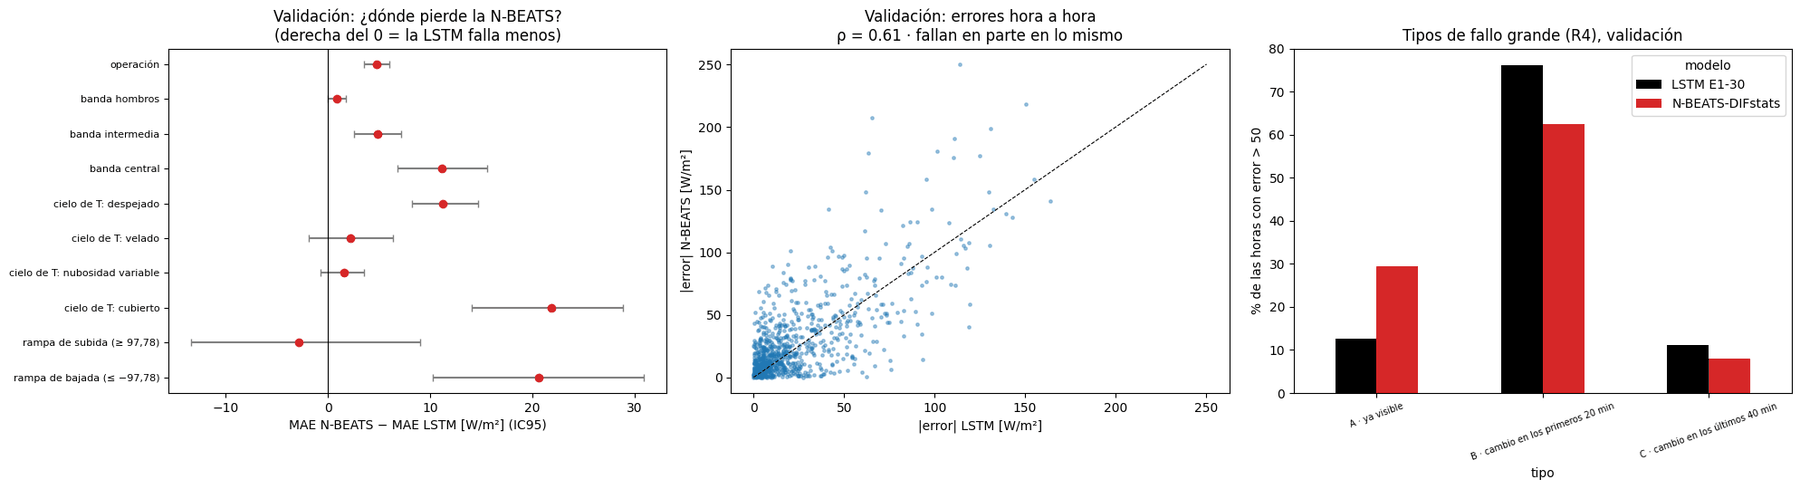


➜ B · FALLAN EN PARTE EN LO MISMO (validación: ρ = 0.61; 54 % de los fallos grandes de la N-BEATS también lo son de la LSTM).
➜ D1 · cielo previo: N-BEATS-DIFstats: HAY señal, LSTM E1-30: HAY señal.
➜ D2 · información desaprovechada (corrector con la última hora): N-BEATS-DIFstats: SÍ, LSTM E1-30: no.
➜ E · último minuto (réplica de R5): N-BEATS-DIFstats: no pasa, LSTM E1-30: PASA.
➜ N5 no se hace (la N-BEATS no desaprovecha el último minuto).
➜ La N-BEATS deja información de la última hora sin usar: N6 (entrada de una hora) tiene base.
Resultados en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/nbeats/N3_radiografia


In [ ]:
import os, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from sklearn.ensemble import HistGradientBoostingRegressor

warnings.filterwarnings("ignore")
try:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
except ImportError:
    pass

BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
DIAG = BASE_DIR / "resultados" / "diagnostico"
PARQUET = BASE_DIR / "radiation_data_completo.parquet"
RUTA_TABLA = DIAG / "faseB_radiografia_E1" / "tabla_horaria_E1.pkl"
RUTA_OOF_NB = DIAG / "nbeats" / "P1_sobreaprendizaje_y_robustez" / "oof_DIFstats_epoca_15.pkl"
RUTA_OOF_L = DIAG / "depuracion_E1_30" / "P1_oof_E1_30.pkl"
RUTA_VAL = DIAG / "nbeats" / "P2_validacion" / "P2_predicciones_validacion.pkl"
RUTA_L0 = DIAG / "L_entrada_una_hora" / "entrada_una_hora.npz"
SALIDA = DIAG / "nbeats" / "N3_radiografia"
SALIDA.mkdir(parents=True, exist_ok=True)
FIN_DATOS = pd.Timestamp("2024-10-01")
N_BOOT = 2000
GRANDE = 50.0
UMBRAL_RAMPA = 97.78
EFECTO_MINIMO = 0.5
PARAMS = dict(
    loss="absolute_error",
    max_iter=150,
    learning_rate=0.05,
    min_samples_leaf=80,
    l2_regularization=1.0,
    random_state=0,
)
MOD = {"N": "N-BEATS-DIFstats", "L": "LSTM E1-30"}
CONJ = {"train": "train (fuera de muestra)", "validation": "validación"}

# 1) Datos
T = pd.read_pickle(RUTA_TABLA).sort_index()
ONB, OL, PV = pd.read_pickle(RUTA_OOF_NB), pd.read_pickle(RUTA_OOF_L), pd.read_pickle(RUTA_VAL)
L0 = np.load(RUTA_L0)
X = {}
for c in ["train", "validation"]:
    D = T[T["conjunto"] == c].copy()
    f0 = pd.DatetimeIndex(L0[f"fechas_{c}"])
    assert (D.index == f0).all(), f"L0 no cuadra con la tabla horaria ({c})"
    if c == "train":
        assert (ONB.index == D.index).all() and (OL.index == D.index).all()
        D["N"], D["L"], D["mes"] = (
            ONB["OOF_media"].to_numpy(),
            OL["OOF30_media"].to_numpy(),
            ONB["mes_pliegue"].astype(str).to_numpy(),
        )
    else:
        assert (PV.index == D.index).all()
        D["N"], D["L"], D["mes"] = PV["NBEATS_15"].to_numpy(), PV["E1_30"].to_numpy(), "validación"
    seq, esc = L0[f"seq_{c}"], L0[f"esc_{c}"]
    D["PI1"] = esc[:, 2]  # persistencia inteligente del último minuto
    D["ult1"] = esc[:, 0]
    D["ult15"] = seq[:, -3:, 0].mean(1)  # últimos 3 bloques de 5 min = últimos 15 min
    D["dif_T1"] = T["real"].reindex(D.index - pd.Timedelta("1h")).to_numpy()
    D["cielo"] = D["cielo"].astype(str).replace({"nubes rotas": "nubosidad variable"})
    D["cielo_T1"] = (
        T["cielo"]
        .astype(str)
        .replace({"nubes rotas": "nubosidad variable"})
        .reindex(D.index - pd.Timedelta("1h"))
        .fillna("sin dato")
        .to_numpy()
    )
    D["F"] = list(np.concatenate([seq.reshape(len(seq), -1), esc], axis=1).astype(np.float32))
    sol = (D["regimen"].astype(str) != "noche").to_numpy()
    X[c] = D[sol].copy()
for c, D in X.items():
    for k in ["N", "L"]:
        D["e" + k] = D[k] - D["real"]
mae = {c: (D["eN"].abs().mean(), D["eL"].abs().mean()) for c, D in X.items()}
print(
    "MAE (N-BEATS, LSTM):",
    {c: tuple(round(v, 2) for v in m) for c, m in mae.items()},
    "← esperado train (29.19, 26.50) · validación (28.05, 23.25)",
)
assert abs(mae["validation"][0] - 28.05) < 0.05 and abs(mae["validation"][1] - 23.25) < 0.05
assert abs(mae["train"][0] - 29.19) < 0.05 and abs(mae["train"][1] - 26.50) < 0.05

# Bootstrap por días (matriz de pesos por conjunto)
WB = {}
for c, D in X.items():
    u, inv = np.unique(D.index.normalize(), return_inverse=True)
    rng = np.random.default_rng(0)
    WB[c] = np.stack(
        [np.bincount(rng.integers(0, len(u), len(u)), minlength=len(u)) for _ in range(N_BOOT)]
    )[:, inv].astype(float)

def ic(c, d, msk=None):
    d = np.asarray(d, float)
    msk = np.ones(len(d), bool) if msk is None else np.asarray(msk, bool)
    v = np.where(msk, d, 0.0)
    b = (WB[c] @ v) / np.maximum(WB[c] @ msk.astype(float), 1e-9)
    return d[msk].mean(), np.percentile(b, 2.5), np.percentile(b, 97.5)

fmt = lambda lo, hi: f"[{lo:+.2f}; {hi:+.2f}]"
lect = lambda lo, hi: "N-BEATS mejor" if hi < 0 else ("LSTM mejor" if lo > 0 else "igual")
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)


# A) Perfil del error
def rachas(D, e):
    """Episodios = rachas de horas consecutivas (mismo día) con error grande."""
    g = np.abs(e) > GRANDE
    t = D.index
    tam, actual = [], 0
    for i in range(len(g)):
        seguido = (
            i > 0
            and g[i - 1]
            and (t[i] - t[i - 1] == pd.Timedelta("1h"))
            and t[i].normalize() == t[i - 1].normalize()
        )
        if g[i]:
            actual = actual + 1 if seguido else 1
            if not seguido and i > 0:
                pass
        if g[i] and (
            i == len(g) - 1
            or not (
                g[i + 1]
                and t[i + 1] - t[i] == pd.Timedelta("1h")
                and t[i + 1].normalize() == t[i].normalize()
            )
        ):
            tam.append(actual)
            actual = 0
    tam = np.array(tam)
    return len(tam), (100 * tam[tam >= 2].sum() / tam.sum() if len(tam) else np.nan)

def retraso(D, k):
    t = D.index.to_series()
    ok = (t.diff() == pd.Timedelta("1h")).to_numpy()
    dp, dy = np.diff(D[k].to_numpy(), prepend=np.nan), np.diff(D["real"].to_numpy(), prepend=np.nan)
    ok0 = ok & np.isfinite(dp) & np.isfinite(dy)
    r0 = np.corrcoef(dp[ok0], dy[ok0])[0, 1]
    ok1 = ok0 & np.roll(ok0, 1)
    ok1[0] = False
    r1 = np.corrcoef(dp[ok1], np.roll(dy, 1)[ok1])[0, 1]
    return r0, r1

filas = []
for c, D in X.items():
    y = D["real"].to_numpy()
    pi1 = np.abs(D["PI1"] - D["real"]).mean()
    for k in ["N", "L"]:
        e = D["e" + k].to_numpy()
        ae = np.abs(e)
        mz = np.polyfit(D[k].to_numpy(), y, 1)
        n_ep, pct_r = rachas(D, e)
        r0, r1 = retraso(D, k)
        ac1 = pd.Series(e).autocorr(1)
        top = np.sort(ae)[::-1]
        top10 = 100 * top[: int(np.ceil(0.1 * len(top)))].sum() / top.sum()
        filas.append(
            {
                "conjunto": CONJ[c],
                "modelo": MOD[k],
                "MAE": ae.mean(),
                "RMSE": np.sqrt((e**2).mean()),
                "sesgo": e.mean(),
                "RMSE/MAE": np.sqrt((e**2).mean()) / ae.mean(),
                "nMAE %": 100 * ae.mean() / y.mean(),
                "R2": 1 - (e**2).sum() / ((y - y.mean()) ** 2).sum(),
                "S frente a PI último minuto %": 100 * (1 - ae.mean() / pi1),
                "% error en el peor 10 % de horas": top10,
                "% horas error > 50": 100 * (ae > GRANDE).mean(),
                "episodios de error grande": n_ep,
                "% horas grandes en rachas ≥ 2 h": pct_r,
                "corr. cambios sin desfase": r0,
                "corr. cambios con 1 h de desfase": r1,
                "Mincer–Zarnowitz pendiente": mz[0],
                "Mincer–Zarnowitz ordenada": mz[1],
                "autocorr. error orden 1": ac1,
            }
        )
PERFIL = pd.DataFrame(filas).set_index(["conjunto", "modelo"])
print("\n" + "=" * 110 + "\nN3 · A · PERFIL DEL ERROR (horas con sol)\n" + "=" * 110)
print(
    f"Persistencia inteligente del último minuto: train {np.abs(X['train']['PI1'] - X['train']['real']).mean():.2f} · "
    f"validación {np.abs(X['validation']['PI1'] - X['validation']['real']).mean():.2f} W/m²"
)
display(PERFIL.T.round(3))


# Desglose por grupos (diferencia N − L, IC95 por días)
def grupos(D):
    hora = D.index.hour.to_numpy()
    reg = D["regimen"].astype(str).to_numpy()
    dlt = (D["real"] - D["dif_T1"]).to_numpy()
    G = [
        ("operación", np.ones(len(D), bool)),
        ("transición", reg == "transicion"),
        ("amanecer", (reg == "transicion") & (hora < 12)),
        ("completamente diurno", reg == "completamente_diurno"),
    ]
    G += [
        (f"banda {b}", D["banda"].astype(str).str.startswith(b).to_numpy())
        for b in ["hombros", "intermedia", "central"]
    ]
    G += [
        (f"cielo de T: {g}", (D["cielo"] == g).to_numpy())
        for g in ["despejado", "velado", "nubosidad variable", "cubierto"]
    ]
    G += [
        (f"cielo de T−1: {g}", (D["cielo_T1"] == g).to_numpy())
        for g in ["despejado", "velado", "nubosidad variable", "cubierto"]
    ]
    G += [
        ("rampa de subida (≥ 97,78)", dlt >= UMBRAL_RAMPA),
        ("rampa de bajada (≤ −97,78)", dlt <= -UMBRAL_RAMPA),
        ("sin rampa", np.abs(dlt) < UMBRAL_RAMPA),
    ]
    return G

filas = []
for c, D in X.items():
    d = (D["eN"].abs() - D["eL"].abs()).to_numpy()
    for nombre, msk in grupos(D):
        if msk.sum() >= 20:
            m_, lo, hi = ic(c, d, msk)
            filas.append(
                {
                    "conjunto": CONJ[c],
                    "grupo": nombre,
                    "horas": int(msk.sum()),
                    "MAE N-BEATS": D["eN"].abs()[msk].mean(),
                    "MAE LSTM": D["eL"].abs()[msk].mean(),
                    "sesgo N-BEATS": D["eN"][msk].mean(),
                    "sesgo LSTM": D["eL"][msk].mean(),
                    "N − L": m_,
                    "IC95": fmt(lo, hi),
                    "lectura": lect(lo, hi),
                    "% de la diferencia total": 100 * d[msk].sum() / d.sum(),
                }
            )
DES = pd.DataFrame(filas).set_index(["conjunto", "grupo"])
print(
    "\nDesglose (N − L negativo = la N-BEATS falla menos; IC95 por días; '% de la diferencia total' = reparto de la ventaja de la LSTM):"
)
display(DES.round(2))

# Agrupar por lo observado frente a lo previsto (quintil superior, cortes de train)
filas = []
for k in ["N", "L"]:
    c_obs = np.percentile(X["train"]["real"], 80)
    c_pre = np.percentile(X["train"][k], 80)
    for c, D in X.items():
        filas.append(
            {
                "modelo": MOD[k],
                "conjunto": CONJ[c],
                "sesgo con DIF OBSERVADA en el quintil alto": D["e" + k][D["real"] >= c_obs].mean(),
                "sesgo con DIF PREVISTA en el quintil alto": D["e" + k][D[k] >= c_pre].mean(),
            }
        )
print("\nAgrupar por el resultado frente a agrupar por la predicción (2.2.5):")
display(pd.DataFrame(filas).set_index(["modelo", "conjunto"]).round(2))

# B) ¿Fallan en las mismas horas?
filas = []
for c, D in X.items():
    aN, aL = D["eN"].abs().to_numpy(), D["eL"].abs().to_numpy()
    gN, gL = aN > GRANDE, aL > GRANDE
    rho = stats.spearmanr(aN, aL).correlation
    comp = gL[gN].mean() if gN.any() else np.nan
    filas.append(
        {
            "conjunto": CONJ[c],
            "ρ Spearman |e_N|, |e_L|": rho,
            "corr. errores con signo": np.corrcoef(D["eN"], D["eL"])[0, 1],
            "grandes en ambas": int((gN & gL).sum()),
            "solo N-BEATS": int((gN & ~gL).sum()),
            "solo LSTM": int((~gN & gL).sum()),
            "ninguna": int((~gN & ~gL).sum()),
            "fracción de grandes N-BEATS que también lo son de la LSTM": comp,
        }
    )
B = pd.DataFrame(filas).set_index("conjunto")
bv = B.loc[CONJ["validation"]]
if bv.iloc[0] >= 0.6 and bv.iloc[-1] >= 2 / 3:
    ver_B = "FALLAN EN LO MISMO"
elif bv.iloc[0] < 0.4 or bv.iloc[-1] < 1 / 3:
    ver_B = "FALLAN EN COSAS DISTINTAS"
else:
    ver_B = "FALLAN EN PARTE EN LO MISMO"
print("\n" + "=" * 110 + "\nN3 · B · ¿FALLAN EN LAS MISMAS HORAS?\n" + "=" * 110)
display(B.round(3))
print(f"➜ Regla B (validación): {ver_B}")

# C) Tipos de fallo grande minuto a minuto (definiciones de R4), validación
m = pd.read_parquet(PARQUET, columns=["Date/Time", "DIF [W/m**2]"])
m["Date/Time"] = pd.to_datetime(m["Date/Time"], utc=True).dt.tz_localize(None)
m = m.set_index("Date/Time").sort_index()
m = m[~m.index.duplicated()]
VA = X["validation"]
m = m[(m.index >= VA.index.min() - pd.Timedelta("2h")) & (m.index < FIN_DATOS)]
assert m.index.max() < FIN_DATOS, "Se estarían leyendo datos del test"
dif = pd.to_numeric(m["DIF [W/m**2]"], errors="coerce").asfreq("min")

def tipo_fallo(t, pred, e):
    prev = dif[t - pd.Timedelta("1h") : t - pd.Timedelta("1min")]
    act = dif[t : t + pd.Timedelta("59min")]
    if prev.notna().sum() < 30 or act.notna().sum() < 30:
        return None
    mp, ma, u15 = prev.mean(), act.mean(), prev.iloc[-15:].mean()
    salto = ma - mp
    visible = abs(ma - u15) <= 0.5 * abs(salto) if abs(salto) > 1e-6 else False
    suave = act.rolling(5, min_periods=3).mean().to_numpy()
    mitad = (u15 + ma) / 2
    cruza = np.where((suave >= mitad) if ma > u15 else (suave <= mitad))[0]
    minuto = int(cruza[0]) if len(cruza) else np.nan
    lado = (act > pred) if e < 0 else (act < pred)
    frac = float(lado[act.notna()].mean())
    if visible:
        return "A · ya visible"
    if frac < 0.40:
        return "D · pico breve"
    if not np.isnan(minuto) and minuto < 20:
        return "B · cambio en los primeros 20 min"
    if not np.isnan(minuto):
        return "C · cambio en los últimos 40 min"
    return "E · oscila"

filas = []
for k in ["N", "L"]:
    for t, r in VA[VA["e" + k].abs() > GRANDE].iterrows():
        tp = tipo_fallo(t, r[k], r["e" + k])
        if tp:
            filas.append({"modelo": MOD[k], "tipo": tp, "error": r["e" + k]})
TC = pd.DataFrame(filas)
RC = TC.groupby(["modelo", "tipo"]).agg(
    horas=("error", "size"),
    error_medio=("error", lambda s: s.abs().mean()),
    sesgo=("error", "mean"),
)
RC["% de sus horas grandes"] = 100 * RC["horas"] / RC.groupby(level=0)["horas"].transform("sum")
print(
    "\n"
    + "=" * 110
    + "\nN3 · C · TIPOS DE FALLO GRANDE (> 50 W/m²), VALIDACIÓN, DEFINICIONES DE R4\n"
    + "=" * 110
)
display(RC.round(2))

# D) Cielo previo e información desaprovechada
filas = []
for k in ["N", "L"]:
    for g in ["despejado", "velado", "nubosidad variable", "cubierto"]:
        fila = {"modelo": MOD[k], "cielo de T−1": g}
        for c, D in X.items():
            msk = (D["cielo_T1"] == g).to_numpy()
            s_, lo, hi = ic(c, D["e" + k].to_numpy(), msk)
            fila.update(
                {
                    f"horas {c}": int(msk.sum()),
                    f"sesgo {c}": s_,
                    f"IC95 {c}": fmt(lo, hi),
                    f"_lo_{c}": lo,
                    f"_hi_{c}": hi,
                }
            )
        sen = all(
            fila[f"horas {c}"] >= 50
            and abs(fila[f"sesgo {c}"]) >= 5
            and (fila[f"_lo_{c}"] > 0 or fila[f"_hi_{c}"] < 0)
            for c in X
        )
        fila["señal (regla D1)"] = sen and np.sign(fila["sesgo train"]) == np.sign(
            fila["sesgo validation"]
        )
        filas.append(fila)
D1 = pd.DataFrame(filas).set_index(["modelo", "cielo de T−1"])
print(
    "\n"
    + "=" * 110
    + "\nN3 · D · CIELO PREVIO (regla A de R2) E INFORMACIÓN DESAPROVECHADA\n"
    + "=" * 110
)
display(D1.drop(columns=[c for c in D1.columns if c.startswith("_")]).round(2))

def matriz(D, k):
    return np.column_stack([np.stack(D["F"].to_numpy()), D[k].to_numpy()])

def corrector(k):
    """Corrección del error con la última hora a 5 min + ŷ. Train: dejando cada mes fuera. Validación: con todo train."""
    TR, VA_ = X["train"], X["validation"]
    Xtr, r_tr = matriz(TR, k), (TR["real"] - TR[k]).to_numpy()
    oof_c, oof_b = np.zeros(len(TR)), np.zeros(len(TR))
    for m_ in np.unique(TR["mes"]):
        f = (TR["mes"] == m_).to_numpy()
        mod = HistGradientBoostingRegressor(**PARAMS).fit(Xtr[~f], r_tr[~f])
        oof_c[f] = mod.predict(Xtr[f])
        oof_b[f] = np.median(r_tr[~f])
    mod = HistGradientBoostingRegressor(**PARAMS).fit(Xtr, r_tr)
    va_c, va_b = mod.predict(matriz(VA_, k)), np.median(r_tr)
    out = {}
    for c, D, cc, cb in [("train", TR, oof_c, oof_b), ("validation", VA_, va_c, va_b)]:
        y = D["real"].to_numpy()
        p = D[k].to_numpy()
        e_b = np.abs(np.clip(p + cb, 0, None) - y)
        e_c = np.abs(np.clip(p + cc, 0, None) - y)
        out[c] = (np.abs(p - y).mean(), e_b.mean(), e_c.mean(), *ic(c, e_c - e_b))
    return out

filas, pasa_D2 = [], {}
for k in ["N", "L"]:
    o = corrector(k)
    ok = all(o[c][5] < 0 for c in o) and -o["train"][3] >= EFECTO_MINIMO
    pasa_D2[k] = ok
    for c in o:
        filas.append(
            {
                "modelo": MOD[k],
                "conjunto": CONJ[c],
                "MAE modelo": o[c][0],
                "solo sesgo": o[c][1],
                "con corrector": o[c][2],
                "corrector − solo sesgo": o[c][3],
                "IC95": fmt(o[c][4], o[c][5]),
            }
        )
    filas[-1]["información desaprovechada (regla D2)"] = ok
print("\nCorrector con la última hora a 5 min (regla D2):")
display(pd.DataFrame(filas).set_index(["modelo", "conjunto"]).round(2))


# E) Réplica de R5: ¿desaprovecha el último minuto?
def lad(x, y, iters=60):
    A = np.c_[np.ones_like(x), x]
    b = np.linalg.lstsq(A, y, rcond=None)[0]
    for _ in range(iters):
        w = 1 / np.maximum(np.abs(y - A @ b), 1e-3)
        b = np.linalg.lstsq(A * np.sqrt(w)[:, None], y * np.sqrt(w), rcond=None)[0]
    return b

filas, pasa_E = [], {}
for k in ["N", "L"]:
    TR, VA_ = X["train"], X["validation"]
    dl = {c: (D["ult1"] - D["ult15"]).to_numpy() for c, D in X.items()}
    r = {c: (D["real"] - D[k]).to_numpy() for c, D in X.items()}
    cor_ab, cor_a = np.zeros(len(TR)), np.zeros(len(TR))
    for m_ in np.unique(TR["mes"]):
        f = (TR["mes"] == m_).to_numpy()
        b = lad(dl["train"][~f], r["train"][~f])
        cor_ab[f] = b[0] + b[1] * dl["train"][f]
        cor_a[f] = np.median(r["train"][~f])
    b_all = lad(dl["train"], r["train"])
    res_c = {
        "train": (cor_ab, cor_a),
        "validation": (b_all[0] + b_all[1] * dl["validation"], np.median(r["train"])),
    }
    out = {}
    for c, D in X.items():
        y = D["real"].to_numpy()
        p = D[k].to_numpy()
        e_ab = np.abs(np.clip(p + res_c[c][0], 0, None) - y)
        e_a = np.abs(np.clip(p + res_c[c][1], 0, None) - y)
        out[c] = ic(c, e_ab - e_a) + (e_a.mean(), e_ab.mean())
    ok = out["train"][2] < 0 and -out["train"][0] >= EFECTO_MINIMO and out["validation"][2] < 0
    pasa_E[k] = ok
    for c in out:
        filas.append(
            {
                "modelo": MOD[k],
                "conjunto": CONJ[c],
                "pendiente b (todo train)": b_all[1],
                "MAE solo a": out[c][3],
                "MAE a + b·Δ": out[c][4],
                "cambio": out[c][0],
                "IC95": fmt(out[c][1], out[c][2]),
            }
        )
    filas[-1]["pasa (regla E)"] = ok
print("\n" + "=" * 110 + "\nN3 · E · RÉPLICA DE R5: ¿DESAPROVECHA EL ÚLTIMO MINUTO?\n" + "=" * 110)
print(
    "Control: la LSTM debería reproducir aproximadamente R5 (train −0,66 [−0,98; −0,36]; validación −0,60 [−1,02; −0,19])."
)
display(pd.DataFrame(filas).set_index(["modelo", "conjunto"]).round(3))

# Gráficas
fig, axs = plt.subplots(1, 3, figsize=(20, 5.5))
dv = DES.loc[CONJ["validation"]]
dv = dv[
    dv.index.str.startswith("cielo de T:")
    | dv.index.str.startswith("banda")
    | dv.index.str.startswith("rampa")
    | (dv.index == "operación")
]
yy = np.arange(len(dv))
lims = dv["IC95"].str.strip("[]").str.split(";", expand=True).astype(float)
axs[0].errorbar(
    dv["N − L"],
    yy,
    xerr=[dv["N − L"] - lims[0], lims[1] - dv["N − L"]],
    fmt="o",
    color="tab:red",
    ecolor="gray",
    capsize=3,
)
axs[0].axvline(0, color="k", lw=0.8)
axs[0].set_yticks(yy)
axs[0].set_yticklabels(dv.index, fontsize=8)
axs[0].invert_yaxis()
axs[0].set_xlabel("MAE N-BEATS − MAE LSTM [W/m²] (IC95)")
axs[0].set_title("Validación: ¿dónde pierde la N-BEATS?\n(derecha del 0 = la LSTM falla menos)")
axs[1].scatter(VA["eL"].abs(), VA["eN"].abs(), s=6, alpha=0.4)
mx = max(VA["eL"].abs().max(), VA["eN"].abs().max())
axs[1].plot([0, mx], [0, mx], "k--", lw=0.8)
axs[1].set_xlabel("|error| LSTM [W/m²]")
axs[1].set_ylabel("|error| N-BEATS [W/m²]")
axs[1].set_title(f"Validación: errores hora a hora\nρ = {bv.iloc[0]:.2f} · {ver_B.lower()}")
pv = RC["% de sus horas grandes"].unstack(0).fillna(0)
pv.plot.bar(
    ax=axs[2], color=["tab:red", "black"] if pv.columns[0].startswith("N") else ["black", "tab:red"]
)
axs[2].set_ylabel("% de las horas con error > 50")
axs[2].set_title("Tipos de fallo grande (R4), validación")
axs[2].tick_params(axis="x", labelsize=7, rotation=20)
plt.tight_layout()
plt.savefig(SALIDA / "N3_radiografia.png", dpi=120)
plt.show()

# Veredicto y guardado
lin = [
    f"B · {ver_B} (validación: ρ = {bv.iloc[0]:.2f}; {100 * bv.iloc[-1]:.0f} % de los fallos grandes de la N-BEATS también lo son de la LSTM).",
    "D1 · cielo previo: "
    + ", ".join(
        f"{MOD[k]}: {'HAY señal' if D1.loc[MOD[k], 'señal (regla D1)'].any() else 'sin señal'}"
        for k in ["N", "L"]
    )
    + ".",
    "D2 · información desaprovechada (corrector con la última hora): "
    + ", ".join(f"{MOD[k]}: {'SÍ' if pasa_D2[k] else 'no'}" for k in ["N", "L"])
    + ".",
    "E · último minuto (réplica de R5): "
    + ", ".join(f"{MOD[k]}: {'PASA' if pasa_E[k] else 'no pasa'}" for k in ["N", "L"])
    + ".",
    (
        "Siguiente: N5 (canal del último minuto en la N-BEATS)."
        if pasa_E["N"]
        else "N5 no se hace (la N-BEATS no desaprovecha el último minuto)."
    ),
    (
        "La N-BEATS deja información de la última hora sin usar: N6 (entrada de una hora) tiene base."
        if pasa_D2["N"]
        else "El corrector no encuentra información sin usar en la última hora: N6 se hace igualmente por simetría con la LSTM, sin expectativa previa."
    ),
]
ver = "\n".join(lin)
print("\n➜ " + ver.replace("\n", "\n➜ "))
PERFIL.to_csv(SALIDA / "N3_A_perfil.csv")
DES.to_csv(SALIDA / "N3_A_desglose.csv")
B.to_csv(SALIDA / "N3_B_mismas_horas.csv")
RC.to_csv(SALIDA / "N3_C_tipos_fallo.csv")
D1.to_csv(SALIDA / "N3_D_cielo_previo.csv")
(SALIDA / "N3_veredicto.txt").write_text(ver + "\n", encoding="utf-8")
print("Resultados en:", SALIDA)

**Resultados.** Las dos redes fallan en parte en lo mismo: en validación, ρ = 0,61 y el 54 % de los fallos grandes de la N-BEATS lo son también de E1-30.

- La N-BEATS va con más retraso: correlación entre cambios previstos y observados de 0,44 sin desfase y 0,89 con una hora (0,59 y 0,76 en E1-30); el 30 % de sus fallos grandes ya eran visibles al final de la última hora observada (13 % en E1-30).
- El corrector reduce su error en 3,72 W/m² fuera de muestra (IC95 [−4,25; −3,20]) y en 3,48 W/m² en validación (IC95 [−4,60; −2,38]); el de E1-30, solo en 0,48 W/m² fuera de muestra, y en validación no se distingue de 0.
- La réplica del último minuto no pasa en la N-BEATS y sí en E1-30.

## 6. La entrada de una hora

> *Se utiliza en la memoria: apartados 5.4.4, 5.6 y 6.1, Tablas 7 y 8 y Tabla C1 (N6 y N6b), y fases 34 y 35 de la Tabla A1.*

### 6.1 Criba de la entrada de una hora

N-BEATS-1h recibe la misma entrada que la LSTM de una hora: la DIF de los 12 bloques de 5 minutos de la última hora hace de serie; los otros cuatro canales y cuatro escalares (último minuto, cociente de cielo despejado, persistencia del último minuto y elevación en T+30) entran como covariables, y el objetivo es la corrección sobre la persistencia del último minuto, con la arquitectura y la receta de P1 sin cambios. Se compara con N-BEATS-DIFstats en la criba de cuatro meses, con las semillas 42 y 123 y hasta 60 épocas medidas cada cinco, y el criterio fijado antes exige una mejora en horas con sol ≥ 0,5 W/m² con el IC95 entero por debajo de 0 y que la banda central no empeore de forma significativa. La celda reproduce primero las tablas del corrector y de la réplica del último minuto de N3.

PARTE 0 · Tablas de N3 que faltaban (se guardan en N3_radiografia)
D2 · corrector con la última hora a 5 min frente a corregir solo el sesgo:


MAE modelo  solo sesgo  con corrector  corrector − solo sesgo            IC95  información desaprovechada (D2)
modelo           conjunto                                                                                                                                
N-BEATS-DIFstats train (fuera de muestra)       29.19       29.20          25.47                   -3.72  [-4.25; -3.20]                             True
                 validación                     28.05       27.82          24.34                   -3.48  [-4.60; -2.38]                             True
LSTM E1-30       train (fuera de muestra)       26.50       26.54          26.06                   -0.48  [-0.84; -0.11]                            False
                 validación                     23.25       23.22          22.70                   -0.53  [-1.21; +0.14]                            False


E · réplica de R5 (control: la LSTM debería dar ≈ −0,66 en train y ≈ −0,60 en validación):


pendiente b (todo train)  MAE solo a  MAE a + b·Δ  cambio            IC95  pasa (regla E)
modelo           conjunto                                                                                                           
N-BEATS-DIFstats train (fuera de muestra)                     0.326      29.196       28.346  -0.850  [-1.28; -0.42]           False
                 validación                                   0.326      27.817       27.238  -0.579  [-1.23; +0.10]           False
LSTM E1-30       train (fuera de muestra)                     0.255      26.539       25.880  -0.660  [-0.98; -0.36]            True
                 validación                                   0.255      23.225       22.622  -0.603  [-1.02; -0.19]            True


Train: 5149 horas · secuencia (5149, 12, 5) · escalares (5149, 4)
Parámetros entrenables N-BEATS-1h: 258,126
[1/8] 2024-01 · semilla 42: 41 s (total 0.7 min)
[2/8] 2024-03 · semilla 42: 37 s (total 1.3 min)
[3/8] 2024-05 · semilla 42: 36 s (total 1.9 min)
[4/8] 2024-07 · semilla 42: 38 s (total 2.5 min)
[5/8] 2024-01 · semilla 123: 34 s (total 3.1 min)
[6/8] 2024-03 · semilla 123: 37 s (total 3.7 min)
[7/8] 2024-05 · semilla 123: 35 s (total 4.3 min)
[8/8] 2024-07 · semilla 123: 37 s (total 4.9 min)

N6 · N-BEATS CON LA ENTRADA DE UNA HORA (train, 4 meses no vistos, 2 semillas, horas con sol)


,mejor época,MAE operación,− N-BEATS-DIFstats,IC95
configuración,,,,
N-BEATS-DIFstats (P1),20.0,29.32,NaN,NaN
N-BEATS-1h,5.0,24.20,-5.12,[-6.43; -3.85]
LSTM E1-30 (R0),30.0,25.39,-3.93,[-5.13; -2.79]
LSTM-1h A (L2),40.0,23.72,-5.60,[-6.95; -4.28]
persistencia inteligente del último minuto,NaN,29.24,NaN,NaN



Criterio 1 · operación: -5.12 W/m², IC95 [-6.43; -3.85] → cumple
Criterio 2 · banda central: -9.28 W/m², IC95 [-12.99; -5.83] → no empeora
Informativo · N-BEATS-1h − LSTM E1-30: -1.19 W/m², IC95 [-2.03; -0.35]

Desglose (IC95 sin ajustar; no decide):


,horas,MAE N-BEATS-DIFstats,MAE N-BEATS-1h,MAE LSTM E1-30,1h − DIFstats,IC95,lectura,1h − LSTM E1-30,IC95 frente a LSTM
grupo,,,,,,,,,
operación,1743,29.32,24.20,25.39,-5.12,[-6.43; -3.85],mejora,-1.19,[-2.03; -0.35]
banda central,426,53.45,44.16,46.69,-9.28,[-12.99; -5.83],mejora,-2.52,[-4.76; -0.18]
amanecer,124,4.57,2.51,3.27,-2.07,[-2.94; -1.23],mejora,-0.76,[-1.19; -0.35]
cielo de T: despejado,248,25.12,13.78,17.13,-11.34,[-14.59; -8.66],mejora,-3.35,[-5.08; -1.67]
cielo de T: velado,200,20.55,16.72,17.23,-3.83,[-6.95; -0.55],mejora,-0.51,[-2.89; +1.59]
cielo de T: nubosidad variable,803,39.62,36.32,36.48,-3.30,[-5.80; -0.93],mejora,-0.15,[-1.58; +1.19]
cielo de T: cubierto,245,32.66,22.61,26.55,-10.05,[-13.59; -6.46],mejora,-3.94,[-6.88; -1.05]
rampa de subida,87,86.40,73.84,84.30,-12.56,[-22.06; -2.80],mejora,-10.46,[-16.35; -5.18]
rampa de bajada,85,65.75,62.18,66.16,-3.57,[-12.70; +4.94],igual,-3.98,[-10.56; +2.60]


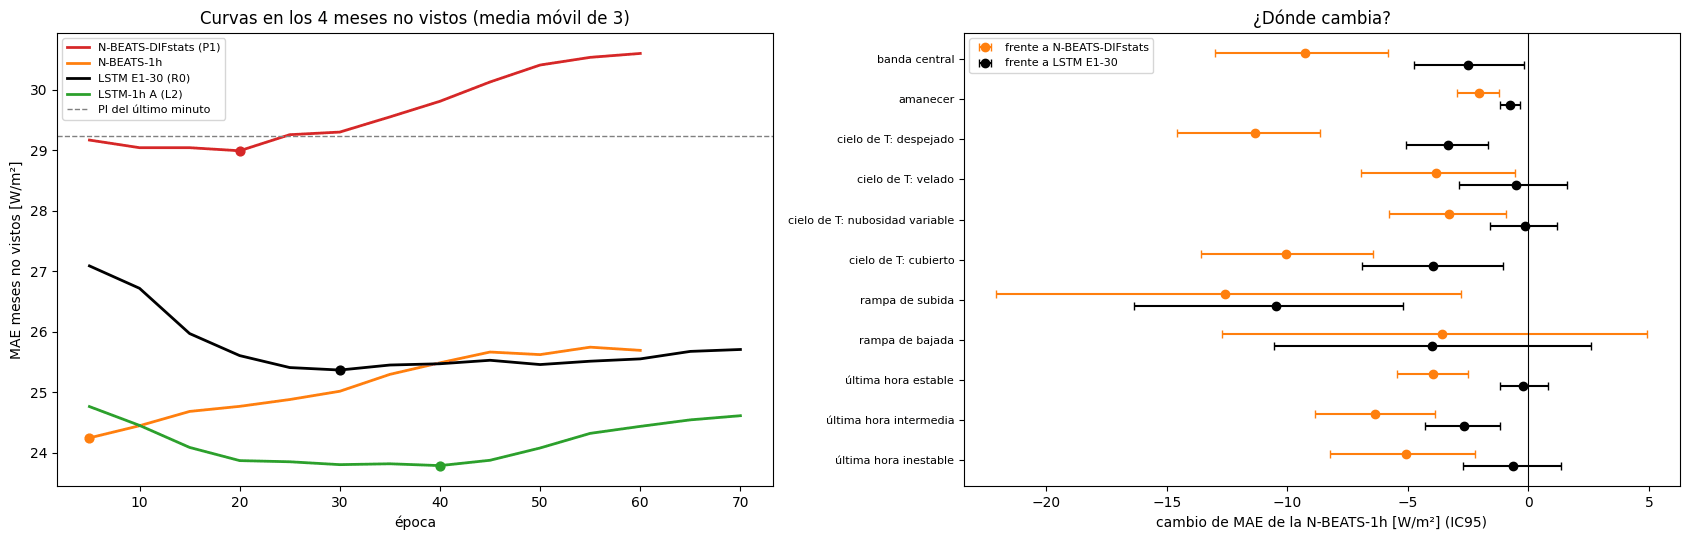


➜ PASA A VALIDACIÓN: la N-BEATS-1h mejora a la N-BEATS-DIFstats en -5.12 W/m² (IC95 [-6.43; -3.85]), mejor época 5. Siguiente: N6b, confirmación con 5 semillas en validación.
Resultados en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/nbeats/N6_entrada_una_hora


In [ ]:
import os, time, random, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor

warnings.filterwarnings("ignore")
try:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
except ImportError:
    pass

BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
DIAG = BASE_DIR / "resultados" / "diagnostico"
RUTA_TABLA = DIAG / "faseB_radiografia_E1" / "tabla_horaria_E1.pkl"
RUTA_L0 = DIAG / "L_entrada_una_hora" / "entrada_una_hora.npz"
DIR_P1N = DIAG / "nbeats" / "P1_sobreaprendizaje_y_robustez"
DIR_R0 = DIAG / "faseC_regularizacion" / "C5b_predicciones"
DIR_L2 = DIAG / "L_entrada_una_hora" / "L2_predicciones"
RUTA_OOF_NB = DIR_P1N / "oof_DIFstats_epoca_15.pkl"
RUTA_OOF_L = DIAG / "depuracion_E1_30" / "P1_oof_E1_30.pkl"
RUTA_VAL = DIAG / "nbeats" / "P2_validacion" / "P2_predicciones_validacion.pkl"
DIR_N3 = DIAG / "nbeats" / "N3_radiografia"
SALIDA = DIAG / "nbeats" / "N6_entrada_una_hora"
DIR_P = SALIDA / "predicciones"
DIR_P.mkdir(parents=True, exist_ok=True)
DIR_N3.mkdir(parents=True, exist_ok=True)
SEMILLAS = [42, 123]
MESES_CRIBA = ["2024-01", "2024-03", "2024-05", "2024-07"]
EPOCAS_MAX, CADA = 60, 5
BATCH, LR, WD = 128, 1e-3, 1e-5
HIDDEN, N_BLOQUES = 128, 6
EFECTO_MINIMO = 0.5
UMBRAL_RAMPA = 97.78
N_BOOT = 2000
PARAMS = dict(
    loss="absolute_error",
    max_iter=150,
    learning_rate=0.05,
    min_samples_leaf=80,
    l2_regularization=1.0,
    random_state=0,
)
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)
T = pd.read_pickle(RUTA_TABLA).sort_index()
L0 = np.load(RUTA_L0)

# PARTE 0 · Tablas D2 y E de N3 (recalculadas y guardadas)
ONB, OL, PV = pd.read_pickle(RUTA_OOF_NB), pd.read_pickle(RUTA_OOF_L), pd.read_pickle(RUTA_VAL)
X = {}
for c in ["train", "validation"]:
    D = T[T["conjunto"] == c].copy()
    assert (D.index == pd.DatetimeIndex(L0[f"fechas_{c}"])).all()
    if c == "train":
        D["N"], D["L"], D["mes"] = (
            ONB["OOF_media"].to_numpy(),
            OL["OOF30_media"].to_numpy(),
            ONB["mes_pliegue"].astype(str).to_numpy(),
        )
    else:
        D["N"], D["L"], D["mes"] = PV["NBEATS_15"].to_numpy(), PV["E1_30"].to_numpy(), "validación"
    seq, esc = L0[f"seq_{c}"], L0[f"esc_{c}"]
    D["ult1"], D["ult15"] = esc[:, 0], seq[:, -3:, 0].mean(1)
    D["F"] = list(np.concatenate([seq.reshape(len(seq), -1), esc], axis=1).astype(np.float32))
    X[c] = D[(D["regimen"].astype(str) != "noche").to_numpy()].copy()
assert abs((X["validation"]["N"] - X["validation"]["real"]).abs().mean() - 28.05) < 0.05
assert abs((X["validation"]["L"] - X["validation"]["real"]).abs().mean() - 23.25) < 0.05
WB = {}
for c, D in X.items():
    u, inv = np.unique(D.index.normalize(), return_inverse=True)
    rng = np.random.default_rng(0)
    WB[c] = np.stack(
        [np.bincount(rng.integers(0, len(u), len(u)), minlength=len(u)) for _ in range(N_BOOT)]
    )[:, inv].astype(float)

def ic0(c, d):
    b = (WB[c] @ d) / WB[c].sum(1)
    return d.mean(), np.percentile(b, 2.5), np.percentile(b, 97.5)

fmt = lambda lo, hi: f"[{lo:+.2f}; {hi:+.2f}]"
MOD = {"N": "N-BEATS-DIFstats", "L": "LSTM E1-30"}
CONJ = {"train": "train (fuera de muestra)", "validation": "validación"}

def matriz(D, k):
    return np.column_stack([np.stack(D["F"].to_numpy()), D[k].to_numpy()])

filas = []
for k in ["N", "L"]:
    TR, VA_ = X["train"], X["validation"]
    Xtr, r_tr = matriz(TR, k), (TR["real"] - TR[k]).to_numpy()
    oof_c, oof_b = np.zeros(len(TR)), np.zeros(len(TR))
    for m_ in np.unique(TR["mes"]):
        f = (TR["mes"] == m_).to_numpy()
        oof_c[f] = HistGradientBoostingRegressor(**PARAMS).fit(Xtr[~f], r_tr[~f]).predict(Xtr[f])
        oof_b[f] = np.median(r_tr[~f])
    va_c = HistGradientBoostingRegressor(**PARAMS).fit(Xtr, r_tr).predict(matriz(VA_, k))
    va_b = np.median(r_tr)
    res = {}
    for c, D, cc, cb in [("train", TR, oof_c, oof_b), ("validation", VA_, va_c, va_b)]:
        y, p = D["real"].to_numpy(), D[k].to_numpy()
        e_b, e_c = np.abs(np.clip(p + cb, 0, None) - y), np.abs(np.clip(p + cc, 0, None) - y)
        res[c] = (np.abs(p - y).mean(), e_b.mean(), e_c.mean(), *ic0(c, e_c - e_b))
    ok = all(res[c][5] < 0 for c in res) and -res["train"][3] >= EFECTO_MINIMO
    for c in res:
        filas.append(
            {
                "modelo": MOD[k],
                "conjunto": CONJ[c],
                "MAE modelo": res[c][0],
                "solo sesgo": res[c][1],
                "con corrector": res[c][2],
                "corrector − solo sesgo": res[c][3],
                "IC95": fmt(res[c][4], res[c][5]),
                "información desaprovechada (D2)": ok,
            }
        )
D2T = pd.DataFrame(filas).set_index(["modelo", "conjunto"])

def lad(x, y, iters=60):
    A = np.c_[np.ones_like(x), x]
    b = np.linalg.lstsq(A, y, rcond=None)[0]
    for _ in range(iters):
        w = 1 / np.maximum(np.abs(y - A @ b), 1e-3)
        b = np.linalg.lstsq(A * np.sqrt(w)[:, None], y * np.sqrt(w), rcond=None)[0]
    return b

filas = []
for k in ["N", "L"]:
    TR = X["train"]
    dl = {c: (D["ult1"] - D["ult15"]).to_numpy() for c, D in X.items()}
    r = {c: (D["real"] - D[k]).to_numpy() for c, D in X.items()}
    cab, ca = np.zeros(len(TR)), np.zeros(len(TR))
    for m_ in np.unique(TR["mes"]):
        f = (TR["mes"] == m_).to_numpy()
        b = lad(dl["train"][~f], r["train"][~f])
        cab[f] = b[0] + b[1] * dl["train"][f]
        ca[f] = np.median(r["train"][~f])
    b_all = lad(dl["train"], r["train"])
    cor = {
        "train": (cab, ca),
        "validation": (b_all[0] + b_all[1] * dl["validation"], np.median(r["train"])),
    }
    res = {}
    for c, D in X.items():
        y, p = D["real"].to_numpy(), D[k].to_numpy()
        e_ab, e_a = np.abs(np.clip(p + cor[c][0], 0, None) - y), np.abs(
            np.clip(p + cor[c][1], 0, None) - y
        )
        res[c] = ic0(c, e_ab - e_a) + (e_a.mean(), e_ab.mean())
    ok = res["train"][2] < 0 and -res["train"][0] >= EFECTO_MINIMO and res["validation"][2] < 0
    for c in res:
        filas.append(
            {
                "modelo": MOD[k],
                "conjunto": CONJ[c],
                "pendiente b (todo train)": b_all[1],
                "MAE solo a": res[c][3],
                "MAE a + b·Δ": res[c][4],
                "cambio": res[c][0],
                "IC95": fmt(res[c][1], res[c][2]),
                "pasa (regla E)": ok,
            }
        )
ET = pd.DataFrame(filas).set_index(["modelo", "conjunto"])
print(
    "=" * 110 + "\nPARTE 0 · Tablas de N3 que faltaban (se guardan en N3_radiografia)\n" + "=" * 110
)
print("D2 · corrector con la última hora a 5 min frente a corregir solo el sesgo:")
display(D2T.round(2))
print(
    "\nE · réplica de R5 (control: la LSTM debería dar ≈ −0,66 en train y ≈ −0,60 en validación):"
)
display(ET.round(3))
D2T.to_csv(DIR_N3 / "N3_D2_corrector.csv")
ET.to_csv(DIR_N3 / "N3_E_ultimo_minuto.csv")

# PARTE 1 · Criba de la N-BEATS con la entrada de una hora
SEQ, ESC = L0["seq_train"].astype(np.float32), L0["esc_train"].astype(np.float32)
y_tr = L0["y_train"].astype(np.float32)
fechas = pd.DatetimeIndex(L0["fechas_train"])
PI1 = ESC[:, 2]
TR = T[T["conjunto"] == "train"]
assert (TR.index == fechas).all() and np.allclose(TR["real"].to_numpy(float), y_tr, atol=1e-3)
SOL = (TR["regimen"].astype(str) != "noche").to_numpy()
mes = fechas.to_period("M").astype(str).to_numpy()
mes = np.where(mes == "2023-12", "2024-01", mes)

def pliegue(m):
    fuera = mes == m
    fin = fechas[fuera].max()
    purga = (fechas > fin) & (fechas <= fin + pd.Timedelta("24h"))
    return ~fuera & ~purga, fuera

NB, NC = SEQ.shape[1], SEQ.shape[2]
print(f"\nTrain: {len(y_tr)} horas · secuencia {SEQ.shape} · escalares {ESC.shape}")
import torch, torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler

class BloqueNB(nn.Module):
    def __init__(self, input_size, hidden_size, backcast_size):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU(),
        )
        self.backcast = nn.Linear(hidden_size, backcast_size)
        self.forecast = nn.Linear(hidden_size, 1)

    def forward(self, x):
        h = self.fc(x)
        return self.backcast(h), self.forecast(h)

class NBEATSUnaHora(nn.Module):
    """Igual que la N-BEATS-DIFstats de P1: residuo sobre la serie de DIF (12 bloques), el resto como covariables."""

    def __init__(self, n_bloques_t, n_canales, n_esc, hidden_size=128, n_bloques=6):
        super().__init__()
        n_in = n_bloques_t * n_canales + n_esc
        self.blocks = nn.ModuleList(
            [BloqueNB(n_in, hidden_size, n_bloques_t) for _ in range(n_bloques)]
        )

    def forward(self, x_seq, x_esc):
        residuo = x_seq[:, :, 0]
        cov = torch.cat([x_seq[:, :, 1:].permute(0, 2, 1).reshape(x_seq.size(0), -1), x_esc], dim=1)
        total = torch.zeros((x_seq.size(0), 1), dtype=x_seq.dtype)
        for b in self.blocks:
            back, fore = b(torch.cat([residuo, cov], dim=1))
            residuo = residuo - back
            total = total + fore
        return total.squeeze(-1)

print(
    "Parámetros entrenables N-BEATS-1h:",
    f"{sum(p.numel() for p in NBEATSUnaHora(NB, NC, ESC.shape[1], HIDDEN, N_BLOQUES).parameters()):,}",
)

def entrenar(entrena, fuera, semilla):
    """Predicción de DIF (PI1 + corrección) del mes no visto en cada época (filas = épocas 1…60)."""
    r = y_tr - PI1
    s_seq = StandardScaler().fit(SEQ[entrena].reshape(-1, NC))
    s_esc = StandardScaler().fit(ESC[entrena])
    s_y = StandardScaler().fit(r[entrena].reshape(-1, 1))
    tq = lambda Z: torch.from_numpy(
        s_seq.transform(Z.reshape(-1, NC)).reshape(Z.shape).astype(np.float32)
    )
    te = lambda Z: torch.from_numpy(s_esc.transform(Z).astype(np.float32))
    Xs, Xe, Xs_f, Xe_f = tq(SEQ[entrena]), te(ESC[entrena]), tq(SEQ[fuera]), te(ESC[fuera])
    r_e = torch.from_numpy(s_y.transform(r[entrena].reshape(-1, 1)).ravel().astype(np.float32))
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    torch.use_deterministic_algorithms(True)
    modelo = NBEATSUnaHora(NB, NC, ESC.shape[1], HIDDEN, N_BLOQUES)
    gen = torch.Generator()
    gen.manual_seed(semilla)
    loader = DataLoader(
        TensorDataset(Xs, Xe, r_e), batch_size=BATCH, shuffle=True, generator=gen, num_workers=0
    )
    opt = torch.optim.Adam(modelo.parameters(), lr=LR, weight_decay=WD)
    crit = nn.L1Loss()
    preds = []
    for ep in range(1, EPOCAS_MAX + 1):
        modelo.train()
        for xs, xe, yb in loader:
            opt.zero_grad(set_to_none=True)
            loss = crit(modelo(xs, xe), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), max_norm=1.0)
            opt.step()
        modelo.eval()
        with torch.no_grad():
            corr = s_y.inverse_transform(modelo(Xs_f, Xe_f).numpy().reshape(-1, 1)).ravel()
        preds.append(np.clip(PI1[fuera] + corr, 0, None))
    return np.array(preds, dtype=np.float32)

t_ini = time.time()
tareas = [(s, m) for s in SEMILLAS for m in MESES_CRIBA]
for k, (s, m) in enumerate(tareas, 1):
    ruta = DIR_P / f"NB1h_{m}_s{s}.npz"
    if ruta.exists():
        print(f"[{k}/{len(tareas)}] {m} · semilla {s}: ya hecho")
        continue
    t0 = time.time()
    entrena, fuera = pliegue(m)
    np.savez_compressed(ruta, pred=entrenar(entrena, fuera, s))
    print(
        f"[{k}/{len(tareas)}] {m} · semilla {s}: {time.time()-t0:.0f} s (total {(time.time()-t_ini)/60:.1f} min)"
    )

# Evaluación en los 4 meses no vistos (horas con sol)
idx = np.where(np.isin(mes, MESES_CRIBA))[0]
sol = SOL[idx]
y = y_tr[idx]
inf = TR.iloc[idx].copy()

def mejor(cargar, epocas):
    """Media de semillas; MAE medido en épocas múltiplos de 5; mejor época por media móvil de 3."""
    P = np.zeros((len(epocas), len(idx)))
    for s in SEMILLAS:
        for m_ in MESES_CRIBA:
            p = cargar(m_, s)
            n_m = int((mes[idx] == m_).sum())
            assert p.shape[1] == n_m, f"Tamaño inesperado en {m_} s{s}: {p.shape}"
            P[:, mes[idx] == m_] += p / len(SEMILLAS)
    mae = np.abs(P[:, sol] - y[sol]).mean(1)
    suav = pd.Series(mae, index=epocas).rolling(3, center=True, min_periods=1).mean()
    ep = int(suav.idxmin())
    pr = P[list(epocas).index(ep)]
    return dict(ep=ep, suav=suav, pred=pr, err=np.abs(pr - y))

E5 = np.arange(CADA, EPOCAS_MAX + 1, CADA)
res = {
    "N-BEATS-DIFstats (P1)": mejor(
        lambda m_, s: np.load(DIR_P1N / f"DIFstats_fold_{m_}_s{s}.npz")["pred"][E5 - 1], E5
    ),
    "N-BEATS-1h": mejor(lambda m_, s: np.load(DIR_P / f"NB1h_{m_}_s{s}.npz")["pred"][E5 - 1], E5),
}
E70 = np.arange(5, 71, 5)
res["LSTM E1-30 (R0)"] = mejor(lambda m_, s: np.load(DIR_R0 / f"R0_{m_}_s{s}.npz")["pred"], E70)
if all((DIR_L2 / f"A_{m_}_s{s}.npz").exists() for m_ in MESES_CRIBA for s in SEMILLAS):
    res["LSTM-1h A (L2)"] = mejor(lambda m_, s: np.load(DIR_L2 / f"A_{m_}_s{s}.npz")["pred"], E70)
pi_err = np.abs(PI1[idx] - y)
u, inv = np.unique(inf.index.normalize(), return_inverse=True)
rng = np.random.default_rng(0)
Wb = np.stack(
    [np.bincount(rng.integers(0, len(u), len(u)), minlength=len(u)) for _ in range(N_BOOT)]
)[:, inv].astype(float)

def ic(d, msk):
    v = np.where(msk, d, 0.0)
    b = (Wb @ v) / np.maximum(Wb @ msk.astype(float), 1e-9)
    return d[msk].mean(), np.percentile(b, 2.5), np.percentile(b, 97.5)

lect = lambda lo, hi: "mejora" if hi < 0 else ("EMPEORA" if lo > 0 else "igual")
inf["cielo"] = inf["cielo"].astype(str).replace({"nubes rotas": "nubosidad variable"})
central = inf["banda"].astype(str).str.startswith("central").to_numpy()
hora = inf.index.hour.to_numpy()
reg = inf["regimen"].astype(str).to_numpy()
dlt = y - T["real"].reindex(inf.index - pd.Timedelta("1h")).to_numpy()
var_h = SEQ[:, :, 3].mean(1)
cortes = np.percentile(var_h[SOL], [100 / 3, 200 / 3])
var_i = var_h[idx]
e0, e1 = res["N-BEATS-DIFstats (P1)"]["err"], res["N-BEATS-1h"]["err"]
d = e1 - e0
c, lo, hi = ic(d, sol)
cc, lc, hc = ic(d, sol & central)
ok1, ok2 = (hi < 0 and -c >= EFECTO_MINIMO), lc <= 0
filas = [
    {"configuración": k_, "mejor época": v["ep"], "MAE operación": v["err"][sol].mean()}
    for k_, v in res.items()
]
filas.append(
    {
        "configuración": "persistencia inteligente del último minuto",
        "MAE operación": pi_err[sol].mean(),
    }
)
R = pd.DataFrame(filas).set_index("configuración")
for k_ in res:
    if k_ != "N-BEATS-DIFstats (P1)":
        c_, lo_, hi_ = ic(res[k_]["err"] - e0, sol)
        R.loc[k_, "− N-BEATS-DIFstats"] = c_
        R.loc[k_, "IC95"] = fmt(lo_, hi_)
c_l, lo_l, hi_l = ic(e1 - res["LSTM E1-30 (R0)"]["err"], sol)
grupos = [
    ("operación", np.ones(len(idx), bool)),
    ("banda central", central),
    ("amanecer", (reg == "transicion") & (hora < 12)),
]
grupos += [
    (f"cielo de T: {g}", (inf["cielo"] == g).to_numpy())
    for g in ["despejado", "velado", "nubosidad variable", "cubierto"]
]
grupos += [
    ("rampa de subida", dlt >= UMBRAL_RAMPA),
    ("rampa de bajada", dlt <= -UMBRAL_RAMPA),
    ("última hora estable", var_i <= cortes[0]),
    ("última hora intermedia", (var_i > cortes[0]) & (var_i <= cortes[1])),
    ("última hora inestable", var_i > cortes[1]),
]
filas = []
for nombre, msk in grupos:
    msk = sol & msk
    if msk.sum() >= 30:
        g, gl, gh = ic(d, msk)
        gL, glL, ghL = ic(e1 - res["LSTM E1-30 (R0)"]["err"], msk)
        filas.append(
            {
                "grupo": nombre,
                "horas": int(msk.sum()),
                "MAE N-BEATS-DIFstats": e0[msk].mean(),
                "MAE N-BEATS-1h": e1[msk].mean(),
                "MAE LSTM E1-30": res["LSTM E1-30 (R0)"]["err"][msk].mean(),
                "1h − DIFstats": g,
                "IC95": fmt(gl, gh),
                "lectura": lect(gl, gh),
                "1h − LSTM E1-30": gL,
                "IC95 frente a LSTM": fmt(glL, ghL),
            }
        )
G = pd.DataFrame(filas).set_index("grupo")
print(
    "\n"
    + "=" * 110
    + "\nN6 · N-BEATS CON LA ENTRADA DE UNA HORA (train, 4 meses no vistos, 2 semillas, horas con sol)\n"
    + "=" * 110
)
display(R.round(2))
print(
    f"\nCriterio 1 · operación: {c:+.2f} W/m², IC95 [{lo:+.2f}; {hi:+.2f}] → {'cumple' if ok1 else 'no cumple'}"
)
print(
    f"Criterio 2 · banda central: {cc:+.2f} W/m², IC95 [{lc:+.2f}; {hc:+.2f}] → {'no empeora' if ok2 else 'EMPEORA'}"
)
print(f"Informativo · N-BEATS-1h − LSTM E1-30: {c_l:+.2f} W/m², IC95 [{lo_l:+.2f}; {hi_l:+.2f}]")
for k_, v in res.items():
    if v["ep"] == max(v["suav"].index):
        print(
            f"⚠ {k_}: su mejor época es la última medida; la curva podría seguir bajando (se informa, no cambia el criterio)."
        )
print("\nDesglose (IC95 sin ajustar; no decide):")
display(G.round(2))
fig, axs = plt.subplots(1, 2, figsize=(17, 5.5))
col = {
    "N-BEATS-DIFstats (P1)": "tab:red",
    "N-BEATS-1h": "tab:orange",
    "LSTM E1-30 (R0)": "black",
    "LSTM-1h A (L2)": "tab:green",
}
for k_, v in res.items():
    axs[0].plot(v["suav"].index, v["suav"].values, color=col[k_], lw=2, label=k_)
    axs[0].scatter([v["ep"]], [v["suav"].loc[v["ep"]]], color=col[k_], s=40, zorder=3)
axs[0].axhline(pi_err[sol].mean(), color="gray", ls="--", lw=1, label="PI del último minuto")
axs[0].set_xlabel("época")
axs[0].set_ylabel("MAE meses no vistos [W/m²]")
axs[0].legend(fontsize=8)
axs[0].set_title("Curvas en los 4 meses no vistos (media móvil de 3)")
sub = G.drop(index="operación")
yy = np.arange(len(sub))
for j, (colm, ic_col, color, lab) in enumerate(
    [
        ("1h − DIFstats", "IC95", "tab:orange", "frente a N-BEATS-DIFstats"),
        ("1h − LSTM E1-30", "IC95 frente a LSTM", "black", "frente a LSTM E1-30"),
    ]
):
    lim = sub[ic_col].str.strip("[]").str.split(";", expand=True).astype(float)
    axs[1].errorbar(
        sub[colm],
        yy + (0.15 if j else -0.15),
        xerr=[sub[colm] - lim[0], lim[1] - sub[colm]],
        fmt="o",
        color=color,
        ecolor=color,
        capsize=3,
        label=lab,
    )
axs[1].axvline(0, color="k", lw=0.8)
axs[1].set_yticks(yy)
axs[1].set_yticklabels(sub.index, fontsize=8)
axs[1].invert_yaxis()
axs[1].legend(fontsize=8)
axs[1].set_xlabel("cambio de MAE de la N-BEATS-1h [W/m²] (IC95)")
axs[1].set_title("¿Dónde cambia?")
plt.tight_layout()
plt.savefig(SALIDA / "N6_criba.png", dpi=120)
plt.show()
if ok1 and ok2:
    ver = (
        f"PASA A VALIDACIÓN: la N-BEATS-1h mejora a la N-BEATS-DIFstats en {c:+.2f} W/m² (IC95 [{lo:+.2f}; {hi:+.2f}]), "
        f"mejor época {res['N-BEATS-1h']['ep']}. Siguiente: N6b, confirmación con 5 semillas en validación."
    )
elif not ok2:
    ver = f"NO PASA: empeora la banda central ({cc:+.2f}, IC95 [{lc:+.2f}; {hc:+.2f}]). La N-BEATS final sigue siendo la N-BEATS-DIFstats."
elif hi < 0:
    ver = f"NO PASA por tamaño: mejora {c:+.2f} W/m² (IC95 [{lo:+.2f}; {hi:+.2f}]), por debajo de {EFECTO_MINIMO}. La N-BEATS final sigue siendo la N-BEATS-DIFstats."
else:
    ver = f"NO PASA: cambio {c:+.2f} W/m² (IC95 [{lo:+.2f}; {hi:+.2f}]). La N-BEATS final sigue siendo la N-BEATS-DIFstats."
print("\n➜ " + ver)
R.to_csv(SALIDA / "N6_resumen.csv")
G.to_csv(SALIDA / "N6_desglose.csv")
pd.DataFrame({k_: v["suav"] for k_, v in res.items()}).to_csv(SALIDA / "N6_curvas.csv")
pd.DataFrame(
    {
        "real": y,
        "sol": sol,
        "mes": mes[idx],
        "PI1": PI1[idx],
        **{k_: v["pred"] for k_, v in res.items()},
    },
    index=inf.index,
).to_pickle(SALIDA / "N6_oof.pkl")
(SALIDA / "N6_veredicto.txt").write_text(ver + "\n", encoding="utf-8")
print("Resultados en:", SALIDA)

**Resultados.** N-BEATS-1h alcanza su mejor época en la 5, con 24,20 W/m² frente a 29,32 W/m² de N-BEATS-DIFstats (−5,12 W/m², IC95 [−6,43; −3,85]), y mejora también la banda central (−9,28 W/m², IC95 [−12,99; −5,83]), así que pasa a la confirmación en validación. Como referencia informativa en los mismos meses, E1-30 obtiene 25,39 W/m² y la LSTM-1h A, 23,72 W/m² (N-BEATS-1h − E1-30: −1,19 W/m², IC95 [−2,03; −0,35]). En el desglose descriptivo, las mayores mejoras frente a N-BEATS-DIFstats se dan en las rampas de subida (−12,56 W/m²) y con cielo despejado (−11,34 W/m²) y cubierto (−10,05 W/m²).

### 6.2 Confirmación de N-BEATS-1h en validación

N-BEATS-1h se entrena con todo el entrenamiento durante 5 épocas, las fijadas en la criba, con las semillas 42, 123, 2024, 7 y 99, y la media de sus predicciones se compara una sola vez en validación con N-BEATS-DIFstats (28,05 W/m²). El criterio, fijado antes, exige que el IC95 por bootstrap de días de la diferencia de MAE en horas con sol quede entero por debajo de 0 y que la banda central no empeore de forma significativa; las comparaciones con E1-30, V3-50 y la LSTM-1h A, el desglose y la curva de validación hasta la época 30 solo se informan.

Referencias comprobadas: N-BEATS-DIFstats 28,05 · E1-30 23,25 · V3-50 22,47 · LSTM-1h A 23,06
Train 5149 h · validación 1464 h · secuencia (12, 5) · escalares 4
[1/5] semilla 42: 64 s (total 1.1 min)
[2/5] semilla 123: 21 s (total 1.4 min)
[3/5] semilla 2024: 20 s (total 1.7 min)
[4/5] semilla 7: 23 s (total 2.1 min)
[5/5] semilla 99: 23 s (total 2.5 min)

N6b · N-BEATS-1h EN VALIDACIÓN (ago–sep 2024, horas con sol, media de 5 semillas, época 5)


,MAE,RMSE,sesgo,− N-BEATS-DIFstats,IC95 (N),− E1-30,IC95 (E1-30),DM p (E1-30),lectura frente a E1-30
modelo,,,,,,,,,
persistencia inteligente del último minuto,27.580999,42.863998,-2.171,-0.465,[-2.75; +1.89],4.327,[+2.66; +6.05],0.000,peor
N-BEATS-DIFstats,28.046000,43.481998,7.860,NaN,NaN,4.792,[+3.52; +6.05],0.000,peor
N-BEATS-1h,23.240999,35.839001,-3.016,-4.805,[-6.41; -3.09],-0.012,[-1.00; +0.93],0.994,igual
LSTM E1-30,23.254000,36.275002,-2.395,-4.792,[-6.05; -3.52],NaN,NaN,NaN,NaN
V3-50,22.472000,34.339001,-0.767,-5.574,[-6.80; -4.28],-0.782,[-1.50; -0.06],0.039,mejor
LSTM-1h A,23.059999,36.321999,-2.848,-4.986,[-6.56; -3.29],-0.194,[-1.12; +0.71],0.749,igual



Criterio 1 · N-BEATS-1h − N-BEATS-DIFstats = -4.80 W/m², IC95 [-6.41; -3.09], DM p = 0.0000 → MEJOR
Criterio 2 · banda central: -11.13 W/m², IC95 [-17.31; -4.95] → no empeora
Informativo · N-BEATS-1h − LSTM-1h A: +0.18 W/m², IC95 [-0.37; +0.74], DM p = 0.5428 → igual
Informativo · N-BEATS-1h − V3-50: +0.77 W/m², IC95 [+0.00; +1.54], DM p = 0.0510 → peor
Informativo · N-BEATS-1h − LSTM E1-30: -0.01 W/m², IC95 [-1.00; +0.93], DM p = 0.9944 → igual
Informativo · MAE por semilla: 42: 24.18 · 123: 24.51 · 2024: 23.77 · 7: 24.07 · 99: 23.98

Desglose (IC95 sin ajustar; no decide):


,horas,MAE N-BEATS-DIFstats,MAE N-BEATS-1h,MAE E1-30,MAE LSTM-1h A,1h − DIFstats,IC95,lectura,1h − E1-30,IC95 frente a E1-30
grupo,,,,,,,,,,
operación,884,28.049999,23.240000,23.250000,23.059999,-4.80,[-6.41; -3.09],mejor,-0.01,[-1.00; +0.93]
banda central,205,47.480000,36.349998,36.360001,36.759998,-11.13,[-17.31; -4.95],mejor,-0.01,[-3.51; +3.41]
amanecer,60,4.480000,2.780000,3.360000,3.100000,-1.70,[-2.79; -0.64],mejor,-0.59,[-0.91; -0.25]
cielo de T: despejado,185,25.719999,11.520000,14.470000,11.630000,-14.20,[-19.18; -10.20],mejor,-2.95,[-5.32; -1.05]
cielo de T: velado,89,22.320000,18.330000,20.120001,17.799999,-4.00,[-8.53; +0.28],igual,-1.79,[-4.44; +1.06]
cielo de T: nubosidad variable,438,33.759998,34.200001,32.200001,33.700001,0.45,[-2.12; +3.16],igual,2.01,[+0.47; +3.53]
cielo de T: cubierto,53,53.320000,27.799999,31.500000,29.209999,-25.52,[-35.70; -16.08],mejor,-3.71,[-10.24; +1.26]
rampa de subida,36,80.059998,78.099998,82.900002,78.099998,-1.97,[-14.84; +11.32],igual,-4.80,[-11.01; +1.29]
rampa de bajada,45,82.169998,47.580002,61.540001,50.919998,-34.59,[-49.43; -20.50],mejor,-13.96,[-23.02; -5.00]



Curva de validación por época (SOLO descriptiva; la época 5 estaba fijada):
   1: 24.74 · 2: 24.26 · 3: 23.81 · 4: 23.70 · 5: 23.24 · 6: 23.14 · 7: 23.19 · 8: 23.10 · 9: 22.81 · 10: 23.17 · 11: 23.00 · 12: 22.93 · 13: 23.34 · 14: 23.26 · 15: 22.85 · 16: 22.96 · 17: 23.13 · 18: 23.34 · 19: 23.37 · 20: 23.20 · 21: 23.40 · 22: 23.38 · 23: 23.40 · 24: 23.54 · 25: 23.45 · 26: 23.61 · 27: 23.47 · 28: 23.88 · 29: 23.75 · 30: 23.82


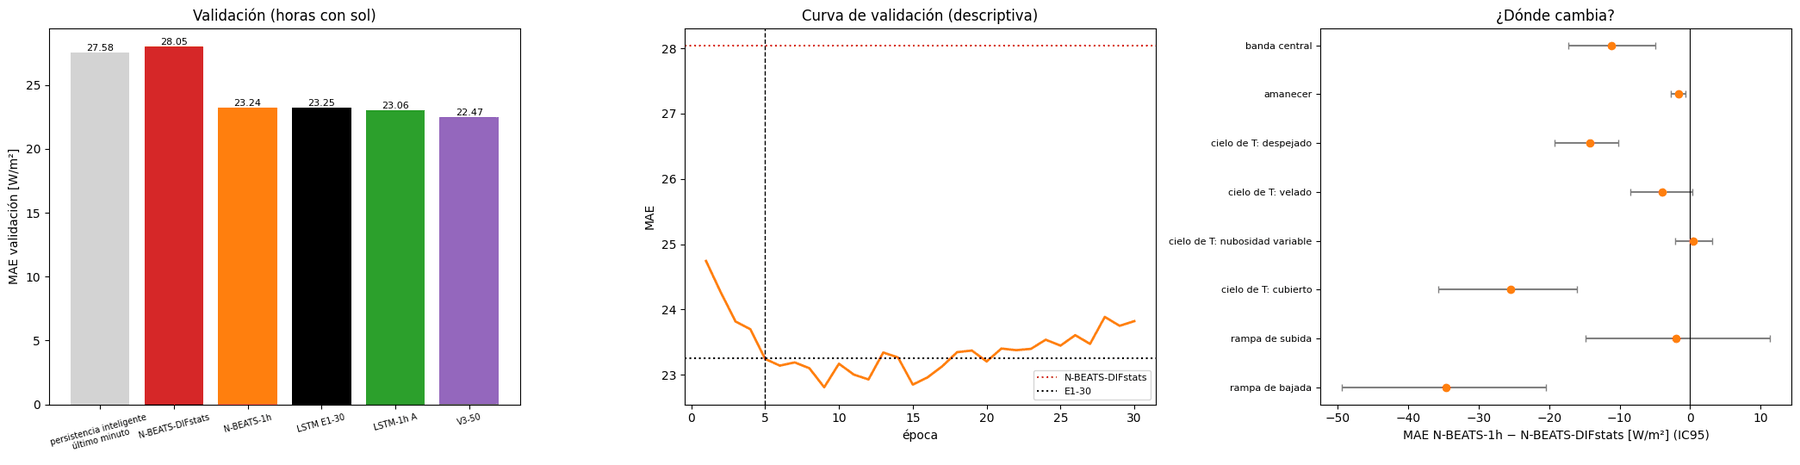


➜ CONFIRMADA: la N-BEATS-1h mejora a la N-BEATS-DIFstats en validación (-4.80 W/m², IC95 [-6.41; -3.09]) sin empeorar la banda central. Pasa a ser la N-BEATS final (MAE 23.24).
Resultados en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/nbeats/N6b_confirmacion


In [ ]:
import os, time, random, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings("ignore")
try:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
except ImportError:
    pass

BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
DIAG = BASE_DIR / "resultados" / "diagnostico"
RUTA_TABLA = DIAG / "faseB_radiografia_E1" / "tabla_horaria_E1.pkl"
RUTA_L0 = DIAG / "L_entrada_una_hora" / "entrada_una_hora.npz"
RUTA_P2 = DIAG / "nbeats" / "P2_validacion" / "P2_predicciones_validacion.pkl"
RUTA_C8B = DIAG / "faseC_ultimo_minuto" / "C8b_confirmacion" / "C8b_predicciones_validacion.pkl"
RUTA_L3 = DIAG / "L_entrada_una_hora" / "L3_predicciones_validacion.pkl"
SALIDA = DIAG / "nbeats" / "N6b_confirmacion"
SALIDA.mkdir(parents=True, exist_ok=True)
SEMILLAS = [42, 123, 2024, 7, 99]
EPOCA = 5  # fijada en N6 con train
EPOCAS_CURVA = 30  # solo para la curva descriptiva
BATCH, LR, WD = 128, 1e-3, 1e-5
HIDDEN, N_BLOQUES = 128, 6
N_BOOT = 2000
UMBRAL_RAMPA = 97.78

# 1) Datos
L0 = np.load(RUTA_L0)
SEQ = {c: L0[f"seq_{c}"].astype(np.float32) for c in ["train", "validation"]}
ESC = {c: L0[f"esc_{c}"].astype(np.float32) for c in ["train", "validation"]}
Y = {c: L0[f"y_{c}"].astype(np.float32) for c in ["train", "validation"]}
F = {c: pd.DatetimeIndex(L0[f"fechas_{c}"]) for c in ["train", "validation"]}
PI1 = {c: ESC[c][:, 2] for c in ["train", "validation"]}
assert F["train"].max() < F["validation"].min() and F["validation"].max() < pd.Timestamp(
    "2024-10-01"
)
T = pd.read_pickle(RUTA_TABLA).sort_index()
T = T[T.index < pd.Timestamp("2024-10-01")]  # nada del test
for c in ["train", "validation"]:
    assert (T[T["conjunto"] == c].index == F[c]).all(), f"La tabla horaria no cuadra con L0 ({c})"
VA = T[T["conjunto"] == "validation"].copy()
P2, C8, L3 = pd.read_pickle(RUTA_P2), pd.read_pickle(RUTA_C8B), pd.read_pickle(RUTA_L3)
for nombre, D in [("P2", P2), ("C8b", C8), ("L3", L3)]:
    assert (D.index == F["validation"]).all(), f"{nombre} no cuadra con validación"
    assert np.allclose(
        D["real"].to_numpy(float), Y["validation"], atol=1e-3
    ), f"{nombre}: el objetivo no coincide"
# Comprobación de las referencias ANTES de entrenar
m = (VA["regimen"].astype(str) != "noche").to_numpy()
y = Y["validation"][m]
for nombre, p_, esperado in [
    ("N-BEATS-DIFstats", P2["NBEATS_15"], 28.05),
    ("E1-30", C8["E1_30"], 23.25),
    ("V3-50", C8["V3_50"], 22.47),
    ("LSTM-1h A", L3["LSTM-1h A"], 23.06),
]:
    mae_ = np.abs(p_.to_numpy()[m] - y).mean()
    assert (
        abs(mae_ - esperado) < 0.05
    ), f"No se reproduce el MAE de {nombre} ({mae_:.2f} frente a {esperado})"
print(
    "Referencias comprobadas: N-BEATS-DIFstats 28,05 · E1-30 23,25 · V3-50 22,47 · LSTM-1h A 23,06"
)
NB, NC, NE = SEQ["train"].shape[1], SEQ["train"].shape[2], ESC["train"].shape[1]
print(
    f"Train {len(Y['train'])} h · validación {len(Y['validation'])} h · secuencia {SEQ['train'].shape[1:]} · escalares {NE}"
)

# 2) Modelo y entrenamiento (idénticos a N6)
import torch, torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler

class BloqueNB(nn.Module):
    def __init__(self, input_size, hidden_size, backcast_size):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU(),
        )
        self.backcast = nn.Linear(hidden_size, backcast_size)
        self.forecast = nn.Linear(hidden_size, 1)

    def forward(self, x):
        h = self.fc(x)
        return self.backcast(h), self.forecast(h)

class NBEATSUnaHora(nn.Module):
    def __init__(self, n_bloques_t, n_canales, n_esc, hidden_size=128, n_bloques=6):
        super().__init__()
        n_in = n_bloques_t * n_canales + n_esc
        self.blocks = nn.ModuleList(
            [BloqueNB(n_in, hidden_size, n_bloques_t) for _ in range(n_bloques)]
        )

    def forward(self, x_seq, x_esc):
        residuo = x_seq[:, :, 0]
        cov = torch.cat([x_seq[:, :, 1:].permute(0, 2, 1).reshape(x_seq.size(0), -1), x_esc], dim=1)
        total = torch.zeros((x_seq.size(0), 1), dtype=x_seq.dtype)
        for b in self.blocks:
            back, fore = b(torch.cat([residuo, cov], dim=1))
            residuo = residuo - back
            total = total + fore
        return total.squeeze(-1)

def entrenar(semilla):
    """Predicción de validación (PI1 + corrección) en cada época 1…EPOCAS_CURVA (filas = épocas)."""
    r = Y["train"] - PI1["train"]
    s_seq = StandardScaler().fit(SEQ["train"].reshape(-1, NC))
    s_esc = StandardScaler().fit(ESC["train"])
    s_y = StandardScaler().fit(r.reshape(-1, 1))
    tq = lambda Z: torch.from_numpy(
        s_seq.transform(Z.reshape(-1, NC)).reshape(Z.shape).astype(np.float32)
    )
    te = lambda Z: torch.from_numpy(s_esc.transform(Z).astype(np.float32))
    Xs, Xe, Xs_v, Xe_v = (
        tq(SEQ["train"]),
        te(ESC["train"]),
        tq(SEQ["validation"]),
        te(ESC["validation"]),
    )
    r_e = torch.from_numpy(s_y.transform(r.reshape(-1, 1)).ravel().astype(np.float32))
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    torch.use_deterministic_algorithms(True)
    modelo = NBEATSUnaHora(NB, NC, NE, HIDDEN, N_BLOQUES)
    gen = torch.Generator()
    gen.manual_seed(semilla)
    loader = DataLoader(
        TensorDataset(Xs, Xe, r_e), batch_size=BATCH, shuffle=True, generator=gen, num_workers=0
    )
    opt = torch.optim.Adam(modelo.parameters(), lr=LR, weight_decay=WD)
    crit = nn.L1Loss()
    preds = []
    for ep in range(1, EPOCAS_CURVA + 1):
        modelo.train()
        for xs, xe, yb in loader:
            opt.zero_grad(set_to_none=True)
            loss = crit(modelo(xs, xe), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), max_norm=1.0)
            opt.step()
        modelo.eval()
        with torch.no_grad():
            corr = s_y.inverse_transform(modelo(Xs_v, Xe_v).numpy().reshape(-1, 1)).ravel()
        preds.append(np.clip(PI1["validation"] + corr, 0, None))
        if ep == EPOCA:
            torch.save(modelo.state_dict(), SALIDA / f"modelo_NBEATS_1h_ep{EPOCA}_s{semilla}.pt")
    return np.array(preds, dtype=np.float32)

t_ini = time.time()
for k, s in enumerate(SEMILLAS, 1):
    ruta = SALIDA / f"pred_validacion_NB1h_s{s}.npz"
    if ruta.exists():
        print(f"[{k}/{len(SEMILLAS)}] semilla {s}: ya hecha")
        continue
    t0 = time.time()
    np.savez_compressed(ruta, pred=entrenar(s))
    print(
        f"[{k}/{len(SEMILLAS)}] semilla {s}: {time.time()-t0:.0f} s (total {(time.time()-t_ini)/60:.1f} min)"
    )
P_sem = np.stack(
    [np.load(SALIDA / f"pred_validacion_NB1h_s{s}.npz")["pred"] for s in SEMILLAS]
)  # semillas × épocas × horas
assert P_sem.shape[:2] == (len(SEMILLAS), EPOCAS_CURVA)
pred_1h = P_sem[:, EPOCA - 1, :].mean(0)
assert (
    np.isfinite(P_sem).all() and pred_1h.shape == Y["validation"].shape
), "Hay predicciones no finitas (¿alguna semilla divergió?)"

# 3) Evaluación (horas con sol)
PRED = {
    "persistencia inteligente del último minuto": PI1["validation"],
    "N-BEATS-DIFstats": P2["NBEATS_15"].to_numpy(),
    "N-BEATS-1h": pred_1h,
    "LSTM E1-30": C8["E1_30"].to_numpy(),
    "V3-50": C8["V3_50"].to_numpy(),
    "LSTM-1h A": L3["LSTM-1h A"].to_numpy(),
}
E = {k: np.abs(p[m] - y) for k, p in PRED.items()}
inf = VA[m].copy()
dias = inf.index.normalize().to_numpy()
u, inv = np.unique(dias, return_inverse=True)
rng = np.random.default_rng(0)
Wb = np.stack(
    [np.bincount(rng.integers(0, len(u), len(u)), minlength=len(u)) for _ in range(N_BOOT)]
)[:, inv].astype(float)

def ic(d, msk=None):
    msk = np.ones(len(d), bool) if msk is None else msk
    v = np.where(msk, d, 0.0)
    b = (Wb @ v) / np.maximum(Wb @ msk.astype(float), 1e-9)
    return d[msk].mean(), np.percentile(b, 2.5), np.percentile(b, 97.5)

def dm(d):
    s = pd.Series(d, index=inf.index).groupby(dias).mean().to_numpy()
    n = len(s)
    dc = s - s.mean()
    L = int(np.floor(n ** (1 / 3)))
    var = dc @ dc / n + sum(2 * (1 - k / (L + 1)) * (dc[k:] @ dc[:-k]) / n for k in range(1, L + 1))
    t = s.mean() / np.sqrt(var / n) * np.sqrt((n - 1) / n)
    return t, 2 * stats.t.sf(abs(t), df=n - 1)

lect = lambda lo, hi: "mejor" if hi < 0 else ("peor" if lo > 0 else "igual")
fmt = lambda lo, hi: f"[{lo:+.2f}; {hi:+.2f}]"
central = inf["banda"].astype(str).str.startswith("central").to_numpy()
d = E["N-BEATS-1h"] - E["N-BEATS-DIFstats"]
c, lo, hi = ic(d)
cc, lc, hc = ic(d, central)
_, p_dm = dm(d)
ok1, ok2 = hi < 0, lc <= 0
filas = []
for k_ in PRED:
    fila = {
        "modelo": k_,
        "MAE": E[k_].mean(),
        "RMSE": np.sqrt(((PRED[k_][m] - y) ** 2).mean()),
        "sesgo": (PRED[k_][m] - y).mean(),
    }
    if k_ != "N-BEATS-DIFstats":
        a, b_, h_ = ic(E[k_] - E["N-BEATS-DIFstats"])
        fila.update({"− N-BEATS-DIFstats": a, "IC95 (N)": fmt(b_, h_)})
    if k_ != "LSTM E1-30":
        a, b_, h_ = ic(E[k_] - E["LSTM E1-30"])
        _, pp = dm(E[k_] - E["LSTM E1-30"])
        fila.update(
            {
                "− E1-30": a,
                "IC95 (E1-30)": fmt(b_, h_),
                "DM p (E1-30)": pp,
                "lectura frente a E1-30": lect(b_, h_),
            }
        )
    filas.append(fila)
R = pd.DataFrame(filas).set_index("modelo")
mae_sem = [np.abs(P_sem[i, EPOCA - 1, m] - y).mean() for i in range(len(SEMILLAS))]
curva = pd.Series(
    [np.abs(P_sem[:, j, :].mean(0)[m] - y).mean() for j in range(EPOCAS_CURVA)],
    index=np.arange(1, EPOCAS_CURVA + 1),
)
cielo = inf["cielo"].astype(str).replace({"nubes rotas": "nubosidad variable"}).to_numpy()
hora = inf.index.hour.to_numpy()
reg = inf["regimen"].astype(str).to_numpy()
dlt = y - T["real"].reindex(inf.index - pd.Timedelta("1h")).to_numpy()
grupos = [
    ("operación", np.ones(len(y), bool)),
    ("banda central", central),
    ("amanecer", (reg == "transicion") & (hora < 12)),
]
grupos += [
    (f"cielo de T: {g}", cielo == g)
    for g in ["despejado", "velado", "nubosidad variable", "cubierto"]
]
grupos += [("rampa de subida", dlt >= UMBRAL_RAMPA), ("rampa de bajada", dlt <= -UMBRAL_RAMPA)]
filas = []
omitidos = [nombre for nombre, msk in grupos if msk.sum() < 30]
if omitidos:
    print("Grupos omitidos del desglose por tener < 30 horas:", ", ".join(omitidos))
for nombre, msk in grupos:
    if msk.sum() >= 30:
        g, gl, gh = ic(d, msk)
        gL, glL, ghL = ic(E["N-BEATS-1h"] - E["LSTM E1-30"], msk)
        filas.append(
            {
                "grupo": nombre,
                "horas": int(msk.sum()),
                "MAE N-BEATS-DIFstats": E["N-BEATS-DIFstats"][msk].mean(),
                "MAE N-BEATS-1h": E["N-BEATS-1h"][msk].mean(),
                "MAE E1-30": E["LSTM E1-30"][msk].mean(),
                "MAE LSTM-1h A": E["LSTM-1h A"][msk].mean(),
                "1h − DIFstats": g,
                "IC95": fmt(gl, gh),
                "lectura": lect(gl, gh),
                "1h − E1-30": gL,
                "IC95 frente a E1-30": fmt(glL, ghL),
            }
        )
G = pd.DataFrame(filas).set_index("grupo")
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)
print(
    "\n"
    + "=" * 110
    + f"\nN6b · N-BEATS-1h EN VALIDACIÓN (ago–sep 2024, horas con sol, media de 5 semillas, época {EPOCA})\n"
    + "=" * 110
)
display(R.round(3))
print(
    f"\nCriterio 1 · N-BEATS-1h − N-BEATS-DIFstats = {c:+.2f} W/m², IC95 [{lo:+.2f}; {hi:+.2f}], DM p = {p_dm:.4f} → {lect(lo, hi).upper()}"
)
print(
    f"Criterio 2 · banda central: {cc:+.2f} W/m², IC95 [{lc:+.2f}; {hc:+.2f}] → {'no empeora' if ok2 else 'EMPEORA'}"
)
extra = {}
for k_ in ["LSTM-1h A", "V3-50", "LSTM E1-30"]:
    a, b_, h_ = ic(E["N-BEATS-1h"] - E[k_])
    _, pp = dm(E["N-BEATS-1h"] - E[k_])
    extra[k_] = (a, b_, h_, pp)
    print(
        f"Informativo · N-BEATS-1h − {k_}: {a:+.2f} W/m², IC95 [{b_:+.2f}; {h_:+.2f}], DM p = {pp:.4f} → {lect(b_, h_)}"
    )
print(
    "Informativo · MAE por semilla: "
    + " · ".join(f"{s}: {v:.2f}" for s, v in zip(SEMILLAS, mae_sem))
)
print("\nDesglose (IC95 sin ajustar; no decide):")
display(G.round(2))
print("\nCurva de validación por época (SOLO descriptiva; la época 5 estaba fijada):")
print("   " + " · ".join(f"{e}: {v:.2f}" for e, v in curva.items()))
fig, axs = plt.subplots(1, 3, figsize=(21, 5.5))
orden = [
    "persistencia inteligente del último minuto",
    "N-BEATS-DIFstats",
    "N-BEATS-1h",
    "LSTM E1-30",
    "LSTM-1h A",
    "V3-50",
]
axs[0].bar(
    range(len(orden)),
    [E[k_].mean() for k_ in orden],
    color=["lightgray", "tab:red", "tab:orange", "black", "tab:green", "tab:purple"],
)
for i, k_ in enumerate(orden):
    axs[0].text(i, E[k_].mean(), f"{E[k_].mean():.2f}", ha="center", va="bottom", fontsize=8)
axs[0].set_xticks(range(len(orden)))
axs[0].set_xticklabels(
    [o.replace(" del último minuto", "\núltimo minuto") for o in orden], fontsize=7, rotation=15
)
axs[0].set_ylabel("MAE validación [W/m²]")
axs[0].set_title("Validación (horas con sol)")
axs[1].plot(curva.index, curva.values, color="tab:orange", lw=2)
axs[1].axvline(EPOCA, color="k", ls="--", lw=1)
axs[1].axhline(E["N-BEATS-DIFstats"].mean(), color="tab:red", ls=":", label="N-BEATS-DIFstats")
axs[1].axhline(E["LSTM E1-30"].mean(), color="black", ls=":", label="E1-30")
axs[1].set_xlabel("época")
axs[1].set_ylabel("MAE")
axs[1].legend(fontsize=8)
axs[1].set_title("Curva de validación (descriptiva)")
sub = G.drop(index="operación")
yy = np.arange(len(sub))
lim = sub["IC95"].str.strip("[]").str.split(";", expand=True).astype(float)
axs[2].errorbar(
    sub["1h − DIFstats"],
    yy,
    xerr=[sub["1h − DIFstats"] - lim[0], lim[1] - sub["1h − DIFstats"]],
    fmt="o",
    color="tab:orange",
    ecolor="gray",
    capsize=3,
)
axs[2].axvline(0, color="k", lw=0.8)
axs[2].set_yticks(yy)
axs[2].set_yticklabels(sub.index, fontsize=8)
axs[2].invert_yaxis()
axs[2].set_xlabel("MAE N-BEATS-1h − N-BEATS-DIFstats [W/m²] (IC95)")
axs[2].set_title("¿Dónde cambia?")
plt.tight_layout()
plt.savefig(SALIDA / "N6b_confirmacion.png", dpi=120)
plt.show()
if ok1 and ok2:
    ver = (
        f"CONFIRMADA: la N-BEATS-1h mejora a la N-BEATS-DIFstats en validación ({c:+.2f} W/m², IC95 [{lo:+.2f}; {hi:+.2f}]) "
        f"sin empeorar la banda central. Pasa a ser la N-BEATS final (MAE {E['N-BEATS-1h'].mean():.2f})."
    )
elif ok1:
    ver = f"MEJORA EN OPERACIÓN PERO EMPEORA LA BANDA CENTRAL ({cc:+.2f}, IC95 [{lc:+.2f}; {hc:+.2f}]): no se confirma; sigue la N-BEATS-DIFstats."
elif lo > 0:
    ver = f"NO SE CONFIRMA: la N-BEATS-1h es peor que la N-BEATS-DIFstats ({c:+.2f}, IC95 [{lo:+.2f}; {hi:+.2f}]); sigue la N-BEATS-DIFstats."
else:
    ver = f"NO SE CONFIRMA: la N-BEATS-1h queda igual que la N-BEATS-DIFstats ({c:+.2f}, IC95 [{lo:+.2f}; {hi:+.2f}]); sigue la N-BEATS-DIFstats."
print("\n➜ " + ver)
R.to_csv(SALIDA / "N6b_resumen.csv")
G.to_csv(SALIDA / "N6b_desglose.csv")
curva.rename("MAE_validacion").to_csv(SALIDA / "N6b_curva_validacion.csv")
pd.DataFrame({"semilla": SEMILLAS, "MAE": mae_sem}).to_csv(
    SALIDA / "N6b_por_semilla.csv", index=False
)
pd.DataFrame({**PRED, "real": Y["validation"]}, index=F["validation"]).to_pickle(
    SALIDA / "N6b_predicciones_validacion.pkl"
)
(SALIDA / "N6b_veredicto.txt").write_text(
    ver
    + f"\nBanda central: {cc:+.2f}, IC95 [{lc:+.2f}; {hc:+.2f}] · DM p (operación) = {p_dm:.4f}\n",
    encoding="utf-8",
)
crit = [
    {
        "comparación": "N-BEATS-1h − N-BEATS-DIFstats (operación)",
        "cambio": c,
        "IC95 inf": lo,
        "IC95 sup": hi,
        "DM p": p_dm,
        "criterio 1": ok1,
    },
    {
        "comparación": "N-BEATS-1h − N-BEATS-DIFstats (banda central)",
        "cambio": cc,
        "IC95 inf": lc,
        "IC95 sup": hc,
        "criterio 2": ok2,
    },
]
crit += [
    {
        "comparación": f"N-BEATS-1h − {k_} (informativo)",
        "cambio": v[0],
        "IC95 inf": v[1],
        "IC95 sup": v[2],
        "DM p": v[3],
    }
    for k_, v in extra.items()
]
pd.DataFrame(crit).to_csv(SALIDA / "N6b_criterio.csv", index=False)
print("Resultados en:", SALIDA)

**Resultados.** N-BEATS-1h obtiene un MAE de 23,24 W/m², 4,80 W/m² menos que N-BEATS-DIFstats (IC95 [−6,41; −3,09]), y mejora también la banda central (−11,13 W/m², IC95 [−17,31; −4,95]): se confirma y pasa a ser la N-BEATS final. Las cinco semillas dan entre 23,77 y 24,51 W/m². Frente a E1-30 (23,25 W/m²), la diferencia es de −0,01 W/m² (IC95 [−1,00; +0,93]; Diebold–Mariano p = 0,99): no se distinguen. En el desglose descriptivo, N-BEATS-1h tiene menos error al amanecer (−0,59 W/m²) y con cielo despejado (−2,95 W/m²), y E1-30 con nubosidad variable (+2,01 W/m², IC95 [+0,47; +3,53]).

## 7. Confirmación de la búsqueda de hiperparámetros

> *La búsqueda con Optuna (H1 y H2) se ejecutó en el ordenador personal con los scripts del repositorio (apartado 5.5 y Anexo D de la memoria; fase 36 de la Tabla A1). Aquí solo se confirma en validación el intento 19 (H3; fase 37).*

### 7.1 Confirmación del intento 19

La búsqueda de hiperparámetros de N-BEATS-1h con Optuna (fases H1 y H2) se hizo en el ordenador personal, solo con entrenamiento, y el candidato que salió de ella, el intento 19, se confirma aquí una sola vez en validación. Con la entrada, el objetivo y la receta de N-BEATS-1h, usa una tasa de aprendizaje de 1,83·10⁻⁴, lotes de 256, 256 unidades, 3 bloques, un weight decay de 1,13·10⁻⁶ y no tiene dropout; se entrena con todo el entrenamiento durante 23 épocas, fijadas en H2, con las semillas 42, 123, 2024, 7 y 99; la media de sus predicciones se compara con N-BEATS-1h (23,24 W/m²). El criterio, fijado antes, exige que el IC95 por días de la diferencia de MAE en horas con sol quede entero por debajo de 0 y que la banda central no empeore de forma significativa.

Referencias comprobadas: N-BEATS-DIFstats 28,05 · E1-30 23,25 · V3-50 22,47 · LSTM-1h A 23,06 · N-BEATS-1h (N6b) 23,24
Train 5149 h · validación 1464 h · secuencia (12, 5) · escalares 4
[1/5] semilla 42: 38 s (total 0.6 min)
[2/5] semilla 123: 24 s (total 1.0 min)
[3/5] semilla 2024: 25 s (total 1.4 min)
[4/5] semilla 7: 21 s (total 1.8 min)
[5/5] semilla 99: 22 s (total 2.2 min)

H3 · N-BEATS (intento 19 de Optuna) EN VALIDACIÓN (ago–sep 2024, horas con sol, media de 5 semillas, época 23)


,MAE,RMSE,sesgo,− N-BEATS-1h (N6b),IC95 (N6b),− E1-30,IC95 (E1-30),DM p (E1-30),lectura frente a E1-30
modelo,,,,,,,,,
persistencia inteligente del último minuto,27.580999,42.863998,-2.171,4.340,[+3.23; +5.45],4.327,[+2.66; +6.05],0.000,peor
N-BEATS-DIFstats,28.046000,43.481998,7.860,4.805,[+3.09; +6.41],4.792,[+3.52; +6.05],0.000,peor
N-BEATS-1h (N6b),23.240999,35.839001,-3.016,NaN,NaN,-0.012,[-1.00; +0.93],0.994,igual
N-BEATS H3,23.150000,35.952000,-5.161,-0.092,[-0.60; +0.44],-0.104,[-1.15; +0.95],0.859,igual
LSTM E1-30,23.254000,36.275002,-2.395,0.012,[-0.93; +1.00],NaN,NaN,NaN,NaN
V3-50,22.472000,34.339001,-0.767,-0.770,[-1.54; -0.00],-0.782,[-1.50; -0.06],0.039,mejor
LSTM-1h A,23.059999,36.321999,-2.848,-0.182,[-0.74; +0.37],-0.194,[-1.12; +0.71],0.749,igual



Criterio 1 · N-BEATS H3 − N-BEATS-1h (N6b) = -0.09 W/m², IC95 [-0.60; +0.44], DM p = 0.7338 → IGUAL
Criterio 2 · banda central: +1.40 W/m², IC95 [+0.17; +2.67] → EMPEORA
Informativo · N-BEATS H3 − LSTM-1h A: +0.09 W/m², IC95 [-0.64; +0.83], DM p = 0.8401 → igual
Informativo · N-BEATS H3 − V3-50: +0.68 W/m², IC95 [-0.22; +1.63], DM p = 0.1728 → igual
Informativo · N-BEATS H3 − LSTM E1-30: -0.10 W/m², IC95 [-1.15; +0.95], DM p = 0.8592 → igual
Informativo · N-BEATS H3 − N-BEATS-DIFstats: -4.90 W/m², IC95 [-6.59; -3.14], DM p = 0.0000 → mejor
Informativo · MAE por semilla: 42: 23.35 · 123: 23.76 · 2024: 23.50 · 7: 23.51 · 99: 23.84

Desglose (IC95 sin ajustar; no decide):


,horas,MAE N-BEATS-1h (N6b),MAE N-BEATS H3,MAE E1-30,MAE LSTM-1h A,H3 − N6b,IC95,lectura,H3 − E1-30,IC95 frente a E1-30
grupo,,,,,,,,,,
operación,884,23.240000,23.150000,23.250000,23.059999,-0.09,[-0.60; +0.44],igual,-0.100000,[-1.15; +0.95]
banda central,205,36.349998,37.759998,36.360001,36.759998,1.40,[+0.17; +2.67],peor,1.400000,[-2.12; +4.94]
amanecer,60,2.780000,3.130000,3.360000,3.100000,0.35,[-0.01; +0.68],igual,-0.240000,[-0.50; +0.00]
cielo de T: despejado,185,11.520000,11.160000,14.470000,11.630000,-0.36,[-1.18; +0.44],igual,-3.300000,[-5.36; -1.49]
cielo de T: velado,89,18.330000,17.430000,20.120001,17.799999,-0.90,[-1.93; +0.17],igual,-2.680000,[-5.32; -0.04]
cielo de T: nubosidad variable,438,34.200001,34.360001,32.200001,33.700001,0.16,[-0.74; +1.14],igual,2.170000,[+0.64; +3.70]
cielo de T: cubierto,53,27.799999,27.910000,31.500000,29.209999,0.11,[-0.78; +1.15],igual,-3.590000,[-9.69; +1.22]
rampa de subida,36,78.099998,80.209999,82.900002,78.099998,2.12,[-0.48; +5.03],igual,-2.680000,[-8.99; +3.15]
rampa de bajada,45,47.580002,42.820000,61.540001,50.919998,-4.76,[-8.34; -1.24],mejor,-18.719999,[-26.46; -10.67]



Curva de validación por época (SOLO descriptiva; la época 23 estaba fijada):
   1: 25.97 · 2: 25.37 · 3: 24.82 · 4: 24.57 · 5: 24.41 · 6: 24.25 · 7: 24.09 · 8: 23.96 · 9: 23.81 · 10: 23.72 · 11: 23.63 · 12: 23.55 · 13: 23.76 · 14: 23.47 · 15: 23.29 · 16: 23.33 · 17: 23.29 · 18: 23.32 · 19: 23.12 · 20: 23.14 · 21: 23.12 · 22: 23.01 · 23: 23.15 · 24: 23.12 · 25: 23.17 · 26: 23.19 · 27: 23.18 · 28: 23.10 · 29: 23.06 · 30: 23.14 · 31: 23.07 · 32: 23.13 · 33: 23.15 · 34: 23.24 · 35: 23.30 · 36: 23.14 · 37: 23.14 · 38: 23.37 · 39: 23.47 · 40: 23.48


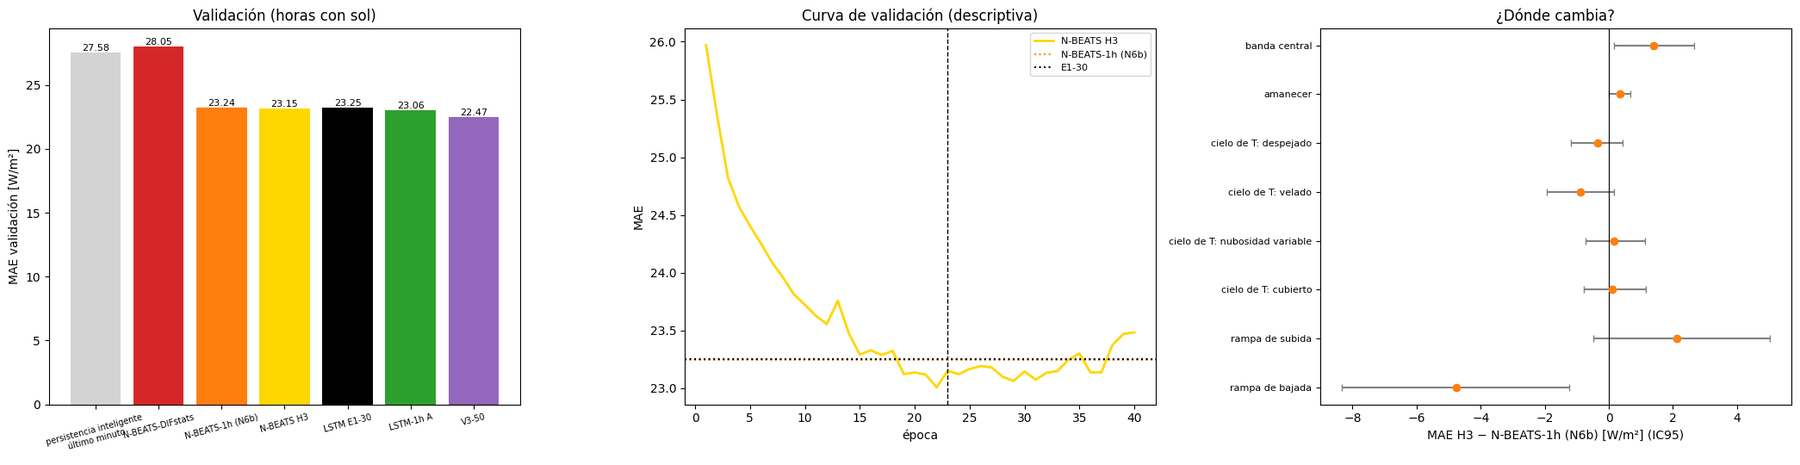


➜ NO SE CONFIRMA: el intento 19 queda igual que la N-BEATS-1h de N6b (-0.09, IC95 [-0.60; +0.44]); sigue la N-BEATS-1h de N6b.
Resultados en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/nbeats/H3_confirmacion_optuna


In [ ]:
import os, time, random, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings("ignore")
try:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
except ImportError:
    pass

BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
DIAG = BASE_DIR / "resultados" / "diagnostico"
RUTA_TABLA = DIAG / "faseB_radiografia_E1" / "tabla_horaria_E1.pkl"
RUTA_L0 = DIAG / "L_entrada_una_hora" / "entrada_una_hora.npz"
RUTA_P2 = DIAG / "nbeats" / "P2_validacion" / "P2_predicciones_validacion.pkl"
RUTA_C8B = DIAG / "faseC_ultimo_minuto" / "C8b_confirmacion" / "C8b_predicciones_validacion.pkl"
RUTA_L3 = DIAG / "L_entrada_una_hora" / "L3_predicciones_validacion.pkl"
SALIDA = DIAG / "nbeats" / "H3_confirmacion_optuna"
RUTA_N6B = DIAG / "nbeats" / "N6b_confirmacion" / "N6b_predicciones_validacion.pkl"
SALIDA.mkdir(parents=True, exist_ok=True)
SEMILLAS = [42, 123, 2024, 7, 99]
EPOCA = 23  # fijada en H2 (Optuna, solo train)
EPOCAS_CURVA = 40  # solo para la curva descriptiva
BATCH, LR, WD = 256, 0.00018320637359866263, 1.1294733377267313e-06  # intento 19
HIDDEN, N_BLOQUES = 256, 3
N_BOOT = 2000
UMBRAL_RAMPA = 97.78

# 1) Datos
L0 = np.load(RUTA_L0)
SEQ = {c: L0[f"seq_{c}"].astype(np.float32) for c in ["train", "validation"]}
ESC = {c: L0[f"esc_{c}"].astype(np.float32) for c in ["train", "validation"]}
Y = {c: L0[f"y_{c}"].astype(np.float32) for c in ["train", "validation"]}
F = {c: pd.DatetimeIndex(L0[f"fechas_{c}"]) for c in ["train", "validation"]}
PI1 = {c: ESC[c][:, 2] for c in ["train", "validation"]}
assert F["train"].max() < F["validation"].min() and F["validation"].max() < pd.Timestamp(
    "2024-10-01"
)
T = pd.read_pickle(RUTA_TABLA).sort_index()
T = T[T.index < pd.Timestamp("2024-10-01")]  # nada del test
for c in ["train", "validation"]:
    assert (T[T["conjunto"] == c].index == F[c]).all(), f"La tabla horaria no cuadra con L0 ({c})"
VA = T[T["conjunto"] == "validation"].copy()
P2, C8, L3, N6B = (
    pd.read_pickle(RUTA_P2),
    pd.read_pickle(RUTA_C8B),
    pd.read_pickle(RUTA_L3),
    pd.read_pickle(RUTA_N6B),
)
for nombre, D in [("P2", P2), ("C8b", C8), ("L3", L3), ("N6b", N6B)]:
    assert (D.index == F["validation"]).all(), f"{nombre} no cuadra con validación"
    assert np.allclose(
        D["real"].to_numpy(float), Y["validation"], atol=1e-3
    ), f"{nombre}: el objetivo no coincide"
# Comprobación de las referencias ANTES de entrenar
m = (VA["regimen"].astype(str) != "noche").to_numpy()
y = Y["validation"][m]
for nombre, p_, esperado in [
    ("N-BEATS-DIFstats", P2["NBEATS_15"], 28.05),
    ("E1-30", C8["E1_30"], 23.25),
    ("V3-50", C8["V3_50"], 22.47),
    ("LSTM-1h A", L3["LSTM-1h A"], 23.06),
    ("N-BEATS-1h (N6b)", N6B["N-BEATS-1h"], 23.24),
]:
    mae_ = np.abs(p_.to_numpy()[m] - y).mean()
    assert (
        abs(mae_ - esperado) < 0.05
    ), f"No se reproduce el MAE de {nombre} ({mae_:.2f} frente a {esperado})"
print(
    "Referencias comprobadas: N-BEATS-DIFstats 28,05 · E1-30 23,25 · V3-50 22,47 · LSTM-1h A 23,06 · N-BEATS-1h (N6b) 23,24"
)
NB, NC, NE = SEQ["train"].shape[1], SEQ["train"].shape[2], ESC["train"].shape[1]
print(
    f"Train {len(Y['train'])} h · validación {len(Y['validation'])} h · secuencia {SEQ['train'].shape[1:]} · escalares {NE}"
)

# 2) Modelo y entrenamiento (misma receta que N6; hiperparámetros del intento 19)
import torch, torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler

class BloqueNB(nn.Module):
    def __init__(self, input_size, hidden_size, backcast_size):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU(),
        )
        self.backcast = nn.Linear(hidden_size, backcast_size)
        self.forecast = nn.Linear(hidden_size, 1)

    def forward(self, x):
        h = self.fc(x)
        return self.backcast(h), self.forecast(h)

class NBEATSUnaHora(nn.Module):
    def __init__(self, n_bloques_t, n_canales, n_esc, hidden_size=128, n_bloques=6):
        super().__init__()
        n_in = n_bloques_t * n_canales + n_esc
        self.blocks = nn.ModuleList(
            [BloqueNB(n_in, hidden_size, n_bloques_t) for _ in range(n_bloques)]
        )

    def forward(self, x_seq, x_esc):
        residuo = x_seq[:, :, 0]
        cov = torch.cat([x_seq[:, :, 1:].permute(0, 2, 1).reshape(x_seq.size(0), -1), x_esc], dim=1)
        total = torch.zeros((x_seq.size(0), 1), dtype=x_seq.dtype)
        for b in self.blocks:
            back, fore = b(torch.cat([residuo, cov], dim=1))
            residuo = residuo - back
            total = total + fore
        return total.squeeze(-1)

def entrenar(semilla):
    """Predicción de validación (PI1 + corrección) en cada época 1…EPOCAS_CURVA (filas = épocas)."""
    r = Y["train"] - PI1["train"]
    s_seq = StandardScaler().fit(SEQ["train"].reshape(-1, NC))
    s_esc = StandardScaler().fit(ESC["train"])
    s_y = StandardScaler().fit(r.reshape(-1, 1))
    tq = lambda Z: torch.from_numpy(
        s_seq.transform(Z.reshape(-1, NC)).reshape(Z.shape).astype(np.float32)
    )
    te = lambda Z: torch.from_numpy(s_esc.transform(Z).astype(np.float32))
    Xs, Xe, Xs_v, Xe_v = (
        tq(SEQ["train"]),
        te(ESC["train"]),
        tq(SEQ["validation"]),
        te(ESC["validation"]),
    )
    r_e = torch.from_numpy(s_y.transform(r.reshape(-1, 1)).ravel().astype(np.float32))
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    torch.use_deterministic_algorithms(True)
    modelo = NBEATSUnaHora(NB, NC, NE, HIDDEN, N_BLOQUES)
    gen = torch.Generator()
    gen.manual_seed(semilla)
    loader = DataLoader(
        TensorDataset(Xs, Xe, r_e), batch_size=BATCH, shuffle=True, generator=gen, num_workers=0
    )
    opt = torch.optim.Adam(modelo.parameters(), lr=LR, weight_decay=WD)
    crit = nn.L1Loss()
    preds = []
    for ep in range(1, EPOCAS_CURVA + 1):
        modelo.train()
        for xs, xe, yb in loader:
            opt.zero_grad(set_to_none=True)
            loss = crit(modelo(xs, xe), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), max_norm=1.0)
            opt.step()
        modelo.eval()
        with torch.no_grad():
            corr = s_y.inverse_transform(modelo(Xs_v, Xe_v).numpy().reshape(-1, 1)).ravel()
        preds.append(np.clip(PI1["validation"] + corr, 0, None))
        if ep == EPOCA:
            torch.save(modelo.state_dict(), SALIDA / f"modelo_NBEATS_H3_ep{EPOCA}_s{semilla}.pt")
    return np.array(preds, dtype=np.float32)

t_ini = time.time()
for k, s in enumerate(SEMILLAS, 1):
    ruta = SALIDA / f"pred_validacion_H3_s{s}.npz"
    if ruta.exists():
        print(f"[{k}/{len(SEMILLAS)}] semilla {s}: ya hecha")
        continue
    t0 = time.time()
    np.savez_compressed(ruta, pred=entrenar(s))
    print(
        f"[{k}/{len(SEMILLAS)}] semilla {s}: {time.time()-t0:.0f} s (total {(time.time()-t_ini)/60:.1f} min)"
    )
P_sem = np.stack(
    [np.load(SALIDA / f"pred_validacion_H3_s{s}.npz")["pred"] for s in SEMILLAS]
)  # semillas × épocas × horas
assert P_sem.shape[:2] == (len(SEMILLAS), EPOCAS_CURVA)
pred_1h = P_sem[:, EPOCA - 1, :].mean(0)
assert (
    np.isfinite(P_sem).all() and pred_1h.shape == Y["validation"].shape
), "Hay predicciones no finitas (¿alguna semilla divergió?)"

# 3) Evaluación (horas con sol)
PRED = {
    "persistencia inteligente del último minuto": PI1["validation"],
    "N-BEATS-DIFstats": P2["NBEATS_15"].to_numpy(),
    "N-BEATS-1h (N6b)": N6B["N-BEATS-1h"].to_numpy(),
    "N-BEATS H3": pred_1h,
    "LSTM E1-30": C8["E1_30"].to_numpy(),
    "V3-50": C8["V3_50"].to_numpy(),
    "LSTM-1h A": L3["LSTM-1h A"].to_numpy(),
}
E = {k: np.abs(p[m] - y) for k, p in PRED.items()}
inf = VA[m].copy()
dias = inf.index.normalize().to_numpy()
u, inv = np.unique(dias, return_inverse=True)
rng = np.random.default_rng(0)
Wb = np.stack(
    [np.bincount(rng.integers(0, len(u), len(u)), minlength=len(u)) for _ in range(N_BOOT)]
)[:, inv].astype(float)

def ic(d, msk=None):
    msk = np.ones(len(d), bool) if msk is None else msk
    v = np.where(msk, d, 0.0)
    b = (Wb @ v) / np.maximum(Wb @ msk.astype(float), 1e-9)
    return d[msk].mean(), np.percentile(b, 2.5), np.percentile(b, 97.5)

def dm(d):
    s = pd.Series(d, index=inf.index).groupby(dias).mean().to_numpy()
    n = len(s)
    dc = s - s.mean()
    L = int(np.floor(n ** (1 / 3)))
    var = dc @ dc / n + sum(2 * (1 - k / (L + 1)) * (dc[k:] @ dc[:-k]) / n for k in range(1, L + 1))
    t = s.mean() / np.sqrt(var / n) * np.sqrt((n - 1) / n)
    return t, 2 * stats.t.sf(abs(t), df=n - 1)

lect = lambda lo, hi: "mejor" if hi < 0 else ("peor" if lo > 0 else "igual")
fmt = lambda lo, hi: f"[{lo:+.2f}; {hi:+.2f}]"
central = inf["banda"].astype(str).str.startswith("central").to_numpy()
d = E["N-BEATS H3"] - E["N-BEATS-1h (N6b)"]
c, lo, hi = ic(d)
cc, lc, hc = ic(d, central)
_, p_dm = dm(d)
ok1, ok2 = hi < 0, lc <= 0
filas = []
for k_ in PRED:
    fila = {
        "modelo": k_,
        "MAE": E[k_].mean(),
        "RMSE": np.sqrt(((PRED[k_][m] - y) ** 2).mean()),
        "sesgo": (PRED[k_][m] - y).mean(),
    }
    if k_ != "N-BEATS-1h (N6b)":
        a, b_, h_ = ic(E[k_] - E["N-BEATS-1h (N6b)"])
        fila.update({"− N-BEATS-1h (N6b)": a, "IC95 (N6b)": fmt(b_, h_)})
    if k_ != "LSTM E1-30":
        a, b_, h_ = ic(E[k_] - E["LSTM E1-30"])
        _, pp = dm(E[k_] - E["LSTM E1-30"])
        fila.update(
            {
                "− E1-30": a,
                "IC95 (E1-30)": fmt(b_, h_),
                "DM p (E1-30)": pp,
                "lectura frente a E1-30": lect(b_, h_),
            }
        )
    filas.append(fila)
R = pd.DataFrame(filas).set_index("modelo")
mae_sem = [np.abs(P_sem[i, EPOCA - 1, m] - y).mean() for i in range(len(SEMILLAS))]
curva = pd.Series(
    [np.abs(P_sem[:, j, :].mean(0)[m] - y).mean() for j in range(EPOCAS_CURVA)],
    index=np.arange(1, EPOCAS_CURVA + 1),
)
cielo = inf["cielo"].astype(str).replace({"nubes rotas": "nubosidad variable"}).to_numpy()
hora = inf.index.hour.to_numpy()
reg = inf["regimen"].astype(str).to_numpy()
dlt = y - T["real"].reindex(inf.index - pd.Timedelta("1h")).to_numpy()
grupos = [
    ("operación", np.ones(len(y), bool)),
    ("banda central", central),
    ("amanecer", (reg == "transicion") & (hora < 12)),
]
grupos += [
    (f"cielo de T: {g}", cielo == g)
    for g in ["despejado", "velado", "nubosidad variable", "cubierto"]
]
grupos += [("rampa de subida", dlt >= UMBRAL_RAMPA), ("rampa de bajada", dlt <= -UMBRAL_RAMPA)]
filas = []
omitidos = [nombre for nombre, msk in grupos if msk.sum() < 30]
if omitidos:
    print("Grupos omitidos del desglose por tener < 30 horas:", ", ".join(omitidos))
for nombre, msk in grupos:
    if msk.sum() >= 30:
        g, gl, gh = ic(d, msk)
        gL, glL, ghL = ic(E["N-BEATS H3"] - E["LSTM E1-30"], msk)
        filas.append(
            {
                "grupo": nombre,
                "horas": int(msk.sum()),
                "MAE N-BEATS-1h (N6b)": E["N-BEATS-1h (N6b)"][msk].mean(),
                "MAE N-BEATS H3": E["N-BEATS H3"][msk].mean(),
                "MAE E1-30": E["LSTM E1-30"][msk].mean(),
                "MAE LSTM-1h A": E["LSTM-1h A"][msk].mean(),
                "H3 − N6b": g,
                "IC95": fmt(gl, gh),
                "lectura": lect(gl, gh),
                "H3 − E1-30": gL,
                "IC95 frente a E1-30": fmt(glL, ghL),
            }
        )
G = pd.DataFrame(filas).set_index("grupo")
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)
print(
    "\n"
    + "=" * 110
    + f"\nH3 · N-BEATS (intento 19 de Optuna) EN VALIDACIÓN (ago–sep 2024, horas con sol, media de 5 semillas, época {EPOCA})\n"
    + "=" * 110
)
display(R.round(3))
print(
    f"\nCriterio 1 · N-BEATS H3 − N-BEATS-1h (N6b) = {c:+.2f} W/m², IC95 [{lo:+.2f}; {hi:+.2f}], DM p = {p_dm:.4f} → {lect(lo, hi).upper()}"
)
print(
    f"Criterio 2 · banda central: {cc:+.2f} W/m², IC95 [{lc:+.2f}; {hc:+.2f}] → {'no empeora' if ok2 else 'EMPEORA'}"
)
extra = {}
for k_ in ["LSTM-1h A", "V3-50", "LSTM E1-30", "N-BEATS-DIFstats"]:
    a, b_, h_ = ic(E["N-BEATS H3"] - E[k_])
    _, pp = dm(E["N-BEATS H3"] - E[k_])
    extra[k_] = (a, b_, h_, pp)
    print(
        f"Informativo · N-BEATS H3 − {k_}: {a:+.2f} W/m², IC95 [{b_:+.2f}; {h_:+.2f}], DM p = {pp:.4f} → {lect(b_, h_)}"
    )
print(
    "Informativo · MAE por semilla: "
    + " · ".join(f"{s}: {v:.2f}" for s, v in zip(SEMILLAS, mae_sem))
)
print("\nDesglose (IC95 sin ajustar; no decide):")
display(G.round(2))
print(f"\nCurva de validación por época (SOLO descriptiva; la época {EPOCA} estaba fijada):")
print("   " + " · ".join(f"{e}: {v:.2f}" for e, v in curva.items()))
fig, axs = plt.subplots(1, 3, figsize=(21, 5.5))
orden = [
    "persistencia inteligente del último minuto",
    "N-BEATS-DIFstats",
    "N-BEATS-1h (N6b)",
    "N-BEATS H3",
    "LSTM E1-30",
    "LSTM-1h A",
    "V3-50",
]
axs[0].bar(
    range(len(orden)),
    [E[k_].mean() for k_ in orden],
    color=["lightgray", "tab:red", "tab:orange", "gold", "black", "tab:green", "tab:purple"],
)
for i, k_ in enumerate(orden):
    axs[0].text(i, E[k_].mean(), f"{E[k_].mean():.2f}", ha="center", va="bottom", fontsize=8)
axs[0].set_xticks(range(len(orden)))
axs[0].set_xticklabels(
    [o.replace(" del último minuto", "\núltimo minuto") for o in orden], fontsize=7, rotation=15
)
axs[0].set_ylabel("MAE validación [W/m²]")
axs[0].set_title("Validación (horas con sol)")
axs[1].plot(curva.index, curva.values, color="gold", lw=2, label="N-BEATS H3")
axs[1].axvline(EPOCA, color="k", ls="--", lw=1)
axs[1].axhline(E["N-BEATS-1h (N6b)"].mean(), color="tab:orange", ls=":", label="N-BEATS-1h (N6b)")
axs[1].axhline(E["LSTM E1-30"].mean(), color="black", ls=":", label="E1-30")
axs[1].set_xlabel("época")
axs[1].set_ylabel("MAE")
axs[1].legend(fontsize=8)
axs[1].set_title("Curva de validación (descriptiva)")
sub = G.drop(index="operación")
yy = np.arange(len(sub))
lim = sub["IC95"].str.strip("[]").str.split(";", expand=True).astype(float)
axs[2].errorbar(
    sub["H3 − N6b"],
    yy,
    xerr=[sub["H3 − N6b"] - lim[0], lim[1] - sub["H3 − N6b"]],
    fmt="o",
    color="tab:orange",
    ecolor="gray",
    capsize=3,
)
axs[2].axvline(0, color="k", lw=0.8)
axs[2].set_yticks(yy)
axs[2].set_yticklabels(sub.index, fontsize=8)
axs[2].invert_yaxis()
axs[2].set_xlabel("MAE H3 − N-BEATS-1h (N6b) [W/m²] (IC95)")
axs[2].set_title("¿Dónde cambia?")
plt.tight_layout()
plt.savefig(SALIDA / "H3_confirmacion.png", dpi=120)
plt.show()
if ok1 and ok2:
    ver = (
        f"CONFIRMADA: el intento 19 mejora a la N-BEATS-1h de N6b en validación ({c:+.2f} W/m², IC95 [{lo:+.2f}; {hi:+.2f}]) "
        f"sin empeorar la banda central. El intento 19 pasa a ser la N-BEATS final (MAE {E['N-BEATS H3'].mean():.2f})."
    )
elif ok1:
    ver = f"MEJORA EN OPERACIÓN PERO EMPEORA LA BANDA CENTRAL ({cc:+.2f}, IC95 [{lc:+.2f}; {hc:+.2f}]): no se confirma; sigue la N-BEATS-1h de N6b."
elif lo > 0:
    ver = f"NO SE CONFIRMA: el intento 19 es peor que la N-BEATS-1h de N6b ({c:+.2f}, IC95 [{lo:+.2f}; {hi:+.2f}]); sigue la N-BEATS-1h de N6b."
else:
    ver = f"NO SE CONFIRMA: el intento 19 queda igual que la N-BEATS-1h de N6b ({c:+.2f}, IC95 [{lo:+.2f}; {hi:+.2f}]); sigue la N-BEATS-1h de N6b."
print("\n➜ " + ver)
R.to_csv(SALIDA / "H3_resumen.csv")
G.to_csv(SALIDA / "H3_desglose.csv")
curva.rename("MAE_validacion").to_csv(SALIDA / "H3_curva_validacion.csv")
pd.DataFrame({"semilla": SEMILLAS, "MAE": mae_sem}).to_csv(
    SALIDA / "H3_por_semilla.csv", index=False
)
pd.DataFrame({**PRED, "real": Y["validation"]}, index=F["validation"]).to_pickle(
    SALIDA / "H3_predicciones_validacion.pkl"
)
(SALIDA / "H3_veredicto.txt").write_text(
    ver
    + f"\nBanda central: {cc:+.2f}, IC95 [{lc:+.2f}; {hc:+.2f}] · DM p (operación) = {p_dm:.4f}\n",
    encoding="utf-8",
)
crit = [
    {
        "comparación": "H3 − N-BEATS-1h N6b (operación)",
        "cambio": c,
        "IC95 inf": lo,
        "IC95 sup": hi,
        "DM p": p_dm,
        "criterio 1": ok1,
    },
    {
        "comparación": "H3 − N-BEATS-1h N6b (banda central)",
        "cambio": cc,
        "IC95 inf": lc,
        "IC95 sup": hc,
        "criterio 2": ok2,
    },
]
crit += [
    {
        "comparación": f"H3 − {k_} (informativo)",
        "cambio": v[0],
        "IC95 inf": v[1],
        "IC95 sup": v[2],
        "DM p": v[3],
    }
    for k_, v in extra.items()
]
pd.DataFrame(crit).to_csv(SALIDA / "H3_criterio.csv", index=False)
print("Resultados en:", SALIDA)

**Resultados.** El intento 19 obtiene 23,15 W/m², −0,09 W/m² frente a N-BEATS-1h (IC95 [−0,60; +0,44]), y empeora la banda central (+1,40 W/m², IC95 [+0,17; +2,67]): no se confirma y N-BEATS-1h sigue siendo la N-BEATS final. Las cinco semillas dan entre 23,35 y 23,84 W/m², y frente a E1-30 la diferencia es de −0,10 W/m² (IC95 [−1,15; +0,95]). En el desglose descriptivo, el intento 19 tiene menos error en las rampas de bajada (−4,76 W/m², IC95 [−8,34; −1,24]) y un sesgo de −5,16 W/m², frente a −3,02 W/m² de N-BEATS-1h.

## 8. Bandas de incertidumbre

> *Las bandas de incertidumbre de la N-BEATS (N7) quedan fuera del alcance de la memoria (fase 38 de la Tabla A1), igual que sus criterios de aceptación; no cambian ningún modelo. Sí se utiliza la tabla de referencias de la salida: las mejoras de la N-BEATS-1h sobre la persistencia simple (48,4 %) y sobre la inteligente horaria (28,8 %), que el apartado 6.1 resume, junto con las de E1-30, como un 48 % y un 29 %.*

### 8.1 Bandas de incertidumbre de la N-BEATS-1h

Se calculan bandas de predicción al 80 % y al 90 % para la N-BEATS-1h con el mismo método que se aplicó a E1-30 (D1): un modelo de riesgo (HGB con siete variables conocidas al predecir) normaliza una calibración conformal hecha con los errores fuera de muestra de la N-BEATS-1h en los siete meses de entrenamiento (un mes fuera cada vez, semillas 42 y 123, época 5). Las bandas se evalúan en validación, en las horas con sol, frente a una banda de ancho fijo y con los mismos criterios que las de la LSTM.

0) COMPROBACIONES
   ✔ todos los archivos están en Drive
   ✔ el entrenamiento reproduce N6 (2024-01, semilla 42): diferencia máxima 0.00e+00 W/m²
   entrenado 2024-02 · semilla 42 (7 s)
   entrenado 2024-02 · semilla 123 (12 s)
   entrenado 2024-04 · semilla 42 (17 s)
   entrenado 2024-04 · semilla 123 (23 s)
   entrenado 2024-06 · semilla 42 (28 s)
   entrenado 2024-06 · semilla 123 (32 s)
   ✔ OOF de la N-BEATS-1h en los 7 meses · control: en los 4 meses de N6 da 24.20 W/m² (esperado 24,20)
   MAE fuera de muestra por mes (horas con sol): 2024-01: 8.76 · 2024-02: 16.15 · 2024-03: 23.01 · 2024-04: 30.17 · 2024-05: 28.48 · 2024-06: 32.20 · 2024-07: 29.96
   ✔ N-BEATS-1h en validación (N6b, 5 semillas): MAE 23.24 W/m² (esperado 23.24)

1) Convención horaria: desfase +30 min (diferencia media con el canal de elevación 0.09°)

2) Modelo de riesgo: suelo de σ̂ = 0.66 W/m² · semilla 0 vs 42: diferencia máxima 0.000000 W/m² (determinista ✔)
3) Nivel 80%: q(D1) = 1.967 · q(ancho fijo) = 41.6

,cobertura D1 (%),cobertura fijo (%),ancho D1,ancho fijo,Winkler D1,Winkler fijo,cambio Winkler (D1 − fijo),IC95,peor grupo controlado,1 cobertura global,2 cobertura por grupo,3 Winkler mejor,4 Spearman > 0,veredicto
nivel,,,,,,,,,,,,,,
80%,81.11,80.09,78.67,77.59,114.11,133.68,-19.57,"[-25.69, -13.73]",cielo: nubosidad variable (74.7 %),True,False,True,True,NO SE ACEPTA
90%,90.05,89.82,108.07,121.02,143.80,165.71,-21.91,"[-32.43, -10.63]",cielo: velado (85.4 %),True,True,True,True,SE ACEPTA D1


Spearman entre σ̂ y el error real: ρ = 0.62 (p = 9.8e-97)

Cobertura por grupo (%):


nivel                           80%         90%      
método                           D1  fijo    D1  fijo
grupo                                                
GLOBAL                         81.1  80.1  90.0  89.8
régimen: transicion            85.7  93.3  90.8  93.3
régimen: completamente_diurno  80.4  78.0  89.9  89.3
amanecer                       93.3  98.3  98.3  98.3
banda: central >40°            80.0  64.4  89.3  79.0
banda: hombros ≤20°            80.8  94.4  90.0  97.3
banda: intermedia 20–40°       82.1  75.3  90.6  88.8
cielo: amanecer/atardecer      85.7  93.3  90.8  93.3
cielo: cubierto                79.2  81.1  94.3  88.7
cielo: despejado               95.7  94.1  98.9  97.8
cielo: nubosidad variable      74.7  69.2  86.5  84.5
cielo: velado                  77.5  86.5  85.4  95.5

Ancho medio por grupo [W/m²] (D1 debería ser estrecho con cielo estable y ancho con nubes):


nivel                            80%          90%       
método                            D1  fijo     D1   fijo
grupo                                                   
GLOBAL                          78.7  77.6  108.1  121.0
régimen: transicion             11.8  49.0   14.7   73.7
régimen: completamente_diurno   89.1  82.0  122.6  128.4
amanecer                        14.7  48.8   18.0   73.5
banda: central >40°            123.0  83.3  169.5  132.7
banda: hombros ≤20°             33.0  68.4   44.8  102.5
banda: intermedia 20–40°        97.5  83.3  134.2  132.5
cielo: amanecer/atardecer       11.8  49.0   14.7   73.7
cielo: cubierto                 97.9  82.0  132.2  127.4
cielo: despejado                58.9  83.2   81.2  131.8
cielo: nubosidad variable      104.2  82.6  143.7  129.6
cielo: velado                   72.0  76.8   99.0  116.2

Referencias para la memoria (validación, horas con sol):


,MAE [W/m²],ventaja de la N-BEATS-1h (%)
N-BEATS-1h (5 semillas),23.24,0.00
persistencia simple,45.03,48.39
persistencia inteligente,32.63,28.78


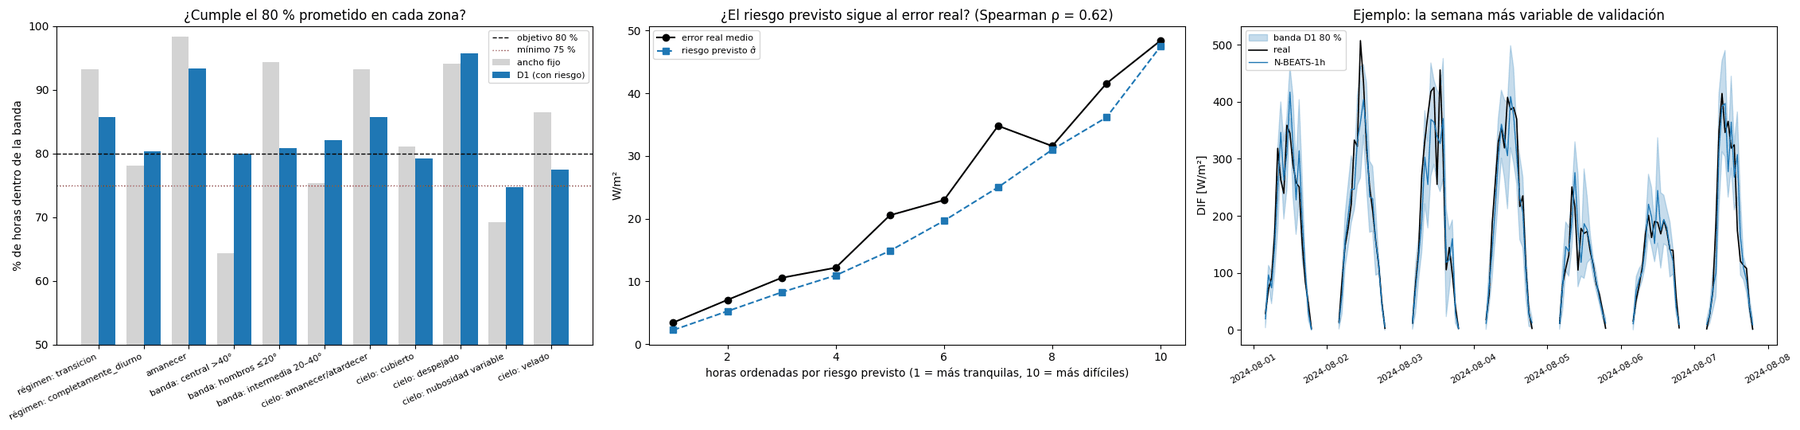


N7 · BANDAS DE INCERTIDUMBRE PARA LA N-BEATS-1h (validación ago–sep 2024, horas con sol)
80%: cobertura D1 81.1 % · ancho medio 78.7 W/m² (fijo 77.6) · Winkler -19.57 [-25.69, -13.73] · peor grupo cielo: nubosidad variable (74.7 %) → NO SE ACEPTA
90%: cobertura D1 90.0 % · ancho medio 108.1 W/m² (fijo 121.0) · Winkler -21.91 [-32.43, -10.63] · peor grupo cielo: velado (85.4 %) → SE ACEPTA D1
Spearman σ̂ vs error real: 0.62
MAE N-BEATS-1h 23.24 · persistencia 45.03 · persistencia inteligente 32.63 W/m²

Informativo · bandas de la LSTM E1-30 (D1), mismo método:


,cobertura D1 (%),ancho D1,Winkler D1,peor grupo controlado,veredicto
nivel,,,,,
80%,82.81,82.11,113.78,banda: central >40° (81.0 %),SE ACEPTA D1
90%,91.52,114.85,142.44,banda: hombros ≤20° (91.4 %),SE ACEPTA D1



Resultados en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/nbeats/N7_bandas


In [ ]:
import os, sys, subprocess, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
try:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
except ImportError:
    pass
try:
    import pvlib
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pvlib"], check=True)
    import pvlib
from scipy.stats import spearmanr
from sklearn.ensemble import HistGradientBoostingRegressor
import joblib, random, time
BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
DIAG = BASE_DIR / "resultados" / "diagnostico"
RUTA_NPZ = (
    BASE_DIR
    / "resultados"
    / "ejecuciones"
    / "preparacion_bloque_difstats_20261006_180841"
    / "matrices_dif_elev_difstats.npz"
)
RUTA_INTRA = DIAG / "fase1_intrahoraria" / "variables_intrahorarias_horarias.csv"
RUTA_TABLA = DIAG / "faseB_radiografia_E1" / "tabla_horaria_E1.pkl"
SALIDA = DIAG / "nbeats" / "N7_bandas"
RUTA_L0 = DIAG / "L_entrada_una_hora" / "entrada_una_hora.npz"
DIR_N6 = DIAG / "nbeats" / "N6_entrada_una_hora" / "predicciones"
RUTA_N6B = DIAG / "nbeats" / "N6b_confirmacion" / "N6b_predicciones_validacion.pkl"
RUTA_D1 = DIAG / "D1_bandas" / "D1_resumen.csv"
DIR_P = SALIDA / "oof_nbeats_1h"
SALIDA.mkdir(parents=True, exist_ok=True)
DIR_P.mkdir(parents=True, exist_ok=True)
NIVELES = [0.80, 0.90]  # 80 % principal · 90 % secundario
N_BOOT = 2000
LAT, LON, ALT = 51.9711, 4.9267, 0  # Cabauw (BSRN CAB)
MAE_NB_VAL = 23.24  # N-BEATS-1h de N6b en validación
SEMILLAS_OOF = [42, 123]  # como los OOF de E1-30 en P1
EPOCA = 5
BATCH, LR, WD, HIDDEN, N_BLOQUES = 128, 1e-3, 1e-5, 128, 6
MESES_N6 = ["2024-01", "2024-03", "2024-05", "2024-07"]

# 0) Comprobaciones antes de calcular nada
print("0) COMPROBACIONES")
faltan = [
    str(r)
    for r in [RUTA_NPZ, RUTA_INTRA, RUTA_TABLA, RUTA_L0, RUTA_N6B]
    + [DIR_N6 / f"NB1h_{m}_s{s}.npz" for m in MESES_N6 for s in SEMILLAS_OOF]
    if not r.exists()
]
assert not faltan, "No encuentro:\n  " + "\n  ".join(faltan)
print("   ✔ todos los archivos están en Drive")
mat = np.load(RUTA_NPZ)
X_tr, X_va = mat["X_train_DIF_elev_DIFstats_raw"], mat["X_validation_DIF_elev_DIFstats_raw"]
y_tr = mat["y_train_difstats"].astype(float).reshape(-1)
y_va = mat["y_validation_difstats"].astype(float).reshape(-1)
f_tr, f_va = pd.DatetimeIndex(mat["fechas_train"]), pd.DatetimeIndex(mat["fechas_validation"])
assert f_va.max() < pd.Timestamp("2024-10-01"), "Esto incluiría el test"
T = pd.read_pickle(RUTA_TABLA)
T = T[T.index < pd.Timestamp("2024-10-01")]
TR, VA = T[T["conjunto"] == "train"].copy(), T[T["conjunto"] == "validation"].copy()
assert (TR.index == f_tr).all() and (
    VA.index == f_va
).all(), "La tabla horaria no cuadra con el .npz"
sol_tr = (TR["regimen"] != "noche").to_numpy()
sol_va = (VA["regimen"] != "noche").to_numpy()

# ---- Parte 0 · OOF de la N-BEATS-1h en los 7 meses (misma receta y pliegues que N6) ----
L0 = np.load(RUTA_L0)
SEQ, ESC = L0["seq_train"].astype(np.float32), L0["esc_train"].astype(np.float32)
y_l0 = L0["y_train"].astype(np.float32)
f_l0 = pd.DatetimeIndex(L0["fechas_train"])
assert (f_l0 == f_tr).all() and np.allclose(
    y_l0, y_tr, atol=1e-3
), "entrada_una_hora.npz no cuadra con train"
PI1 = ESC[:, 2]
mes = f_tr.to_period("M").astype(str).to_numpy()
mes = np.where(mes == "2023-12", "2024-01", mes)
MESES = sorted(np.unique(mes))

def pliegue(m):
    fuera = mes == m
    fin = f_tr[fuera].max()
    purga = (f_tr > fin) & (f_tr <= fin + pd.Timedelta("24h"))
    return ~fuera & ~purga, fuera

NB, NC, NE = SEQ.shape[1], SEQ.shape[2], ESC.shape[1]
import torch, torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler

class BloqueNB(nn.Module):
    def __init__(self, input_size, hidden_size, backcast_size):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU(),
        )
        self.backcast = nn.Linear(hidden_size, backcast_size)
        self.forecast = nn.Linear(hidden_size, 1)

    def forward(self, x):
        h = self.fc(x)
        return self.backcast(h), self.forecast(h)

class NBEATSUnaHora(nn.Module):
    def __init__(self, n_bloques_t, n_canales, n_esc, hidden_size=128, n_bloques=6):
        super().__init__()
        n_in = n_bloques_t * n_canales + n_esc
        self.blocks = nn.ModuleList(
            [BloqueNB(n_in, hidden_size, n_bloques_t) for _ in range(n_bloques)]
        )

    def forward(self, x_seq, x_esc):
        residuo = x_seq[:, :, 0]
        cov = torch.cat([x_seq[:, :, 1:].permute(0, 2, 1).reshape(x_seq.size(0), -1), x_esc], dim=1)
        total = torch.zeros((x_seq.size(0), 1), dtype=x_seq.dtype)
        for b in self.blocks:
            back, fore = b(torch.cat([residuo, cov], dim=1))
            residuo = residuo - back
            total = total + fore
        return total.squeeze(-1)

def entrenar(entrena, fuera, semilla):
    """Igual que entrenar() de N6, hasta la época 5: predicción del mes no visto en cada época (filas = épocas 1…5)."""
    r = y_l0 - PI1
    s_seq = StandardScaler().fit(SEQ[entrena].reshape(-1, NC))
    s_esc = StandardScaler().fit(ESC[entrena])
    s_y = StandardScaler().fit(r[entrena].reshape(-1, 1))
    tq = lambda Z: torch.from_numpy(
        s_seq.transform(Z.reshape(-1, NC)).reshape(Z.shape).astype(np.float32)
    )
    te = lambda Z: torch.from_numpy(s_esc.transform(Z).astype(np.float32))
    Xs, Xe, Xs_f, Xe_f = tq(SEQ[entrena]), te(ESC[entrena]), tq(SEQ[fuera]), te(ESC[fuera])
    r_e = torch.from_numpy(s_y.transform(r[entrena].reshape(-1, 1)).ravel().astype(np.float32))
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    torch.use_deterministic_algorithms(True)
    modelo = NBEATSUnaHora(NB, NC, NE, HIDDEN, N_BLOQUES)
    gen = torch.Generator()
    gen.manual_seed(semilla)
    loader = DataLoader(
        TensorDataset(Xs, Xe, r_e), batch_size=BATCH, shuffle=True, generator=gen, num_workers=0
    )
    opt = torch.optim.Adam(modelo.parameters(), lr=LR, weight_decay=WD)
    crit = nn.L1Loss()
    preds = []
    for ep in range(1, EPOCA + 1):
        modelo.train()
        for xs, xe, yb in loader:
            opt.zero_grad(set_to_none=True)
            loss = crit(modelo(xs, xe), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), max_norm=1.0)
            opt.step()
        modelo.eval()
        with torch.no_grad():
            corr = s_y.inverse_transform(modelo(Xs_f, Xe_f).numpy().reshape(-1, 1)).ravel()
        preds.append(np.clip(PI1[fuera] + corr, 0, None))
    return np.array(preds, dtype=np.float32)


# Control del código de entrenamiento: reentrena un pliegue de N6 y debe reproducir sus predicciones de las épocas 1–5
ref_n6 = np.load(DIR_N6 / "NB1h_2024-01_s42.npz")["pred"][:EPOCA]
rep_n7 = entrenar(*pliegue("2024-01"), 42)
dif_rep = float(np.abs(rep_n7 - ref_n6).max())
assert (
    dif_rep < 0.5
), f"El entrenamiento de N7 no reproduce N6 (diferencia máxima {dif_rep:.4f} W/m²)"
print(
    f"   ✔ el entrenamiento reproduce N6 (2024-01, semilla 42): diferencia máxima {dif_rep:.2e} W/m²"
)
oof = np.zeros(len(y_tr))
t0 = time.time()
for m in MESES:
    entrena, fuera = pliegue(m)
    acum = np.zeros(int(fuera.sum()))
    for s in SEMILLAS_OOF:
        if m in MESES_N6:
            p_ = np.load(DIR_N6 / f"NB1h_{m}_s{s}.npz")["pred"][EPOCA - 1]  # de N6 (época 5)
        else:
            ruta = DIR_P / f"NB1h_{m}_s{s}.npz"
            if not ruta.exists():
                np.savez_compressed(ruta, pred=entrenar(entrena, fuera, s))
                print(f"   entrenado {m} · semilla {s} ({time.time()-t0:.0f} s)")
            p_ = np.load(ruta)["pred"][EPOCA - 1]
        assert p_.shape == (int(fuera.sum()),) and np.isfinite(p_).all()
        acum += p_ / len(SEMILLAS_OOF)
    oof[fuera] = acum
crib = np.isin(mes, MESES_N6) & sol_tr
mae_crib = np.abs(oof[crib] - y_tr[crib]).mean()
assert (
    abs(mae_crib - 24.20) < 0.05
), f"Los OOF de los meses de N6 no reproducen su MAE ({mae_crib:.2f})"
print(
    f"   ✔ OOF de la N-BEATS-1h en los 7 meses · control: en los 4 meses de N6 da {mae_crib:.2f} W/m² (esperado 24,20)"
)
print(
    "   MAE fuera de muestra por mes (horas con sol): "
    + " · ".join(
        f"{m}: {np.abs(oof[(mes == m) & sol_tr] - y_tr[(mes == m) & sol_tr]).mean():.2f}"
        for m in MESES
    )
)
OOF = pd.DataFrame({"OOF_media": oof, "mes_pliegue": mes, "real": y_tr}, index=f_tr)
OOF.to_pickle(SALIDA / "N7_oof_nbeats_1h_epoca5.pkl")
N6B = pd.read_pickle(RUTA_N6B)
assert (N6B.index == f_va).all() and np.allclose(N6B["real"].to_numpy(float), y_va, atol=1e-3)
pred_va = N6B["N-BEATS-1h"].to_numpy(float)
mae_va = np.abs(pred_va[sol_va] - y_va[sol_va]).mean()
assert (
    abs(mae_va - MAE_NB_VAL) < 0.05
), f"Las predicciones de validación no reproducen el MAE de la N-BEATS-1h ({mae_va:.2f})"
print(
    f"   ✔ N-BEATS-1h en validación (N6b, 5 semillas): MAE {mae_va:.2f} W/m² (esperado {MAE_NB_VAL})"
)

# 1) Variables del modelo de riesgo (solo información conocida antes de predecir)
loc = pvlib.location.Location(LAT, LON, tz="UTC", altitude=ALT)

def a_utc(f):
    f = pd.DatetimeIndex(f)
    return f.tz_localize("UTC") if f.tz is None else f.tz_convert("UTC")


# ¿A qué momento de la hora corresponde cada fecha? Se elige el desfase que reproduce el canal de elevación
# de la última hora de la ventana (T−1); así la elevación de la hora objetivo se calcula con la misma convención.
elev_T1 = np.concatenate([X_tr[:, -1, 1], X_va[:, -1, 1]]).astype(float)
f_T1 = a_utc(np.concatenate([f_tr, f_va])) - pd.Timedelta("1h")
ok = elev_T1 > 5
dif_desfase = {
    d: np.abs(
        loc.get_solarposition(f_T1 + pd.Timedelta(minutes=d))["apparent_elevation"].to_numpy()[ok]
        - elev_T1[ok]
    ).mean()
    for d in (-30, 0, 30)
}
DESFASE = min(dif_desfase, key=dif_desfase.get)
print(
    f"\n1) Convención horaria: desfase {DESFASE:+d} min (diferencia media con el canal de elevación {dif_desfase[DESFASE]:.2f}°)"
)
assert dif_desfase[DESFASE] < 1.5, f"La elevación de pvlib no cuadra con la del .npz: {dif_desfase}"
intra = pd.read_csv(RUTA_INTRA, index_col=0, parse_dates=True).asfreq("h")

def variables(X, fechas, pred):
    f = a_utc(fechas) + pd.Timedelta(minutes=DESFASE)
    previa = intra.reindex(pd.DatetimeIndex(fechas) - pd.Timedelta("1h"))
    V = pd.DataFrame(
        {
            "elevacion_objetivo": loc.get_solarposition(f)["apparent_elevation"].to_numpy(),
            "prediccion": pred,
            "DIF_media_T1": X[:, -1, 0],
            "DIF_std_T1": X[:, -1, 2],
            "DIF_rango_T1": X[:, -1, 3],
            "DIF_saltos_T1": previa["DIF_saltos"]
            .fillna(0)
            .to_numpy(),  # mismo relleno que en las entradas de E1
            "SWD_cv_T1": previa["SWD_cv"].fillna(0).to_numpy(),
        },
        index=fechas,
    )
    cs = loc.get_clearsky(f, model="ineichen")["dhi"].to_numpy()
    cs_T1 = loc.get_clearsky(f - pd.Timedelta("1h"), model="ineichen")["dhi"].to_numpy()
    return V.astype(float), cs, cs_T1

V_tr, cs_tr, cs1_tr = variables(X_tr, f_tr, OOF["OOF_media"].to_numpy())
V_va, cs_va, cs1_va = variables(X_va, f_va, pred_va)


# Persistencia inteligente (referencia para la memoria): DIF(T−1) · DIFcs(T) / DIFcs(T−1)
# Si el cielo despejado en T−1 es casi 0 (amanecer), se usa la persistencia simple.
def pers_inteligente(V, cs, cs1):
    p = V["DIF_media_T1"].to_numpy() * np.where(cs1 > 5, cs / np.maximum(cs1, 5), 1.0)
    return np.clip(p, 0, None)

pi_va = pers_inteligente(V_va, cs_va, cs1_va)


# 2) Modelo de riesgo: aprende el TAMAÑO del error de la N-BEATS-1h
def nuevo_riesgo(semilla=0):
    return HistGradientBoostingRegressor(
        loss="absolute_error",
        max_iter=200,
        learning_rate=0.05,
        min_samples_leaf=50,
        early_stopping=False,
        random_state=semilla,
    )

Vs, err_tr = V_tr[sol_tr], np.abs(y_tr - OOF["OOF_media"].to_numpy())[sol_tr]
mes_s, f_s = OOF["mes_pliegue"].to_numpy()[sol_tr], f_tr[sol_tr]
SUELO = float(np.percentile(err_tr, 5))

# Fase A · σ̂ honesto en train: cada mes lo estima un modelo que no lo ha visto (purga de 24 h)
sig_oof = np.full(len(Vs), np.nan)
for m in MESES:
    fuera = mes_s == m
    fin = f_s[fuera].max()
    entrena = ~fuera & ~((f_s > fin) & (f_s <= fin + pd.Timedelta("24h")))
    sig_oof[fuera] = nuevo_riesgo().fit(Vs[entrena], err_tr[entrena]).predict(Vs[fuera])
sig_oof = np.maximum(sig_oof, SUELO)

# Fase B · modelo final con todo train → σ̂ de validación
riesgo = nuevo_riesgo(0).fit(Vs, err_tr)
sig_va = np.maximum(riesgo.predict(V_va[sol_va]), SUELO)
dif_sem = np.abs(
    sig_va - np.maximum(nuevo_riesgo(42).fit(Vs, err_tr).predict(V_va[sol_va]), SUELO)
).max()
print(
    f"\n2) Modelo de riesgo: suelo de σ̂ = {SUELO:.2f} W/m² · semilla 0 vs 42: diferencia máxima {dif_sem:.6f} W/m² "
    f"({'determinista ✔' if dif_sem < 1e-9 else 'NO determinista'})"
)
joblib.dump(
    {"modelo": riesgo, "suelo": SUELO, "desfase_min": DESFASE, "variables": list(V_tr.columns)},
    SALIDA / "N7_modelo_riesgo.joblib",
)


# 3) Calibración conformal (en train) y bandas (en validación)
def cuantil_conformal(s, nivel):
    n = len(s)
    return float(np.quantile(s, min(1.0, np.ceil((n + 1) * nivel) / n), method="higher"))

y, p = y_va[sol_va], pred_va[sol_va]
e_va = np.abs(y - p)
BANDAS, Q = {}, {}
for nivel in NIVELES:
    q_d1 = cuantil_conformal(err_tr / sig_oof, nivel)  # D1: puntuación normalizada
    q_fijo = cuantil_conformal(err_tr, nivel)  # referencia: ancho fijo
    Q[nivel] = (q_d1, q_fijo)
    BANDAS[("D1", nivel)] = (np.maximum(0, p - q_d1 * sig_va), p + q_d1 * sig_va)
    BANDAS[("fijo", nivel)] = (np.maximum(0, p - q_fijo), p + np.full_like(p, q_fijo))
    cob_tr = np.mean(err_tr <= q_d1 * sig_oof)
    print(
        f"3) Nivel {nivel:.0%}: q(D1) = {q_d1:.3f} · q(ancho fijo) = {q_fijo:.2f} W/m² · cobertura en train de D1 {cob_tr:.1%} (por construcción)"
    )

def winkler(L, U, y, alfa):
    return (U - L) + (2 / alfa) * np.clip(L - y, 0, None) + (2 / alfa) * np.clip(y - U, 0, None)


# 4) Evaluación en validación
inf = VA[sol_va]
hora = inf.index.hour.to_numpy()
GRUPOS = {"GLOBAL": np.ones(len(y), bool)}
for g in ["transicion", "completamente_diurno"]:
    GRUPOS[f"régimen: {g}"] = (inf["regimen"] == g).to_numpy()
GRUPOS["amanecer"] = (inf["regimen"] == "transicion").to_numpy() & (hora < 12)
for g in sorted(inf["banda"].astype(str).unique()):
    GRUPOS[f"banda: {g}"] = (inf["banda"].astype(str) == g).to_numpy()
NOMBRE_CIELO = {"nubes rotas": "nubosidad variable"}
for g in sorted(inf["cielo"].astype(str).unique()):
    if g != "noche":
        GRUPOS[f"cielo: {NOMBRE_CIELO.get(g, g)}"] = (inf["cielo"].astype(str) == g).to_numpy()
MIN_HORAS = (
    50  # un grupo con menos horas se informa, pero no decide (su cobertura sería demasiado ruidosa)
)
CONTROLADOS = [
    k
    for k in GRUPOS
    if (k.startswith(("régimen", "banda", "cielo")) or k == "amanecer")
    and GRUPOS[k].sum() >= MIN_HORAS
]
print(
    "   Grupos que deciden el criterio 2:",
    ", ".join(f"{k} ({GRUPOS[k].sum()} h)" for k in CONTROLADOS),
)
pocos = [k for k in GRUPOS if k != "GLOBAL" and k not in CONTROLADOS]
if pocos:
    print(
        f"   Con menos de {MIN_HORAS} horas (solo se informan):",
        ", ".join(f"{k} ({GRUPOS[k].sum()} h)" for k in pocos),
    )

u, inv = np.unique(inf.index.normalize(), return_inverse=True)
dias = [np.where(inv == i)[0] for i in range(len(u))]
rng = np.random.default_rng(0)
remuestras = [
    np.concatenate([dias[i] for i in rng.integers(0, len(dias), len(dias))]) for _ in range(N_BOOT)
]

def ic(d):
    medias = [d[r].mean() for r in remuestras]
    return d.mean(), np.percentile(medias, 2.5), np.percentile(medias, 97.5)

rho, p_rho = spearmanr(sig_va, e_va)
filas_res, filas_des, veredictos = [], [], {}
for nivel in NIVELES:
    alfa = 1 - nivel
    w = {}
    for metodo in ["D1", "fijo"]:
        L, U = BANDAS[(metodo, nivel)]
        dentro = (y >= L) & (y <= U)
        w[metodo] = winkler(L, U, y, alfa)
        for g, msk in GRUPOS.items():
            filas_des.append(
                {
                    "nivel": f"{nivel:.0%}",
                    "método": metodo,
                    "grupo": g,
                    "horas": int(msk.sum()),
                    "cobertura (%)": 100 * dentro[msk].mean(),
                    "ancho medio [W/m²]": (U - L)[msk].mean(),
                    "Winkler": w[metodo][msk].mean(),
                }
            )
    D = pd.DataFrame([f for f in filas_des if f["nivel"] == f"{nivel:.0%}"])
    d1 = D[D["método"] == "D1"].set_index("grupo")
    c, lo, hi = ic(w["D1"] - w["fijo"])
    obj = 100 * nivel
    ok1 = obj - 3 <= d1.loc["GLOBAL", "cobertura (%)"] <= obj + 3
    ok2 = (d1.loc[CONTROLADOS, "cobertura (%)"] >= obj - 5).all()
    ok3 = hi < 0
    ok4 = rho > 0
    veredictos[nivel] = (
        "SE ACEPTA D1"
        if (ok1 and ok2 and ok3 and ok4)
        else ("ANCHO FIJO (D1 no aporta)" if (ok1 and ok2 and not ok3) else "NO SE ACEPTA")
    )
    filas_res.append(
        {
            "nivel": f"{nivel:.0%}",
            "cobertura D1 (%)": d1.loc["GLOBAL", "cobertura (%)"],
            "cobertura fijo (%)": D[(D["método"] == "fijo") & (D["grupo"] == "GLOBAL")][
                "cobertura (%)"
            ].iloc[0],
            "ancho D1": d1.loc["GLOBAL", "ancho medio [W/m²]"],
            "ancho fijo": D[(D["método"] == "fijo") & (D["grupo"] == "GLOBAL")][
                "ancho medio [W/m²]"
            ].iloc[0],
            "Winkler D1": w["D1"].mean(),
            "Winkler fijo": w["fijo"].mean(),
            "cambio Winkler (D1 − fijo)": c,
            "IC95": f"[{lo:+.2f}, {hi:+.2f}]",
            "peor grupo controlado": f"{d1.loc[CONTROLADOS, 'cobertura (%)'].idxmin()} "
            f"({d1.loc[CONTROLADOS, 'cobertura (%)'].min():.1f} %)",
            "1 cobertura global": ok1,
            "2 cobertura por grupo": ok2,
            "3 Winkler mejor": ok3,
            "4 Spearman > 0": ok4,
            "veredicto": veredictos[nivel],
        }
    )
R = pd.DataFrame(filas_res).set_index("nivel")
DES = pd.DataFrame(filas_des)
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)
print(
    "\n"
    + "=" * 100
    + "\nN7 · BANDAS DE LA N-BEATS-1h EN VALIDACIÓN (ago–sep 2024, horas con sol) — D1 (con riesgo) vs ancho fijo\n"
    + "=" * 100
)
display(R.round(2))
print(f"Spearman entre σ̂ y el error real: ρ = {rho:.2f} (p = {p_rho:.1e})")
print("\nCobertura por grupo (%):")
display(
    DES.pivot_table(index="grupo", columns=["nivel", "método"], values="cobertura (%)")
    .loc[list(GRUPOS)]
    .round(1)
)
print("Ancho medio por grupo [W/m²] (D1 debería ser estrecho con cielo estable y ancho con nubes):")
display(
    DES.pivot_table(index="grupo", columns=["nivel", "método"], values="ancho medio [W/m²]")
    .loc[list(GRUPOS)]
    .round(1)
)
mae_p = np.nanmean(np.abs(inf["persistencia"].to_numpy() - y))
mae_pi = np.abs(pi_va[sol_va] - y).mean()
REF = pd.DataFrame(
    {"MAE [W/m²]": [e_va.mean(), mae_p, mae_pi]},
    index=["N-BEATS-1h (5 semillas)", "persistencia simple", "persistencia inteligente"],
)
REF["ventaja de la N-BEATS-1h (%)"] = 100 * (1 - e_va.mean() / REF["MAE [W/m²]"])
print("Referencias para la memoria (validación, horas con sol):")
display(REF.round(2))

# 5) Gráficas
fig, axs = plt.subplots(1, 3, figsize=(23, 5.5))
grp = CONTROLADOS
x = np.arange(len(grp))
wb = 0.38
cob = (
    DES[DES["nivel"] == "80%"]
    .pivot_table(index="grupo", columns="método", values="cobertura (%)")
    .loc[grp]
)
axs[0].bar(x - wb / 2, cob["fijo"], wb, color="lightgray", label="ancho fijo")
axs[0].bar(x + wb / 2, cob["D1"], wb, color="tab:blue", label="D1 (con riesgo)")
axs[0].axhline(80, color="k", ls="--", lw=1, label="objetivo 80 %")
axs[0].axhline(75, color="tab:red", ls=":", lw=1, label="mínimo 75 %")
axs[0].set_xticks(x)
axs[0].set_xticklabels(grp, rotation=25, ha="right", fontsize=8)
axs[0].set_ylim(50, 100)
axs[0].set_ylabel("% de horas dentro de la banda")
axs[0].legend(fontsize=8)
axs[0].set_title("¿Cumple el 80 % prometido en cada zona?")
orden = np.argsort(sig_va)
trozos = np.array_split(orden, 10)
axs[1].plot(
    range(1, 11), [e_va[t].mean() for t in trozos], "o-", color="black", label="error real medio"
)
axs[1].plot(
    range(1, 11),
    [sig_va[t].mean() for t in trozos],
    "s--",
    color="tab:blue",
    label="riesgo previsto σ̂",
)
axs[1].set_xlabel("horas ordenadas por riesgo previsto (1 = más tranquilas, 10 = más difíciles)")
axs[1].set_ylabel("W/m²")
axs[1].legend(fontsize=8)
axs[1].set_title(f"¿El riesgo previsto sigue al error real? (Spearman ρ = {rho:.2f})")
serie = pd.DataFrame(
    {"real": y, "pred": p, "L": BANDAS[("D1", 0.80)][0], "U": BANDAS[("D1", 0.80)][1]},
    index=inf.index,
)
d_ini = pd.Series(e_va, index=inf.index).resample("7D").std().idxmax()
tramo = serie[(serie.index >= d_ini) & (serie.index < d_ini + pd.Timedelta("7D"))].asfreq("h")
axs[2].fill_between(
    tramo.index, tramo["L"], tramo["U"], color="tab:blue", alpha=0.25, label="banda D1 80 %"
)
axs[2].plot(tramo.index, tramo["real"], color="black", lw=1.2, label="real")
axs[2].plot(tramo.index, tramo["pred"], color="tab:blue", lw=1, label="N-BEATS-1h")
axs[2].set_ylabel("DIF [W/m²]")
axs[2].legend(fontsize=8)
axs[2].tick_params(axis="x", labelrotation=30, labelsize=8)
axs[2].set_title("Ejemplo: la semana más variable de validación")
plt.tight_layout()
plt.savefig(SALIDA / "N7_bandas.png", dpi=120)
plt.show()

# 6) Guardado y veredicto
out = pd.DataFrame({"real": y, "NBEATS_1h": p, "sigma_riesgo": sig_va}, index=inf.index)
for (metodo, nivel), (L, U) in BANDAS.items():
    out[f"{metodo}_{int(100*nivel)}_inf"], out[f"{metodo}_{int(100*nivel)}_sup"] = L, U
out.to_csv(SALIDA / "N7_bandas_validacion.csv")
R.to_csv(SALIDA / "N7_resumen.csv")
DES.to_csv(SALIDA / "N7_desglose.csv", index=False)
REF.to_csv(SALIDA / "N7_referencias.csv")
texto = "\n".join(
    [
        "N7 · BANDAS DE INCERTIDUMBRE PARA LA N-BEATS-1h (validación ago–sep 2024, horas con sol)",
        "=" * 80,
    ]
    + [
        f"{n}: cobertura D1 {r['cobertura D1 (%)']:.1f} % · ancho medio {r['ancho D1']:.1f} W/m² (fijo {r['ancho fijo']:.1f}) · "
        f"Winkler {r['cambio Winkler (D1 − fijo)']:+.2f} {r['IC95']} · peor grupo {r['peor grupo controlado']} → {r['veredicto']}"
        for n, r in R.iterrows()
    ]
    + [
        f"Spearman σ̂ vs error real: {rho:.2f}",
        f"MAE N-BEATS-1h {e_va.mean():.2f} · persistencia {mae_p:.2f} · persistencia inteligente {mae_pi:.2f} W/m²",
    ]
)
(SALIDA / "INFORME_N7.txt").write_text(texto, encoding="utf-8")
print("\n" + texto)
if RUTA_D1.exists():
    D1R = pd.read_csv(RUTA_D1, index_col=0)
    print("\nInformativo · bandas de la LSTM E1-30 (D1), mismo método:")
    display(
        D1R[
            ["cobertura D1 (%)", "ancho D1", "Winkler D1", "peor grupo controlado", "veredicto"]
        ].round(2)
    )
print("\nResultados en:", SALIDA)

**Resultados.** Los errores fuera de muestra de los cuatro meses de la criba (N6), que se reutilizan, reproducen sus 24,20 W/m², y el MAE de validación sigue en 23,24 W/m².

- Al 90 %: cobertura del 90,05 %, ancho medio de 108,07 W/m² (121,02 la banda fija) y diferencia de Winkler con la banda fija de −21,91 [−32,43; −10,63]; se cumplen los cuatro criterios.
- Al 80 %: cobertura global del 81,11 % y diferencia de Winkler de −19,57 [−25,69; −13,73], pero la nubosidad variable queda en el 74,7 %, por debajo del mínimo por grupo, y el nivel no se acepta.
- El riesgo previsto se correlaciona con el error (Spearman 0,62).
- Las bandas de E1-30, con el mismo método, son muy parecidas (Winkler de 113,78 y 142,44, frente a 114,11 y 143,80) y se aceptan en los dos niveles.

## 9. Evaluación en el test

> *Se utiliza en la memoria: apartado 4.5 (protocolo), capítulo 6 (Tablas 9 a 12 y Figuras 9 y 10), Tabla 13 y Anexo E, y fases 39 a 41 de la Tabla A1.*

### 9.1 Protocolo del test

> *Protocolo fijado antes de abrir los datos de octubre y noviembre de 2024. Se reproduce sin cambios.*

Este apartado se escribe y se guarda **antes** de evaluar el test. Su objetivo es que la evaluación final no pueda ajustarse a la vista de los resultados.

#### 1. Qué se evalúa

| Papel | Modelo | Entrenamiento | Hiperparámetros y época |
|---|---|---|---|
| **Principal** | LSTM E1-30 | train + validación (30-12-2023 → 30-09-2024) | los de E1-30; **30 épocas** |
| **Principal** | N-BEATS-1h | train + validación | los de N6b; **5 épocas** |
| Secundario | LSTM E1-30 | solo train (el validado en C5c) | igual |
| Secundario | N-BEATS-1h | solo train (el validado en N6b) | igual |

- **Igual en todos los modelos:** 5 semillas (42, 123, 2024, 7, 99), y la predicción es la media de las cinco.
- **Fijado de antemano:** en el reentrenamiento con train + validación no se elige nada nuevo. La arquitectura, los hiperparámetros, las épocas y las semillas son los ya validados. Los escaladores se ajustan con train + validación.
- **Lo que no se puede hacer:** el reentrenado no puede validarse de nuevo, porque ya no queda ningún dato limpio. El test es su única evaluación.
- **Para qué sirven los modelos secundarios:** son los que se validaron. Muestran si añadir agosto y septiembre ayudó y protegen frente a un problema inesperado del reentrenamiento. **Las conclusiones se basan en los principales**, y no se elegirá entre principal y secundario a la vista del test.
- **Modelos que no van al test:** V3-50 queda fuera por decisión del autor. Superó la validación (−0,78 W/m²), pero su mecanismo no se pudo explicar (R6, R6b). Se declara como desviación.

#### 2. Datos

- **Test:** del 01-10-2024 al 30-11-2024, 1464 horas. Se evalúa solo en las horas con sol (régimen distinto de noche).
- **Construcción de las entradas:** con el mismo código que en train y validación:
  - los 4 canales base y los 5 intrahorarios de E1 para la LSTM;
  - la entrada de una hora de L0 para la N-BEATS.
- **Control de las variables intrahorarias:** se recalculan con la misma función y deben reproducir los valores ya guardados en el periodo común.
- **Preparar no es evaluar:** la preparación de los datos no calcula ningún error.

#### 3. Métricas

- MAE (principal), RMSE, sesgo (ŷ − y), nMAE y R².
- Mejora S frente a tres referencias: persistencia simple, persistencia inteligente horaria y persistencia inteligente del último minuto.

**Aviso de interpretación, escrito antes:** octubre y noviembre no tienen banda central (en Cabauw el sol no pasa de ~35° a principios de octubre ni de ~16–24° en noviembre) y la DIF es más baja y varía menos. Por eso el MAE absoluto y el R² no son comparables con los de validación. La lectura principal será la mejora S frente a las persistencias, el nMAE y la comparación por parejas entre modelos.

#### 4. Comparación entre arquitecturas

- **Comparación principal (una sola):** N-BEATS-1h − LSTM E1-30, ambos reentrenados con train + validación.
  - Se compara la diferencia de errores absolutos hora a hora.
  - El IC95 se obtiene con bootstrap por días (2000 remuestras, semilla 0).
  - Se añade el Diebold–Mariano diario (Newey–West con L = ⌊n^(1/3)⌋ y corrección HLN).
- **Lectura:**
  - IC entero por debajo de 0: la N-BEATS es mejor.
  - IC entero por encima de 0: la LSTM es mejor.
  - IC que cruza el 0: no se distinguen (lo que no equivale a que sean equivalentes).
- **Comparaciones secundarias (informativas):**
  - cada modelo reentrenado frente a su versión de solo train;
  - la misma comparación entre arquitecturas con los modelos de solo train.

#### 5. Desgloses (descriptivos, no deciden)

- Régimen (transición / completamente diurno) y amanecer.
- Bandas de elevación con su número de horas. La central quedará vacía o casi vacía.
- Tipo de cielo de la hora T, usado solo para describir.
- Rampas con el umbral de train (±97,78 W/m²).

#### 6. Bandas de incertidumbre (se calculan; su inclusión en la memoria queda a decisión del autor)

- **Método:** el mismo que D1/N7, al 80 % y al 90 %.
- **Calibración:** el modelo de riesgo y el cuantil conformal se recalculan con los errores fuera de muestra de train (P1 y N7) más los errores de validación de los modelos de solo train, que también son errores sobre datos no vistos.
- **Qué se informa:** cobertura global y por grupo, ancho medio y Winkler frente a la banda fija, con los mismos cuatro criterios.

#### 7. Reglas de ejecución

- El test se evalúa **una sola vez**, con una única celda que calcula todo lo anterior.
- Si después aparece un error de código, se corrige solo ese error, se vuelve a ejecutar y se declara en la memoria. Nunca se cambian métricas, grupos, modelos ni criterios.
- Todo lo que no figura en este protocolo y se mire después se presentará como análisis exploratorio posterior al test.

### 9.2 Inventario de los datos del test

Antes de construir las entradas de octubre y noviembre de 2024 se revisa qué datos están ya preparados y hasta qué fecha llegan, sin calcular ningún error ni leer valores de la DIF del test.

In [ ]:
import os
from pathlib import Path
import numpy as np, pandas as pd

try:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
except ImportError:
    pass

BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
DIAG = BASE_DIR / "resultados" / "diagnostico"
RUTA_NPZ = (
    BASE_DIR
    / "resultados"
    / "ejecuciones"
    / "preparacion_bloque_difstats_20261006_180841"
    / "matrices_dif_elev_difstats.npz"
)
RUTA_INTRA = DIAG / "fase1_intrahoraria" / "variables_intrahorarias_horarias.csv"
RUTA_TABLA = DIAG / "faseB_radiografia_E1" / "tabla_horaria_E1.pkl"
PARQUET = BASE_DIR / "radiation_data_completo.parquet"
print("1) .npz de la preparación:", RUTA_NPZ.name)
mat = np.load(RUTA_NPZ, allow_pickle=True)
for k in mat.files:
    a = mat[k]
    extra = ""
    if k.startswith("fechas"):
        f = pd.DatetimeIndex(a)
        extra = f" · {f.min()} → {f.max()}"
    print(f"   {k:45s} {str(a.shape):18s} {a.dtype}{extra}")

print("\n2) Tabla horaria:", RUTA_TABLA.name)
T = pd.read_pickle(RUTA_TABLA)
print(f"   columnas: {list(T.columns)}")
for c, g in T.groupby("conjunto"):
    print(
        f"   {c:12s} {len(g):5d} horas · {g.index.min()} → {g.index.max()} · horas con sol: {(g['regimen'].astype(str) != 'noche').sum()}"
    )

print("\n3) Variables intrahorarias de E1 (CSV):")
I = pd.read_csv(RUTA_INTRA, index_col=0, parse_dates=True)
print(f"   {I.shape} · {I.index.min()} → {I.index.max()} · columnas: {list(I.columns)}")
print("\n4) Parquet minutal (solo la columna de fechas):")
fe = pd.to_datetime(pd.read_parquet(PARQUET, columns=["Date/Time"])["Date/Time"], utc=True)
print(f"   {len(fe):,} minutos · {fe.min()} → {fe.max()}")
print(
    f"   minutos en el periodo de test (01-10 → 30-11-2024): {((fe >= '2024-10-01') & (fe < '2024-12-01')).sum():,}"
)
print("\nNo se ha calculado ningún error ni se ha leído ningún valor de DIF del test.")

1) .npz de la preparación: matrices_dif_elev_difstats.npz
   X_train_DIF_elev_DIFstats_raw                 (5149, 24, 4)      float32
   X_validation_DIF_elev_DIFstats_raw            (1464, 24, 4)      float32
   y_train_difstats                              (5149,)            float32
   y_validation_difstats                         (1464,)            float32
   fechas_train                                  (5149,)            datetime64[ns] · 2023-12-30 00:00:00 → 2024-07-31 23:00:00
   fechas_validation                             (1464,)            datetime64[ns] · 2024-08-01 00:00:00 → 2024-09-30 23:00:00

2) Tabla horaria: tabla_horaria_E1.pkl
   columnas: ['DIF_T', 'DIF_T1', 'dDIF', 'elev', 'frac_dia', 'regimen', 'banda', 'sol', 'C', 'R', 'mes', 'conjunto', 'real', 'E1', 'E1_s42', 'E1_s123', 'E1_s2024', 'E1_s7', 'E1_s99', 'error', 'persistencia', 'kt', 'kt_variabilidad', 'cielo', 'rampa', 'hora UTC']
   train         5149 horas · 2023-12-30 00:00:00 → 2024-07-31 23:00:00 · horas c

**Resultados.** Ninguna entrada del test está preparada: las matrices de la preparación, la tabla horaria y las variables intrahorarias de E1 solo cubren entrenamiento (5.149 horas, 3.027 con sol) y validación (1.464 horas, 884 con sol), hasta el 30-09-2024. Solo los datos minutales llegan al 30-11-2024 e incluyen los 87.840 minutos del periodo de test.

### 9.3 Construcción de las entradas del test

Las entradas de las 1.464 horas del test se construyen desde los datos minutales con el mismo procedimiento que en entrenamiento y validación: cada componente (horario base, variables intrahorarias de E1, etiquetas de la tabla horaria y entrada de una hora de la N-BEATS-1h) se reconstruye primero en esos dos periodos y se compara con lo ya guardado, y cuando hay variantes de cálculo se elige la que los reproduce, nunca a la vista del test. No se calcula ningún error.

In [ ]:
import os, sys, subprocess, warnings, json
from pathlib import Path
import numpy as np, pandas as pd

warnings.filterwarnings("ignore")
try:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
except ImportError:
    pass
try:
    import pvlib
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pvlib"], check=True)
    import pvlib

BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
DIAG = BASE_DIR / "resultados" / "diagnostico"
PARQUET = BASE_DIR / "radiation_data_completo.parquet"
RUTA_NPZ = (
    BASE_DIR
    / "resultados"
    / "ejecuciones"
    / "preparacion_bloque_difstats_20261006_180841"
    / "matrices_dif_elev_difstats.npz"
)
RUTA_INTRA = DIAG / "fase1_intrahoraria" / "variables_intrahorarias_horarias.csv"
RUTA_TABLA = DIAG / "faseB_radiografia_E1" / "tabla_horaria_E1.pkl"
RUTA_L0 = DIAG / "L_entrada_una_hora" / "entrada_una_hora.npz"
SALIDA = DIAG / "T_test"
SALIDA.mkdir(parents=True, exist_ok=True)
LAT, LON, ALT = 51.9711, 4.9267, 0
INI_TEST, FIN_TEST = pd.Timestamp("2024-10-01"), pd.Timestamp("2024-12-01")
TOL = 0.01  # W/m² o grados: tolerancia de reproducción numérica
MIN_ACUERDO = 0.995  # fracción mínima de valores reproducidos
informe = {}

# 0) Datos guardados (train + validación) y minutal completo
mat = np.load(RUTA_NPZ)
X = {c: mat[f"X_{c}_DIF_elev_DIFstats_raw"].astype(np.float64) for c in ["train", "validation"]}
Y = {c: mat[f"y_{c}_difstats"].astype(np.float64).reshape(-1) for c in ["train", "validation"]}
F = {c: pd.DatetimeIndex(mat[f"fechas_{c}"]) for c in ["train", "validation"]}
T = pd.read_pickle(RUTA_TABLA).sort_index()
T = T[T.index < INI_TEST]
I_guard = pd.read_csv(RUTA_INTRA, index_col=0, parse_dates=True)
COLS = {
    "DIF [W/m**2]": "DIF",
    "DIF max [W/m**2]": "DIF_max",
    "DIF min [W/m**2]": "DIF_min",
    "DIF std dev [W/m**2]": "DIF_sd",
    "SWD [W/m**2]": "SWD",
    "SWD std dev [W/m**2]": "SWD_sd",
}
raw = pd.read_parquet(PARQUET, columns=["Date/Time"] + list(COLS))
raw["Date/Time"] = pd.to_datetime(raw["Date/Time"], utc=True).dt.tz_localize(None)
raw = raw.set_index("Date/Time").sort_index()
raw = raw[~raw.index.duplicated()]
M = raw.rename(columns=COLS).apply(pd.to_numeric, errors="coerce")
idx_min = pd.date_range(M.index.min().floor("h"), FIN_TEST, freq="min", inclusive="left")
M = M.reindex(idx_min)
loc = pvlib.location.Location(LAT, LON, tz="UTC", altitude=ALT)
t_utc = idx_min.tz_localize("UTC")
sp, cs = loc.get_solarposition(t_utc), loc.get_clearsky(t_utc, model="ineichen")
M["elev_ap"] = sp["apparent_elevation"].to_numpy(float)
M["elev_geo"] = (
    sp["elevation"].to_numpy(float)
    if "elevation" in sp
    else sp["apparent_elevation"].to_numpy(float)
)
M["dcs"], M["gcs"] = cs["dhi"].to_numpy(float), cs["ghi"].to_numpy(float)
print(f"Minutal: {len(M):,} minutos · {M.index.min()} → {M.index.max()}")

# A) Horario base: variantes candidatas, elegidas por reproducción de train + validación
h = M.index.floor("h")
G = M.groupby(h)
H = pd.DataFrame(
    {
        "n": G["DIF"].count(),
        "DIF_mean_all": G["DIF"].mean(),
        "DIF_sd": G["DIF_sd"].mean(),
        "DIF_rango": G["DIF_max"].max() - G["DIF_min"].min(),
        "elev_ap": G["elev_ap"].mean(),
        "elev_geo": G["elev_geo"].mean(),
        "frac_dia": G["elev_ap"].apply(lambda s: (s > 0).mean()),
    }
).asfreq("h")
VARIANTES_DIF = {f"≥{k} min": H["DIF_mean_all"].where(H["n"] >= k) for k in (30, 1)}

def ventanas(serie, fechas):
    f = pd.DatetimeIndex(fechas).to_numpy(dtype="datetime64[ns]")
    idx = f[:, None] - np.arange(24, 0, -1).astype("timedelta64[h]")[None, :]
    return serie.reindex(pd.DatetimeIndex(idx.reshape(-1))).to_numpy(float).reshape(len(f), 24)

def acuerdo(a, b, tol=TOL):
    ok = np.isfinite(a) & np.isfinite(b)
    return float(np.mean(np.abs(a[ok] - b[ok]) <= tol)) if ok.any() else 0.0, int((~ok).sum())

def elegir(nombre, candidatos, canal=None, objetivo=False, tol=TOL):
    res = {}
    for k, s in candidatos.items():
        vals_a, vals_b = [], []
        for c in ["train", "validation"]:
            if objetivo:
                vals_a.append(s.reindex(F[c]).to_numpy(float))
                vals_b.append(Y[c])
            else:
                vals_a.append(ventanas(s, F[c]).ravel())
                vals_b.append(X[c][:, :, canal].ravel())
        a, b = np.concatenate(vals_a), np.concatenate(vals_b)
        res[k] = acuerdo(a, b, tol)
    mejor = max(res, key=lambda k: res[k][0])
    print(
        f"   {nombre}: "
        + " · ".join(
            f"{k}: {100*v[0]:.2f} % reproducido (sin pareja {v[1]})" for k, v in res.items()
        )
        + f" → {mejor}"
    )
    informe[nombre] = {k: v[0] for k, v in res.items()} | {"elegida": mejor}
    assert res[mejor][0] >= MIN_ACUERDO, f"{nombre}: ninguna variante reproduce lo guardado ({res})"
    return mejor

print("\nA) Reproducción del horario base (train + validación):")
v_dif = elegir("DIF media (canal 0)", VARIANTES_DIF, canal=0)
v_y = elegir("objetivo y", VARIANTES_DIF, objetivo=True)
H["elev_centro"] = (
    pd.Series(M["elev_ap"].to_numpy(), index=M.index)
    .reindex(H.index + pd.Timedelta("30min"))
    .to_numpy()
)
v_el = elegir(
    "elevación (canal 1)",
    {"aparente": H["elev_ap"], "geométrica": H["elev_geo"], "centro de la hora": H["elev_centro"]},
    canal=1,
    tol=0.05,
)
elegir("DIF_std (canal 2)", {"media horaria": H["DIF_sd"]}, canal=2)
elegir("DIF_rango (canal 3)", {"máx − mín": H["DIF_rango"]}, canal=3)
DIFh = VARIANTES_DIF[v_dif]
ELh = {
    "aparente": H["elev_ap"],
    "geométrica": H["elev_geo"],
    "centro de la hora": H["elev_centro"],
}[v_el]
Yh = VARIANTES_DIF[v_y]
BASE = pd.DataFrame({"DIF": DIFh, "elev": ELh, "DIF_sd": H["DIF_sd"], "DIF_rango": H["DIF_rango"]})
for c in ["train", "validation"]:
    assert np.isfinite(
        X[c]
    ).all(), "Las matrices guardadas tienen huecos: revisar la regla de selección de horas"

# Horas del test: todas las de oct–nov con objetivo válido y ventana base completa (misma regla que train: sin huecos)
f_all = pd.date_range(INI_TEST, FIN_TEST, freq="h", inclusive="left")
Xb = np.stack([ventanas(BASE[k], f_all) for k in ["DIF", "elev", "DIF_sd", "DIF_rango"]], axis=2)
y_all = Yh.reindex(f_all).to_numpy(float)
ok_t = np.isfinite(y_all) & np.isfinite(Xb).all(axis=(1, 2))
f_te, Xb_te, y_te = f_all[ok_t], Xb[ok_t].astype(np.float32), y_all[ok_t].astype(np.float32)
print(
    f"   Test: {len(f_all)} horas posibles · {ok_t.sum()} con objetivo y ventana completos · descartadas {int((~ok_t).sum())}"
)
assert f_te.max() < FIN_TEST and f_te.min() >= INI_TEST


# B) Variables intrahorarias de E1 (código de la fase 1) y su reproducción
def dinamica_ultimos_minutos(serie, prefijo, min_validos=20):
    t = (serie.index - serie.index.floor("h")).total_seconds().to_numpy() / 3600.0
    v = serie.to_numpy(dtype=float)
    filas = {}
    for hora, pos in serie.groupby(serie.index.floor("h")).indices.items():
        tt, yy = t[pos], v[pos]
        ok = np.isfinite(yy)
        u15, u30 = ok & (tt >= 0.75), ok & (tt >= 0.5)
        filas[hora] = {
            f"{prefijo}_ult15": yy[u15].mean() if u15.sum() >= 5 else np.nan,
            f"{prefijo}_pend30": np.polyfit(tt[u30], yy[u30], 1)[0] if u30.sum() >= 10 else np.nan,
            f"{prefijo}_acel60": (
                2 * np.polyfit(tt[ok], yy[ok], 2)[0] if ok.sum() >= min_validos else np.nan
            ),
        }
    return pd.DataFrame.from_dict(filas, orient="index").sort_index().asfreq("h")

def variabilidad_minutal(m, umbral_salto=20.0):
    horas = m.index.floor("h")
    salto = (m["DIF"].diff().abs() > umbral_salto).astype(float).where(m["DIF"].notna())
    g = m["SWD"].groupby(horas)
    cv = (g.std() / g.mean()).where(g.mean() > 20, 0.0)
    return pd.DataFrame({"DIF_saltos": salto.groupby(horas).mean(), "SWD_cv": cv}).asfreq("h")

CAN_E1 = ["DIF_ult15", "DIF_pend30", "DIF_acel60", "DIF_saltos", "SWD_cv"]
ini_i = I_guard.index.max() - pd.Timedelta("7D")  # una semana de solape para comprobar
Mi = M[(M.index >= ini_i - pd.Timedelta("1h")) & (M.index < FIN_TEST)]
I_new = pd.concat([dinamica_ultimos_minutos(Mi["DIF"], "DIF"), variabilidad_minutal(Mi)], axis=1)[
    CAN_E1
]
com = I_guard.index.intersection(I_new.index)
com = com[com >= ini_i]
print("\nB) Reproducción de las variables intrahorarias en el solape (última semana guardada):")
for c in CAN_E1:
    a, b = I_new.loc[com, c].to_numpy(float), I_guard.loc[com, c].to_numpy(float)
    both = np.isfinite(a) & np.isfinite(b)
    ac = (
        float(np.mean(np.abs(a[both] - b[both]) <= np.maximum(TOL, 1e-6 * np.abs(b[both]))))
        if both.any()
        else 0.0
    )
    nan_ok = float(np.mean(np.isfinite(a) == np.isfinite(b)))
    print(
        f"   {c}: {100*ac:.2f} % reproducido · huecos coincidentes {100*nan_ok:.1f} % ({len(com)} h)"
    )
    informe[f"intra {c}"] = ac
    assert ac >= MIN_ACUERDO and nan_ok >= MIN_ACUERDO, f"{c} no se reproduce"
INTRA = pd.concat(
    [I_guard[CAN_E1][I_guard.index < com.min()], I_new[CAN_E1][I_new.index >= com.min()]]
).sort_index()
INTRA = INTRA[~INTRA.index.duplicated(keep="last")].asfreq("h")

def construir_E1(fechas, X_base):
    f = pd.DatetimeIndex(fechas).to_numpy(dtype="datetime64[ns]")
    idx = f[:, None] - np.arange(24, 0, -1).astype("timedelta64[h]")[None, :]
    Xn = (
        INTRA.reindex(pd.DatetimeIndex(idx.reshape(-1)))[CAN_E1]
        .to_numpy(dtype=np.float32)
        .reshape(len(f), 24, len(CAN_E1))
    )
    for j, c in enumerate(CAN_E1):
        hueco = np.isnan(Xn[:, :, j])
        Xn[:, :, j][hueco] = X_base[:, :, 0][hueco] if c == "DIF_ult15" else 0.0
    return np.concatenate([X_base, Xn], axis=2).astype(np.float32)

X_E1_te = construir_E1(f_te, Xb_te)
assert np.isfinite(X_E1_te).all()

# C) Tabla horaria (régimen, banda, cielo, persistencia) y su reproducción
kc_min = (M["SWD"] / M["gcs"]).where(M["gcs"] > 50)
Gk = kc_min.groupby(h)
gcs_h, swd_h = M["gcs"].groupby(h).mean(), M["SWD"].groupby(h).mean()
KT = {
    "kt": (swd_h / gcs_h).where(gcs_h > 50).clip(0, 1.5).asfreq("h"),
    "kt_variabilidad": Gk.std().asfreq("h"),
}
etq_banda = {
    k: next(str(l) for l in T["banda"].astype(str).unique() if str(l).startswith(k))
    for k in ["hombros", "intermedia", "central"]
}
etq_cielo = {str(l) for l in T["cielo"].astype(str).unique()}
nub = "nubes rotas" if "nubes rotas" in etq_cielo else "nubosidad variable"
amn = next((l for l in etq_cielo if l.startswith("amanecer")), "amanecer/atardecer")

def tabla(fechas, y):
    f = pd.DatetimeIndex(fechas)
    fr = H["frac_dia"].reindex(f).to_numpy(float)
    el = ELh.reindex(f).to_numpy(float)
    kt, kv = KT["kt"].reindex(f).to_numpy(float), KT["kt_variabilidad"].reindex(f).to_numpy(float)
    reg = np.where(fr <= 0, "noche", np.where(fr < 1, "transicion", "completamente_diurno"))
    ban = np.where(
        el <= 20,
        etq_banda["hombros"],
        np.where(el <= 40, etq_banda["intermedia"], etq_banda["central"]),
    )
    cie = np.where(
        reg == "noche",
        "noche",
        np.where(
            reg == "transicion",
            amn,
            np.where(
                kv >= 0.10,
                nub,
                np.where(kt >= 0.65, "despejado", np.where(kt < 0.35, "cubierto", "velado")),
            ),
        ),
    )
    return pd.DataFrame(
        {
            "regimen": reg,
            "banda": ban,
            "cielo": cie,
            "kt": kt,
            "kt_variabilidad": kv,
            "frac_dia": fr,
            "elev": el,
            "persistencia": DIFh.reindex(f - pd.Timedelta("1h")).to_numpy(float),
            "real": y,
        },
        index=f,
    )

print("\nC) Reproducción de la tabla horaria (train + validación):")
TV = T[T["conjunto"].isin(["train", "validation"])]
Tr = tabla(TV.index, TV["real"].to_numpy(float))
for col in ["regimen", "banda", "cielo"]:
    a = Tr[col].astype(str).to_numpy()
    b = TV[col].astype(str).to_numpy()
    ac = float(np.mean(a == b))
    informe[f"tabla {col}"] = ac
    print(f"   {col}: {100*ac:.2f} % de horas con la misma etiqueta")
    assert ac >= 0.99, f"La clasificación '{col}' no se reproduce ({100*ac:.2f} %)"
for col in ["kt", "kt_variabilidad", "persistencia"]:
    if col in TV:
        ac, _ = acuerdo(Tr[col].to_numpy(float), TV[col].to_numpy(float))
        informe[f"tabla {col}"] = ac
        print(f"   {col}: {100*ac:.2f} % reproducido")
T_te = tabla(f_te, y_te)
T_te["conjunto"] = "test"

# D) Entrada de una hora (código de L0) y su reproducción
NB, BL = 12, 5
A_ = {
    "dif": M["DIF"].to_numpy(float),
    "dsd": M["DIF_sd"].to_numpy(float),
    "ssd": M["SWD_sd"].to_numpy(float),
    "dcs": M["dcs"].to_numpy(float),
    "gcs": M["gcs"].to_numpy(float),
    "elev": M["elev_ap"].to_numpy(float),
}

def ffill_bfill(Mx):
    return pd.DataFrame(Mx.T).ffill().bfill().to_numpy().T.copy()

def construir_1h(f, Xn):
    pos0 = idx_min.get_indexer(f)
    assert (pos0 >= 240).all()
    w = pos0[:, None] + np.arange(-60, 0)[None, :]
    dif, dsd, ssd, dcs, gcs = (
        A_[k][w].reshape(len(f), NB, BL) for k in ["dif", "dsd", "ssd", "dcs", "gcs"]
    )
    val = np.isfinite(dif)
    nval = val.sum(2)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        dif_m = np.where(nval >= 3, np.nanmean(dif, 2), np.nan)
        dcs_v = np.where(val, dcs, np.nan)
        k = np.where(
            (nval >= 3) & (np.nanmean(dcs_v, 2) >= 10),
            np.nansum(np.where(val, dif, 0), 2) / np.maximum(np.nansum(dcs_v, 2), 1e-9),
            np.nan,
        )
        k = np.clip(k, 0, 5)
        dcs_m, gcs_m = dcs.mean(2), gcs.mean(2)
        vdif = np.where(
            (np.isfinite(dsd).sum(2) >= 3) & (dcs_m >= 10),
            np.nanmean(dsd, 2) / np.maximum(dcs_m, 1e-9),
            np.nan,
        )
        vswd = np.where(
            (np.isfinite(ssd).sum(2) >= 3) & (gcs_m >= 50),
            np.nanmean(ssd, 2) / np.maximum(gcs_m, 1e-9),
            np.nan,
        )
    elev_b = A_["elev"][pos0[:, None] - 60 + BL * np.arange(NB)[None, :] + 2]
    vacias = np.isnan(dif_m).all(1)
    dif_m = ffill_bfill(dif_m)
    dif_m[vacias] = Xn[vacias, -1, 0][:, None]
    k = np.nan_to_num(ffill_bfill(k), nan=1.0)
    vdif = np.nan_to_num(ffill_bfill(vdif), nan=0.0)
    vswd = np.nan_to_num(ffill_bfill(vswd), nan=0.0)
    seq = np.stack([dif_m, k, vdif, vswd, elev_b], axis=2).astype(np.float32)
    ult3 = A_["dif"][pos0[:, None] + np.arange(-3, 0)[None, :]]
    ult = np.array([r[np.isfinite(r)][-1] if np.isfinite(r).any() else np.nan for r in ult3])
    ult = np.where(np.isfinite(ult), ult, dif_m[:, -1])
    cs_T = A_["dcs"][pos0[:, None] + np.arange(60)[None, :]].mean(1)
    cs_12 = dcs_m[:, -1]
    rcs = np.where(cs_12 >= 5, cs_T / np.maximum(cs_12, 5), 1.0)
    pint = np.clip(ult * rcs, 0, None)
    sc = np.stack([ult, rcs, pint, A_["elev"][pos0 + 30]], axis=1).astype(np.float32)
    ctx_dif = Xn[:, [-2, -3, -4], 0]
    cs_h = np.stack(
        [
            A_["dcs"][pos0[:, None] + np.arange(-60 * j, -60 * (j - 1))[None, :]].mean(1)
            for j in (2, 3, 4)
        ],
        axis=1,
    )
    ctx = np.concatenate(
        [ctx_dif, np.clip(np.where(cs_h >= 10, ctx_dif / np.maximum(cs_h, 1e-9), 1.0), 0, 5)],
        axis=1,
    ).astype(np.float32)
    return seq, sc, ctx

print("\nD) Reproducción de la entrada de una hora (validación):")
L0 = np.load(RUTA_L0)
seq_v, esc_v, ctx_v = construir_1h(F["validation"], X["validation"])
for nombre, a, b in [
    ("secuencia", seq_v, L0["seq_validation"]),
    ("escalares", esc_v, L0["esc_validation"]),
    ("contexto", ctx_v, L0["ctx_validation"]),
]:
    ac = float(np.mean(np.abs(a - b) <= 1e-3 + 1e-4 * np.abs(b)))
    informe[f"1h {nombre}"] = ac
    print(f"   {nombre}: {100*ac:.2f} % reproducido")
    assert ac >= MIN_ACUERDO, f"La entrada de una hora ({nombre}) no se reproduce"
seq_te, esc_te, ctx_te = construir_1h(f_te, Xb_te)
assert np.isfinite(seq_te).all() and np.isfinite(esc_te).all() and np.isfinite(ctx_te).all()

# Guardado (solo formas y recuentos en pantalla)
np.savez_compressed(
    SALIDA / "datos_test.npz",
    fechas_test=f_te.to_numpy(),
    y_test=y_te,
    X_test_DIF_elev_DIFstats_raw=Xb_te,
    X_test_E1=X_E1_te,
    seq_test=seq_te,
    esc_test=esc_te,
    ctx_test=ctx_te,
)
T_te.to_pickle(SALIDA / "tabla_test.pkl")
INTRA.to_csv(SALIDA / "variables_intrahorarias_hasta_test.csv")
(SALIDA / "T1_reproduccion.json").write_text(
    json.dumps(informe, indent=1, ensure_ascii=False), encoding="utf-8"
)
print(
    "\n"
    + "=" * 90
    + "\nT1 · ENTRADAS DEL TEST CONSTRUIDAS (no se ha calculado ningún error)\n"
    + "=" * 90
)
print(
    f"Horas de test: {len(f_te)} ({f_te.min()} → {f_te.max()}) · horas con sol: {(T_te['regimen'] != 'noche').sum()}"
)
print(f"LSTM E1: {X_E1_te.shape} · N-BEATS-1h: secuencia {seq_te.shape}, escalares {esc_te.shape}")
print("Horas por régimen:", T_te["regimen"].value_counts().to_dict())
print(
    "Horas con sol por banda:", T_te[T_te["regimen"] != "noche"]["banda"].value_counts().to_dict()
)
print("Resultados en:", SALIDA)

Minutal: 570,240 minutos · 2023-11-01 00:00:00 → 2024-11-30 23:59:00

A) Reproducción del horario base (train + validación):
   DIF media (canal 0): ≥30 min: 100.00 % reproducido (sin pareja 0) · ≥1 min: 100.00 % reproducido (sin pareja 0) → ≥30 min
   objetivo y: ≥30 min: 100.00 % reproducido (sin pareja 0) · ≥1 min: 100.00 % reproducido (sin pareja 0) → ≥30 min
   elevación (canal 1): aparente: 100.00 % reproducido (sin pareja 0) · geométrica: 76.00 % reproducido (sin pareja 0) · centro de la hora: 21.06 % reproducido (sin pareja 0) → aparente
   DIF_std (canal 2): media horaria: 100.00 % reproducido (sin pareja 0) → media horaria
   DIF_rango (canal 3): máx − mín: 100.00 % reproducido (sin pareja 0) → máx − mín
   Test: 1464 horas posibles · 1464 con objetivo y ventana completos · descartadas 0

B) Reproducción de las variables intrahorarias en el solape (última semana guardada):
   DIF_ult15: 100.00 % reproducido · huecos coincidentes 100.0 % (169 h)
   DIF_pend30: 100.00 % reprodu

**Resultados.** La reconstrucción reproduce lo guardado en entrenamiento y validación:

- la DIF media, el objetivo, `DIF_std`, `DIF_rango`, las variables intrahorarias (169 horas de solape) y la entrada de una hora, al 100,00 %; la elevación, solo como elevación aparente (100,00 %, frente al 76,00 % de la geométrica);
- el régimen (99,98 %), la banda (100,00 %), el tipo de cielo (99,68 %), la persistencia (100,00 %) y la variabilidad del índice de cielo despejado (94,42 %);
- en el test no se descarta ninguna de las 1.464 horas: 646 tienen sol (526 completamente diurnas y 120 de transición), 456 en los hombros y 190 en la banda intermedia, sin banda central.

### 9.4 Predicciones del test

Se obtienen las predicciones del test de los cuatro modelos del protocolo: los secundarios, E1-30 y N-BEATS-1h entrenados solo con entrenamiento (los validados), y los principales, reentrenados con entrenamiento y validación con la misma receta, las mismas épocas (30 y 5) y las mismas cinco semillas. Cada predicción es la media de las cinco semillas y no se calcula ningún error.

In [ ]:
import os, time, random, warnings
from pathlib import Path
import numpy as np, pandas as pd

warnings.filterwarnings("ignore")
try:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
except ImportError:
    pass

BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
DIAG = BASE_DIR / "resultados" / "diagnostico"
RUTA_NPZ = (
    BASE_DIR
    / "resultados"
    / "ejecuciones"
    / "preparacion_bloque_difstats_20261006_180841"
    / "matrices_dif_elev_difstats.npz"
)
RUTA_INTRA = DIAG / "fase1_intrahoraria" / "variables_intrahorarias_horarias.csv"
RUTA_L0 = DIAG / "L_entrada_una_hora" / "entrada_una_hora.npz"
DIR_5C = DIAG / "faseC_regularizacion" / "C5c_confirmacion"
DIR_N6B = DIAG / "nbeats" / "N6b_confirmacion"
DIR_T = DIAG / "T_test"
SALIDA = DIR_T / "T2_predicciones"
SALIDA.mkdir(parents=True, exist_ok=True)
SEMILLAS = [42, 123, 2024, 7, 99]
LSTM = dict(epocas=30, batch=128, lr=1e-3, wd=1e-5, hidden=64)
NB = dict(epocas=5, batch=128, lr=1e-3, wd=1e-5, hidden=128, n_bloques=6)

# 1) Datos: train, validación y test
mat = np.load(RUTA_NPZ)
Xb = {c: mat[f"X_{c}_DIF_elev_DIFstats_raw"].astype(np.float32) for c in ["train", "validation"]}
Y = {c: mat[f"y_{c}_difstats"].astype(np.float32).reshape(-1) for c in ["train", "validation"]}
F = {c: pd.DatetimeIndex(mat[f"fechas_{c}"]) for c in ["train", "validation"]}
intrahora = pd.read_csv(RUTA_INTRA, index_col=0, parse_dates=True).asfreq("h")
CAN_E1 = ["DIF_ult15", "DIF_pend30", "DIF_acel60", "DIF_saltos", "SWD_cv"]

def construir(fechas_obj, X_base):  # mismo código que C5c
    f = pd.DatetimeIndex(fechas_obj).to_numpy(dtype="datetime64[ns]")
    idx = f[:, None] - np.arange(24, 0, -1).astype("timedelta64[h]")[None, :]
    Xn = (
        intrahora.reindex(pd.DatetimeIndex(idx.reshape(-1)))[CAN_E1]
        .to_numpy(dtype=np.float32)
        .reshape(len(f), 24, len(CAN_E1))
    )
    for j, c in enumerate(CAN_E1):
        hueco = np.isnan(Xn[:, :, j])
        Xn[:, :, j][hueco] = X_base[:, :, 0][hueco] if c == "DIF_ult15" else 0.0
    return np.concatenate([X_base, Xn], axis=2).astype(np.float32)

XE1 = {c: construir(F[c], Xb[c]) for c in ["train", "validation"]}
L0 = np.load(RUTA_L0)
SEQ = {c: L0[f"seq_{c}"].astype(np.float32) for c in ["train", "validation"]}
ESC = {c: L0[f"esc_{c}"].astype(np.float32) for c in ["train", "validation"]}
Y_nb = {
    c: L0[f"y_{c}"].astype(np.float32) for c in ["train", "validation"]
}  # el objetivo exacto que usó N6/N6b
for c in ["train", "validation"]:
    assert (pd.DatetimeIndex(L0[f"fechas_{c}"]) == F[c]).all() and np.allclose(
        Y_nb[c], Y[c], atol=1e-3
    )
DT = np.load(DIR_T / "datos_test.npz")
f_te = pd.DatetimeIndex(DT["fechas_test"])
XE1["test"], SEQ["test"], ESC["test"] = (
    DT["X_test_E1"].astype(np.float32),
    DT["seq_test"].astype(np.float32),
    DT["esc_test"].astype(np.float32),
)
assert f_te.min() >= pd.Timestamp("2024-10-01") and F["validation"].max() < f_te.min()
assert (
    len(XE1["test"]) == len(SEQ["test"]) == len(ESC["test"]) == len(f_te)
    and f_te.is_monotonic_increasing
    and f_te.is_unique
)
assert (
    XE1["test"].shape[1:] == (24, 9)
    and SEQ["test"].shape[1:] == (12, 5)
    and ESC["test"].shape[1] == 4
)
print(
    f"Train {len(Y['train'])} · validación {len(Y['validation'])} · test {len(f_te)} horas "
    f"· LSTM {XE1['test'].shape[1:]} · N-BEATS {SEQ['test'].shape[1:]} + {ESC['test'].shape[1]}"
)

# 2) Modelos (las mismas clases que C5c y N6/N6b)
import torch, torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler

class LSTMDIFStats(nn.Module):
    def __init__(self, n_features=4, hidden_size=64):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=n_features, hidden_size=hidden_size, num_layers=1, batch_first=True
        )
        self.head = nn.Sequential(nn.Linear(hidden_size, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, x):
        salida, _ = self.lstm(x)
        return self.head(salida[:, -1, :]).squeeze(-1)

class BloqueNB(nn.Module):
    def __init__(self, input_size, hidden_size, backcast_size):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU(),
        )
        self.backcast = nn.Linear(hidden_size, backcast_size)
        self.forecast = nn.Linear(hidden_size, 1)

    def forward(self, x):
        h = self.fc(x)
        return self.backcast(h), self.forecast(h)

class NBEATSUnaHora(nn.Module):
    def __init__(self, n_bloques_t, n_canales, n_esc, hidden_size=128, n_bloques=6):
        super().__init__()
        n_in = n_bloques_t * n_canales + n_esc
        self.blocks = nn.ModuleList(
            [BloqueNB(n_in, hidden_size, n_bloques_t) for _ in range(n_bloques)]
        )

    def forward(self, x_seq, x_esc):
        residuo = x_seq[:, :, 0]
        cov = torch.cat([x_seq[:, :, 1:].permute(0, 2, 1).reshape(x_seq.size(0), -1), x_esc], dim=1)
        total = torch.zeros((x_seq.size(0), 1), dtype=x_seq.dtype)
        for b in self.blocks:
            back, fore = b(torch.cat([residuo, cov], dim=1))
            residuo = residuo - back
            total = total + fore
        return total.squeeze(-1)

def escaladores_lstm(Xtr, ytr):
    sx = StandardScaler().fit(Xtr.reshape(-1, Xtr.shape[2]))
    sy = StandardScaler().fit(ytr.reshape(-1, 1))
    ex = lambda Z: torch.from_numpy(
        sx.transform(Z.reshape(-1, Z.shape[2])).reshape(Z.shape).astype(np.float32)
    )
    return ex, sy

def predecir_lstm(modelo, ex, sy, Z):
    modelo.eval()
    with torch.no_grad():
        return sy.inverse_transform(modelo(ex(Z)).numpy().reshape(-1, 1)).ravel()

def escaladores_nb(S, E, y):
    r = y - E[:, 2]
    s_seq = StandardScaler().fit(S.reshape(-1, S.shape[2]))
    s_esc = StandardScaler().fit(E)
    s_y = StandardScaler().fit(r.reshape(-1, 1))
    tq = lambda Z: torch.from_numpy(
        s_seq.transform(Z.reshape(-1, Z.shape[2])).reshape(Z.shape).astype(np.float32)
    )
    te = lambda Z: torch.from_numpy(s_esc.transform(Z).astype(np.float32))
    return tq, te, s_y, r

def predecir_nb(modelo, tq, te, s_y, S, E):
    modelo.eval()
    with torch.no_grad():
        corr = s_y.inverse_transform(modelo(tq(S), te(E)).numpy().reshape(-1, 1)).ravel()
    return np.clip(E[:, 2] + corr, 0, None)

def entrenar_lstm(Xtr, ytr, semilla):
    ex, sy = escaladores_lstm(Xtr, ytr)
    ytr_e = torch.from_numpy(sy.transform(ytr.reshape(-1, 1)).ravel().astype(np.float32))
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    torch.use_deterministic_algorithms(True)
    modelo = LSTMDIFStats(n_features=Xtr.shape[2], hidden_size=LSTM["hidden"])
    gen = torch.Generator()
    gen.manual_seed(semilla)
    loader = DataLoader(
        TensorDataset(ex(Xtr), ytr_e),
        batch_size=LSTM["batch"],
        shuffle=True,
        generator=gen,
        num_workers=0,
    )
    opt = torch.optim.Adam(modelo.parameters(), lr=LSTM["lr"], weight_decay=LSTM["wd"])
    crit = nn.L1Loss()
    for ep in range(1, LSTM["epocas"] + 1):
        modelo.train()
        for xb, yb in loader:
            opt.zero_grad(set_to_none=True)
            loss = crit(modelo(xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), max_norm=1.0)
            opt.step()
    return modelo, ex, sy

def entrenar_nb(S, E, y, semilla):
    tq, te, s_y, r = escaladores_nb(S, E, y)
    r_e = torch.from_numpy(s_y.transform(r.reshape(-1, 1)).ravel().astype(np.float32))
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    torch.use_deterministic_algorithms(True)
    modelo = NBEATSUnaHora(S.shape[1], S.shape[2], E.shape[1], NB["hidden"], NB["n_bloques"])
    gen = torch.Generator()
    gen.manual_seed(semilla)
    loader = DataLoader(
        TensorDataset(tq(S), te(E), r_e),
        batch_size=NB["batch"],
        shuffle=True,
        generator=gen,
        num_workers=0,
    )
    opt = torch.optim.Adam(modelo.parameters(), lr=NB["lr"], weight_decay=NB["wd"])
    crit = nn.L1Loss()
    for ep in range(1, NB["epocas"] + 1):
        modelo.train()
        for xs, xe, yb in loader:
            opt.zero_grad(set_to_none=True)
            loss = crit(modelo(xs, xe), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), max_norm=1.0)
            opt.step()
    return modelo, tq, te, s_y


# 3) SECUNDARIOS: modelos validados (solo train), con control de reproducción en validación
print("\n3) Modelos validados (solo train):")
ex_tr, sy_tr = escaladores_lstm(XE1["train"], Y["train"])
tq_tr, te_tr, sny_tr, _ = escaladores_nb(SEQ["train"], ESC["train"], Y_nb["train"])
P = {}
for s in SEMILLAS:
    m = LSTMDIFStats(n_features=9, hidden_size=LSTM["hidden"])
    m.load_state_dict(
        torch.load(DIR_5C / f"modelo_E1_ep30_s{s}.pt", map_location="cpu", weights_only=True)[
            "model_state_dict"
        ]
    )
    pv = predecir_lstm(m, ex_tr, sy_tr, XE1["validation"])
    ref = np.load(DIR_5C / f"pred_validation_s{s}.npz")["ep30"]
    d = float(np.abs(pv - ref).max())
    assert d < 1e-2, f"E1-30 semilla {s}: el modelo cargado no reproduce su validación ({d:.4f})"
    P[("E1-30 solo train", s)] = predecir_lstm(m, ex_tr, sy_tr, XE1["test"])
    n = NBEATSUnaHora(12, 5, 4, NB["hidden"], NB["n_bloques"])
    n.load_state_dict(
        torch.load(DIR_N6B / f"modelo_NBEATS_1h_ep5_s{s}.pt", map_location="cpu", weights_only=True)
    )
    pv = predecir_nb(n, tq_tr, te_tr, sny_tr, SEQ["validation"], ESC["validation"])
    ref = np.load(DIR_N6B / f"pred_validacion_NB1h_s{s}.npz")["pred"][4]
    d2 = float(np.abs(pv - ref).max())
    assert (
        d2 < 1e-2
    ), f"N-BEATS-1h semilla {s}: el modelo cargado no reproduce su validación ({d2:.4f})"
    P[("N-BEATS-1h solo train", s)] = predecir_nb(n, tq_tr, te_tr, sny_tr, SEQ["test"], ESC["test"])
    print(
        f"   semilla {s}: E1-30 reproduce validación (máx. {d:.1e}) · N-BEATS-1h reproduce validación (máx. {d2:.1e})"
    )

# Control informativo de la receta: reentrenar la semilla 42 solo con train debe dar el modelo validado
m42, ex42, sy42 = entrenar_lstm(XE1["train"], Y["train"], 42)
d_l = float(
    np.abs(
        predecir_lstm(m42, ex42, sy42, XE1["validation"])
        - np.load(DIR_5C / "pred_validation_s42.npz")["ep30"]
    ).max()
)
n42, a42, b42, c42 = entrenar_nb(SEQ["train"], ESC["train"], Y_nb["train"], 42)
d_n = float(
    np.abs(
        predecir_nb(n42, a42, b42, c42, SEQ["validation"], ESC["validation"])
        - np.load(DIR_N6B / "pred_validacion_NB1h_s42.npz")["pred"][4]
    ).max()
)
print(
    f"   Control de la receta (reentrenar la semilla 42 con train reproduce el modelo validado): LSTM máx. {d_l:.1e} · N-BEATS máx. {d_n:.1e} W/m²"
)

# 4) PRINCIPALES: reentrenamiento con train + validación (misma receta, mismas épocas y semillas)
print("\n4) Reentrenamiento con train + validación:")
X_tv = np.concatenate([XE1["train"], XE1["validation"]])
y_tv = np.concatenate([Y["train"], Y["validation"]])
S_tv = np.concatenate([SEQ["train"], SEQ["validation"]])
E_tv = np.concatenate([ESC["train"], ESC["validation"]])
yn_tv = np.concatenate([Y_nb["train"], Y_nb["validation"]])
t0 = time.time()
for s in SEMILLAS:
    ruta = SALIDA / f"TV_s{s}.npz"
    if ruta.exists():
        z = np.load(ruta)
        assert (
            len(z["lstm"]) == len(f_te) and (pd.DatetimeIndex(z["fechas"]) == f_te).all()
        ), f"{ruta.name} no corresponde a este test"
        P[("E1-30 train+val", s)], P[("N-BEATS-1h train+val", s)] = z["lstm"], z["nbeats"]
        print(f"   semilla {s}: ya hecha")
        continue
    m, ex, sy = entrenar_lstm(X_tv, y_tv, s)
    torch.save({"model_state_dict": m.state_dict()}, SALIDA / f"modelo_E1_30_TV_s{s}.pt")
    n, tq, te, sny = entrenar_nb(S_tv, E_tv, yn_tv, s)
    torch.save(n.state_dict(), SALIDA / f"modelo_NBEATS_1h_TV_s{s}.pt")
    pl, pn = predecir_lstm(m, ex, sy, XE1["test"]), predecir_nb(
        n, tq, te, sny, SEQ["test"], ESC["test"]
    )
    np.savez_compressed(ruta, lstm=pl, nbeats=pn, fechas=f_te.to_numpy())
    P[("E1-30 train+val", s)], P[("N-BEATS-1h train+val", s)] = pl, pn
    print(f"   semilla {s}: hecha ({(time.time()-t0)/60:.1f} min)")

# 5) Guardado (sin calcular ningún error)
modelos = ["E1-30 train+val", "N-BEATS-1h train+val", "E1-30 solo train", "N-BEATS-1h solo train"]
out = pd.DataFrame(index=f_te)
for mod in modelos:
    for s in SEMILLAS:
        out[f"{mod} s{s}"] = P[(mod, s)]
    out[mod] = np.mean([P[(mod, s)] for s in SEMILLAS], axis=0)
assert np.isfinite(out.to_numpy()).all(), "Hay predicciones no finitas"
out.to_pickle(SALIDA / "T2_predicciones_test.pkl")
print(
    "\n"
    + "=" * 90
    + "\nT2 · PREDICCIONES DEL TEST GUARDADAS (no se ha calculado ningún error)\n"
    + "=" * 90
)
print(f"{len(f_te)} horas · modelos: {', '.join(modelos)} · 5 semillas cada uno")
print("Resultados en:", SALIDA)

Train 5149 · validación 1464 · test 1464 horas · LSTM (24, 9) · N-BEATS (12, 5) + 4

3) Modelos validados (solo train):
   semilla 42: E1-30 reproduce validación (máx. 0.0e+00) · N-BEATS-1h reproduce validación (máx. 0.0e+00)
   semilla 123: E1-30 reproduce validación (máx. 0.0e+00) · N-BEATS-1h reproduce validación (máx. 0.0e+00)
   semilla 2024: E1-30 reproduce validación (máx. 0.0e+00) · N-BEATS-1h reproduce validación (máx. 0.0e+00)
   semilla 7: E1-30 reproduce validación (máx. 0.0e+00) · N-BEATS-1h reproduce validación (máx. 0.0e+00)
   semilla 99: E1-30 reproduce validación (máx. 0.0e+00) · N-BEATS-1h reproduce validación (máx. 0.0e+00)
   Control de la receta (reentrenar la semilla 42 con train reproduce el modelo validado): LSTM máx. 0.0e+00 · N-BEATS máx. 0.0e+00 W/m²

4) Reentrenamiento con train + validación:
   semilla 42: hecha (0.7 min)
   semilla 123: hecha (1.4 min)
   semilla 2024: hecha (2.2 min)
   semilla 7: hecha (2.9 min)
   semilla 99: hecha (3.6 min)

T2 · PRED

**Resultados.** Los modelos secundarios reproducen exactamente sus predicciones de validación en las cinco semillas (diferencia máxima nula), y reentrenar la semilla 42 solo con entrenamiento reproduce el modelo validado en las dos redes. Los principales se reentrenan en las cinco semillas y se guardan las predicciones de los cuatro modelos para las 1.464 horas del test.

### 9.5 Evaluación única en el test

Con el protocolo anterior, se evalúan una sola vez, en las horas con sol de octubre y noviembre de 2024, los cuatro modelos y las tres persistencias (simple, inteligente horaria y del último minuto), con MAE, RMSE, sesgo, nMAE, R² y mejora relativa frente a cada persistencia. La comparación principal, la única que decide, es N-BEATS-1h − E1-30 con los modelos reentrenados con entrenamiento y validación (IC95 por bootstrap de días y prueba de Diebold–Mariano); las comparaciones con los modelos de solo entrenamiento son secundarias e informativas, las comparaciones con las persistencias son complementos fuera del protocolo y los desgloses por régimen, banda, cielo y rampas son descriptivos.

0) COMPROBACIONES (todavía no se calcula ningún error del test)
   ✔ test: 1464 horas (01-10-2024 → 30-11-2024) · 4 modelos × 5 semillas · fechas alineadas
   ✔ E1-30 (solo train) en validación: MAE 23.25 W/m² (esperado 23.25)
   ✔ N-BEATS-1h (solo train) en validación: MAE 23.24 W/m² (esperado 23.24)

1) Convención horaria (fijada con train + validación): desfase +30 min

2) Control del método de bandas (calibración solo con train → validación de D1 y N7, debe salir idéntico):
   ✔ E1-30 80%: cobertura 82.81 % · ancho 82.11 · Winkler 113.78 (guardados 82.81 · 82.11 · 113.78)
   ✔ E1-30 90%: cobertura 91.52 % · ancho 114.85 · Winkler 142.44 (guardados 91.52 · 114.85 · 142.44)
   ✔ N-BEATS-1h 80%: cobertura 81.11 % · ancho 78.67 · Winkler 114.11 (guardados 81.11 · 78.67 · 114.11)
   ✔ N-BEATS-1h 90%: cobertura 90.05 % · ancho 108.07 · Winkler 143.80 (guardados 90.05 · 108.07 · 143.80)
   E1-30: calibración con 3911 horas (train fuera de muestra + validación; meses: 2024-01, 2024-02, 202

,MAE,RMSE,sesgo (ŷ−y),nMAE (%),R²,S vs p. simple (%),S vs p. inteligente horaria (%),S vs p. inteligente último minuto (%)
predictor,,,,,,,,
E1-30 train+val,14.770,23.252,-1.311,19.326,0.862,49.134,19.125,9.934
N-BEATS-1h train+val,12.927,20.595,0.491,16.915,0.891,55.479,29.215,21.170
E1-30 solo train,15.172,23.738,-3.093,19.852,0.856,47.749,16.924,7.483
N-BEATS-1h solo train,13.036,20.863,-0.039,17.057,0.889,55.106,28.620,20.509
persistencia simple,29.037,37.049,-0.724,37.994,0.648,0.000,-58.995,-77.063
persistencia inteligente horaria,18.263,26.554,-3.725,23.897,0.819,37.105,0.000,-11.364
persistencia inteligente último minuto,16.399,26.534,-1.290,21.458,0.820,43.523,10.204,0.000



Comparaciones (ΔMAE < 0 → el primero es mejor; IC95 bootstrap por días; DM diario con HLN):


,papel,ΔMAE [W/m²],IC95,DM t,DM p,lectura
comparación,,,,,,
N-BEATS-1h train+val − E1-30 train+val,PRINCIPAL,-1.8426,[-2.72; -0.94],-4.7053,0.0000,N-BEATS mejor
E1-30 train+val − E1-30 solo train,secundaria,-0.4019,[-0.61; -0.19],-3.4589,0.0010,reentrenado mejor
N-BEATS-1h train+val − N-BEATS-1h solo train,secundaria,-0.1085,[-0.37; +0.13],-0.8324,0.4085,no se distinguen
N-BEATS-1h solo train − E1-30 solo train,secundaria,-2.1360,[-3.10; -1.19],-5.1109,0.0000,N-BEATS mejor
E1-30 train+val − persistencia simple,complemento,-14.2669,[-16.13; -12.44],-12.7992,0.0000,modelo mejor
E1-30 train+val − persistencia inteligente horaria,complemento,-3.4928,[-4.56; -2.37],-5.4784,0.0000,modelo mejor
E1-30 train+val − persistencia inteligente último minuto,complemento,-1.6291,[-2.99; -0.31],-2.6337,0.0107,modelo mejor
N-BEATS-1h train+val − persistencia simple,complemento,-16.1095,[-18.12; -14.15],-14.1954,0.0000,modelo mejor
N-BEATS-1h train+val − persistencia inteligente horaria,complemento,-5.3354,[-6.66; -4.04],-8.0140,0.0000,modelo mejor



➜ COMPARACIÓN PRINCIPAL · N-BEATS-1h − LSTM E1-30 (train + validación): -1.84 W/m², IC95 [-2.72; -0.94], DM p = 0.0000 → N-BEATS MEJOR

Desgloses (descriptivos; el IC95 por grupo es un complemento fuera del protocolo, sin ajustar, y no decide):


,horas,MAE E1-30 train+val,MAE N-BEATS-1h train+val,MAE E1-30 solo train,MAE N-BEATS-1h solo train,MAE persistencia simple,MAE persistencia inteligente horaria,MAE persistencia inteligente último minuto,DIF media real,N-BEATS − LSTM (principales),IC95 (complemento),lectura (complemento)
grupo,,,,,,,,,,,,
operación (todas las horas con sol),646,14.77,12.93,15.17,13.04,29.04,18.26,16.40,76.42,-1.84,[-2.72; -0.94],N-BEATS mejor
régimen: transicion,120,3.08,2.70,3.15,2.75,20.50,5.43,4.91,6.56,-0.38,[-0.95; +0.10],no se distinguen
régimen: completamente_diurno,526,17.44,15.26,17.92,15.38,30.98,21.19,19.02,92.36,-2.18,[-3.26; -1.07],N-BEATS mejor
amanecer,60,3.31,3.15,3.66,3.14,7.49,6.86,6.57,6.78,-0.16,[-0.46; +0.16],no se distinguen
banda: central >40°,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
banda: hombros ≤20°,456,10.90,9.37,11.33,9.33,27.82,14.70,12.12,49.91,-1.53,[-2.43; -0.65],N-BEATS mejor
banda: intermedia 20–40°,190,24.06,21.47,24.40,21.93,31.96,26.82,26.66,140.05,-2.59,[-4.85; -0.39],N-BEATS mejor
cielo de T: amanecer/atardecer,120,3.08,2.70,3.15,2.75,20.50,5.43,4.91,6.56,-0.38,[-0.95; +0.10],no se distinguen
cielo de T: cubierto,111,11.37,10.46,10.91,10.00,17.53,13.00,11.52,58.65,-0.92,[-2.20; +0.34],no se distinguen


... (2 outputs left out)

Cobertura por grupo (%):


modelo                        E1-30 train+val                    N-BEATS-1h train+val                    
nivel                                     80%         90%                         80%          90%       
método                                     D1  fijo    D1   fijo                   D1  fijo     D1   fijo
grupo                                                                                                    
GLOBAL                                   83.6  91.2  90.9   96.1                 83.1  91.5   92.9   97.2
régimen: transicion                      84.2  93.3  90.0   93.3                 80.0  93.3   88.3   93.3
régimen: completamente_diurno            83.5  90.7  91.1   96.8                 83.8  91.1   93.9   98.1
amanecer                                 83.3  90.0  86.7   90.0                 73.3  90.0   85.0   90.0
banda: hombros ≤20°                      84.4  95.0  91.0   97.1                 83.1  95.6   92.5   98.2
banda: intermedia 20–40°                 81.6  82.1  90.5   93.7                 83.2  81.6   93.7   94.7
cielo: amanecer/atardecer                84.2  93.3  90.0   93.3                 80.0  93.3   88.3   93.3
cielo: cubierto                          98.2  98.2  99.1  100.0                 92.8  96.4   97.3  100.0
cielo: despejado                         91.4  97.5  96.3  100.0                 91.4  98.8  100.0   98.8
cielo: nubosidad variable                72.5  83.0  84.3   92.6                 75.1  84.3   88.6   96.1
cielo: velado                            85.7  94.3  93.3  100.0                 87.6  94.3   97.1  100.0


Exploratorio (fuera del protocolo) · MAE de cada semilla por separado:


,E1-30 train+val,N-BEATS-1h train+val,E1-30 solo train,N-BEATS-1h solo train
semilla 42,14.94,13.72,16.00,13.61
semilla 123,15.19,13.70,15.82,13.67
semilla 2024,15.36,13.38,16.30,13.50
semilla 7,14.75,13.65,15.99,13.95
semilla 99,14.86,13.21,15.20,13.19


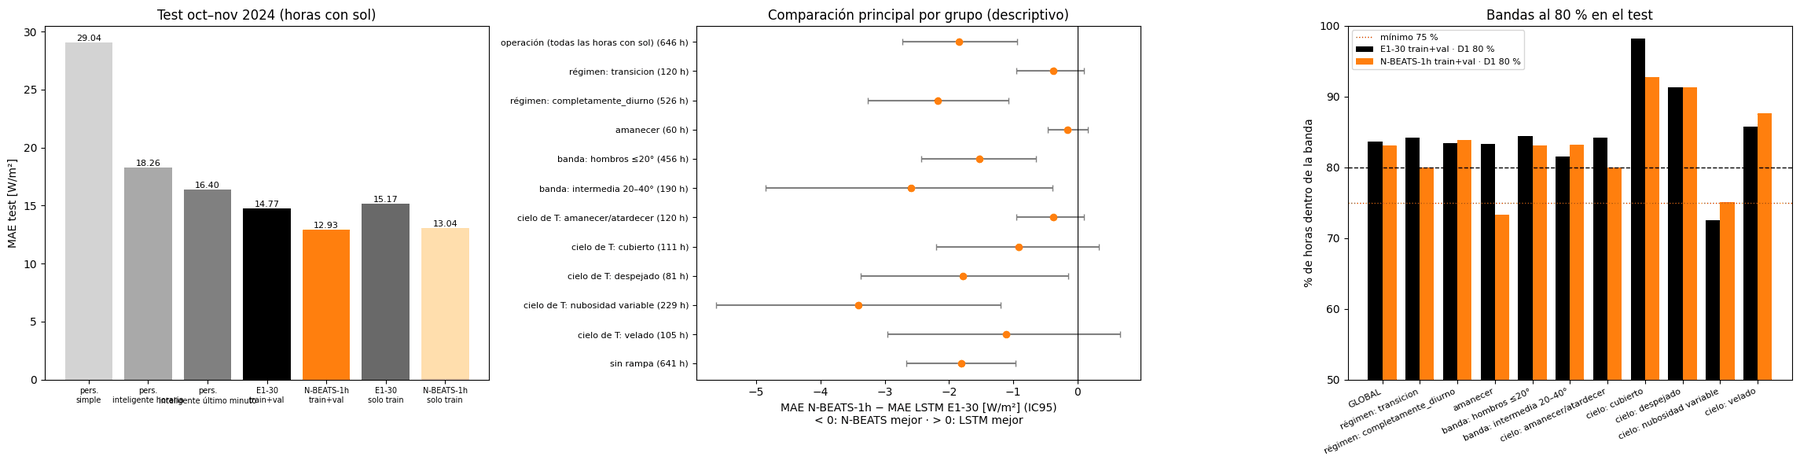


T3 · EVALUACIÓN ÚNICA DEL TEST (oct–nov 2024, horas con sol)
Horas evaluadas: 646 · ejecución nº 1
COMPARACIÓN PRINCIPAL · N-BEATS-1h − LSTM E1-30 (train + val): -1.84 W/m², IC95 [-2.72; -0.94], DM p = 0.0000 → N-BEATS mejor
E1-30 train+val: MAE 14.77 · RMSE 23.25 · sesgo -1.31 · nMAE 19.3 % · R² 0.862 · S vs p. simple / horaria / último minuto: +49.1 % / +19.1 % / +9.9 %
N-BEATS-1h train+val: MAE 12.93 · RMSE 20.59 · sesgo +0.49 · nMAE 16.9 % · R² 0.891 · S vs p. simple / horaria / último minuto: +55.5 % / +29.2 % / +21.2 %
E1-30 solo train: MAE 15.17 · RMSE 23.74 · sesgo -3.09 · nMAE 19.9 % · R² 0.856 · S vs p. simple / horaria / último minuto: +47.7 % / +16.9 % / +7.5 %
N-BEATS-1h solo train: MAE 13.04 · RMSE 20.86 · sesgo -0.04 · nMAE 17.1 % · R² 0.889 · S vs p. simple / horaria / último minuto: +55.1 % / +28.6 % / +20.5 %
persistencia simple: MAE 29.04
persistencia inteligente horaria: MAE 18.26
persistencia inteligente último minuto: MAE 16.40
Secundaria · E1-30 train+val − E1-3

In [ ]:
import os, sys, subprocess, warnings, datetime
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
try:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
except ImportError:
    pass
try:
    import pvlib
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pvlib"], check=True)
    import pvlib
from scipy import stats
from scipy.stats import spearmanr
from sklearn.ensemble import HistGradientBoostingRegressor
BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
DIAG = BASE_DIR / "resultados" / "diagnostico"
RUTA_NPZ = (
    BASE_DIR
    / "resultados"
    / "ejecuciones"
    / "preparacion_bloque_difstats_20261006_180841"
    / "matrices_dif_elev_difstats.npz"
)
RUTA_INTRA = DIAG / "fase1_intrahoraria" / "variables_intrahorarias_horarias.csv"
RUTA_TABLA = DIAG / "faseB_radiografia_E1" / "tabla_horaria_E1.pkl"
RUTA_OOF_E1 = DIAG / "depuracion_E1_30" / "P1_oof_E1_30.pkl"
DIR_5C = DIAG / "faseC_regularizacion" / "C5c_confirmacion"
RUTA_N6B = DIAG / "nbeats" / "N6b_confirmacion" / "N6b_predicciones_validacion.pkl"
RUTA_OOF_NB = DIAG / "nbeats" / "N7_bandas" / "N7_oof_nbeats_1h_epoca5.pkl"
RUTA_D1 = DIAG / "D1_bandas" / "D1_resumen.csv"
RUTA_N7 = DIAG / "nbeats" / "N7_bandas" / "N7_resumen.csv"
DIR_T = DIAG / "T_test"
RUTA_DT = DIR_T / "datos_test.npz"
RUTA_TT = DIR_T / "tabla_test.pkl"
RUTA_INTRA_T = DIR_T / "variables_intrahorarias_hasta_test.csv"
RUTA_T2 = DIR_T / "T2_predicciones" / "T2_predicciones_test.pkl"
SALIDA = DIR_T / "T3_resultados"
SALIDA.mkdir(parents=True, exist_ok=True)
SEMILLAS = [42, 123, 2024, 7, 99]
N_BOOT = 2000
NIVELES = [0.80, 0.90]
LAT, LON, ALT = 51.9711, 4.9267, 0
UMBRAL_RAMPA = 97.78
MIN_HORAS_IC = 30  # desgloses: con menos horas se da el MAE pero no el IC
MIN_HORAS_BANDAS = 50  # bandas: un grupo con menos horas se informa pero no decide el criterio 2
MAE_VAL = {"E1-30": 23.25, "N-BEATS-1h": 23.24}
LSTM_P, NB_P = "E1-30 train+val", "N-BEATS-1h train+val"
LSTM_S, NB_S = "E1-30 solo train", "N-BEATS-1h solo train"
MODELOS = [LSTM_P, NB_P, LSTM_S, NB_S]
PERS = [
    "persistencia simple",
    "persistencia inteligente horaria",
    "persistencia inteligente último minuto",
]

# Registro de ejecuciones: el protocolo exige declarar cualquier re-ejecución
REEJECUCION_DECLARADA = ""  # SOLO si hay que repetir T3 por un error de código: se escribe aquí el motivo (se declara en la memoria)
REG = SALIDA / "T3_registro_ejecuciones.txt"
previas = REG.read_text(encoding="utf-8").strip().splitlines() if REG.exists() else []
N_EJEC = len(previas) + 1
if previas:
    assert REEJECUCION_DECLARADA.strip(), (
        f"T3 ya se ejecutó ({previas[-1]}). El test se evalúa una sola vez: si hay que repetirlo "
        "por un error de código, se escribe el motivo en REEJECUCION_DECLARADA."
    )
    print(
        f"⚠ RE-EJECUCIÓN nº {N_EJEC} ({REEJECUCION_DECLARADA}). Debe declararse en la memoria. Los resultados anteriores no se tocan."
    )
    SALIDA = SALIDA / f"ejecucion_{N_EJEC}"
    SALIDA.mkdir(parents=True, exist_ok=True)

# 0) Comprobaciones antes de mirar ningún error del test
print("0) COMPROBACIONES (todavía no se calcula ningún error del test)")
faltan = [
    str(r)
    for r in [
        RUTA_NPZ,
        RUTA_INTRA,
        RUTA_TABLA,
        RUTA_OOF_E1,
        RUTA_N6B,
        RUTA_OOF_NB,
        RUTA_D1,
        RUTA_N7,
        RUTA_DT,
        RUTA_TT,
        RUTA_INTRA_T,
        RUTA_T2,
    ]
    + [DIR_5C / f"pred_validation_s{s}.npz" for s in SEMILLAS]
    if not r.exists()
]
assert not faltan, "No encuentro:\n  " + "\n  ".join(faltan)
mat = np.load(RUTA_NPZ)
X_tr, X_va = mat["X_train_DIF_elev_DIFstats_raw"].astype(float), mat[
    "X_validation_DIF_elev_DIFstats_raw"
].astype(float)
y_tr = mat["y_train_difstats"].astype(float).reshape(-1)
y_va = mat["y_validation_difstats"].astype(float).reshape(-1)
f_tr, f_va = pd.DatetimeIndex(mat["fechas_train"]), pd.DatetimeIndex(mat["fechas_validation"])
T = pd.read_pickle(RUTA_TABLA)
T = T[T.index < pd.Timestamp("2024-10-01")]
TR, VA = T[T["conjunto"] == "train"], T[T["conjunto"] == "validation"]
assert (TR.index == f_tr).all() and (
    VA.index == f_va
).all(), "La tabla horaria no cuadra con el .npz"
sol_tr, sol_va = (TR["regimen"] != "noche").to_numpy(), (VA["regimen"] != "noche").to_numpy()
DT = np.load(RUTA_DT)
f_te = pd.DatetimeIndex(DT["fechas_test"])
y_te = DT["y_test"].astype(float).reshape(-1)
X_te = DT["X_test_DIF_elev_DIFstats_raw"].astype(float)
PI1_te = DT["esc_test"][:, 2].astype(float)
TT = pd.read_pickle(RUTA_TT)
P2 = pd.read_pickle(RUTA_T2)
assert (
    f_te.min() >= pd.Timestamp("2024-10-01")
    and f_te.max() < pd.Timestamp("2024-12-01")
    and f_va.max() < f_te.min()
)
assert (TT.index == f_te).all() and (
    P2.index == f_te
).all(), "Tabla del test, predicciones de T2 y datos del test no tienen las mismas fechas"
assert len(y_te) == len(X_te) == len(PI1_te) == len(f_te)
assert np.allclose(
    TT["real"].to_numpy(float), y_te, equal_nan=True
), "La DIF real de la tabla del test no cuadra con y_test"
cols_sem = [f"{m} s{s}" for m in MODELOS for s in SEMILLAS]
assert all(c in P2.columns for c in MODELOS + cols_sem), "Faltan columnas en las predicciones de T2"
for m in MODELOS:
    assert np.allclose(
        P2[m].to_numpy(), P2[[f"{m} s{s}" for s in SEMILLAS]].mean(axis=1).to_numpy(), atol=1e-4
    ), f"{m}: no es la media de sus 5 semillas"
assert np.isfinite(P2[cols_sem + MODELOS].to_numpy()).all() and np.isfinite(PI1_te).all()
print(
    f"   ✔ test: {len(f_te)} horas ({f_te.min():%d-%m-%Y} → {f_te.max():%d-%m-%Y}) · 4 modelos × 5 semillas · fechas alineadas"
)

# Predicciones de validación de los modelos de solo train (para calibrar las bandas) y control de su MAE
pred_va = {
    "E1-30": np.mean(
        [np.load(DIR_5C / f"pred_validation_s{s}.npz")["ep30"] for s in SEMILLAS], axis=0
    ).astype(float)
}
N6B = pd.read_pickle(RUTA_N6B)
assert (N6B.index == f_va).all() and np.allclose(N6B["real"].to_numpy(float), y_va, atol=1e-3)
pred_va["N-BEATS-1h"] = N6B["N-BEATS-1h"].to_numpy(float)
for k, p in pred_va.items():
    mae = np.abs(p[sol_va] - y_va[sol_va]).mean()
    assert (
        abs(mae - MAE_VAL[k]) < 0.05
    ), f"{k}: las predicciones de validación no reproducen su MAE ({mae:.2f})"
    print(f"   ✔ {k} (solo train) en validación: MAE {mae:.2f} W/m² (esperado {MAE_VAL[k]})")

# Errores fuera de muestra de train (P1 para E1-30, N7 para la N-BEATS-1h)
OOF = {
    "E1-30": pd.read_pickle(RUTA_OOF_E1).rename(columns={"OOF30_media": "pred"}),
    "N-BEATS-1h": pd.read_pickle(RUTA_OOF_NB).rename(columns={"OOF_media": "pred"}),
}
for k, O in OOF.items():
    assert (O.index == f_tr).all() and O["pred"].notna().all(), f"OOF de {k}: no cuadra con train"
    assert np.allclose(O["real"].to_numpy(float), y_tr, atol=1e-3)

# 1) Persistencias y variables del modelo de riesgo (mismo código que D1/N7)
loc = pvlib.location.Location(LAT, LON, tz="UTC", altitude=ALT)

def a_utc(f):
    f = pd.DatetimeIndex(f)
    return f.tz_localize("UTC") if f.tz is None else f.tz_convert("UTC")


# El desfase se fija con train + validación (como en D1), nunca con el test
elev_T1 = np.concatenate([X_tr[:, -1, 1], X_va[:, -1, 1]])
f_T1 = a_utc(np.concatenate([f_tr, f_va])) - pd.Timedelta("1h")
ok = elev_T1 > 5
dif_desfase = {
    d: np.abs(
        loc.get_solarposition(f_T1 + pd.Timedelta(minutes=d))["apparent_elevation"].to_numpy()[ok]
        - elev_T1[ok]
    ).mean()
    for d in (-30, 0, 30)
}
DESFASE = min(dif_desfase, key=dif_desfase.get)
assert dif_desfase[DESFASE] < 1.5, f"La elevación de pvlib no cuadra con la del .npz: {dif_desfase}"
print(f"\n1) Convención horaria (fijada con train + validación): desfase {DESFASE:+d} min")
intra_tv = pd.read_csv(RUTA_INTRA, index_col=0, parse_dates=True).asfreq("h")
intra_te = pd.read_csv(RUTA_INTRA_T, index_col=0, parse_dates=True).asfreq("h")

def variables(X, fechas, pred, intra):
    f = a_utc(fechas) + pd.Timedelta(minutes=DESFASE)
    previa = intra.reindex(pd.DatetimeIndex(fechas) - pd.Timedelta("1h"))
    V = pd.DataFrame(
        {
            "elevacion_objetivo": loc.get_solarposition(f)["apparent_elevation"].to_numpy(),
            "prediccion": pred,
            "DIF_media_T1": X[:, -1, 0],
            "DIF_std_T1": X[:, -1, 2],
            "DIF_rango_T1": X[:, -1, 3],
            "DIF_saltos_T1": previa["DIF_saltos"].fillna(0).to_numpy(),
            "SWD_cv_T1": previa["SWD_cv"].fillna(0).to_numpy(),
        },
        index=fechas,
    )
    cs = loc.get_clearsky(f, model="ineichen")["dhi"].to_numpy()
    cs_T1 = loc.get_clearsky(f - pd.Timedelta("1h"), model="ineichen")["dhi"].to_numpy()
    return V.astype(float), cs, cs_T1

def pers_inteligente(
    V, cs, cs1
):  # DIF(T−1) · DIFcs(T) / DIFcs(T−1); persistencia simple si DIFcs(T−1) ≈ 0
    p = V["DIF_media_T1"].to_numpy() * np.where(cs1 > 5, cs / np.maximum(cs1, 5), 1.0)
    return np.clip(p, 0, None)


# 2) Método de bandas (idéntico a D1/N7) y control: con calibración solo de train debe reproducir D1 y N7
def nuevo_riesgo(semilla=0):
    return HistGradientBoostingRegressor(
        loss="absolute_error",
        max_iter=200,
        learning_rate=0.05,
        min_samples_leaf=50,
        early_stopping=False,
        random_state=semilla,
    )

def cuantil_conformal(s, nivel):
    n = len(s)
    return float(np.quantile(s, min(1.0, np.ceil((n + 1) * nivel) / n), method="higher"))

def calibrar(Vc, err, mes, fc):
    """σ̂ fuera de muestra por meses (purga 24 h), modelo de riesgo final y cuantiles conformales (D1 y ancho fijo)."""
    suelo = float(np.percentile(err, 5))
    sig = np.full(len(Vc), np.nan)
    for m in sorted(np.unique(mes)):
        fuera = mes == m
        fin = fc[fuera].max()
        entrena = ~fuera & ~((fc > fin) & (fc <= fin + pd.Timedelta("24h")))
        sig[fuera] = nuevo_riesgo().fit(Vc[entrena], err[entrena]).predict(Vc[fuera])
    sig = np.maximum(sig, suelo)
    riesgo = nuevo_riesgo(0).fit(Vc, err)
    Q = {n: (cuantil_conformal(err / sig, n), cuantil_conformal(err, n)) for n in NIVELES}
    return riesgo, suelo, Q

def bandas(riesgo, suelo, Q, Vo, p):
    sig = np.maximum(riesgo.predict(Vo), suelo)
    B = {}
    for n, (q_d1, q_fijo) in Q.items():
        B[("D1", n)] = (np.maximum(0, p - q_d1 * sig), p + q_d1 * sig)
        B[("fijo", n)] = (np.maximum(0, p - q_fijo), p + np.full_like(p, q_fijo))
    return sig, B

def winkler(L, U, y, alfa):
    return (U - L) + (2 / alfa) * np.clip(L - y, 0, None) + (2 / alfa) * np.clip(y - U, 0, None)

V_tr = {k: variables(X_tr, f_tr, OOF[k]["pred"].to_numpy(float), intra_tv)[0] for k in OOF}
V_va = {k: variables(X_va, f_va, pred_va[k], intra_tv)[0] for k in OOF}
mes_tr = {k: OOF[k]["mes_pliegue"].astype(str).to_numpy() for k in OOF}
mes_va = f_va.to_period("M").astype(str).to_numpy()
err_tr = {k: np.abs(y_tr - OOF[k]["pred"].to_numpy(float)) for k in OOF}
err_va = {k: np.abs(y_va - pred_va[k]) for k in OOF}
print(
    "\n2) Control del método de bandas (calibración solo con train → validación de D1 y N7, debe salir idéntico):"
)
for k, ruta in [("E1-30", RUTA_D1), ("N-BEATS-1h", RUTA_N7)]:
    ref = pd.read_csv(ruta, index_col=0)
    rg, su, Q = calibrar(V_tr[k][sol_tr], err_tr[k][sol_tr], mes_tr[k][sol_tr], f_tr[sol_tr])
    _, B = bandas(rg, su, Q, V_va[k][sol_va], pred_va[k][sol_va])
    yv = y_va[sol_va]
    for n in NIVELES:
        L, U = B[("D1", n)]
        Lf, Uf = B[("fijo", n)]
        r = ref.loc[f"{n:.0%}"]
        rep = {
            "cobertura D1 (%)": (100 * np.mean((yv >= L) & (yv <= U)), 0.15),
            "ancho D1": ((U - L).mean(), 0.01),
            "ancho fijo": ((Uf - Lf).mean(), 0.01),
            "Winkler D1": (winkler(L, U, yv, 1 - n).mean(), 0.01),
        }
        for col, (v, tol) in rep.items():
            assert (
                abs(v - float(r[col])) < tol
            ), f"{k} {n:.0%}: el método de bandas no reproduce '{col}' de su validación ({v:.3f} vs {float(r[col]):.3f})"
        print(
            f"   ✔ {k} {n:.0%}: cobertura {rep['cobertura D1 (%)'][0]:.2f} % · ancho {rep['ancho D1'][0]:.2f} · Winkler {rep['Winkler D1'][0]:.2f} "
            f"(guardados {float(r['cobertura D1 (%)']):.2f} · {float(r['ancho D1']):.2f} · {float(r['Winkler D1']):.2f})"
        )

# Calibración definitiva: errores fuera de muestra de train + errores de validación (modelos de solo train)
CAL = {}
for k in OOF:
    Vc = pd.concat([V_tr[k][sol_tr], V_va[k][sol_va]])
    CAL[k] = calibrar(
        Vc,
        np.concatenate([err_tr[k][sol_tr], err_va[k][sol_va]]),
        np.concatenate([mes_tr[k][sol_tr], mes_va[sol_va]]),
        Vc.index,
    )
    print(
        f"   {k}: calibración con {len(Vc)} horas (train fuera de muestra + validación; meses: "
        f"{', '.join(sorted(set(np.concatenate([mes_tr[k][sol_tr], mes_va[sol_va]]))))}) · "
        + " · ".join(
            f"q{int(100*n)}(D1) = {q[0]:.3f}, ancho fijo = {q[1]:.2f}" for n, q in CAL[k][2].items()
        )
    )

# 3) Preparación del test (sin calcular ningún error de ningún modelo)
V_te_l, cs_te, cs1_te = variables(X_te, f_te, P2[LSTM_P].to_numpy(), intra_te)
V_te_n, _, _ = variables(X_te, f_te, P2[NB_P].to_numpy(), intra_te)
PRED = {m: P2[m].to_numpy(float) for m in MODELOS}
PRED["persistencia simple"] = TT["persistencia"].to_numpy(float)
PRED["persistencia inteligente horaria"] = pers_inteligente(V_te_l, cs_te, cs1_te)
PRED["persistencia inteligente último minuto"] = PI1_te
sol_te = (TT["regimen"].astype(str) != "noche").to_numpy()
ev = sol_te & np.isfinite(y_te) & np.all([np.isfinite(PRED[k]) for k in PERS], axis=0)
print(
    f"\n3) Test: {len(f_te)} horas construidas (protocolo: 1464; {1464 - len(f_te)} perdidas en T1) · "
    f"{sol_te.sum()} con sol · evaluadas {ev.sum()}"
    + (
        f" ({sol_te.sum() - ev.sum()} sin DIF real o sin persistencia, excluidas en todos los modelos)"
        if ev.sum() < sol_te.sum()
        else ""
    )
)
kt_nan = int(
    (
        sol_te
        & (TT["regimen"].astype(str) == "completamente_diurno")
        & ~np.isfinite(TT["kt"].to_numpy(float))
    ).sum()
)
print(
    f"   Aviso para la memoria: {kt_nan} horas completamente diurnas sin kt (sol muy bajo) reciben la etiqueta 'velado' "
    "por la regla de train (no se cambia la regla)."
)
y = y_te[ev]
P = {k: v[ev] for k, v in PRED.items()}
inf = TT[ev]
hora = inf.index.hour.to_numpy()
reg = inf["regimen"].astype(str).to_numpy()
ban, cie = (
    inf["banda"].astype(str).to_numpy(),
    inf["cielo"].astype(str).replace({"nubes rotas": "nubosidad variable"}).to_numpy(),
)
dias = inf.index.normalize().to_numpy()
u, inv = np.unique(dias, return_inverse=True)
rng = np.random.default_rng(0)
Wb = np.stack(
    [np.bincount(rng.integers(0, len(u), len(u)), minlength=len(u)) for _ in range(N_BOOT)]
)[:, inv].astype(float)

def ic(d, msk=None):
    """IC95 bootstrap por días. En un subgrupo se descartan las remuestras sin ninguna hora del grupo (solo afecta a grupos pequeños)."""
    msk = np.ones(len(d), bool) if msk is None else msk
    v = np.where(msk, d, 0.0)
    b = (Wb @ v) / np.maximum(Wb @ msk.astype(float), 1e-9)
    b = b[(Wb @ msk.astype(float)) > 0]
    return d[msk].mean(), np.percentile(b, 2.5), np.percentile(b, 97.5)

def dm(d):
    s = pd.Series(d, index=inf.index).groupby(dias).mean().to_numpy()
    n = len(s)
    dc = s - s.mean()
    L = int(np.floor(n ** (1 / 3)))
    var = dc @ dc / n + sum(2 * (1 - k / (L + 1)) * (dc[k:] @ dc[:-k]) / n for k in range(1, L + 1))
    t = s.mean() / np.sqrt(var / n) * np.sqrt((n - 1) / n)
    return t, 2 * stats.t.sf(abs(t), df=n - 1)

fmt = lambda lo, hi: f"[{lo:+.2f}; {hi:+.2f}]"

# Grupos de las bandas y σ̂ del test (no usan ningún error)
GB = {"GLOBAL": np.ones(len(y), bool)}
for g in ["transicion", "completamente_diurno"]:
    GB[f"régimen: {g}"] = reg == g
GB["amanecer"] = (reg == "transicion") & (hora < 12)
for g in sorted(np.unique(ban)):
    GB[f"banda: {g}"] = ban == g
for g in sorted(np.unique(cie)):
    GB[f"cielo: {g}"] = cie == g
CONTROLADOS = [k for k in GB if k != "GLOBAL" and GB[k].sum() >= MIN_HORAS_BANDAS]
assert CONTROLADOS, "Ningún grupo llega a 50 horas: el criterio 2 no se podría evaluar"
SIGB = {
    "E1-30": bandas(*CAL["E1-30"], V_te_l[ev], P[LSTM_P]),
    "N-BEATS-1h": bandas(*CAL["N-BEATS-1h"], V_te_n[ev], P[NB_P]),
}
print(
    "   Grupos que decidirán el criterio 2 de las bandas (≥ 50 h): "
    + ", ".join(f"{g} ({GB[g].sum()} h)" for g in CONTROLADOS)
)
print(
    "   ✔ comprobaciones y preparación terminadas. A partir de aquí se evalúa el test (una sola vez)."
)
with open(REG, "a", encoding="utf-8") as fh:
    fh.write(
        f"ejecución {N_EJEC}: {datetime.datetime.now():%Y-%m-%d %H:%M:%S}"
        + (f" · re-ejecución declarada: {REEJECUCION_DECLARADA}" if N_EJEC > 1 else "")
        + "\n"
    )

# 4) EVALUACIÓN DEL TEST
E = {k: np.abs(v - y) for k, v in P.items()}


# 4a) Métricas
def metricas(p):
    e = p - y
    return {
        "MAE": np.abs(e).mean(),
        "RMSE": np.sqrt((e**2).mean()),
        "sesgo (ŷ−y)": e.mean(),
        "nMAE (%)": 100 * np.abs(e).mean() / y.mean(),
        "R²": 1 - (e**2).sum() / ((y - y.mean()) ** 2).sum(),
    }

M = pd.DataFrame({k: metricas(P[k]) for k in MODELOS + PERS}).T
for r in PERS:
    M[f"S vs {r.replace('persistencia ', 'p. ')} (%)"] = 100 * (1 - M["MAE"] / M.loc[r, "MAE"])
M.index.name = "predictor"


# 4b) Comparación principal y secundarias
def lectura(lo, hi, a, b):
    return f"{a} mejor" if hi < 0 else (f"{b} mejor" if lo > 0 else "no se distinguen")

COMP = [
    ("PRINCIPAL", NB_P, LSTM_P, "N-BEATS", "LSTM"),
    ("secundaria", LSTM_P, LSTM_S, "reentrenado", "solo train"),
    ("secundaria", NB_P, NB_S, "reentrenado", "solo train"),
    ("secundaria", NB_S, LSTM_S, "N-BEATS", "LSTM"),
]
filas = []
for papel, a, b, na, nb in COMP:
    d = E[a] - E[b]
    c, lo, hi = ic(d)
    t, p = dm(d)
    filas.append(
        {
            "papel": papel,
            "comparación": f"{a} − {b}",
            "ΔMAE [W/m²]": c,
            "IC95": fmt(lo, hi),
            "IC95 inf": lo,
            "IC95 sup": hi,
            "DM t": t,
            "DM p": p,
            "lectura": lectura(lo, hi, na, nb),
        }
    )
for a in [LSTM_P, NB_P]:  # complemento (no fijado en el protocolo): ¿supera a cada persistencia?
    for r in PERS:
        d = E[a] - E[r]
        c, lo, hi = ic(d)
        t, p = dm(d)
        filas.append(
            {
                "papel": "complemento",
                "comparación": f"{a} − {r}",
                "ΔMAE [W/m²]": c,
                "IC95": fmt(lo, hi),
                "IC95 inf": lo,
                "IC95 sup": hi,
                "DM t": t,
                "DM p": p,
                "lectura": lectura(lo, hi, "modelo", "persistencia"),
            }
        )
C = pd.DataFrame(filas).set_index("comparación")
c0, lo0, hi0 = C.iloc[0][["ΔMAE [W/m²]", "IC95 inf", "IC95 sup"]]
p0 = C.iloc[0]["DM p"]

# 4c) Desgloses (descriptivos)
dlt = y - P["persistencia simple"]  # DIF(T) − DIF(T−1)
G = [("operación (todas las horas con sol)", np.ones(len(y), bool))]
G += [(f"régimen: {g}", reg == g) for g in ["transicion", "completamente_diurno"]]
G += [("amanecer", (reg == "transicion") & (hora < 12))]
G += [(f"banda: {g}", ban == g) for g in sorted(T["banda"].astype(str).unique())]
G += [
    (f"cielo de T: {g}", cie == g)
    for g in sorted(
        set(T["cielo"].astype(str).replace({"nubes rotas": "nubosidad variable"})) - {"noche"}
    )
]
G += [
    ("rampa de subida (≥ 97,78)", dlt >= UMBRAL_RAMPA),
    ("rampa de bajada (≤ −97,78)", dlt <= -UMBRAL_RAMPA),
    ("sin rampa", np.abs(dlt) < UMBRAL_RAMPA),
]
filas = []
for nombre, msk in G:
    f = {"grupo": nombre, "horas": int(msk.sum())}
    if msk.sum() > 0:
        f.update({f"MAE {k}": E[k][msk].mean() for k in MODELOS + PERS})
        f["DIF media real"] = y[msk].mean()
    if msk.sum() >= MIN_HORAS_IC:
        g, gl, gh = ic(E[NB_P] - E[LSTM_P], msk)
        f.update(
            {
                "N-BEATS − LSTM (principales)": g,
                "IC95 (complemento)": fmt(gl, gh),
                "lectura (complemento)": lectura(gl, gh, "N-BEATS", "LSTM"),
            }
        )
    elif msk.sum() > 0:
        f.update(
            {
                "N-BEATS − LSTM (principales)": (E[NB_P] - E[LSTM_P])[msk].mean(),
                "IC95 (complemento)": f"< {MIN_HORAS_IC} h",
                "lectura (complemento)": "pocas horas",
            }
        )
    filas.append(f)
D = pd.DataFrame(filas).set_index("grupo")

# 4d) Exploratorio (fuera del protocolo): MAE por semilla
SEM = pd.DataFrame(
    {m: [np.abs(P2[f"{m} s{s}"].to_numpy()[ev] - y).mean() for s in SEMILLAS] for m in MODELOS},
    index=[f"semilla {s}" for s in SEMILLAS],
)

# 4e) Bandas en el test (modelos principales; σ̂ calculado antes)
filas_res, filas_des, OUTB = [], [], {}
for k, modelo in [("E1-30", LSTM_P), ("N-BEATS-1h", NB_P)]:
    sig, B = SIGB[k]
    rho, p_rho = spearmanr(sig, E[modelo])
    OUTB[k] = (sig, B)
    for n in NIVELES:
        alfa, obj = 1 - n, 100 * n
        w = {}
        for metodo in ["D1", "fijo"]:
            L, U = B[(metodo, n)]
            dentro = (y >= L) & (y <= U)
            w[metodo] = winkler(L, U, y, alfa)
            for g, msk in GB.items():
                if msk.sum() > 0:
                    filas_des.append(
                        {
                            "modelo": modelo,
                            "nivel": f"{n:.0%}",
                            "método": metodo,
                            "grupo": g,
                            "horas": int(msk.sum()),
                            "cobertura (%)": 100 * dentro[msk].mean(),
                            "ancho medio [W/m²]": (U - L)[msk].mean(),
                            "Winkler": w[metodo][msk].mean(),
                        }
                    )
        Dn = pd.DataFrame(
            [f for f in filas_des if f["modelo"] == modelo and f["nivel"] == f"{n:.0%}"]
        )
        d1 = Dn[Dn["método"] == "D1"].set_index("grupo")
        fj = Dn[Dn["método"] == "fijo"].set_index("grupo")
        c, lo, hi = ic(w["D1"] - w["fijo"])
        ok1 = obj - 3 <= d1.loc["GLOBAL", "cobertura (%)"] <= obj + 3
        ok2 = (d1.loc[CONTROLADOS, "cobertura (%)"] >= obj - 5).all() if CONTROLADOS else True
        ok3, ok4 = hi < 0, rho > 0
        ver = (
            "SE ACEPTA D1"
            if (ok1 and ok2 and ok3 and ok4)
            else ("ANCHO FIJO (D1 no aporta)" if (ok1 and ok2 and not ok3) else "NO SE ACEPTA")
        )
        peor = (
            d1.loc[CONTROLADOS, "cobertura (%)"]
            if CONTROLADOS
            else d1.loc[["GLOBAL"], "cobertura (%)"]
        )
        filas_res.append(
            {
                "modelo": modelo,
                "nivel": f"{n:.0%}",
                "cobertura D1 (%)": d1.loc["GLOBAL", "cobertura (%)"],
                "cobertura fijo (%)": fj.loc["GLOBAL", "cobertura (%)"],
                "ancho D1": d1.loc["GLOBAL", "ancho medio [W/m²]"],
                "ancho fijo": fj.loc["GLOBAL", "ancho medio [W/m²]"],
                "Winkler D1": w["D1"].mean(),
                "Winkler fijo": w["fijo"].mean(),
                "cambio Winkler (D1 − fijo)": c,
                "IC95": fmt(lo, hi),
                "peor grupo controlado": f"{peor.idxmin()} ({peor.min():.1f} %)",
                "Spearman σ̂–error": rho,
                "1 cobertura global": ok1,
                "2 cobertura por grupo": ok2,
                "3 Winkler mejor": ok3,
                "4 Spearman > 0": ok4,
                "veredicto": ver,
            }
        )
RB = pd.DataFrame(filas_res).set_index(["modelo", "nivel"])
DB = pd.DataFrame(filas_des)

# 5) Resultados
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 40)
print(
    "\n"
    + "=" * 110
    + "\nT3 · TEST (oct–nov 2024, horas con sol, media de 5 semillas)\n"
    + "=" * 110
)
print(
    "Métricas (aviso fijado antes: sin banda central y con DIF más baja, el MAE y el R² no son comparables con validación;"
    " la lectura principal es S, nMAE y la comparación por parejas):"
)
display(M.round(3))
print(
    "\nComparaciones (ΔMAE < 0 → el primero es mejor; IC95 bootstrap por días; DM diario con HLN):"
)
display(C.drop(columns=["IC95 inf", "IC95 sup"]).round(4))
print(
    f"\n➜ COMPARACIÓN PRINCIPAL · N-BEATS-1h − LSTM E1-30 (train + validación): {c0:+.2f} W/m², IC95 [{lo0:+.2f}; {hi0:+.2f}], "
    f"DM p = {p0:.4f} → {C.iloc[0]['lectura'].upper()}"
)
print(
    "\nDesgloses (descriptivos; el IC95 por grupo es un complemento fuera del protocolo, sin ajustar, y no decide):"
)
display(D.round(2))
print("\nBandas de incertidumbre de los modelos principales (método D1/N7, 4 criterios):")
print(
    "   Grupos que deciden el criterio 2 (≥ 50 h): "
    + ", ".join(f"{g} ({GB[g].sum()} h)" for g in CONTROLADOS)
)
display(RB.round(2))
print("Cobertura por grupo (%):")
display(
    DB.pivot_table(index="grupo", columns=["modelo", "nivel", "método"], values="cobertura (%)")
    .reindex([g for g in GB if GB[g].sum() > 0])
    .round(1)
)
print("\nExploratorio (fuera del protocolo) · MAE de cada semilla por separado:")
display(SEM.round(2))

# Gráficas
fig, axs = plt.subplots(1, 3, figsize=(23, 6))
orden = PERS + MODELOS
col = ["lightgray", "darkgray", "gray", "black", "tab:orange", "dimgray", "navajowhite"]
axs[0].bar(range(len(orden)), [M.loc[k, "MAE"] for k in orden], color=col)
for i, k in enumerate(orden):
    axs[0].text(i, M.loc[k, "MAE"], f"{M.loc[k, 'MAE']:.2f}", ha="center", va="bottom", fontsize=8)
axs[0].set_xticks(range(len(orden)))
axs[0].set_xticklabels(
    [o.replace("persistencia ", "pers. ").replace(" ", "\n", 1) for o in orden], fontsize=7
)
axs[0].set_ylabel("MAE test [W/m²]")
axs[0].set_title("Test oct–nov 2024 (horas con sol)")
sub = D[D["IC95 (complemento)"].astype(str).str.startswith("[")]
yy = np.arange(len(sub))
lim = sub["IC95 (complemento)"].str.strip("[]").str.split(";", expand=True).astype(float)
v = sub["N-BEATS − LSTM (principales)"]
axs[1].errorbar(
    v, yy, xerr=[v - lim[0], lim[1] - v], fmt="o", color="tab:orange", ecolor="gray", capsize=3
)
axs[1].axvline(0, color="k", lw=0.8)
axs[1].set_yticks(yy)
axs[1].set_yticklabels([f"{g} ({h} h)" for g, h in zip(sub.index, sub["horas"])], fontsize=8)
axs[1].invert_yaxis()
axs[1].set_xlabel(
    "MAE N-BEATS-1h − MAE LSTM E1-30 [W/m²] (IC95)\n< 0: N-BEATS mejor · > 0: LSTM mejor"
)
axs[1].set_title("Comparación principal por grupo (descriptivo)")
gr = ["GLOBAL"] + CONTROLADOS
x = np.arange(len(gr))
wb = 0.38
for j, (mod, color) in enumerate([(LSTM_P, "black"), (NB_P, "tab:orange")]):
    cb = (
        DB[(DB["modelo"] == mod) & (DB["nivel"] == "80%") & (DB["método"] == "D1")]
        .set_index("grupo")
        .reindex(gr)["cobertura (%)"]
    )
    axs[2].bar(x + (j - 0.5) * wb, cb, wb, color=color, label=f"{mod} · D1 80 %")
axs[2].axhline(80, color="k", ls="--", lw=1)
axs[2].axhline(75, color="tab:red", ls=":", lw=1, label="mínimo 75 %")
axs[2].set_xticks(x)
axs[2].set_xticklabels(gr, rotation=25, ha="right", fontsize=8)
axs[2].set_ylim(50, 100)
axs[2].set_ylabel("% de horas dentro de la banda")
axs[2].legend(fontsize=8)
axs[2].set_title("Bandas al 80 % en el test")
plt.tight_layout()
plt.savefig(SALIDA / "T3_test.png", dpi=120)
plt.show()

# Guardado
M.to_csv(SALIDA / "T3_metricas.csv")
C.to_csv(SALIDA / "T3_comparaciones.csv")
D.to_csv(SALIDA / "T3_desgloses.csv")
RB.to_csv(SALIDA / "T3_bandas_resumen.csv")
DB.to_csv(SALIDA / "T3_bandas_desglose.csv", index=False)
SEM.to_csv(SALIDA / "T3_exploratorio_por_semilla.csv")
out = pd.DataFrame({"real": y, **{k: P[k] for k in MODELOS + PERS}}, index=inf.index)
for k, (sig, B) in OUTB.items():
    out[f"sigma_{k}"] = sig
    for (metodo, n), (L, U) in B.items():
        out[f"{k}_{metodo}_{int(100*n)}_inf"], out[f"{k}_{metodo}_{int(100*n)}_sup"] = L, U
out.to_pickle(SALIDA / "T3_predicciones_y_bandas.pkl")
texto = "\n".join(
    [
        "T3 · EVALUACIÓN ÚNICA DEL TEST (oct–nov 2024, horas con sol)",
        "=" * 80,
        f"Horas evaluadas: {ev.sum()} · ejecución nº {N_EJEC}",
        f"COMPARACIÓN PRINCIPAL · N-BEATS-1h − LSTM E1-30 (train + val): {c0:+.2f} W/m², IC95 [{lo0:+.2f}; {hi0:+.2f}], DM p = {p0:.4f} → {C.iloc[0]['lectura']}",
    ]
    + [
        f"{k}: MAE {M.loc[k, 'MAE']:.2f} · RMSE {M.loc[k, 'RMSE']:.2f} · sesgo {M.loc[k, 'sesgo (ŷ−y)']:+.2f} · nMAE {M.loc[k, 'nMAE (%)']:.1f} % · "
        f"R² {M.loc[k, 'R²']:.3f} · S vs p. simple / horaria / último minuto: "
        + " / ".join(f"{M.loc[k, c]:+.1f} %" for c in M.columns if c.startswith("S vs"))
        for k in MODELOS
    ]
    + [f"{k}: MAE {M.loc[k, 'MAE']:.2f}" for k in PERS]
    + [
        f"Secundaria · {i}: {r['ΔMAE [W/m²]']:+.2f} {r['IC95']} → {r['lectura']}"
        for i, r in C[C["papel"] == "secundaria"].iterrows()
    ]
    + [
        f"Bandas {m} {n}: cobertura D1 {r['cobertura D1 (%)']:.1f} % · ancho {r['ancho D1']:.1f} (fijo {r['ancho fijo']:.1f}) · "
        f"Winkler {r['cambio Winkler (D1 − fijo)']:+.2f} {r['IC95']} · peor grupo {r['peor grupo controlado']} → {r['veredicto']}"
        for (m, n), r in RB.iterrows()
    ]
)
(SALIDA / "T3_veredicto.txt").write_text(texto, encoding="utf-8")
print("\n" + texto + "\n\nResultados en:", SALIDA)

**Resultados.** Las comprobaciones previas se superan (fechas, MAE de validación de los modelos de solo entrenamiento, 23,25 y 23,24 W/m², y método de bandas) y se evalúan las 646 horas con sol, sin ninguna pérdida.

- **Principal:** MAE de 12,93 W/m² en la N-BEATS-1h y de 14,77 en E1-30 (nMAE del 16,9 % y del 19,3 %). La diferencia, −1,84 W/m² (IC95 [−2,72; −0,94]; Diebold–Mariano p < 0,0001), queda entera por debajo de 0: la N-BEATS-1h tiene menos error que E1-30, un resultado referido a estas dos configuraciones.
- **Secundarias:** con los modelos de solo entrenamiento, −2,14 W/m² [−3,10; −1,19]; reentrenar reduce el error de E1-30 (−0,40 [−0,61; −0,19]) y no cambia de forma distinguible el de la N-BEATS-1h (−0,11 [−0,37; +0,13]).
- **Complementos:** los dos modelos tienen menos error que las tres persistencias, con intervalos enteros por debajo de 0 (−1,63 y −3,47 W/m² frente a la del último minuto).
- **Desgloses (descriptivos):** la diferencia es negativa en todos los grupos con horas suficientes (−2,18 W/m² en horas completamente diurnas; −3,41 con nubosidad variable), aunque el intervalo cruza el 0 en transición, amanecer y cielos cubierto y velado; las rampas (cuatro de subida y una de bajada) no permiten lectura. Las bandas, también descriptivas, solo cumplen los cuatro criterios en la N-BEATS-1h al 90 %.

### 9.6 Análisis exploratorio posterior al test

Con predicciones ya guardadas, sin reentrenar ni elegir nada, se describe dónde aparece la diferencia entre la N-BEATS-1h y E1-30: mes a mes durante todo el año con una serie comparable (semillas 42 y 123 y, en cada mes, modelos que no lo vieron), por elevación solar, por nivel de DIF (sesgo), por cercanía a la persistencia del último minuto y en las horas con la etiqueta «velado» por defecto; además, se mide el coste computacional de los dos modelos en la misma máquina. El análisis no estaba en el protocolo, es descriptivo (intervalos sin corregir por comparaciones múltiples) y no cambia ningún veredicto.

0) Horas con sol fuera de muestra: train (fuera de muestra): 3027 · validación (solo train): 884 · test (solo train): 646 · test (principales, 5 semillas): 646 · desfase horario +30 min · serie comparable = semillas 42 y 123 en todos los periodos
F) Midiendo tiempos en CPU (1 hilos), los dos modelos en la misma máquina y con los mismos datos…

T4 · ANÁLISIS EXPLORATORIO POSTERIOR AL TEST (no fijado de antemano; descriptivo)
A) N-BEATS − LSTM mes a mes (horas con sol; < 0: N-BEATS mejor). La serie comparable usa las semillas 42 y 123 en todos los
   periodos y modelos que no vieron ese mes; la fila 'principales' es la de T3. El MAE absoluto no es comparable entre meses.


,periodo,horas,elevación media (°),DIF media,MAE LSTM,MAE N-BEATS,MAE PI1,N-BEATS − LSTM,IC95,lectura,sesgo LSTM,sesgo N-BEATS
mes,,,,,,,,,,,,
2024-01,train (fuera de muestra),311,9.40,49.13,11.63,8.76,10.66,-2.87,[-4.46; -1.38],IC < 0 (N-BEATS),3.47,-0.92
2024-02,train (fuera de muestra),315,14.53,79.02,16.59,16.15,18.26,-0.45,[-1.58; +0.65],IC cruza 0,-0.82,-2.76
2024-03,train (fuera de muestra),386,20.64,120.62,23.30,23.01,27.35,-0.29,[-1.97; +1.47],IC cruza 0,-1.37,-0.22
2024-04,train (fuera de muestra),444,26.72,156.81,33.32,30.17,37.60,-3.15,[-4.91; -1.40],IC < 0 (N-BEATS),-14.23,-5.62
2024-05,train (fuera de muestra),519,30.18,162.37,29.07,28.48,33.68,-0.59,[-2.16; +1.01],IC cruza 0,3.78,5.03
2024-06,train (fuera de muestra),525,31.96,165.97,30.38,32.20,37.77,1.82,[-0.22; +3.88],IC cruza 0,-4.39,6.13
2024-07,train (fuera de muestra),527,31.24,165.98,31.41,29.96,37.23,-1.44,[-3.08; +0.20],IC cruza 0,-2.64,-1.63
2024-08,validación (solo train),480,28.03,154.82,24.15,24.80,27.73,0.65,[-0.98; +2.19],IC cruza 0,-2.82,-9.04
2024-09,validación (solo train),404,22.95,126.33,22.53,22.51,27.41,-0.02,[-1.46; +1.42],IC cruza 0,-0.47,-4.81


   Solo dentro de train (mismos modelos y receta en los 7 meses): Spearman entre elevación media del mes y diferencia = +0.32

B) Por elevación del sol en la hora objetivo (tramos con ≥ 30 h; 360 horas con elevación < 0 quedan fuera).
   La fila 'todo el año' mezcla periodos distintos en cada tramo: interprétese con la de cada periodo, no sola.


,periodo,elevación,horas,MAE LSTM,MAE N-BEATS,N-BEATS − LSTM,IC95,lectura,S LSTM vs PI1 (%),S N-BEATS vs PI1 (%)
0,train (fuera de muestra),0–10°,573,6.83,7.22,0.39,[-0.33; +1.14],IC cruza 0,37.54,34.01
1,train (fuera de muestra),10–20°,614,16.67,15.01,-1.66,[-2.78; -0.57],IC < 0 (N-BEATS),2.75,12.44
2,train (fuera de muestra),20–30°,478,29.34,28.51,-0.83,[-2.50; +0.94],IC cruza 0,3.49,6.23
3,train (fuera de muestra),30–40°,389,38.20,37.30,-0.90,[-3.42; +1.74],IC cruza 0,11.24,13.33
4,train (fuera de muestra),40–50°,345,42.99,41.43,-1.56,[-4.52; +1.31],IC cruza 0,18.50,21.46
5,train (fuera de muestra),50–65°,426,51.61,50.16,-1.45,[-4.95; +1.94],IC cruza 0,16.75,19.09
6,validación (solo train),0–10°,142,7.26,7.61,0.35,[-1.04; +1.77],IC cruza 0,50.97,48.58
7,validación (solo train),10–20°,137,16.39,15.29,-1.09,[-2.90; +0.60],IC cruza 0,6.17,12.44
8,validación (solo train),20–30°,146,28.17,25.50,-2.66,[-4.69; -0.75],IC < 0 (N-BEATS),-2.24,7.43
9,validación (solo train),30–40°,192,29.57,31.62,2.04,[-1.14; +5.20],IC cruza 0,20.52,15.03



C) Sesgo (ŷ − y) en el test por mes y por nivel de DIF real:


,horas,sesgo LSTM,sesgo N-BEATS,sesgo PI1
mes,,,,
2024-10,358,-2.81,-0.23,-2.20
2024-11,288,0.55,1.38,-0.16


... (3 outputs left out)


E) Sensibilidad de la etiqueta 'velado' (test):


,horas,DIF media,elevación media (°),MAE LSTM,MAE N-BEATS,cobertura 80 % E1-30,cobertura 80 % N-BEATS-1h
grupo,,,,,,,
velado con kt,74,109.61,17.36,14.90,13.89,83.78,85.14
velado sin kt (por defecto),31,20.25,5.11,5.45,4.08,90.32,93.55



F) Coste computacional (mismo hardware; los tiempos absolutos dependen de la máquina, el cociente es lo comparable).
   'Receta' = 30 épocas la LSTM y 5 la N-BEATS (incluye el efecto del número de épocas); 'por época' compara solo la
   arquitectura. Compárese también el número de parámetros: más rápida no significa más pequeña.


,parámetros,épocas de la receta,s por época (receta),s por época (solo cálculo),receta 1 semilla (s),receta 5 semillas (min),inferencia 1464 h (ms)
LSTM E1-30,21313.000,30.0,4.391,2.899,131.739,10.978,229.178
N-BEATS-1h,258126.000,5.0,2.633,1.654,13.165,1.097,46.120
cociente LSTM / N-BEATS,0.083,6.0,1.668,1.753,10.007,10.007,4.969


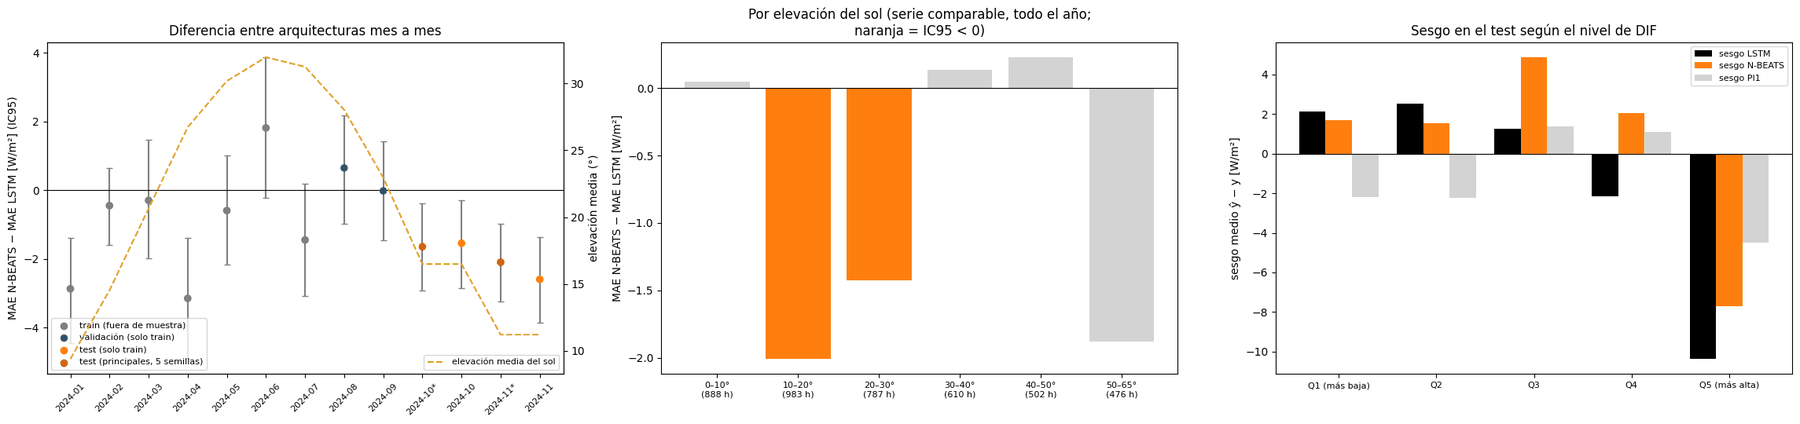


Resultados en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/T_test/T4_exploratorio


In [ ]:
import os, sys, subprocess, warnings, time, random
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
try:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
except ImportError:
    pass
try:
    import pvlib
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pvlib"], check=True)
    import pvlib

BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
DIAG = BASE_DIR / "resultados" / "diagnostico"
RUTA_NPZ = (
    BASE_DIR
    / "resultados"
    / "ejecuciones"
    / "preparacion_bloque_difstats_20261006_180841"
    / "matrices_dif_elev_difstats.npz"
)
RUTA_INTRA = DIAG / "fase1_intrahoraria" / "variables_intrahorarias_horarias.csv"
RUTA_TABLA = DIAG / "faseB_radiografia_E1" / "tabla_horaria_E1.pkl"
RUTA_OOF_E1 = DIAG / "depuracion_E1_30" / "P1_oof_E1_30.pkl"
RUTA_OOF_NB = DIAG / "nbeats" / "N7_bandas" / "N7_oof_nbeats_1h_epoca5.pkl"
DIR_5C = DIAG / "faseC_regularizacion" / "C5c_confirmacion"
RUTA_N6B = DIAG / "nbeats" / "N6b_confirmacion" / "N6b_predicciones_validacion.pkl"
RUTA_L0 = DIAG / "L_entrada_una_hora" / "entrada_una_hora.npz"
DIR_T = DIAG / "T_test"
RUTA_T3 = DIR_T / "T3_resultados" / "T3_predicciones_y_bandas.pkl"
SALIDA = DIR_T / "T4_exploratorio"
SALIDA.mkdir(parents=True, exist_ok=True)
SEMILLAS = [42, 123, 2024, 7, 99]
N_BOOT = 2000
LAT, LON, ALT = 51.9711, 4.9267, 0
BINS_ELEV = [0, 10, 20, 30, 40, 50, 65]
LSTM_P, NB_P, LSTM_S, NB_S = (
    "E1-30 train+val",
    "N-BEATS-1h train+val",
    "E1-30 solo train",
    "N-BEATS-1h solo train",
)
PI1 = "persistencia inteligente último minuto"

# 0) Datos: predicciones fuera de muestra de los tres periodos (todas ya guardadas)
mat = np.load(RUTA_NPZ)
X = {c: mat[f"X_{c}_DIF_elev_DIFstats_raw"].astype(float) for c in ["train", "validation"]}
Y = {c: mat[f"y_{c}_difstats"].astype(float).reshape(-1) for c in ["train", "validation"]}
F = {c: pd.DatetimeIndex(mat[f"fechas_{c}"]) for c in ["train", "validation"]}
T = pd.read_pickle(RUTA_TABLA)
T = T[T.index < pd.Timestamp("2024-10-01")]
TR, VA = T[T["conjunto"] == "train"], T[T["conjunto"] == "validation"]
assert (TR.index == F["train"]).all() and (
    VA.index == F["validation"]
).all(), "La tabla horaria no cuadra con el .npz"
L0 = np.load(RUTA_L0)
for c in ["train", "validation"]:
    assert (
        (pd.DatetimeIndex(L0[f"fechas_{c}"]) == F[c]).all()
        and np.isfinite(L0[f"esc_{c}"][:, 2]).all()
        and np.isfinite(Y[c]).all()
    )
O1, O2 = pd.read_pickle(RUTA_OOF_E1), pd.read_pickle(RUTA_OOF_NB)
assert (O1.index == F["train"]).all() and (O2.index == F["train"]).all()
assert (
    O1["mes_pliegue"].astype(str) == O2["mes_pliegue"].astype(str)
).all(), "P1 y N7 no usan los mismos pliegues"
R3 = pd.read_pickle(RUTA_T3)
T2 = pd.read_pickle(DIR_T / "T2_predicciones" / "T2_predicciones_test.pkl").reindex(R3.index)
TT = pd.read_pickle(DIR_T / "tabla_test.pkl").reindex(R3.index)
assert np.allclose(T2[LSTM_P].to_numpy(), R3[LSTM_P].to_numpy(), atol=1e-4), "T2 y T3 no cuadran"
loc = pvlib.location.Location(LAT, LON, tz="UTC", altitude=ALT)

def a_utc(f):
    f = pd.DatetimeIndex(f)
    return f.tz_localize("UTC") if f.tz is None else f.tz_convert("UTC")

elev_T1 = np.concatenate([X["train"][:, -1, 1], X["validation"][:, -1, 1]])
f_T1 = a_utc(np.concatenate([F["train"], F["validation"]])) - pd.Timedelta("1h")
ok = elev_T1 > 5
dd = {
    d: np.abs(
        loc.get_solarposition(f_T1 + pd.Timedelta(minutes=d))["apparent_elevation"].to_numpy()[ok]
        - elev_T1[ok]
    ).mean()
    for d in (-30, 0, 30)
}
DESFASE = min(dd, key=dd.get)
elev = lambda f: loc.get_solarposition(a_utc(f) + pd.Timedelta(minutes=DESFASE))[
    "apparent_elevation"
].to_numpy()

# Serie COMPARABLE en todo el año: mismas semillas (42 y 123) en los tres periodos y modelos que no han visto el periodo.
#   train: fuera de muestra (P1 y N7, entrenados con 6 de los 7 meses) · validación y test: modelos de solo train.
# Referencia: los modelos principales del test (train + val, 5 semillas), los de T3.
S2 = [42, 123]

def bloque(periodo, serie, fechas, y, lstm, nb, pi1, regimen, mes=None):
    sol = (pd.Series(regimen).astype(str) != "noche").to_numpy()
    fechas = pd.DatetimeIndex(fechas)
    mes = (
        fechas.to_period("M").astype(str).to_numpy() if mes is None else np.asarray(mes, dtype=str)
    )
    return pd.DataFrame(
        {
            "periodo": periodo,
            "serie": serie,
            "mes": mes,
            "real": y,
            "LSTM": lstm,
            "NBEATS": nb,
            "PI1": pi1,
            "elev": elev(fechas),
        },
        index=fechas,
    )[sol]

va_l = np.mean([np.load(DIR_5C / f"pred_validation_s{s}.npz")["ep30"] for s in S2], axis=0)
va_n = np.mean(
    [
        np.load(DIAG / "nbeats" / "N6b_confirmacion" / f"pred_validacion_NB1h_s{s}.npz")["pred"][4]
        for s in S2
    ],
    axis=0,
)
D = pd.concat(
    [
        bloque(
            "train (fuera de muestra)",
            "comparable",
            F["train"],
            Y["train"],
            O1["OOF30_media"].to_numpy(float),
            O2["OOF_media"].to_numpy(float),
            L0["esc_train"][:, 2].astype(float),
            TR["regimen"],
            O1["mes_pliegue"].astype(str),
        ),
        bloque(
            "validación (solo train)",
            "comparable",
            F["validation"],
            Y["validation"],
            va_l,
            va_n,
            L0["esc_validation"][:, 2].astype(float),
            VA["regimen"],
        ),
        bloque(
            "test (solo train)",
            "comparable",
            R3.index,
            R3["real"].to_numpy(float),
            T2[[f"{LSTM_S} s{s}" for s in S2]].mean(axis=1).to_numpy(),
            T2[[f"{NB_S} s{s}" for s in S2]].mean(axis=1).to_numpy(),
            R3[PI1].to_numpy(float),
            TT["regimen"],
        ),
        bloque(
            "test (principales, 5 semillas)",
            "referencia",
            R3.index,
            R3["real"].to_numpy(float),
            R3[LSTM_P].to_numpy(float),
            R3[NB_P].to_numpy(float),
            R3[PI1].to_numpy(float),
            TT["regimen"],
        ),
    ]
)
assert (
    D[["real", "LSTM", "NBEATS", "PI1", "elev"]].notna().all().all()
), "Hay valores ausentes en las predicciones"
for k in ["LSTM", "NBEATS", "PI1"]:
    D[f"e_{k}"] = (D[k] - D["real"]).abs()
D["dif"] = D["e_NBEATS"] - D["e_LSTM"]
print(
    f"0) Horas con sol fuera de muestra: "
    + " · ".join(f"{p}: {n}" for p, n in D["periodo"].value_counts(sort=False).items())
    + f" · desfase horario {DESFASE:+d} min · serie comparable = semillas 42 y 123 en todos los periodos"
)

def ic(d, fechas):
    dias = pd.DatetimeIndex(fechas).normalize().to_numpy()
    u, inv = np.unique(dias, return_inverse=True)
    rng = np.random.default_rng(0)
    W = np.stack(
        [np.bincount(rng.integers(0, len(u), len(u)), minlength=len(u)) for _ in range(N_BOOT)]
    )[:, inv].astype(float)
    b = (W @ d) / np.maximum(W.sum(1), 1e-9)
    return d.mean(), np.percentile(b, 2.5), np.percentile(b, 97.5)

fmt = lambda lo, hi: f"[{lo:+.2f}; {hi:+.2f}]"
# Lectura descriptiva (no es un veredicto): solo dice si el IC95 sin ajustar excluye el 0
lect = lambda lo, hi: (
    "IC < 0 (N-BEATS)" if hi < 0 else ("IC > 0 (LSTM)" if lo > 0 else "IC cruza 0")
)

# A) Mes a mes
filas = []
for (p, m), g in D.groupby(["periodo", "mes"], sort=False):
    c, lo, hi = ic(g["dif"].to_numpy(), g.index)
    filas.append(
        {
            "mes": m,
            "periodo": p,
            "horas": len(g),
            "elevación media (°)": g["elev"].mean(),
            "DIF media": g["real"].mean(),
            "MAE LSTM": g["e_LSTM"].mean(),
            "MAE N-BEATS": g["e_NBEATS"].mean(),
            "MAE PI1": g["e_PI1"].mean(),
            "N-BEATS − LSTM": c,
            "IC95": fmt(lo, hi),
            "lo": lo,
            "hi": hi,
            "lectura": lect(lo, hi),
            "sesgo LSTM": (g["LSTM"] - g["real"]).mean(),
            "sesgo N-BEATS": (g["NBEATS"] - g["real"]).mean(),
        }
    )
A = pd.DataFrame(filas).sort_values(["mes", "periodo"]).set_index("mes")
Atr = A[A["periodo"] == "train (fuera de muestra)"]
rho_A = Atr[["elevación media (°)", "N-BEATS − LSTM"]].corr(method="spearman").iloc[0, 1]

# B) Por elevación del sol (cada periodo y todo junto)
D["tramo_elev"] = pd.cut(
    D["elev"],
    BINS_ELEV,
    labels=[f"{a}–{b}°" for a, b in zip(BINS_ELEV[:-1], BINS_ELEV[1:])],
    include_lowest=True,
)
n_fuera = int(D["tramo_elev"].isna().sum())
TODO = "todo el año (serie comparable; mezcla de periodos)"
filas = []
for p in ["train (fuera de muestra)", "validación (solo train)", "test (solo train)", TODO]:
    sub = D[D["serie"] == "comparable"] if p == TODO else D[D["periodo"] == p]
    for t, g in sub.groupby("tramo_elev", observed=True):
        if len(g) < 30:
            continue
        c, lo, hi = ic(g["dif"].to_numpy(), g.index)
        filas.append(
            {
                "periodo": p,
                "elevación": str(t),
                "horas": len(g),
                "MAE LSTM": g["e_LSTM"].mean(),
                "MAE N-BEATS": g["e_NBEATS"].mean(),
                "N-BEATS − LSTM": c,
                "IC95": fmt(lo, hi),
                "lectura": lect(lo, hi),
                "S LSTM vs PI1 (%)": 100 * (1 - g["e_LSTM"].mean() / g["e_PI1"].mean()),
                "S N-BEATS vs PI1 (%)": 100 * (1 - g["e_NBEATS"].mean() / g["e_PI1"].mean()),
            }
        )
B = pd.DataFrame(filas)

# C) Sesgo en el test por mes y por nivel de DIF real
Te = D[D["periodo"] == "test (principales, 5 semillas)"].copy()
Te["nivel DIF"] = pd.qcut(
    Te["real"], 5, labels=["Q1 (más baja)", "Q2", "Q3", "Q4", "Q5 (más alta)"]
)
C_mes = Te.groupby("mes").apply(
    lambda g: pd.Series(
        {
            "horas": int(len(g)),
            "sesgo LSTM": (g["LSTM"] - g["real"]).mean(),
            "sesgo N-BEATS": (g["NBEATS"] - g["real"]).mean(),
            "sesgo PI1": (g["PI1"] - g["real"]).mean(),
        }
    )
)
C = Te.groupby("nivel DIF", observed=True).apply(
    lambda g: pd.Series(
        {
            "horas": int(len(g)),
            "DIF media": g["real"].mean(),
            "sesgo LSTM": (g["LSTM"] - g["real"]).mean(),
            "sesgo N-BEATS": (g["NBEATS"] - g["real"]).mean(),
            "sesgo PI1": (g["PI1"] - g["real"]).mean(),
            "MAE LSTM": g["e_LSTM"].mean(),
            "MAE N-BEATS": g["e_NBEATS"].mean(),
        }
    )
)

# D) Cercanía al ancla: correlación del error de cada modelo con el de PI1 (test)
eL, eN, eP = (Te["LSTM"] - Te["real"]), (Te["NBEATS"] - Te["real"]), (Te["PI1"] - Te["real"])
DD = pd.DataFrame(
    {
        "corr. del error con el de PI1": [np.corrcoef(eL, eP)[0, 1], np.corrcoef(eN, eP)[0, 1]],
        "% horas que mejoran a PI1": [
            100 * np.mean(eL.abs() < eP.abs()),
            100 * np.mean(eN.abs() < eP.abs()),
        ],
        "corr. entre predicción y PI1": [
            np.corrcoef(Te["LSTM"], Te["PI1"])[0, 1],
            np.corrcoef(Te["NBEATS"], Te["PI1"])[0, 1],
        ],
    },
    index=["LSTM E1-30", "N-BEATS-1h"],
)

# E) Sensibilidad: "velado" con kt frente a "velado" por defecto (sin kt, sol muy bajo)
vel = (TT["cielo"].astype(str) == "velado").to_numpy()
sin_kt = ~np.isfinite(TT["kt"].to_numpy(float))
filas = []
for nombre, msk in [
    ("velado con kt", vel & ~sin_kt),
    ("velado sin kt (por defecto)", vel & sin_kt),
]:
    f = {"grupo": nombre, "horas": int(msk.sum())}
    if msk.sum():
        r = R3[msk]
        f.update(
            {
                "DIF media": r["real"].mean(),
                "elevación media (°)": elev(r.index).mean(),
                "MAE LSTM": (r[LSTM_P] - r["real"]).abs().mean(),
                "MAE N-BEATS": (r[NB_P] - r["real"]).abs().mean(),
            }
        )
        for k, cols in [("E1-30", "E1-30_D1_80"), ("N-BEATS-1h", "N-BEATS-1h_D1_80")]:
            f[f"cobertura 80 % {k}"] = 100 * np.mean(
                (r["real"] >= r[f"{cols}_inf"]) & (r["real"] <= r[f"{cols}_sup"])
            )
    filas.append(f)
E_ = pd.DataFrame(filas).set_index("grupo")

# F) Coste computacional (mismo hardware, mismos datos de train + validación)
import torch, torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

class LSTMDIFStats(nn.Module):
    def __init__(self, n_features=9, hidden_size=64):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=n_features, hidden_size=hidden_size, num_layers=1, batch_first=True
        )
        self.head = nn.Sequential(nn.Linear(hidden_size, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, x):
        s, _ = self.lstm(x)
        return self.head(s[:, -1, :]).squeeze(-1)

class BloqueNB(nn.Module):
    def __init__(self, i, h, b):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(i, h), nn.ReLU(), nn.Linear(h, h), nn.ReLU(), nn.Linear(h, h), nn.ReLU()
        )
        self.backcast, self.forecast = nn.Linear(h, b), nn.Linear(h, 1)

    def forward(self, x):
        h = self.fc(x)
        return self.backcast(h), self.forecast(h)

class NBEATSUnaHora(nn.Module):
    def __init__(self, nb, nc, ne, h=128, n=6):
        super().__init__()
        self.blocks = nn.ModuleList([BloqueNB(nb * nc + ne, h, nb) for _ in range(n)])

    def forward(self, xs, xe):
        res = xs[:, :, 0]
        cov = torch.cat([xs[:, :, 1:].permute(0, 2, 1).reshape(xs.size(0), -1), xe], 1)
        tot = torch.zeros((xs.size(0), 1), dtype=xs.dtype)
        for b in self.blocks:
            bk, fo = b(torch.cat([res, cov], 1))
            res = res - bk
            tot = tot + fo
        return tot.squeeze(-1)

n_tv = len(Y["train"]) + len(Y["validation"])
rng = np.random.default_rng(
    0
)  # para medir tiempos basta con datos de la misma forma (el coste no depende de los valores)
Xl = torch.from_numpy(rng.normal(size=(n_tv, 24, 9)).astype(np.float32))
Xs = torch.from_numpy(rng.normal(size=(n_tv, 12, 5)).astype(np.float32))
Xe = torch.from_numpy(rng.normal(size=(n_tv, 4)).astype(np.float32))
yy = torch.from_numpy(rng.normal(size=n_tv).astype(np.float32))
DT = np.load(DIR_T / "datos_test.npz")
n_te = len(DT["fechas_test"])
torch.use_deterministic_algorithms(True)  # como en la receta real (T2)

def medir(modelo, tensores, epocas_receta, reps=3):
    """Época completa con DataLoader (como la receta) y, aparte, solo cálculo (forward+backward sobre lotes ya hechos)."""
    torch.manual_seed(0)
    opt = torch.optim.Adam(modelo.parameters(), lr=1e-3, weight_decay=1e-5)
    crit = nn.L1Loss()
    loader = DataLoader(TensorDataset(*tensores, yy), batch_size=128, shuffle=True, num_workers=0)

    def una_epoca():
        modelo.train()
        for *xb, yb in loader:
            opt.zero_grad(set_to_none=True)
            loss = crit(modelo(*xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
            opt.step()

    una_epoca()  # calentamiento, no se mide
    t_ep = []
    for _ in range(reps):
        t0 = time.perf_counter()
        una_epoca()
        t_ep.append(time.perf_counter() - t0)
    lotes = [[t[i : i + 128] for t in tensores] + [yy[i : i + 128]] for i in range(0, n_tv, 128)]
    t_calc = []
    for _ in range(reps):
        t0 = time.perf_counter()
        for *xb, yb in lotes:
            opt.zero_grad(set_to_none=True)
            loss = crit(modelo(*xb), yb)
            loss.backward()
            opt.step()
        t_calc.append(time.perf_counter() - t0)
    modelo.eval()
    entrada = [t[:n_te] for t in tensores]
    t_inf = []
    with torch.no_grad():
        modelo(*entrada)  # calentamiento
        for _ in range(20):
            t0 = time.perf_counter()
            modelo(*entrada)
            t_inf.append(time.perf_counter() - t0)
    s_ep = float(np.median(t_ep))
    return {
        "parámetros": sum(p.numel() for p in modelo.parameters()),
        "épocas de la receta": epocas_receta,
        "s por época (receta)": s_ep,
        "s por época (solo cálculo)": float(np.median(t_calc)),
        "receta 1 semilla (s)": s_ep * epocas_receta,
        "receta 5 semillas (min)": s_ep * epocas_receta * 5 / 60,
        f"inferencia {n_te} h (ms)": 1000 * float(np.median(t_inf)),
    }

print(
    f"F) Midiendo tiempos en CPU ({torch.get_num_threads()} hilos), los dos modelos en la misma máquina y con los mismos datos…"
)
Fc = pd.DataFrame(
    {
        "LSTM E1-30": medir(LSTMDIFStats(), [Xl], 30),
        "N-BEATS-1h": medir(NBEATSUnaHora(12, 5, 4), [Xs, Xe], 5),
    }
).T
Fc.loc["cociente LSTM / N-BEATS"] = Fc.loc["LSTM E1-30"] / Fc.loc["N-BEATS-1h"]

# Resultados
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)
print(
    "\n"
    + "=" * 110
    + "\nT4 · ANÁLISIS EXPLORATORIO POSTERIOR AL TEST (no fijado de antemano; descriptivo)\n"
    + "=" * 110
)
print(
    "A) N-BEATS − LSTM mes a mes (horas con sol; < 0: N-BEATS mejor). La serie comparable usa las semillas 42 y 123 en todos los"
)
print(
    "   periodos y modelos que no vieron ese mes; la fila 'principales' es la de T3. El MAE absoluto no es comparable entre meses."
)
display(A.drop(columns=["lo", "hi"]).round(2))
print(
    f"   Solo dentro de train (mismos modelos y receta en los {len(Atr)} meses): Spearman entre elevación media del mes y diferencia = {rho_A:+.2f}"
)
print(
    f"\nB) Por elevación del sol en la hora objetivo (tramos con ≥ 30 h; {n_fuera} horas con elevación < 0 quedan fuera)."
)
print(
    "   La fila 'todo el año' mezcla periodos distintos en cada tramo: interprétese con la de cada periodo, no sola."
)
display(B.round(2))
print("\nC) Sesgo (ŷ − y) en el test por mes y por nivel de DIF real:")
C_mes["horas"] = C_mes["horas"].astype(int)
C["horas"] = C["horas"].astype(int)
display(C_mes.round(2))
display(C.round(2))
print("\nD) ¿Cuánto se apoya cada modelo en la persistencia del último minuto? (test, principales)")
print(
    "   Nota: la N-BEATS predice una corrección sobre PI1, así que su cercanía a PI1 viene en parte de su diseño."
)
display(DD.round(3))
print("\nE) Sensibilidad de la etiqueta 'velado' (test):")
display(E_.round(2))
print(
    "\nF) Coste computacional (mismo hardware; los tiempos absolutos dependen de la máquina, el cociente es lo comparable)."
)
print(
    "   'Receta' = 30 épocas la LSTM y 5 la N-BEATS (incluye el efecto del número de épocas); 'por época' compara solo la"
)
print(
    "   arquitectura. Compárese también el número de parámetros: más rápida no significa más pequeña."
)
display(Fc.round(3))
fig, axs = plt.subplots(1, 3, figsize=(23, 5.5))
x = np.arange(len(A))
col = {
    "train (fuera de muestra)": "tab:gray",
    "validación (solo train)": "tab:blue",
    "test (solo train)": "tab:orange",
    "test (principales, 5 semillas)": "tab:red",
}
axs[0].errorbar(
    x,
    A["N-BEATS − LSTM"],
    yerr=[A["N-BEATS − LSTM"] - A["lo"], A["hi"] - A["N-BEATS − LSTM"]],
    fmt="none",
    ecolor="gray",
    capsize=3,
)
axs[0].scatter(x, A["N-BEATS − LSTM"], c=[col[p] for p in A["periodo"]], zorder=3)
axs[0].axhline(0, color="k", lw=0.8)
axs[0].set_xticks(x)
axs[0].set_xticklabels(
    [m + ("*" if p.startswith("test (princ") else "") for m, p in zip(A.index, A["periodo"])],
    rotation=45,
    fontsize=8,
)
axs[0].set_ylabel("MAE N-BEATS − MAE LSTM [W/m²] (IC95)")
ax2 = axs[0].twinx()
ax2.plot(x, A["elevación media (°)"], "--", color="goldenrod", label="elevación media del sol")
ax2.set_ylabel("elevación media (°)")
for p, c in col.items():
    axs[0].scatter([], [], c=c, label=p)
axs[0].legend(loc="lower left", fontsize=8)
ax2.legend(loc="lower right", fontsize=8)
axs[0].set_title("Diferencia entre arquitecturas mes a mes")
BT = B[B["periodo"] == TODO]
axs[1].bar(
    range(len(BT)),
    BT["N-BEATS − LSTM"],
    color=[
        (
            "tab:orange"
            if l.startswith("IC < 0")
            else ("black" if l.startswith("IC > 0") else "lightgray")
        )
        for l in BT["lectura"]
    ],
)
axs[1].axhline(0, color="k", lw=0.8)
axs[1].set_xticks(range(len(BT)))
axs[1].set_xticklabels([f"{e}\n({h} h)" for e, h in zip(BT["elevación"], BT["horas"])], fontsize=8)
axs[1].set_ylabel("MAE N-BEATS − MAE LSTM [W/m²]")
axs[1].set_title("Por elevación del sol (serie comparable, todo el año;\nnaranja = IC95 < 0)")
cb = C
xx = np.arange(len(cb))
w = 0.27
for j, (k, c) in enumerate(
    [("sesgo LSTM", "black"), ("sesgo N-BEATS", "tab:orange"), ("sesgo PI1", "lightgray")]
):
    axs[2].bar(xx + (j - 1) * w, cb[k], w, color=c, label=k)
axs[2].axhline(0, color="k", lw=0.8)
axs[2].set_xticks(xx)
axs[2].set_xticklabels(cb.index, fontsize=8)
axs[2].set_ylabel("sesgo medio ŷ − y [W/m²]")
axs[2].legend(fontsize=8)
axs[2].set_title("Sesgo en el test según el nivel de DIF")
plt.tight_layout()
plt.savefig(SALIDA / "T4_exploratorio.png", dpi=120)
plt.show()
A.to_csv(SALIDA / "T4_A_por_mes.csv")
B.to_csv(SALIDA / "T4_B_por_elevacion.csv", index=False)
C_mes.to_csv(SALIDA / "T4_C_sesgo_por_mes.csv")
C.to_csv(SALIDA / "T4_C_sesgo_por_nivel.csv")
DD.to_csv(SALIDA / "T4_D_ancla.csv")
E_.to_csv(SALIDA / "T4_E_velado.csv")
Fc.to_csv(SALIDA / "T4_F_coste.csv")
print("\nResultados en:", SALIDA)

**Resultados.**

- **Meses:** la diferencia N-BEATS-1h − E1-30 es negativa en 9 de los 11 meses, con el intervalo entero por debajo de 0 en enero (−2,87 W/m²), abril (−3,15), octubre (−1,54) y noviembre (−2,59); en agosto y septiembre no se distinguen, y ningún mes queda entero por encima de 0.
- **Elevación:** con todo el año, la diferencia se concentra entre 10° y 20° (−2,01 W/m² [−2,84; −1,18]) y entre 20° y 30° (−1,43 [−2,66; −0,15]); en los demás tramos no se distinguen. La elevación no lo explica todo: febrero, con una elevación media de 14,53°, no muestra diferencia. En validación, entre 40° y 50°, E1-30 tiene menos error (+4,16 W/m² [+0,48; +8,41]).
- **Sesgo y persistencia:** en el quintil de DIF más alta del test (175 W/m²), E1-30 subestima más (−10,4 frente a −7,7 W/m²). La N-BEATS-1h sigue más de cerca la persistencia del último minuto (correlación de 0,982 frente a 0,963) y tiene menos error que ella en el 65 % de las horas, frente al 53 %.
- **«Velado»:** 31 de las 40 horas diurnas con el Sol muy bajo y sin índice de cielo despejado quedan en ese grupo, con poco error (MAE de 5,45 W/m² en E1-30 y de 4,08 en la N-BEATS-1h).
- **Coste:** la N-BEATS-1h tiene más parámetros (258.126 frente a 21.313), pero es 1,7 veces más rápida por época y 5,0 veces en inferencia; la receta completa es 10,0 veces más rápida, sobre todo porque usa 5 épocas frente a 30.